# Proyecto Final · Tercer entregable · Predicción de la suscripción a depósitos a término (*Bank Marketing*, UCI)

**Modelos de Machine Learning para clasificación y regresión: optimización de hiperparámetros, optimización computacional y validación estadística**

| | |
|---|---|
| **Autor** | Donny Torres |
| **Programa** | Maestría en Analítica de Datos, Universidad del Norte (Barranquilla) |
| **Asignatura** | Machine Learning |
| **Fecha** | Octubre de 2026 |
| **Conjunto de datos** | *Bank Marketing* con contexto social y económico (`bank-additional-full.csv`) |
| **Fuente** | UCI Machine Learning Repository: <https://archive.ics.uci.edu/dataset/222/bank+marketing> (licencia CC BY 4.0) |
| **Tareas** | Clasificación de `y` (suscribe o no) y regresión de `log1p(duration)` (duración de la llamada), ambas con información previa a la llamada y validación cronológica |

Este cuaderno desarrolla el tercer entregable del proyecto final y continúa el trabajo del Entregable 2: mismo conjunto de datos, misma partición cronológica 80/20, mismo preprocesamiento y el mismo modelo base (regresión logística con C = 0,01) como referencia. Sobre esa base construye el *pipeline* combinatorio que pide la guía: 7 modelos de clasificación × 4 técnicas de balanceo × 4 métodos de optimización (112) y 7 modelos de regresión × 4 métodos (28), para un total de **140 combinaciones** evaluadas con **validación cruzada anidada**.

**Organización.** Las secciones 1 a 3 conservan la descripción y la auditoría de calidad de la base de datos, la reserva del conjunto de prueba, el análisis exploratorio y el preprocesamiento del Entregable 2, que ya incorporan las correcciones de la primera entrega (componente temporal completo, regularización elegida por pérdida logarítmica, estabilidad de coeficientes y recalibración mensual del intercepto); la sección 3.8 agrega los hallazgos nuevos que motivan las decisiones de este entregable. Las referencias del tipo "enunciado, sección x" de esas secciones remiten a la guía del primer entregable. Las secciones nuevas siguen la guía técnica de este entregable (*Modelos de Machine Learning para Clasificación y Regresión*):

| Sección del cuaderno | Contenido | Sección de la guía |
|---|---|---|
| 4. Diseño experimental | Explosión combinatoria, validación anidada, métrica de validación y reproducibilidad | 2, 3.2, 5.1.1 y 7.3 |
| 5. Optimización de hiperparámetros | Espacios de búsqueda, Grid, Random, Bayesiana, Genética, multi-fidelidad, curvas *anytime* y semillas | 3 |
| 6. Optimización computacional | Complejidad teórica frente a tiempos medidos, paralelización y perfilamiento | 4 |
| 7. Evaluación de modelos | Tabla maestra, balanceo, métricas en prueba, calibración, residuos, SHAP y LIME, robustez | 5 |
| 8. Comparación estadística | Friedman, Nemenyi y diagrama CD, DeLong, MCS, Giacomini-White, Clark-West, Diebold-Mariano, *bootstrap* y tamaño de efecto | 6 |
| 9 y 10 | Conclusiones, limitaciones y referencias | 9 |

**Ejecución.** Las 140 combinaciones con validación anidada implican decenas de miles de ajustes de modelos, así que se ejecutan con los *scripts* de la carpeta `scripts/` (en paralelo y con registro por tarea en `resultados/corridas/`) y este cuaderno lee sus resultados. Con `RECALCULAR = True` en la celda de configuración del proyecto el cuaderno vuelve a lanzar esos *scripts*. Todas las interpretaciones se generan con los valores calculados en la misma ejecución, de forma que las cifras del texto coinciden siempre con las salidas.

## Configuración del entorno y reproducibilidad

La partición entrenamiento-prueba es cronológica y, por tanto, determinista. Para todo procedimiento aleatorio se fija una **semilla global única** (`SEED = 42`), definida en `src/bm/config.py` y propagada de forma explícita a `numpy`, scikit-learn (`random_state` de cada estimador), XGBoost, SMOTE y ADASYN, Optuna (`TPESampler(seed=...)`) y DEAP (módulo `random`). El entorno es `bm_e3` (Python 3.12) y las versiones exactas de todas las librerías están congeladas en `requirements.txt`; la tabla siguiente reporta las del análisis exploratorio, y la celda de módulos del tercer entregable (antes de la sección 3.8), las que se agregan en este entregable.

In [1]:
import platform
import warnings
from pathlib import Path

import IPython
import jinja2
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import statsmodels
from IPython.display import Markdown, display
from scipy import stats
from sklearn import set_config
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import IsolationForest
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score,
                             roc_curve, silhouette_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, TimeSeriesSplit, TunedThresholdClassifierCV,
                                     cross_val_predict, cross_validate)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor

SEED = 42
np.random.seed(SEED)
set_config(display="text")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

# Paleta validada (azul y naranja son distinguibles con daltonismo); tinta y rejilla recesivas
AZUL, NARANJA, AGUAMARINA, AMARILLO, ROJO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948"
TINTA, TINTA_2, GRIS, REJILLA, FONDO = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
COLOR_Y = {0: AZUL, 1: NARANJA}
ETIQUETA_Y = {0: "no suscribe", 1: "suscribe"}
CMAP_SEQ = mpl.colors.LinearSegmentedColormap.from_list("secuencial", ["#f0efec", "#9ec5f4", "#2a78d6", "#0d366b"])
CMAP_DIV = mpl.colors.LinearSegmentedColormap.from_list("divergente", [AZUL, "#f0efec", ROJO])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.facecolor": FONDO, "axes.facecolor": FONDO,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA, "axes.titlesize": 10.5,
    "axes.titleweight": "bold", "axes.labelsize": 9, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": GRIS, "ytick.color": GRIS, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.frameon": False, "legend.fontsize": 8, "figure.titlesize": 12, "figure.titleweight": "bold",
    "axes.prop_cycle": mpl.cycler(color=[AZUL, NARANJA, AGUAMARINA, AMARILLO]), "lines.linewidth": 2,
})


def num(x, d=0):
    """Número con coma decimal y espacio de miles."""
    return f"{x:,.{d}f}".replace(",", " ").replace(".", ",")


def num_c(x):
    """Valor de un hiperparámetro sin ceros sobrantes (0,001; 0,1; 100)."""
    return f"{x:g}".replace(".", ",")


def pct(x, d=1):
    return f"{num(100 * x, d)} %"


def pval(p):
    return "< 0,001" if p < 0.001 else num(p, 3)


def p_txt(p):
    return "p < 0,001" if p < 0.001 else f"p = {num(p, 3)}"


def interpretar(interpretacion, implicacion, accion):
    display(Markdown(f"**Interpretación.** {interpretacion}\n\n{implicacion}\n\n{accion}"))


def conectar(conector, texto):
    """Antepone un conector al texto y pasa a minúscula su primera letra."""
    return f"{conector} {texto[:1].lower()}{texto[1:]}" if texto else texto


def tabla(df, dec=3, indice=True):
    sty = df.style.format(precision=dec, decimal=",", thousands=" ", na_rep="—")
    if not indice:
        sty = sty.hide(axis="index")
    display(sty)


def mapa_calor(ax, M, filas, columnas, cmap, vmin, vmax, dec=2, tam=7):
    M = np.asarray(M, dtype=float)
    im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(columnas)), columnas, rotation=45, ha="right")
    ax.set_yticks(range(len(filas)), filas)
    ax.grid(False)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if np.isfinite(M[i, j]):
                rel = (M[i, j] - vmin) / (vmax - vmin)
                oscuro = abs(rel - 0.5) > 0.35 if cmap is CMAP_DIV else rel > 0.6
                ax.text(j, i, num(M[i, j], dec), ha="center", va="center", fontsize=tam,
                        color="white" if oscuro else TINTA)
    return im


def enumerar(items, codigo=True):
    """Une una lista en español: a, b y c (con formato de código si se pide)."""
    items = [f"`{i}`" if codigo else str(i) for i in items]
    if not items:
        return ""
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + " y " + items[-1]


def enumerar(items, codigo=True):
    """Une una lista en español: a, b y c (con formato de código si se pide)."""
    items = [f"`{i}`" if codigo else str(i) for i in items]
    if not items:
        return ""
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + " y " + items[-1]


def magnitud(valor, cortes, nombres=("despreciable", "pequeño", "mediano", "grande")):
    """Etiqueta orientativa del tamaño de efecto según cortes convencionales."""
    for corte, nombre in zip(cortes, nombres):
        if abs(valor) < corte:
            return nombre
    return nombres[-1]


versiones = pd.DataFrame({
    "Componente": ["Python", "numpy", "pandas", "scipy", "scikit-learn", "statsmodels", "matplotlib", "jinja2",
                   "IPython"],
    "Versión": [platform.python_version(), np.__version__, pd.__version__, scipy.__version__, sklearn.__version__,
                statsmodels.__version__, mpl.__version__, jinja2.__version__, IPython.__version__]})
tabla(versiones, indice=False)
print(f"Semilla global: SEED = {SEED}")

Componente,Versión
Python,3.12.14
numpy,2.5.4
pandas,3.0.6
scipy,1.18.1
scikit-learn,1.9.1
statsmodels,0.15.0
matplotlib,3.11.2
jinja2,3.1.6
IPython,9.17.1


Semilla global: SEED = 42


## 1. Base de datos

### 1.1 Problema de investigación

Un banco portugués realizó campañas de telemercadeo para ofrecer depósitos a término a sus clientes. Cada llamada consume tiempo de un asesor y la mayoría de los clientes contactados no suscribe, por lo que decidir a quién llamar primero es primordial para la eficiencia de la campaña. En ese sentido, el problema es de **clasificación binaria**: predecir, **con la información disponible antes de realizar la llamada**, si el cliente suscribirá el depósito (`y = yes`) o no (`y = no`).

**Pregunta de investigación.** En el Entregable 2 la pregunta se limitó al modelo base; las preguntas de este entregable, que amplían la comparación a 140 combinaciones, a la eficiencia de los optimizadores y a una rama de regresión, están en la sección 4.1.

### 1.2 Justificación de la selección

- **Tamaño suficiente:** más de 40 000 registros (el mínimo exigido es 20 000) y 20 predictoras de tipos mixtos (numéricas, categóricas nominales y ordinales, indicadores macroeconómicos).
- **Desbalance real de clases:** la clase positiva es minoritaria, lo que obliga a evaluar con métricas que no dependan de la clase mayoritaria (sección 3.1).
- **Riesgos de fuga documentados:** la variable `duration` solo se conoce después de la llamada y las filas están ordenadas en el tiempo; esto hace que la auditoría de fuga (secciones 3.5 y 3.6) sea un componente central y no un trámite.
- **Problemas de calidad reales:** faltantes codificados como `unknown`, códigos especiales (`pdays = 999`) y duplicados, útiles para aplicar el protocolo de calidad del enunciado.
- **Uso legítimo:** datos públicos con licencia abierta y un artículo de referencia revisado por pares.

### 1.3 Fuente de los datos y licencia

- **Repositorio:** UCI Machine Learning Repository, conjunto *Bank Marketing* (identificador 222): <https://archive.ics.uci.edu/dataset/222/bank+marketing>, DOI <https://doi.org/10.24432/C5K306>.
- **Archivo usado:** `bank-additional-full.csv` (versión con cinco indicadores sociales y económicos), incluido en la carpeta `data/` de esta entrega.
- **Licencia:** Creative Commons Attribution 4.0 International (CC BY 4.0), que permite el uso con atribución.
- **Origen:** según la documentación del repositorio, los registros provienen de campañas de una institución bancaria portuguesa y los indicadores macroeconómicos fueron publicados por el Banco de Portugal. El archivo trae las filas ordenadas por fecha, de mayo de 2008 a noviembre de 2010.
- **Cita del artículo de referencia:** Moro, S., Cortez, P. y Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. *Decision Support Systems, 62*, 22–31. <https://doi.org/10.1016/j.dss.2014.03.001>

In [2]:
RUTA_DATOS = Path("data") / "bank-additional-full.csv"
df = pd.read_csv(RUTA_DATOS, sep=";")

OBJETIVO = "y"
NUMERICAS = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
CATEGORICAS = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
MACRO = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
assert set(NUMERICAS + CATEGORICAS + [OBJETIVO]) == set(df.columns)

print(f"Archivo: {RUTA_DATOS.as_posix()} · {num(df.shape[0])} filas × {df.shape[1]} columnas")
display(df.head())

Archivo: data/bank-additional-full.csv · 41 188 filas × 21 columnas


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### 1.4 Diccionario de variables

El significado de cada variable proviene del archivo de documentación del repositorio (`bank-additional-names.txt`); el tipo en el archivo y el número de valores distintos se calculan sobre los datos.

In [3]:
diccionario = pd.DataFrame([
    ("age", "Cliente", "Numérica discreta", "Años", "Edad del cliente"),
    ("job", "Cliente", "Categórica nominal", "12 categorías, incluye unknown", "Tipo de ocupación"),
    ("marital", "Cliente", "Categórica nominal", "divorced (incluye viudos), married, single, unknown", "Estado civil"),
    ("education", "Cliente", "Categórica ordinal", "8 niveles, incluye unknown", "Nivel educativo"),
    ("default", "Cliente", "Categórica", "no, yes, unknown", "¿Tiene crédito en mora?"),
    ("housing", "Cliente", "Categórica", "no, yes, unknown", "¿Tiene crédito de vivienda?"),
    ("loan", "Cliente", "Categórica", "no, yes, unknown", "¿Tiene crédito personal?"),
    ("contact", "Último contacto", "Categórica binaria", "cellular, telephone", "Canal del contacto"),
    ("month", "Último contacto", "Categórica cíclica", "Mes, sin año", "Mes del último contacto"),
    ("day_of_week", "Último contacto", "Categórica cíclica", "Lunes a viernes", "Día de la semana del último contacto"),
    ("duration", "Último contacto", "Numérica discreta", "Segundos",
     "Duración del último contacto; solo se conoce al terminar la llamada"),
    ("campaign", "Campaña actual", "Numérica discreta (conteo)", "Número de contactos",
     "Contactos hechos a este cliente en esta campaña, incluido el último"),
    ("pdays", "Campañas anteriores", "Numérica discreta con código", "Días; 999 = sin contacto previo",
     "Días desde el último contacto de una campaña anterior"),
    ("previous", "Campañas anteriores", "Numérica discreta (conteo)", "Número de contactos",
     "Contactos hechos a este cliente antes de esta campaña"),
    ("poutcome", "Campañas anteriores", "Categórica nominal", "failure, nonexistent, success",
     "Resultado de la campaña anterior"),
    ("emp.var.rate", "Contexto macroeconómico", "Numérica continua", "Tasa; indicador trimestral",
     "Tasa de variación del empleo"),
    ("cons.price.idx", "Contexto macroeconómico", "Numérica continua", "Índice; indicador mensual",
     "Índice de precios al consumidor"),
    ("cons.conf.idx", "Contexto macroeconómico", "Numérica continua", "Índice; indicador mensual",
     "Índice de confianza del consumidor"),
    ("euribor3m", "Contexto macroeconómico", "Numérica continua", "Tasa en %; indicador diario",
     "Tasa Euribor a tres meses"),
    ("nr.employed", "Contexto macroeconómico", "Numérica continua",
     "Número de empleados; indicador trimestral (la fuente no documenta la escala)", "Número de empleados"),
    ("y", "Objetivo", "Categórica binaria", "yes, no", "¿El cliente suscribió un depósito a término?"),
], columns=["Variable", "Grupo", "Tipo", "Unidad o valores", "Significado"])
diccionario["Tipo en el archivo"] = diccionario["Variable"].map(lambda c: str(df[c].dtype))
diccionario["Valores distintos"] = diccionario["Variable"].map(lambda c: df[c].nunique())
tabla(diccionario, indice=False)

conteo_grupos = diccionario["Grupo"].value_counts()
interpretar(
    f"El archivo tiene {len(NUMERICAS)} predictoras numéricas y {len(CATEGORICAS)} categóricas, más la variable "
    f"objetivo `y`. Se agrupan en atributos del cliente ({conteo_grupos['Cliente']}), del último contacto "
    f"({conteo_grupos['Último contacto']}), de la campaña actual y de las anteriores "
    f"({conteo_grupos['Campaña actual'] + conteo_grupos['Campañas anteriores']}) y de contexto macroeconómico "
    f"({conteo_grupos['Contexto macroeconómico']}). Las categóricas tienen entre "
    f"{min(df[c].nunique() for c in CATEGORICAS)} y {max(df[c].nunique() for c in CATEGORICAS)} valores distintos.",
    "Así mismo, los indicadores macroeconómicos no describen al cliente sino el momento de la llamada; por eso pueden "
    "actuar como marcadores del periodo. `duration` describe la llamada ya realizada y no estará disponible "
    "cuando se quiera predecir.",
    "Por tal motivo, se opta por tratar `month` y `day_of_week` como categóricas (no hay año), `education` como "
    "nominal en el modelo base (su categoría `unknown` no tiene un lugar en el orden) y auditar `duration` y las "
    "variables macroeconómicas en la sección 3.5.")

Variable,Grupo,Tipo,Unidad o valores,Significado,Tipo en el archivo,Valores distintos
age,Cliente,Numérica discreta,Años,Edad del cliente,int64,78
job,Cliente,Categórica nominal,"12 categorías, incluye unknown",Tipo de ocupación,str,12
marital,Cliente,Categórica nominal,"divorced (incluye viudos), married, single, unknown",Estado civil,str,4
education,Cliente,Categórica ordinal,"8 niveles, incluye unknown",Nivel educativo,str,8
default,Cliente,Categórica,"no, yes, unknown",¿Tiene crédito en mora?,str,3
housing,Cliente,Categórica,"no, yes, unknown",¿Tiene crédito de vivienda?,str,3
loan,Cliente,Categórica,"no, yes, unknown",¿Tiene crédito personal?,str,3
contact,Último contacto,Categórica binaria,"cellular, telephone",Canal del contacto,str,2
month,Último contacto,Categórica cíclica,"Mes, sin año",Mes del último contacto,str,10
day_of_week,Último contacto,Categórica cíclica,Lunes a viernes,Día de la semana del último contacto,str,5


**Interpretación.** El archivo tiene 10 predictoras numéricas y 10 categóricas, más la variable objetivo `y`. Se agrupan en atributos del cliente (7), del último contacto (4), de la campaña actual y de las anteriores (4) y de contexto macroeconómico (5). Las categóricas tienen entre 2 y 12 valores distintos.

Así mismo, los indicadores macroeconómicos no describen al cliente sino el momento de la llamada; por eso pueden actuar como marcadores del periodo. `duration` describe la llamada ya realizada y no estará disponible cuando se quiera predecir.

Por tal motivo, se opta por tratar `month` y `day_of_week` como categóricas (no hay año), `education` como nominal en el modelo base (su categoría `unknown` no tiene un lugar en el orden) y auditar `duration` y las variables macroeconómicas en la sección 3.5.

### 1.5 Estructura de los datos

- **Unidad de observación:** un contacto telefónico de una campaña con un cliente; cada fila guarda los atributos del cliente, los del último contacto de la campaña y el resultado (`y`).
- **Nivel de agregación:** individual (cliente-contacto). Los cinco indicadores macroeconómicos están agregados a nivel nacional y se repiten para todos los contactos del mismo periodo.
- **Tipo de datos:** transversal con **orden temporal implícito**. No hay una columna de fecha; solo se conocen el mes (`month`) y el día de la semana (`day_of_week`), sin año. La documentación indica que las filas están ordenadas por fecha, de mayo de 2008 a noviembre de 2010.
- **Componente espacial:** no existe (no hay coordenadas), por lo que las secciones 2.7 y 2.8 del enunciado no aplican.

Como las filas están ordenadas, se puede **reconstruir el año** de cada registro: si el orden es cronológico, cada vez que el mes retrocede en el calendario (por ejemplo, de diciembre a marzo) comienza un año nuevo. La celda siguiente verifica que la secuencia de meses sea consistente con esa interpretación antes de usarla. Con la misma lógica se reconstruyen los **días de contacto**: dentro del orden del archivo, los contactos de un mismo día son consecutivos, así que cada cambio de `day_of_week` (o de mes) marca un día nuevo. El periodo y el día reconstruidos se usan solo para describir la estructura temporal, separar los pliegues de validación y construir los intervalos de confianza; **no son predictoras**.

In [4]:
ORDEN_MESES = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
mes_num = df["month"].map({m: i + 1 for i, m in enumerate(ORDEN_MESES)}).to_numpy()
inicio_bloque = np.r_[True, mes_num[1:] != mes_num[:-1]]
anio = 2008 + np.r_[0, np.cumsum(np.diff(mes_num) < 0)]
tiempo = pd.DataFrame({"anio": anio, "mes": mes_num}, index=df.index)
tiempo["periodo"] = [f"{a}-{m:02d}" for a, m in zip(anio, mes_num)]

clave_dia = tiempo["periodo"] + "-" + df["day_of_week"]
tiempo["dia"] = (clave_dia != clave_dia.shift()).cumsum()
registros_dia = tiempo.groupby("dia").size()

n_bloques = int(inicio_bloque.sum())
n_periodos = tiempo["periodo"].nunique()
consistente = (n_bloques == n_periodos) and tiempo["periodo"].is_monotonic_increasing
print(f"Bloques contiguos de meses en el orden del archivo: {n_bloques}")
print(f"Periodos (año-mes) distintos reconstruidos: {n_periodos}")
print(f"¿Cada periodo ocupa un único bloque contiguo y la secuencia es creciente? {consistente}")
print(f"Primer periodo: {tiempo['periodo'].iloc[0]} · último periodo: {tiempo['periodo'].iloc[-1]}")
print(f"Días de contacto reconstruidos: {num(len(registros_dia))} · registros por día: mediana "
      f"{num(registros_dia.median())}, percentil 95 {num(registros_dia.quantile(0.95))}, máximo {num(registros_dia.max())}")

por_anio = (tiempo.groupby("anio")
            .agg(registros=("mes", "size"),
                 meses=("mes", lambda s: ", ".join(ORDEN_MESES[m - 1] for m in sorted(s.unique())))))
por_anio["% de registros"] = 100 * por_anio["registros"] / len(df)
tabla(por_anio.rename_axis("Año reconstruido"), dec=1)

anio_max = por_anio["% de registros"].idxmax()
interpretar(
    f"La secuencia de meses forma {n_bloques} bloques contiguos y cada uno corresponde a un periodo año-mes "
    f"distinto, de {tiempo['periodo'].iloc[0]} a {tiempo['periodo'].iloc[-1]}, tal como indica la documentación. "
    f"El volumen no es uniforme: {anio_max} concentra el {num(por_anio.loc[anio_max, '% de registros'], 1)} % "
    f"de los registros y faltan meses (enero y febrero no aparecen en ningún año). Los cambios de `day_of_week` "
    f"delimitan {num(len(registros_dia))} días de contacto, con una mediana de {num(registros_dia.median())} registros "
    f"por día y un máximo de {num(registros_dia.max())}.",
    "Entonces, si el resultado depende del periodo, una partición aleatoria mezclaría contactos de todos los periodos "
    "en entrenamiento y prueba y mediría la capacidad de interpolar dentro de periodos ya vistos, no la de predecir "
    "campañas futuras. Además, los contactos de un mismo día comparten condiciones, lo que crea dependencia de corto "
    "plazo entre registros vecinos.",
    "En consecuencia, se decide usar una partición cronológica (sección 2) y una validación temporal con separación "
    "entre pliegues (sección 3); igual, se conservan el periodo y el día reconstruidos como variables auxiliares, no "
    "predictoras, para analizar la variable objetivo en el tiempo (sección 3.1), la deriva y la fuga temporal (sección "
    "3.6) y el diagnóstico del modelo (secciones 4.4 y 4.10).")

Bloques contiguos de meses en el orden del archivo: 26
Periodos (año-mes) distintos reconstruidos: 26
¿Cada periodo ocupa un único bloque contiguo y la secuencia es creciente? True
Primer periodo: 2008-05 · último periodo: 2010-11
Días de contacto reconstruidos: 488 · registros por día: mediana 16, percentil 95 425, máximo 822


,registros,meses,% de registros
Año reconstruido,,,
2008,27 690,"may, jun, jul, aug, oct, nov, dec","67,2"
2009,11 440,"mar, apr, may, jun, jul, aug, sep, oct, nov, dec","27,8"
2010,2 058,"mar, apr, may, jun, jul, aug, sep, oct, nov","5,0"


**Interpretación.** La secuencia de meses forma 26 bloques contiguos y cada uno corresponde a un periodo año-mes distinto, de 2008-05 a 2010-11, tal como indica la documentación. El volumen no es uniforme: 2008 concentra el 67,2 % de los registros y faltan meses (enero y febrero no aparecen en ningún año). Los cambios de `day_of_week` delimitan 488 días de contacto, con una mediana de 16 registros por día y un máximo de 822.

Entonces, si el resultado depende del periodo, una partición aleatoria mezclaría contactos de todos los periodos en entrenamiento y prueba y mediría la capacidad de interpolar dentro de periodos ya vistos, no la de predecir campañas futuras. Además, los contactos de un mismo día comparten condiciones, lo que crea dependencia de corto plazo entre registros vecinos.

En consecuencia, se decide usar una partición cronológica (sección 2) y una validación temporal con separación entre pliegues (sección 3); igual, se conservan el periodo y el día reconstruidos como variables auxiliares, no predictoras, para analizar la variable objetivo en el tiempo (sección 3.1), la deriva y la fuga temporal (sección 3.6) y el diagnóstico del modelo (secciones 4.4 y 4.10).

In [5]:
n_filas, p_pred = df.shape[0], df.shape[1] - 1
n_pos = int((df[OBJETIVO] == "yes").sum())
n_neg = n_filas - n_pos
p_utiles = p_pred - 1  # sin duration (fuga, sección 3.5)
con_historial = (df["previous"] > 0).mean()
resumen_estructura = pd.DataFrame({"Valor": [
    num(n_filas), str(p_pred), num(n_filas / p_pred, 0), str(p_utiles), num(n_filas / p_utiles, 0),
    f"{num(n_pos)} ({pct(n_pos / n_filas)})", f"{num(n_neg)} ({pct(n_neg / n_filas)})",
    num(n_pos / p_utiles, 0), "No identificables (no hay ID de cliente)", pct(con_historial)]},
    index=["Filas (n)", "Predictoras (p)", "Relación n/p", "Predictoras utilizables sin duration",
           "Relación n/p sin duration", "Clase yes (suscribe)", "Clase no (no suscribe)",
           "Eventos (clase minoritaria) por predictora utilizable", "Entidades independientes",
           "Registros con contactos previos (previous > 0)"])
tabla(resumen_estructura)

interpretar(
    f"La base tiene {num(n_filas)} filas y {p_pred} predictoras (n/p = {num(n_filas / p_pred, 0)}), muy por encima "
    f"del mínimo de 20 000 observaciones. La clase positiva tiene {num(n_pos)} casos ({pct(n_pos / n_filas)}), lo "
    f"que deja {num(n_pos / p_utiles, 0)} eventos por predictora utilizable. No hay identificador de cliente y el "
    f"{pct(con_historial)} de los registros corresponde a clientes con contactos en campañas anteriores.",
    "Esto significa que el tamaño de muestra alcanza de sobra para una regresión logística (la regla práctica de al "
    "menos 10 a 20 eventos por parámetro se cumple incluso después de codificar las categóricas). Sin embargo, el "
    "tamaño efectivo puede ser menor que el número de filas: un mismo cliente pudo ser contactado en varias campañas y "
    "no hay forma de identificarlo.",
    "Por lo anterior, conviene respetar el orden temporal en la partición (sección 2) y declarar como limitación que "
    "no se puede aplicar `GroupKFold` por cliente, porque las entidades no son identificables (sección 5).")

,Valor
Filas (n),41 188
Predictoras (p),20
Relación n/p,2 059
Predictoras utilizables sin duration,19
Relación n/p sin duration,2 168
Clase yes (suscribe),"4 640 (11,3 %)"
Clase no (no suscribe),"36 548 (88,7 %)"
Eventos (clase minoritaria) por predictora utilizable,244
Entidades independientes,No identificables (no hay ID de cliente)
Registros con contactos previos (previous > 0),"13,7 %"


**Interpretación.** La base tiene 41 188 filas y 20 predictoras (n/p = 2 059), muy por encima del mínimo de 20 000 observaciones. La clase positiva tiene 4 640 casos (11,3 %), lo que deja 244 eventos por predictora utilizable. No hay identificador de cliente y el 13,7 % de los registros corresponde a clientes con contactos en campañas anteriores.

Esto significa que el tamaño de muestra alcanza de sobra para una regresión logística (la regla práctica de al menos 10 a 20 eventos por parámetro se cumple incluso después de codificar las categóricas). Sin embargo, el tamaño efectivo puede ser menor que el número de filas: un mismo cliente pudo ser contactado en varias campañas y no hay forma de identificarlo.

Por lo anterior, conviene respetar el orden temporal en la partición (sección 2) y declarar como limitación que no se puede aplicar `GroupKFold` por cliente, porque las entidades no son identificables (sección 5).

### 1.6 Calidad de los datos

El inventario de calidad de esta sección es **descriptivo**: no ajusta ningún parámetro del modelo. Los parámetros del preprocesamiento (categorías, medianas, escalas, umbrales) se calculan solo con el conjunto de entrenamiento, dentro del `Pipeline` (sección 3.7).

#### 1.6.1 Valores faltantes: patrón

No hay nulos explícitos, pero la documentación advierte que los faltantes de seis variables categóricas están codificados con la etiqueta `unknown`.

Nulos explícitos (NaN) en todo el archivo: 0


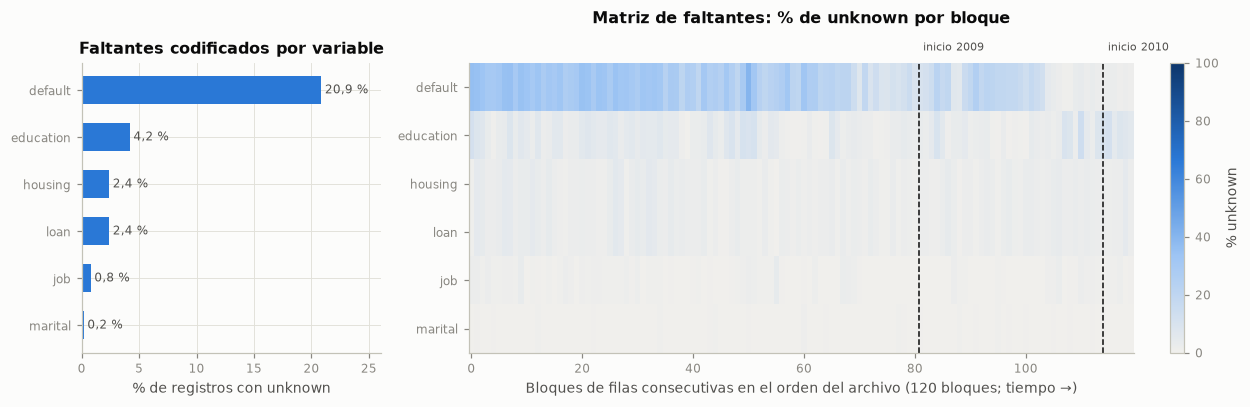

,unknown (n),unknown (%)
default,8 597,"20,87"
education,1 731,"4,20"
housing,990,"2,40"
loan,990,"2,40"
job,330,"0,80"
marital,80,"0,19"


,registros,% que suscribe,% de registros
Variables con unknown,,,
ninguno,30 488,"12,66","74,02"
default,7 757,"5,14","18,83"
education,1 102,"18,42","2,68"
housing + loan,739,"12,31","1,79"
education + default,456,"5,70","1,11"
default + housing + loan,207,"5,31","0,50"
job,116,"14,66","0,28"
job + default,76,"2,63","0,18"


**Interpretación.** `default` concentra la mayor proporción de faltantes (20,9 %), seguida de `education` (4,2 %); en total, el 26,0 % de los registros tiene al menos un `unknown`. La matriz muestra que los faltantes de `default` no se reparten de forma uniforme en el tiempo. Además, `housing` y `loan` son unknown exactamente en los mismos registros.

En ese sentido, eliminar los registros incompletos descartaría el 26,0 % de la muestra; y como el faltante cambia a lo largo del archivo, su presencia puede estar ligada al periodo de la campaña.

Por esta razón, lo indicado es evaluar el mecanismo de faltantes (sección 1.6.2) antes de decidir el tratamiento y no eliminar filas.

In [6]:
print(f"Nulos explícitos (NaN) en todo el archivo: {int(df.isna().sum().sum())}")
CON_UNKNOWN = [c for c in CATEGORICAS if (df[c] == "unknown").any()]
U = df[CON_UNKNOWN].eq("unknown")
faltantes = pd.DataFrame({"unknown (n)": U.sum(), "unknown (%)": 100 * U.mean()}).sort_values("unknown (n)",
                                                                                           ascending=False)
alguno = U.any(axis=1)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw={"width_ratios": [1, 2.4]})
ax[0].barh(faltantes.index[::-1], faltantes["unknown (%)"][::-1], color=AZUL, height=0.6)
for i, v in enumerate(faltantes["unknown (%)"][::-1]):
    ax[0].text(v + 0.3, i, f"{num(v, 1)} %", va="center", fontsize=8, color=TINTA_2)
ax[0].set_xlabel("% de registros con unknown")
ax[0].set_title("Faltantes codificados por variable")
ax[0].set_xlim(0, faltantes["unknown (%)"].max() * 1.25)
# Matriz de faltantes: % de unknown por bloque de filas consecutivas (orden cronológico del archivo)
n_bloq = 120
bloque = np.arange(len(df)) * n_bloq // len(df)
matriz = U.groupby(bloque).mean().T.loc[faltantes.index]
im = ax[1].imshow(100 * matriz.to_numpy(), aspect="auto", cmap=CMAP_SEQ, vmin=0, vmax=100,
                  interpolation="nearest")
ax[1].set_yticks(range(len(matriz)), matriz.index)
for pos in np.flatnonzero(np.diff(tiempo["anio"].to_numpy()) > 0):
    ax[1].axvline(pos * n_bloq / len(df), color=TINTA, lw=1, ls="--")
    ax[1].text(pos * n_bloq / len(df) + 0.8, -0.7, f"inicio {tiempo['anio'].iloc[pos + 1]}", fontsize=7.5,
               color=TINTA_2, va="bottom")
ax[1].set_xlabel(f"Bloques de filas consecutivas en el orden del archivo ({n_bloq} bloques; tiempo →)")
ax[1].set_title("Matriz de faltantes: % de unknown por bloque", pad=26)
ax[1].grid(False)
fig.colorbar(im, ax=ax[1], fraction=0.025, label="% unknown")
plt.tight_layout()
plt.show()

tabla(faltantes, dec=2)

# Patrones conjuntos de faltantes
patron = U.apply(lambda r: " + ".join(c for c in CON_UNKNOWN if r[c]) or "ninguno", axis=1)
patrones = (pd.DataFrame({"patron": patron, "yes": df[OBJETIVO].eq("yes")})
            .groupby("patron").agg(registros=("yes", "size"), tasa_yes=("yes", "mean"))
            .sort_values("registros", ascending=False))
patrones["% de registros"] = 100 * patrones["registros"] / len(df)
patrones["tasa_yes"] = 100 * patrones["tasa_yes"]
tabla(patrones.head(8).rename(columns={"tasa_yes": "% que suscribe"}).rename_axis("Variables con unknown"), dec=2)

hl_iguales = int((U["housing"] == U["loan"]).all())
top = faltantes.index[0]
interpretar(
    f"`{top}` concentra la mayor proporción de faltantes ({num(faltantes.loc[top, 'unknown (%)'], 1)} %), seguida de "
    f"`{faltantes.index[1]}` ({num(faltantes.iloc[1, 1], 1)} %); en total, el {pct(alguno.mean())} de los registros "
    f"tiene al menos un `unknown`. La matriz muestra que los faltantes de `{top}` no se reparten de forma uniforme "
    f"en el tiempo. Además, `housing` y `loan` {'son unknown exactamente en los mismos registros' if hl_iguales else 'no coinciden siempre en sus faltantes'}.",
    f"En ese sentido, eliminar los registros incompletos descartaría el {pct(alguno.mean())} de la muestra; y como el "
    "faltante cambia a lo largo del archivo, su presencia puede estar ligada al periodo de la campaña.",
    "Por esta razón, lo indicado es evaluar el mecanismo de faltantes (sección 1.6.2) antes de decidir el tratamiento "
    "y no eliminar filas.")

#### 1.6.2 Valores faltantes: mecanismo

No se aplica la prueba de Little porque supone variables numéricas con normalidad multivariada y aquí los faltantes son categóricos. Se usa la alternativa que acepta el enunciado: **comparar registros con y sin `unknown`** en la tasa de la variable objetivo y en la distribución de variables observadas (edad, canal de contacto y año). Si los faltantes fueran MCAR (completamente al azar), ambos grupos tendrían distribuciones similares. Las pruebas son χ² para proporciones y Mann-Whitney para la edad, con corrección de Holm por comparaciones múltiples y tamaño de efecto (V de Cramér).

In [7]:
def v_cramer(tabla_cont):
    chi2, p, _, _ = stats.chi2_contingency(tabla_cont, correction=False)
    n = tabla_cont.to_numpy().sum()
    k = min(tabla_cont.shape) - 1
    return np.sqrt(chi2 / (n * k)) if k > 0 else np.nan, chi2, p


yes = df[OBJETIVO].eq("yes")
filas_mec = []
indicadores = {**{c: U[c] for c in CON_UNKNOWN}, "alguno (registro incompleto)": alguno}
for nombre, falta in indicadores.items():
    v_y, _, p_y = v_cramer(pd.crosstab(falta, yes))
    _, p_edad = stats.mannwhitneyu(df.loc[falta, "age"], df.loc[~falta, "age"])
    v_anio, _, p_anio = v_cramer(pd.crosstab(falta, tiempo["anio"]))
    v_canal, _, p_canal = v_cramer(pd.crosstab(falta, df["contact"]))
    filas_mec.append({
        "Variable": nombre, "n unknown": int(falta.sum()),
        "% suscribe con unknown": 100 * yes[falta].mean(), "% suscribe sin unknown": 100 * yes[~falta].mean(),
        "p χ² (y)": p_y, "V (y)": v_y,
        "Edad mediana con unknown": df.loc[falta, "age"].median(), "Edad mediana sin unknown": df.loc[~falta, "age"].median(),
        "p Mann-Whitney (edad)": p_edad,
        "% de 2008 con unknown": 100 * (tiempo.loc[falta, "anio"] == 2008).mean(),
        "% de 2008 sin unknown": 100 * (tiempo.loc[~falta, "anio"] == 2008).mean(),
        "V (año)": v_anio, "p χ² (año)": p_anio, "V (canal)": v_canal, "p χ² (canal)": p_canal})
mecanismo = pd.DataFrame(filas_mec).set_index("Variable")
for col in ["p χ² (y)", "p Mann-Whitney (edad)", "p χ² (año)", "p χ² (canal)"]:
    mecanismo[col] = multipletests(mecanismo[col], method="holm")[1]
tabla(mecanismo, dec=3)
print("Valores p ajustados por Holm dentro de cada familia de pruebas (columna).")

sig_y = mecanismo.index[mecanismo["p χ² (y)"] < 0.05].tolist()
sig_alguna = (mecanismo[["p χ² (y)", "p Mann-Whitney (edad)", "p χ² (año)", "p χ² (canal)"]] < 0.05).any(axis=1)
sin_asociacion = [v for v in CON_UNKNOWN if not sig_alguna[v]]
d = mecanismo.loc["default"]
inc = mecanismo.loc["alguno (registro incompleto)"]
interpretar(
    f"La tasa de suscripción difiere entre registros con y sin `unknown` en {len(sig_y)} de las "
    f"{len(mecanismo)} comparaciones (p de Holm < 0,05). En `default`, que concentra la mayoría de faltantes, "
    f"suscribe el {num(d['% suscribe con unknown'], 1)} % de los registros con `unknown` frente al "
    f"{num(d['% suscribe sin unknown'], 1)} % de los demás (V = {num(d['V (y)'], 3)}); la edad mediana es "
    f"{num(d['Edad mediana con unknown'])} frente a {num(d['Edad mediana sin unknown'])} años y el "
    f"{num(d['% de 2008 con unknown'], 1)} % de sus faltantes es de 2008, frente al "
    f"{num(d['% de 2008 sin unknown'], 1)} % entre los registros completos. Los registros incompletos en conjunto "
    f"suscriben el {num(inc['% suscribe con unknown'], 1)} % frente al {num(inc['% suscribe sin unknown'], 1)} %.",
    "De esta forma, la evidencia descarta MCAR para "
    + (f"todas las variables salvo {enumerar(sin_asociacion)}" if sin_asociacion else "todas las variables")
    + ": los faltantes se asocian con variables observadas (edad, año o canal), lo que es compatible con MAR, y en "
    + enumerar([v for v in sig_y if v in CON_UNKNOWN])
    + " también con la variable objetivo. MNAR no se puede descartar con los datos (por ejemplo, "
    f"un cliente con problemas de crédito puede preferir no declararlo). El mayor tamaño de efecto frente a `y` es "
    f"V = {num(mecanismo['V (y)'].max(), 3)}, así que la asociación es estadísticamente clara pero de magnitud "
    "modesta. En cualquier caso, el `unknown` es **informativo**.",
    "De ahí que se opte por no eliminar registros ni imputar la moda, porque ambas opciones borran una señal asociada "
    "al resultado, y por tratar `unknown` como una categoría explícita dentro del codificador (sección 3.7).")

,n unknown,% suscribe con unknown,% suscribe sin unknown,p χ² (y),V (y),Edad mediana con unknown,Edad mediana sin unknown,p Mann-Whitney (edad),% de 2008 con unknown,% de 2008 sin unknown,V (año),p χ² (año),V (canal),p χ² (canal)
Variable,,,,,,,,,,,,,,
job,330,"11,212","11,266","1,000","0,000","45,000","38,000","0,000","75,152","67,164","0,017","0,012","0,023","0,000"
marital,80,"15,000","11,258","1,000","0,005","35,500","38,000","1,000","58,750","67,245","0,010","0,441","0,003","0,606"
education,1 731,"14,500","11,124","0,000","0,021","43,000","38,000","0,000","66,147","67,276","0,043","0,000","0,021","0,000"
default,8 597,"5,153","12,878","0,000","0,099","43,000","37,000","0,000","83,506","62,935","0,185","0,000","0,136","0,000"
housing,990,"10,808","11,277","1,000","0,002","38,000","38,000","1,000","67,778","67,215","0,003","1,000","0,022","0,000"
loan,990,"10,808","11,277","1,000","0,002","38,000","38,000","1,000","67,778","67,215","0,003","1,000","0,022","0,000"
alguno (registro incompleto),10 700,"7,299","12,657","0,000","0,074","42,000","37,000","0,000","78,551","63,254","0,145","0,000","0,125","0,000"


Valores p ajustados por Holm dentro de cada familia de pruebas (columna).


**Interpretación.** La tasa de suscripción difiere entre registros con y sin `unknown` en 3 de las 7 comparaciones (p de Holm < 0,05). En `default`, que concentra la mayoría de faltantes, suscribe el 5,2 % de los registros con `unknown` frente al 12,9 % de los demás (V = 0,099); la edad mediana es 43 frente a 37 años y el 83,5 % de sus faltantes es de 2008, frente al 62,9 % entre los registros completos. Los registros incompletos en conjunto suscriben el 7,3 % frente al 12,7 %.

De esta forma, la evidencia descarta MCAR para todas las variables salvo `marital`: los faltantes se asocian con variables observadas (edad, año o canal), lo que es compatible con MAR, y en `education` y `default` también con la variable objetivo. MNAR no se puede descartar con los datos (por ejemplo, un cliente con problemas de crédito puede preferir no declararlo). El mayor tamaño de efecto frente a `y` es V = 0,099, así que la asociación es estadísticamente clara pero de magnitud modesta. En cualquier caso, el `unknown` es **informativo**.

De ahí que se opte por no eliminar registros ni imputar la moda, porque ambas opciones borran una señal asociada al resultado, y por tratar `unknown` como una categoría explícita dentro del codificador (sección 3.7).

#### 1.6.3 Duplicados exactos y casi duplicados

Se distinguen dos niveles: **duplicados exactos** (las 21 columnas idénticas) y **casi duplicados** (las 19 predictoras distintas de `duration` idénticas). Como no hay identificador de cliente, un casi duplicado puede ser un error de registro o dos clientes distintos con el mismo perfil contactados en el mismo periodo.

In [8]:
n_dup_exactos = int(df.duplicated().sum())
PRED_SIN_DUR = [c for c in NUMERICAS + CATEGORICAS if c != "duration"]
casi = df.duplicated(subset=PRED_SIN_DUR, keep=False)
grupos_casi = df[casi].groupby(PRED_SIN_DUR)[OBJETIVO].agg(["size", "nunique"])
n_grupos = len(grupos_casi)
n_conflicto = int((grupos_casi["nunique"] > 1).sum())
filas_conflicto = int(grupos_casi.loc[grupos_casi["nunique"] > 1, "size"].sum())

duplicados = pd.DataFrame({"Valor": [n_dup_exactos, int(casi.sum()), n_grupos, n_conflicto, filas_conflicto]},
                          index=["Duplicados exactos (filas sobrantes)",
                                 "Filas en grupos de casi duplicados (predictoras sin duration idénticas)",
                                 "Grupos de casi duplicados", "Grupos con etiquetas y contradictorias",
                                 "Filas en grupos con etiquetas contradictorias"])
tabla(duplicados)
print("Ejemplo de duplicados exactos (primeras filas):")
display(df[df.duplicated(keep=False)].sort_values(PRED_SIN_DUR).head(6))

interpretar(
    f"Hay {n_dup_exactos} duplicados exactos (incluso la duración en segundos coincide) y {num(int(casi.sum()))} "
    f"filas ({pct(casi.mean())}) que comparten todas las predictoras salvo `duration`, en {num(n_grupos)} grupos. En "
    f"{num(n_conflicto)} de esos grupos la etiqueta `y` es contradictoria ({num(filas_conflicto)} filas).",
    "Lo anterior indica que los duplicados exactos son, con alta probabilidad, errores de registro y, si cayeran en "
    "entrenamiento y prueba a la vez, inflarían la evaluación. Los casi duplicados con etiquetas contradictorias "
    "indican **ruido irreducible**: con estas predictoras hay perfiles idénticos que a veces suscriben y a veces no, "
    "lo que pone un techo al desempeño alcanzable.",
    "Por ello, se procede a eliminar los duplicados exactos antes de la partición (sección 2), conservar los casi "
    "duplicados (no hay evidencia de que sean errores) y verificar cuántos quedan repartidos entre entrenamiento y "
    "prueba en la auditoría de fuga (sección 3.5).")

,Valor
Duplicados exactos (filas sobrantes),12
Filas en grupos de casi duplicados (predictoras sin duration idénticas),3 731
Grupos de casi duplicados,1 710
Grupos con etiquetas y contradictorias,237
Filas en grupos con etiquetas contradictorias,542


Ejemplo de duplicados exactos (primeras filas):


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
28476,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no


**Interpretación.** Hay 12 duplicados exactos (incluso la duración en segundos coincide) y 3 731 filas (9,1 %) que comparten todas las predictoras salvo `duration`, en 1 710 grupos. En 237 de esos grupos la etiqueta `y` es contradictoria (542 filas).

Lo anterior indica que los duplicados exactos son, con alta probabilidad, errores de registro y, si cayeran en entrenamiento y prueba a la vez, inflarían la evaluación. Los casi duplicados con etiquetas contradictorias indican **ruido irreducible**: con estas predictoras hay perfiles idénticos que a veces suscriben y a veces no, lo que pone un techo al desempeño alcanzable.

Por ello, se procede a eliminar los duplicados exactos antes de la partición (sección 2), conservar los casi duplicados (no hay evidencia de que sean errores) y verificar cuántos quedan repartidos entre entrenamiento y prueba en la auditoría de fuga (sección 3.5).

#### 1.6.4 Valores imposibles, códigos especiales e inconsistencias

Se revisan los rangos de las numéricas, las categorías frente a las documentadas y la coherencia lógica entre las variables de campañas anteriores (`pdays`, `previous`, `poutcome`).

In [9]:
DOCUMENTADAS = {
    "job": {"admin.", "blue-collar", "entrepreneur", "housemaid", "management", "retired", "self-employed",
            "services", "student", "technician", "unemployed", "unknown"},
    "marital": {"divorced", "married", "single", "unknown"},
    "education": {"basic.4y", "basic.6y", "basic.9y", "high.school", "illiterate", "professional.course",
                  "university.degree", "unknown"},
    "default": {"no", "yes", "unknown"}, "housing": {"no", "yes", "unknown"}, "loan": {"no", "yes", "unknown"},
    "contact": {"cellular", "telephone"}, "month": set(ORDEN_MESES),
    "day_of_week": {"mon", "tue", "wed", "thu", "fri"}, "poutcome": {"failure", "nonexistent", "success"},
}
no_documentadas = {c: sorted(set(df[c].unique()) - DOCUMENTADAS[c]) for c in CATEGORICAS}
espacios = sum(int((df[c] != df[c].str.strip()).sum()) for c in CATEGORICAS)
print("Categorías fuera de la documentación:", {c: v for c, v in no_documentadas.items() if v} or "ninguna")
print(f"Valores categóricos con espacios sobrantes: {espacios}")
print("Meses ausentes en todo el archivo:", sorted(set(ORDEN_MESES) - set(df["month"].unique()),
                                                 key=ORDEN_MESES.index))

rangos = df[NUMERICAS].agg(["min", "max"]).T
rangos.columns = ["Mínimo", "Máximo"]
tabla(rangos, dec=3)

reglas = {
    "age < 18 (menor de edad)": df["age"] < 18,
    "duration = 0": df["duration"] == 0,
    "duration = 0 y y = yes (contradicción lógica)": (df["duration"] == 0) & yes,
    "pdays = 999 (código: sin contacto previo)": df["pdays"] == 999,
    "pdays = 999 y previous > 0 (inconsistente con el código)": (df["pdays"] == 999) & (df["previous"] > 0),
    "pdays ≠ 999 y previous = 0": (df["pdays"] != 999) & (df["previous"] == 0),
    "poutcome = nonexistent y previous > 0": (df["poutcome"] == "nonexistent") & (df["previous"] > 0),
    "poutcome ≠ nonexistent y previous = 0": (df["poutcome"] != "nonexistent") & (df["previous"] == 0),
}
chequeos = pd.DataFrame({"Registros": {k: int(v.sum()) for k, v in reglas.items()}})
chequeos["%"] = 100 * chequeos["Registros"] / len(df)
tabla(chequeos, dec=2)
print("poutcome de los registros con pdays = 999 y previous > 0:")
print(df.loc[reglas["pdays = 999 y previous > 0 (inconsistente con el código)"], "poutcome"].value_counts().to_dict())

inc_pdays = chequeos.loc["pdays = 999 y previous > 0 (inconsistente con el código)", "Registros"]
sin_errores_cat = not any(no_documentadas.values()) and espacios == 0
dur0_ok = chequeos.loc["duration = 0 y y = yes (contradicción lógica)", "Registros"] == 0
interpretar(
    ("No hay categorías fuera de las documentadas ni errores de escritura" if sin_errores_cat
     else "Hay categorías fuera de la documentación o con espacios sobrantes")
    + f", y los rangos numéricos son plausibles "
    f"(edad entre {df['age'].min()} y {df['age'].max()} años; {int(reglas['age < 18 (menor de edad)'].sum())} "
    f"registros de menores de 18). El código `pdays = 999` aparece en el "
    f"{pct(reglas['pdays = 999 (código: sin contacto previo)'].mean())} de los registros y es un valor especial, no "
    f"una cantidad de días. Hay una inconsistencia: {num(inc_pdays)} registros tienen `pdays = 999` (\"sin contacto "
    f"previo\") pero `previous > 0` y `poutcome = failure`. Los {int(reglas['duration = 0'].sum())} registros con "
    f"`duration = 0` " + ("tienen todos `y = no`." if dur0_ok else "no siempre tienen `y = no`."),
    "Por consiguiente, si `pdays` entra como número, el modelo trataría 999 días como una distancia real y la relación "
    "quedaría distorsionada. La inconsistencia sugiere que 999 significa en realidad \"sin registro de días\" y no "
    "\"nunca contactado\"; la información de contacto previo la aportan mejor `previous` y `poutcome`. La regla "
    "`duration = 0` ⇒ `y = no` confirma que `duration` contiene información del resultado.",
    "Con base en esto, se propone convertir `pdays = 999` en faltante con un indicador explícito dentro del `Pipeline` "
    "(sección 3.7), conservar `previous` y `poutcome` y no corregir manualmente la inconsistencia (no hay forma de "
    "saber el valor real).")

Categorías fuera de la documentación: ninguna
Valores categóricos con espacios sobrantes: 0
Meses ausentes en todo el archivo: ['jan', 'feb']


,Mínimo,Máximo
age,"17,000","98,000"
duration,"0,000","4 918,000"
campaign,"1,000","56,000"
pdays,"0,000","999,000"
previous,"0,000","7,000"
emp.var.rate,"-3,400","1,400"
cons.price.idx,"92,201","94,767"
cons.conf.idx,"-50,800","-26,900"
euribor3m,"0,634","5,045"
nr.employed,"4 963,600","5 228,100"


,Registros,%
age < 18 (menor de edad),5,"0,01"
duration = 0,4,"0,01"
duration = 0 y y = yes (contradicción lógica),0,"0,00"
pdays = 999 (código: sin contacto previo),39 673,"96,32"
pdays = 999 y previous > 0 (inconsistente con el código),4 110,"9,98"
pdays ≠ 999 y previous = 0,0,"0,00"
poutcome = nonexistent y previous > 0,0,"0,00"
poutcome ≠ nonexistent y previous = 0,0,"0,00"


poutcome de los registros con pdays = 999 y previous > 0:
{'failure': 4110}


**Interpretación.** No hay categorías fuera de las documentadas ni errores de escritura, y los rangos numéricos son plausibles (edad entre 17 y 98 años; 5 registros de menores de 18). El código `pdays = 999` aparece en el 96,3 % de los registros y es un valor especial, no una cantidad de días. Hay una inconsistencia: 4 110 registros tienen `pdays = 999` ("sin contacto previo") pero `previous > 0` y `poutcome = failure`. Los 4 registros con `duration = 0` tienen todos `y = no`.

Por consiguiente, si `pdays` entra como número, el modelo trataría 999 días como una distancia real y la relación quedaría distorsionada. La inconsistencia sugiere que 999 significa en realidad "sin registro de días" y no "nunca contactado"; la información de contacto previo la aportan mejor `previous` y `poutcome`. La regla `duration = 0` ⇒ `y = no` confirma que `duration` contiene información del resultado.

Con base en esto, se propone convertir `pdays = 999` en faltante con un indicador explícito dentro del `Pipeline` (sección 3.7), conservar `previous` y `poutcome` y no corregir manualmente la inconsistencia (no hay forma de saber el valor real).

#### 1.6.5 Valores atípicos (inventario)

Se aplica la regla de Tukey (fuera de $[Q_1 - 1{,}5\,\mathrm{IQR},\; Q_3 + 1{,}5\,\mathrm{IQR}]$) a cada variable numérica. Este inventario solo cuantifica; la decisión de tratamiento se toma con el conjunto de entrenamiento (secciones 3.2 y 3.4).

In [10]:
filas_iqr = []
for c in NUMERICAS:
    s = df[c]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    fuera = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    filas_iqr.append({"Variable": c, "Q1": q1, "Q3": q3, "IQR": iqr, "Límite inferior": q1 - 1.5 * iqr,
                      "Límite superior": q3 + 1.5 * iqr, "Atípicos (n)": int(fuera.sum()), "Atípicos (%)": 100 * fuera.mean()})
inventario_iqr = pd.DataFrame(filas_iqr).set_index("Variable")
tabla(inventario_iqr, dec=2)

con_atip = inventario_iqr[inventario_iqr["Atípicos (n)"] > 0].sort_values("Atípicos (%)", ascending=False)
interpretar(
    f"{len(con_atip)} de las {len(NUMERICAS)} numéricas tienen valores fuera de los límites de Tukey: "
    + ", ".join(f"`{i}` ({num(r['Atípicos (%)'], 1)} %)" for i, r in con_atip.iterrows())
    + ". En `pdays` y `previous` el IQR es cero porque la gran mayoría de los valores es igual (999 y 0), así que "
      "cualquier valor distinto aparece como atípico.",
    "Entonces, estos valores son plausibles (llamadas largas, clientes contactados muchas veces, clientes con "
    "historial), no errores; eliminarlos quitaría precisamente a los clientes con historial previo, que son "
    "informativos. Sí pueden ejercer palanca en un modelo lineal cuando la distribución tiene cola larga.",
    "Así las cosas, la decisión es no eliminar atípicos, sino reducir su influencia con transformaciones (sección 3.2) "
    "y revisar los atípicos multivariados en la sección 3.4.")

,Q1,Q3,IQR,Límite inferior,Límite superior,Atípicos (n),Atípicos (%)
Variable,,,,,,,
age,"32,00","47,00","15,00","9,50","69,50",469,"1,14"
duration,"102,00","319,00","217,00","-223,50","644,50",2 963,"7,19"
campaign,"1,00","3,00","2,00","-2,00","6,00",2 406,"5,84"
pdays,"999,00","999,00","0,00","999,00","999,00",1 515,"3,68"
previous,"0,00","0,00","0,00","0,00","0,00",5 625,"13,66"
emp.var.rate,"-1,80","1,40","3,20","-6,60","6,20",0,"0,00"
cons.price.idx,"93,08","93,99","0,92","91,70","95,37",0,"0,00"
cons.conf.idx,"-42,70","-36,40","6,30","-52,15","-26,95",447,"1,09"
euribor3m,"1,34","4,96","3,62","-4,08","10,39",0,"0,00"


**Interpretación.** 6 de las 10 numéricas tienen valores fuera de los límites de Tukey: `previous` (13,7 %), `duration` (7,2 %), `campaign` (5,8 %), `pdays` (3,7 %), `age` (1,1 %), `cons.conf.idx` (1,1 %). En `pdays` y `previous` el IQR es cero porque la gran mayoría de los valores es igual (999 y 0), así que cualquier valor distinto aparece como atípico.

Entonces, estos valores son plausibles (llamadas largas, clientes contactados muchas veces, clientes con historial), no errores; eliminarlos quitaría precisamente a los clientes con historial previo, que son informativos. Sí pueden ejercer palanca en un modelo lineal cuando la distribución tiene cola larga.

Así las cosas, la decisión es no eliminar atípicos, sino reducir su influencia con transformaciones (sección 3.2) y revisar los atípicos multivariados en la sección 3.4.

#### 1.6.6 Sesgos de muestreo y representatividad

- **Población:** los registros corresponden a clientes que **el banco eligió contactar** en sus campañas, no a una muestra aleatoria de la población ni de todos los clientes. El modelo solo es válido para esa población objetivo.
- **Una sola institución y un solo país:** los resultados no se pueden generalizar a otros bancos, productos o mercados sin validación.
- **Periodo atípico:** el archivo cubre de mayo de 2008 a noviembre de 2010, en plena crisis financiera, con la tasa Euribor en caída (sección 3.6); las relaciones aprendidas pueden no sostenerse en otros contextos económicos.
- **Volumen desigual en el tiempo:** la tabla de la sección 1.5 muestra que el primer año concentra la mayor parte de los registros, de modo que el modelo aprende sobre todo del comportamiento de ese año.
- **Atributos recortados:** la documentación señala que el archivo no incluye todos los atributos del estudio original por razones de privacidad, así que el desempeño no es comparable de forma directa con el del artículo de referencia.

### 1.7 Consideraciones éticas

- **Datos personales y anonimización:** el archivo no contiene nombres, documentos, teléfonos ni identificadores de cliente; las fechas solo tienen mes y día de la semana, sin año ni día exacto, y no hay coordenadas. El riesgo de reidentificación es bajo, aunque la combinación de edad, ocupación, estado civil, educación y situación crediticia podría singularizar a personas dentro del propio banco.
- **Información sensible:** `default`, `housing` y `loan` describen la situación financiera del cliente; su uso debe limitarse al propósito declarado.
- **Equidad:** un modelo que prioriza llamadas según edad, estado civil u ocupación puede concentrar la presión comercial en grupos específicos (por ejemplo, personas jubiladas). Cualquier despliegue debería auditar el efecto por grupos.
- **Licencia:** CC BY 4.0 exige atribución, que se cumple con las citas de la sección 6.

## 2. Reserva del conjunto de prueba

Antes de cualquier decisión que se use en el modelado (imputación, transformaciones, selección de variables, umbrales de atípicos o hiperparámetros), se reserva el conjunto de prueba. Primero se eliminan los duplicados exactos detectados en la sección 1.6.3; es una limpieza estructural que no usa estadísticas de los datos y conserva el orden de las filas.

**Partición cronológica 80/20.** El entrenamiento es el primer 80 % de los registros en orden temporal y la prueba, el último 20 %. La decisión responde a la estructura de los datos y al propósito del modelo:

- Las filas están ordenadas por fecha (sección 1.5) y el enunciado exige una partición cronológica cuando hay tiempo.
- El modelo debe decidir a quién llamar en **campañas futuras**, así que la prueba debe simular ese uso: ajustar con el pasado y evaluar con periodos posteriores que el modelo no vio.
- La sección 3.6 confirma, solo con datos de entrenamiento, que una validación aleatoria inflaría el desempeño (**fuga temporal**): un modelo que únicamente reconoce el periodo alcanza casi el mismo AUC que el modelo completo, y la validación temporal da un resultado mucho menor.

La partición no se estratifica: la prevalencia de la clase positiva cambia entre periodos y se reporta tal como es, porque forzarla a ser igual ocultaría justamente el cambio que el modelo enfrentará en la práctica. Desde aquí, **todo el análisis exploratorio y todas las decisiones se calculan solo con el conjunto de entrenamiento**. El conjunto de prueba se usa una única vez, en la evaluación final de la sección 4.4.

In [11]:
df_limpio = df.drop_duplicates(keep="first")
assert df_limpio.index.is_monotonic_increasing  # se conserva el orden temporal del archivo
y_todo = df_limpio[OBJETIVO].eq("yes").astype(int)
X_todo = df_limpio.drop(columns=OBJETIVO)

n_prueba = int(np.ceil(0.20 * len(X_todo)))
n_entrena = len(X_todo) - n_prueba
X_tr, X_te = X_todo.iloc[:n_entrena], X_todo.iloc[n_entrena:]
y_tr, y_te = y_todo.iloc[:n_entrena], y_todo.iloc[n_entrena:]
anio_tr, anio_te = tiempo.loc[X_tr.index, "anio"], tiempo.loc[X_te.index, "anio"]
periodo_tr, periodo_te = tiempo.loc[X_tr.index, "periodo"], tiempo.loc[X_te.index, "periodo"]
dia_tr, dia_te = tiempo.loc[X_tr.index, "dia"], tiempo.loc[X_te.index, "dia"]
tr = X_tr.assign(y=y_tr)  # copia de trabajo para el EDA (solo entrenamiento)
periodo_corte = periodo_tr.iloc[-1]
dias_compartidos = len(set(dia_tr) & set(dia_te))

particion = pd.DataFrame({
    "Filas": [len(df_limpio), len(X_tr), len(X_te)],
    "Desde": [tiempo.loc[X_todo.index, "periodo"].iloc[0], periodo_tr.iloc[0], periodo_te.iloc[0]],
    "Hasta": [tiempo.loc[X_todo.index, "periodo"].iloc[-1], periodo_tr.iloc[-1], periodo_te.iloc[-1]],
    "Positivos (suscribe)": [int(y_todo.sum()), int(y_tr.sum()), int(y_te.sum())],
    "% positivos": [100 * y_todo.mean(), 100 * y_tr.mean(), 100 * y_te.mean()],
    "% de 2008": [100 * (tiempo.loc[X_todo.index, "anio"] == 2008).mean(), 100 * (anio_tr == 2008).mean(),
                  100 * (anio_te == 2008).mean()],
    "% de 2009": [100 * (tiempo.loc[X_todo.index, "anio"] == 2009).mean(), 100 * (anio_tr == 2009).mean(),
                  100 * (anio_te == 2009).mean()],
    "% de 2010": [100 * (tiempo.loc[X_todo.index, "anio"] == 2010).mean(), 100 * (anio_tr == 2010).mean(),
                  100 * (anio_te == 2010).mean()]},
    index=["Total sin duplicados exactos", "Entrenamiento (primer 80 %)", "Prueba (último 20 %)"])
tabla(particion, dec=2)

interpretar(
    f"Tras eliminar {len(df) - len(df_limpio)} duplicados exactos quedan {num(len(df_limpio))} registros. El "
    f"entrenamiento tiene {num(len(X_tr))} registros, de {periodo_tr.iloc[0]} a {periodo_tr.iloc[-1]}, y la prueba "
    f"{num(len(X_te))}, de {periodo_te.iloc[0]} a {periodo_te.iloc[-1]}. Suscribe el {pct(y_tr.mean())} en "
    f"entrenamiento y el {pct(y_te.mean())} en prueba, {num(y_te.mean() / y_tr.mean(), 1)} veces más. El "
    f"entrenamiento es en un {pct((anio_tr == 2008).mean())} de 2008, mientras que la prueba es en un "
    f"{pct((anio_te == 2010).mean())} de 2010 y no tiene registros de 2008. El corte cae dentro de {periodo_corte}, "
    f"único mes presente en ambos conjuntos"
    + (f" (comparten {dias_compartidos} día de contacto)." if dias_compartidos == 1 else
       (f" (comparten {dias_compartidos} días de contacto)." if dias_compartidos > 1 else ".")),
    "De esta forma, la prueba mide lo que importa para el uso real: el desempeño en periodos posteriores a los del "
    "ajuste. El cambio de prevalencia es un desplazamiento de la clase (*prior shift*) que el modelo no observa "
    f"durante el ajuste: las probabilidades aprendidas con una tasa base del {pct(y_tr.mean())} tenderán a subestimar "
    "la de prueba, y un umbral elegido en entrenamiento puede no servir en prueba. También cambia la línea base: el "
    f"Dummy, que siempre predice \"no suscribe\", acierta en prueba el {pct(1 - y_te.mean())} y no el "
    f"{pct(1 - y_tr.mean())} que lograría en entrenamiento.",
    "Por tanto, corresponde validar dentro de entrenamiento con un esquema temporal (sección 3), evaluar con métricas "
    "que no dependan del umbral (AUC) junto con AUC-PR, recall, F1 y calibración, y analizar en la sección 4 el efecto "
    "del cambio de prevalencia sobre el umbral y la calibración.")

,Filas,Desde,Hasta,Positivos (suscribe),% positivos,% de 2008,% de 2009,% de 2010
Total sin duplicados exactos,41 176,2008-05,2010-11,4 639,"11,27","67,23","27,77","5,00"
Entrenamiento (primer 80 %),32 940,2008-05,2009-05,2 100,"6,38","84,04","15,96","0,00"
Prueba (último 20 %),8 236,2009-05,2010-11,2 539,"30,83","0,00","75,01","24,99"


**Interpretación.** Tras eliminar 12 duplicados exactos quedan 41 176 registros. El entrenamiento tiene 32 940 registros, de 2008-05 a 2009-05, y la prueba 8 236, de 2009-05 a 2010-11. Suscribe el 6,4 % en entrenamiento y el 30,8 % en prueba, 4,8 veces más. El entrenamiento es en un 84,0 % de 2008, mientras que la prueba es en un 25,0 % de 2010 y no tiene registros de 2008. El corte cae dentro de 2009-05, único mes presente en ambos conjuntos (comparten 1 día de contacto).

De esta forma, la prueba mide lo que importa para el uso real: el desempeño en periodos posteriores a los del ajuste. El cambio de prevalencia es un desplazamiento de la clase (*prior shift*) que el modelo no observa durante el ajuste: las probabilidades aprendidas con una tasa base del 6,4 % tenderán a subestimar la de prueba, y un umbral elegido en entrenamiento puede no servir en prueba. También cambia la línea base: el Dummy, que siempre predice "no suscribe", acierta en prueba el 69,2 % y no el 93,6 % que lograría en entrenamiento.

Por tanto, corresponde validar dentro de entrenamiento con un esquema temporal (sección 3), evaluar con métricas que no dependan del umbral (AUC) junto con AUC-PR, recall, F1 y calibración, y analizar en la sección 4 el efecto del cambio de prevalencia sobre el umbral y la calibración.

## 3. Análisis exploratorio de datos

Todo el análisis de esta sección usa **solo el conjunto de entrenamiento** reservado en la sección 2. Cuando se hacen muchas pruebas de hipótesis, los valores *p* se ajustan por Holm (control del error de familia) y por Benjamini-Hochberg (FDR), y siempre se reportan **tamaños de efecto**, porque con más de 30 000 registros casi cualquier diferencia resulta significativa.

**Esquema de validación temporal.** La validación cruzada interna es coherente con la partición: `TimeSeriesSplit` de cinco pliegues sobre el entrenamiento en orden cronológico (ventana creciente: siempre se ajusta con el pasado y se valida con el bloque siguiente). Entre el último registro de ajuste y el primero de validación se deja una separación (*gap*) igual al percentil 95 de los registros por día de contacto en entrenamiento, para que el bloque de validación no empiece en el mismo día en que termina el ajuste: los contactos de un mismo día comparten condiciones y sus resultados no son independientes. La validación estratificada aleatoria (`SEED`) solo aparece como contraste explícito en las secciones 3.6 y 4.10.

In [12]:
registros_dia_tr = dia_tr.value_counts()
GAP = int(np.ceil(registros_dia_tr.quantile(0.95)))
tss = TimeSeriesSplit(n_splits=5, gap=GAP)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)  # solo como contraste (secciones 3.6 y 4.10)

filas_pl = []
for k_, (i_ent, i_val) in enumerate(tss.split(X_tr), start=1):
    filas_pl.append({"Pliegue": k_, "Registros de ajuste": len(i_ent), "Ajusta hasta": periodo_tr.iloc[i_ent[-1]],
                     "Registros de validación": len(i_val), "Valida desde": periodo_tr.iloc[i_val[0]],
                     "Valida hasta": periodo_tr.iloc[i_val[-1]],
                     "% positivos (ajuste)": 100 * y_tr.iloc[i_ent].mean(),
                     "% positivos (validación)": 100 * y_tr.iloc[i_val].mean()})
esquema_tss = pd.DataFrame(filas_pl).set_index("Pliegue")
print(f"Separación (gap) = {GAP} registros: percentil 95 de los registros por día de contacto en entrenamiento "
      f"(mediana {num(registros_dia_tr.median())} registros por día).")
tabla(esquema_tss, dec=2)

val_2008 = esquema_tss["Valida hasta"].str.startswith("2008")
interpretar(
    f"Cada pliegue valida en un bloque de {num(esquema_tss['Registros de validación'].iloc[0])} registros; el ajuste "
    f"crece de {num(esquema_tss['Registros de ajuste'].iloc[0])} a {num(esquema_tss['Registros de ajuste'].iloc[-1])} "
    f"registros. {int(val_2008.sum())} de los cinco bloques de validación terminan en 2008 y el último va de "
    f"{esquema_tss['Valida desde'].iloc[-1]} a {esquema_tss['Valida hasta'].iloc[-1]}. La prevalencia de validación va "
    f"del {num(esquema_tss['% positivos (validación)'].min(), 1)} % al {num(esquema_tss['% positivos (validación)'].max(), 1)} %.",
    "En ese sentido, la validación temporal reproduce la situación real (predecir con el pasado), pero hereda la "
    "deriva: los bloques de 2008 tienen pocas suscripciones y condiciones económicas parecidas entre sí, mientras que "
    "el último ya incluye meses de 2009. Las métricas de validación serán más bajas y más variables que las de una "
    "validación aleatoria, y eso es parte del resultado, no un defecto del esquema.",
    "Por lo anterior, conviene usar este esquema para elegir variables, hiperparámetros y umbral (secciones 3.5, 3.7 y "
    "4) y reportar el resultado por pliegue, no solo el promedio.")

Separación (gap) = 507 registros: percentil 95 de los registros por día de contacto en entrenamiento (mediana 192 registros por día).


,Registros de ajuste,Ajusta hasta,Registros de validación,Valida desde,Valida hasta,% positivos (ajuste),% positivos (validación)
Pliegue,,,,,,,
1,4 983,2008-05,5 490,2008-05,2008-06,"2,91","3,88"
2,10 473,2008-06,5 490,2008-06,2008-07,"3,41","6,05"
3,15 963,2008-07,5 490,2008-07,2008-08,"4,27","5,92"
4,21 453,2008-08,5 490,2008-08,2008-11,"4,73","5,45"
5,26 943,2008-11,5 490,2008-11,2009-05,"4,82","14,03"


**Interpretación.** Cada pliegue valida en un bloque de 5 490 registros; el ajuste crece de 4 983 a 26 943 registros. 4 de los cinco bloques de validación terminan en 2008 y el último va de 2008-11 a 2009-05. La prevalencia de validación va del 3,9 % al 14,0 %.

En ese sentido, la validación temporal reproduce la situación real (predecir con el pasado), pero hereda la deriva: los bloques de 2008 tienen pocas suscripciones y condiciones económicas parecidas entre sí, mientras que el último ya incluye meses de 2009. Las métricas de validación serán más bajas y más variables que las de una validación aleatoria, y eso es parte del resultado, no un defecto del esquema.

Por lo anterior, conviene usar este esquema para elegir variables, hiperparámetros y umbral (secciones 3.5, 3.7 y 4) y reportar el resultado por pliegue, no solo el promedio.

### 3.1 Análisis de la variable objetivo (enunciado, sección 2.1)

,Registros,%
no suscribe (0),30 840,"93,62"
suscribe (1),2 100,"6,38"


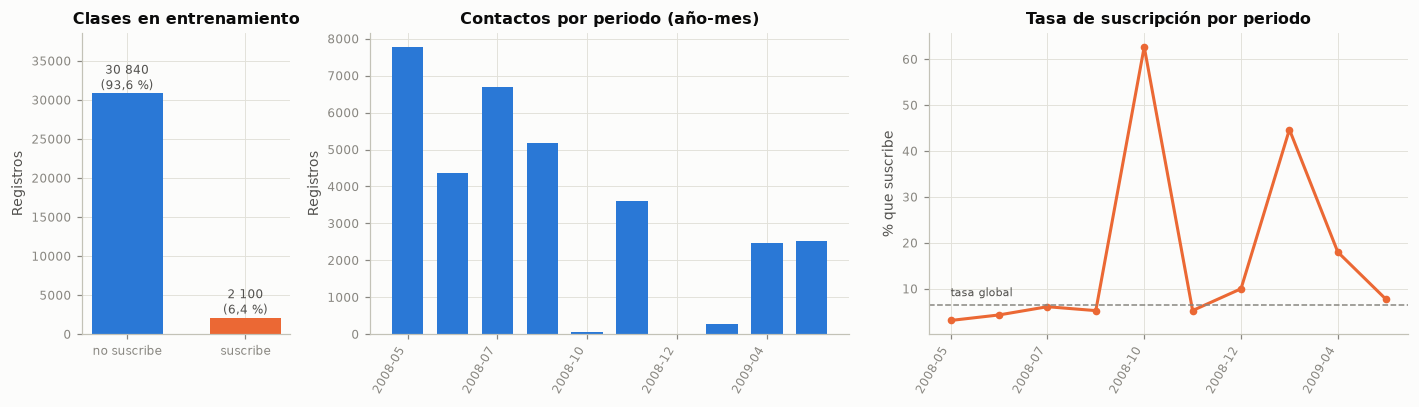

,Registros,% que suscribe
Año reconstruido,,
2008,27 682,"4,8"
2009,5 258,"14,5"


**Interpretación.** En entrenamiento suscribe el 6,38 % (2 100 casos de la clase minoritaria): hay 14,7 registros negativos por cada positivo. Un clasificador que siempre diga "no suscribe" acierta el 93,6 % de las veces. La tasa cambia mucho en el tiempo: va del 3,1 % en 2008-05 al 62,7 % en 2008-10 (un mes con solo 67 contactos en entrenamiento), y por año pasa del 4,8 % en 2008 al 14,5 % en el tramo de 2009 incluido en entrenamiento (hasta 2009-05). Los meses con más contactos son los de menor tasa (Spearman entre volumen y tasa por periodo = -0,84).

Entonces, el accuracy no sirve como métrica principal: un 93,6 % se logra sin aprender nada. Además, la prevalencia de la clase positiva depende del periodo, de modo que cualquier variable que identifique el periodo tendrá poder predictivo aparente y el desempeño en campañas futuras dependerá de la tasa base de ese futuro.

Por tal motivo, se opta por evaluar con AUC, AUC-PR (precisión promedio), recall, F1 y calibración; validar con el esquema temporal, que respeta la deriva de la prevalencia, y cuantificar en la sección 3.6 cuánto inflaría el resultado una validación aleatoria.

In [13]:
conteo = y_tr.value_counts().sort_index()
razon = conteo[0] / conteo[1]
acc_trivial = conteo[0] / len(y_tr)
dist_obj = pd.DataFrame({"Registros": conteo.values, "%": 100 * conteo.values / len(y_tr)},
                        index=["no suscribe (0)", "suscribe (1)"])
tabla(dist_obj, dec=2)

por_periodo = tr.groupby(periodo_tr)["y"].agg(contactos="size", tasa="mean")
por_anio_tr = tr.groupby(anio_tr)["y"].agg(contactos="size", tasa="mean")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 2.3, 2.3]})
ax[0].bar(["no suscribe", "suscribe"], conteo.values, color=[AZUL, NARANJA], width=0.6)
for i, v in enumerate(conteo.values):
    ax[0].text(i, v, f"{num(v)}\n({pct(v / len(y_tr))})", ha="center", va="bottom", fontsize=8, color=TINTA_2)
ax[0].set_ylim(0, conteo.max() * 1.25)
ax[0].set_ylabel("Registros")
ax[0].set_title("Clases en entrenamiento")
x = np.arange(len(por_periodo))
ax[1].bar(x, por_periodo["contactos"], color=AZUL, width=0.7)
ax[1].set_ylabel("Registros")
ax[1].set_title("Contactos por periodo (año-mes)")
ax[2].plot(x, 100 * por_periodo["tasa"], color=NARANJA, marker="o", ms=4)
ax[2].axhline(100 * y_tr.mean(), color=GRIS, ls="--", lw=1)
ax[2].text(0, 100 * y_tr.mean() + 2, "tasa global", fontsize=7.5, color=TINTA_2)
ax[2].set_ylabel("% que suscribe")
ax[2].set_title("Tasa de suscripción por periodo")
for a in ax[1:]:
    a.set_xticks(x[::2], por_periodo.index[::2], rotation=60, ha="right")
plt.tight_layout()
plt.show()

tabla(por_anio_tr.assign(tasa=100 * por_anio_tr["tasa"]).rename(columns={"contactos": "Registros",
      "tasa": "% que suscribe"}).rename_axis("Año reconstruido"), dec=1)

p_min, p_max = por_periodo["tasa"].idxmin(), por_periodo["tasa"].idxmax()
rho_vol = stats.spearmanr(por_periodo["contactos"], por_periodo["tasa"]).statistic
interpretar(
    f"En entrenamiento suscribe el {pct(y_tr.mean(), 2)} ({num(conteo[1])} casos de la clase minoritaria): hay "
    f"{num(razon, 1)} registros negativos por cada positivo. Un clasificador que siempre diga \"no suscribe\" "
    f"acierta el {pct(acc_trivial)} de las veces. La tasa cambia mucho en el tiempo: va del "
    f"{pct(por_periodo.loc[p_min, 'tasa'])} en {p_min} al {pct(por_periodo.loc[p_max, 'tasa'])} en {p_max} (un mes con "
    f"solo {num(por_periodo.loc[p_max, 'contactos'])} contactos en entrenamiento), y por "
    f"año pasa del {pct(por_anio_tr.loc[por_anio_tr.index[0], 'tasa'])} en {por_anio_tr.index[0]} al "
    f"{pct(por_anio_tr.loc[por_anio_tr.index[-1], 'tasa'])} en el tramo de {por_anio_tr.index[-1]} incluido en "
    f"entrenamiento (hasta {periodo_corte}). "
    f"Los meses con más contactos son los de menor tasa (Spearman entre volumen y tasa por periodo = {num(rho_vol, 2)}).",
    f"Entonces, el accuracy no sirve como métrica principal: un {pct(acc_trivial)} se logra sin aprender nada. Además, "
    "la prevalencia de la clase positiva depende del periodo, de modo que cualquier variable que identifique el "
    "periodo tendrá poder predictivo aparente y el desempeño en campañas futuras dependerá de la tasa base de ese "
    "futuro.",
    "Por tal motivo, se opta por evaluar con AUC, AUC-PR (precisión promedio), recall, F1 y calibración; validar con "
    "el esquema temporal, que respeta la deriva de la prevalencia, y cuantificar en la sección 3.6 cuánto inflaría el "
    "resultado una validación aleatoria.")

### 3.2 Análisis unidimensional (enunciado, sección 2.2)

#### 3.2.1 Variables numéricas

Para cada variable se reportan el número de valores distintos, los estadísticos de posición y dispersión, la asimetría, la curtosis (exceso sobre la normal), la prueba de normalidad de D'Agostino-Pearson y la proporción de atípicos según el IQR. `pdays` se resume con todos sus valores, incluido el código 999, y en el histograma se muestra sin el código.

,Valores distintos,Media,Mediana,Desv. est.,Mín.,P5,P25,P75,P95,Máx.,Asimetría,Curtosis,p normalidad,Atípicos IQR (%)
Variable,,,,,,,,,,,,,,
age,68,"40,03","39,00","9,35","18,00","27,00","33,00","47,00","57,00","95,00","0,48","-0,21","0,00","0,23"
duration,1 482,"255,99","175,00","261,26","0,00","38,00","100,00","314,00","757,00","4 918,00","3,32","20,86","0,00","7,48"
campaign,42,"2,67","2,00","2,97","1,00","1,00","1,00","3,00","7,00","56,00","4,65","33,91","0,00","6,51"
pdays,14,"993,75","999,00","72,03","0,00","999,00","999,00","999,00","999,00","999,00","-13,65","184,35","0,00","0,53"
previous,4,"0,07","0,00","0,27","0,00","0,00","0,00","0,00","1,00","3,00","3,87","15,51","0,00","6,91"
emp.var.rate,5,"0,65","1,10","1,16","-1,80","-1,80","-0,10","1,40","1,40","1,40","-1,39","0,29","0,00","0,00"
cons.price.idx,10,"93,70","93,92","0,48","92,76","92,89","93,20","93,99","94,47","94,47","-0,14","-1,05","0,00","0,00"
cons.conf.idx,10,"-40,64","-41,80","3,87","-50,00","-47,10","-42,70","-36,40","-36,10","-36,10","-0,17","-1,14","0,00","0,00"
euribor3m,106,"4,27","4,86","1,28","1,30","1,33","4,19","4,96","4,97","5,04","-1,72","1,15","0,00","15,96"


pdays sin el código 999: 174 registros (0,5 %), mediana 5 días, máximo 12 días.


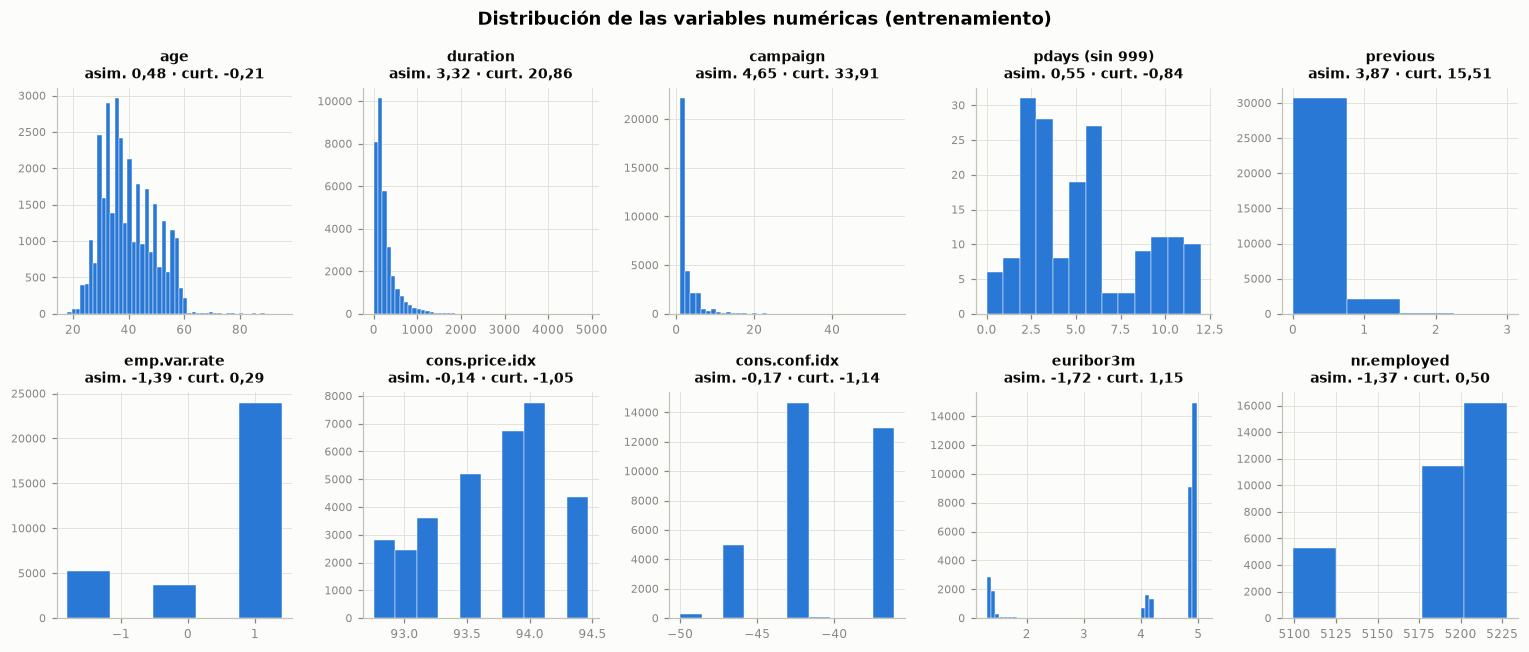

**Interpretación.** Las variables con asimetría marcada (|asimetría| > 1) son `duration`, `campaign`, `pdays`, `previous`, `emp.var.rate`, `euribor3m` y `nr.employed`; `campaign` tiene asimetría 4,65 y curtosis 33,9, con mediana 2 y máximo 56. La edad es moderadamente asimétrica a la derecha (mediana 39 años). Los indicadores macroeconómicos no son continuos en la práctica: `emp.var.rate` toma 5 valores, `cons.price.idx` toma 10 valores, `cons.conf.idx` toma 10 valores y `nr.employed` toma 5 valores, con distribuciones multimodales que corresponden a periodos distintos. La prueba de normalidad rechaza en las 10 variables (p < 0,05), algo esperable con n = 32 940.

Lo anterior indica que las colas largas de los conteos (`campaign`, `previous`) dan palanca excesiva a pocos registros en un modelo lineal. El rechazo de la normalidad no es un problema para la regresión logística, que no la supone en las predictoras, pero confirma que conviene usar pruebas no paramétricas en el análisis bidimensional. Que las macro tengan tan pocos valores indica que funcionan como etiquetas del periodo más que como medidas continuas.

En consecuencia, se decide aplicar `log1p` a `campaign` y `previous` antes del escalado (sección 3.7) y usar Spearman, Mann-Whitney y Kruskal-Wallis en la sección 3.3.

In [14]:
filas_uni = []
for c in NUMERICAS:
    s = tr[c].astype(float)
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    _, p_norm = stats.normaltest(s)
    filas_uni.append({
        "Variable": c, "Valores distintos": s.nunique(), "Media": s.mean(), "Mediana": s.median(),
        "Desv. est.": s.std(), "Mín.": s.min(), "P5": s.quantile(0.05), "P25": q1, "P75": q3,
        "P95": s.quantile(0.95), "Máx.": s.max(), "Asimetría": s.skew(), "Curtosis": s.kurt(),
        "p normalidad": p_norm, "Atípicos IQR (%)": 100 * ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean()})
uni_num = pd.DataFrame(filas_uni).set_index("Variable")
tabla(uni_num, dec=2)
pd_real = tr.loc[tr["pdays"] != 999, "pdays"]
print(f"pdays sin el código 999: {num(len(pd_real))} registros ({pct(len(pd_real) / len(tr))}), "
      f"mediana {num(pd_real.median())} días, máximo {num(pd_real.max())} días.")

fig, axs = plt.subplots(2, 5, figsize=(14, 6))
for ax, c in zip(axs.ravel(), NUMERICAS):
    s = pd_real if c == "pdays" else tr[c]
    ax.hist(s, bins=min(50, s.nunique()), color=AZUL, edgecolor=FONDO, linewidth=0.3)
    ax.set_title(("pdays (sin 999)" if c == "pdays" else c) + f"\nasim. {num(s.skew(), 2)} · curt. {num(s.kurt(), 2)}",
                 fontsize=9)
    ax.tick_params(axis="y", labelsize=7)
fig.suptitle("Distribución de las variables numéricas (entrenamiento)")
plt.tight_layout()
plt.show()

sesgadas = uni_num.index[uni_num["Asimetría"].abs() > 1].tolist()
pocos_valores = uni_num.index[uni_num["Valores distintos"] <= 30].tolist()
macro_pocos = [c for c in MACRO if c in pocos_valores]
interpretar(
    f"Las variables con asimetría marcada (|asimetría| > 1) son {enumerar(sesgadas)}; "
    f"`campaign` tiene asimetría {num(uni_num.loc['campaign', 'Asimetría'], 2)} y curtosis "
    f"{num(uni_num.loc['campaign', 'Curtosis'], 1)}, con mediana {num(uni_num.loc['campaign', 'Mediana'])} y máximo "
    f"{num(uni_num.loc['campaign', 'Máx.'])}. La edad es moderadamente asimétrica a la derecha (mediana "
    f"{num(uni_num.loc['age', 'Mediana'])} años). Los indicadores macroeconómicos no son continuos en la práctica: "
    + enumerar([f"`{c}` toma {uni_num.loc[c, 'Valores distintos']} valores" for c in macro_pocos], codigo=False)
    + ", con distribuciones multimodales que corresponden a periodos distintos. La prueba de normalidad rechaza en "
    f"las {int((uni_num['p normalidad'] < 0.05).sum())} variables (p < 0,05), algo esperable con n = {num(len(tr))}.",
    "Lo anterior indica que las colas largas de los conteos (`campaign`, `previous`) dan palanca excesiva a pocos "
    "registros en un modelo lineal. El rechazo de la normalidad no es un problema para la regresión logística, que no "
    "la supone en las predictoras, pero confirma que conviene usar pruebas no paramétricas en el análisis "
    "bidimensional. Que las macro tengan tan pocos valores indica que funcionan como etiquetas del periodo más que "
    "como medidas continuas.",
    "En consecuencia, se decide aplicar `log1p` a `campaign` y `previous` antes del escalado (sección 3.7) y usar "
    "Spearman, Mann-Whitney y Kruskal-Wallis en la sección 3.3.")

,Asimetría original,Asimetría con log1p,Curtosis original,Curtosis con log1p
campaign,"4,65","1,36","33,91","2,05"
previous,"3,87","3,54","15,51","11,18"
duration,"3,32","-0,30","20,86","0,66"


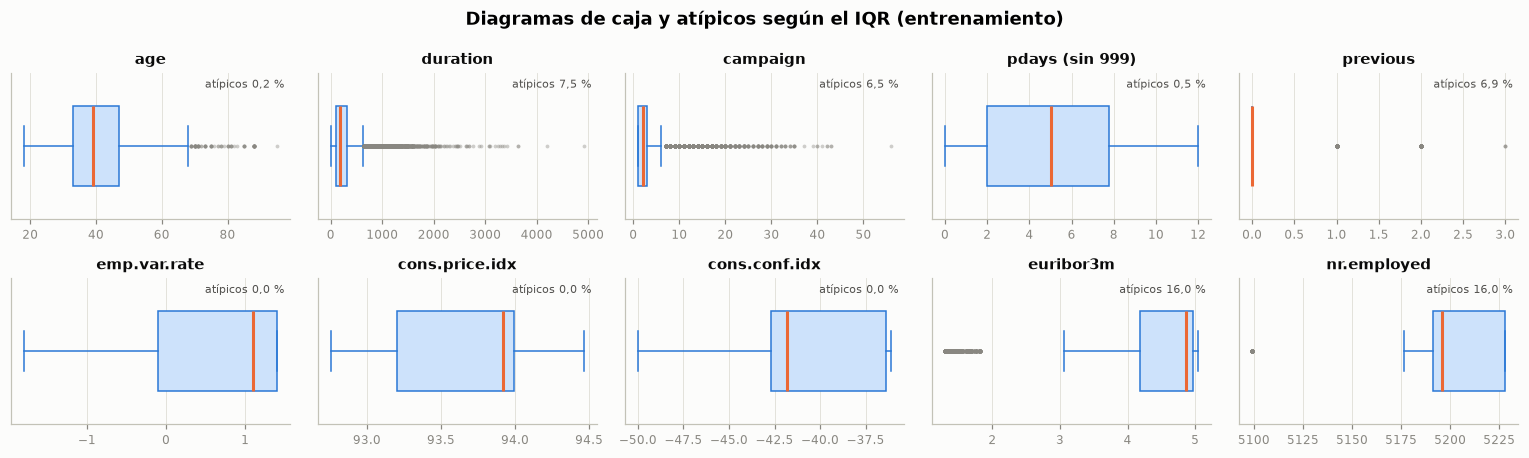

**Interpretación.** `log1p` reduce la asimetría de `campaign` de 4,65 a 1,36 y la de `previous` de 3,87 a 3,54. Los diagramas de caja muestran atípicos sobre todo en `previous` (6,9 %), `duration` (7,5 %) y `campaign` (6,5 %); en las macro solo `euribor3m` y `nr.employed` tiene atípicos univariados.

Así mismo, los atípicos son valores legítimos de la cola (clientes muy contactados o con historial), no errores de medición, así que su eliminación sesgaría la muestra. La transformación logarítmica reduce su palanca sin perder registros.

Por esta razón, lo indicado es conservar todos los registros y tratar los atípicos con `log1p` en `campaign` y `previous` dentro del `Pipeline`; `duration` no se transforma porque queda excluida por fuga (sección 3.5).

In [15]:
transformadas = pd.DataFrame({
    "Asimetría original": [tr[c].skew() for c in ["campaign", "previous", "duration"]],
    "Asimetría con log1p": [np.log1p(tr[c]).skew() for c in ["campaign", "previous", "duration"]],
    "Curtosis original": [tr[c].kurt() for c in ["campaign", "previous", "duration"]],
    "Curtosis con log1p": [np.log1p(tr[c]).kurt() for c in ["campaign", "previous", "duration"]]},
    index=["campaign", "previous", "duration"])
tabla(transformadas, dec=2)

fig, axs = plt.subplots(2, 5, figsize=(14, 4.2))
for ax, c in zip(axs.ravel(), NUMERICAS):
    s = pd_real if c == "pdays" else tr[c]
    ax.boxplot(s, orientation="horizontal", widths=0.55, patch_artist=True,
               boxprops={"facecolor": "#cde2fb", "edgecolor": AZUL}, medianprops={"color": NARANJA, "lw": 2},
               whiskerprops={"color": AZUL}, capprops={"color": AZUL},
               flierprops={"marker": "o", "markersize": 2.5, "markerfacecolor": GRIS, "markeredgecolor": "none",
                           "alpha": 0.4})
    ax.set_yticks([])
    ax.set_title("pdays (sin 999)" if c == "pdays" else c, fontsize=9.5)
    ax.text(0.98, 0.9, f"atípicos {num(uni_num.loc[c, 'Atípicos IQR (%)'], 1)} %", transform=ax.transAxes,
            ha="right", fontsize=7.5, color=TINTA_2)
fig.suptitle("Diagramas de caja y atípicos según el IQR (entrenamiento)")
plt.tight_layout()
plt.show()

interpretar(
    f"`log1p` reduce la asimetría de `campaign` de {num(transformadas.loc['campaign', 'Asimetría original'], 2)} a "
    f"{num(transformadas.loc['campaign', 'Asimetría con log1p'], 2)} y la de `previous` de "
    f"{num(transformadas.loc['previous', 'Asimetría original'], 2)} a "
    f"{num(transformadas.loc['previous', 'Asimetría con log1p'], 2)}. Los diagramas de caja muestran atípicos "
    f"sobre todo en `previous` ({num(uni_num.loc['previous', 'Atípicos IQR (%)'], 1)} %), `duration` "
    f"({num(uni_num.loc['duration', 'Atípicos IQR (%)'], 1)} %) y `campaign` "
    f"({num(uni_num.loc['campaign', 'Atípicos IQR (%)'], 1)} %); en las macro "
    + ("no hay atípicos univariados." if not [c for c in MACRO if uni_num.loc[c, "Atípicos IQR (%)"] > 0] else
       "solo " + enumerar([c for c in MACRO if uni_num.loc[c, "Atípicos IQR (%)"] > 0]) + " tiene atípicos univariados."),
    "Así mismo, los atípicos son valores legítimos de la cola (clientes muy contactados o con historial), no errores "
    "de medición, así que su eliminación sesgaría la muestra. La transformación logarítmica reduce su palanca sin "
    "perder registros.",
    "Por esta razón, lo indicado es conservar todos los registros y tratar los atípicos con `log1p` en `campaign` y "
    "`previous` dentro del `Pipeline`; `duration` no se transforma porque queda excluida por fuga (sección 3.5).")

#### 3.2.2 Variables categóricas

Se reportan la cardinalidad, la moda, el porcentaje de `unknown` y las categorías raras (menos del 1 % de los registros), con la frecuencia de cada categoría y su gráfico de barras.

,Cardinalidad,Moda,% moda,% unknown,Categorías raras (menos del 1 %)
Variable,,,,,
job,12,admin.,"24,40","0,81",unknown (266)
marital,4,married,"62,92","0,19",unknown (62)
education,8,university.degree,"28,43","4,01",illiterate (14)
default,3,no,"75,66","24,34",yes (3)
housing,3,yes,"51,53","2,37",—
loan,3,no,"82,39","2,37",—
contact,2,cellular,"57,35","0,00",—
month,9,may,"31,21","0,00","mar (282), oct (67), dec (10)"
day_of_week,5,thu,"21,25","0,00",—


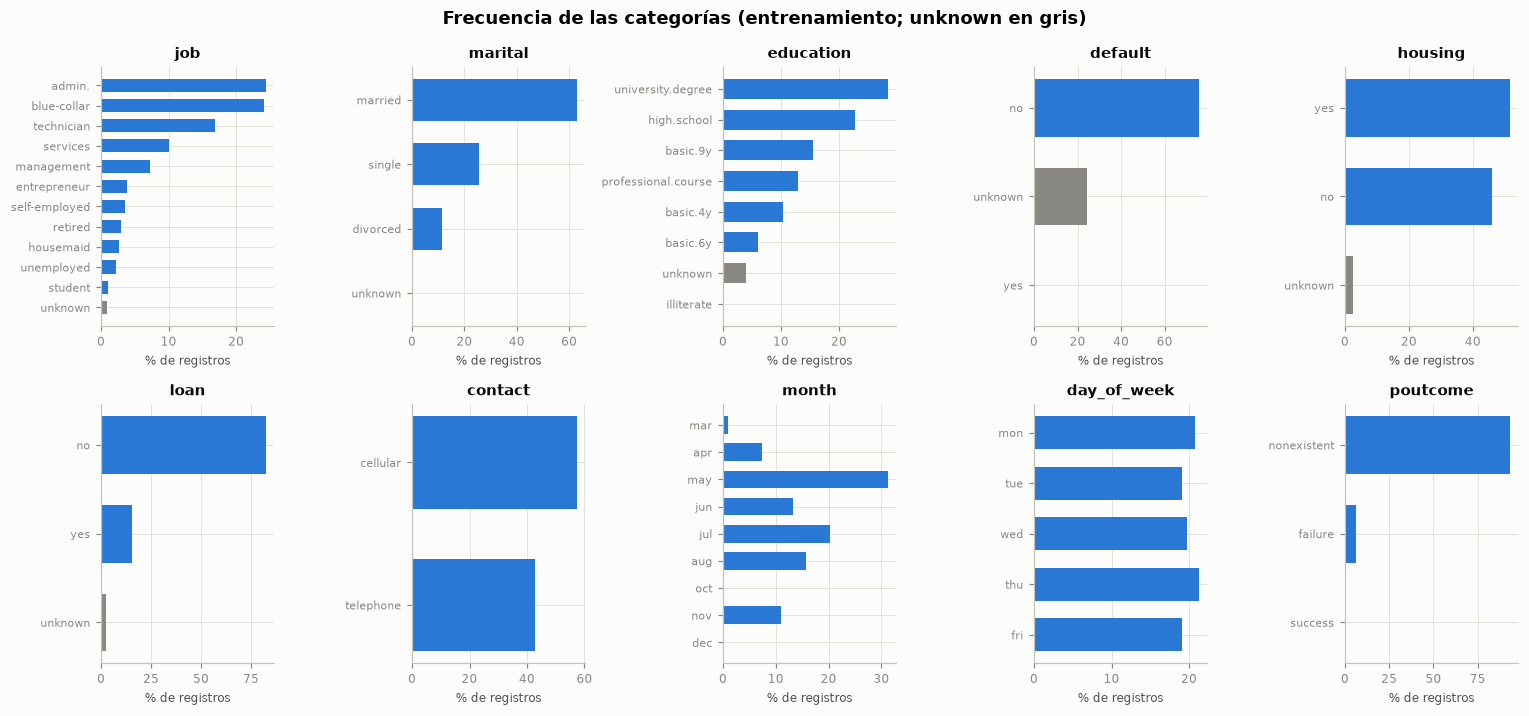

Variable,Categoría,Registros,%
job,admin.,8 038,"24,40"
job,blue-collar,7 958,"24,16"
job,technician,5 573,"16,92"
job,services,3 323,"10,09"
job,management,2 400,"7,29"
job,entrepreneur,1 261,"3,83"
job,self-employed,1 156,"3,51"
job,retired,989,"3,00"
job,housemaid,880,"2,67"
job,unemployed,749,"2,27"


**Interpretación.** Las cardinalidades van de 2 (`contact`) a 12 (`job`). Varias variables están dominadas por una categoría: `poutcome` = nonexistent (93,1 %), `loan` = no (82,4 %) y `default` = no (75,7 %). `month` concentra los contactos en may (31,2 %), mientras que `day_of_week` es casi uniforme. Hay 5 categorías con menos del 0,5 % de los registros: `marital = unknown` (62), `education = illiterate` (14), `default = yes` (3), `month = oct` (67), `month = dec` (10).

Hay que tener en cuenta que una categoría con muy pocos registros produce un coeficiente inestable y puede no aparecer en algún pliegue de validación. Las variables dominadas por una sola categoría aportan información solo a través de la minoría (por ejemplo, `poutcome = success`).

Por ello, se recomienda agrupar en el codificador las categorías con menos del 0,5 % de los registros de entrenamiento como categoría "infrecuente" de su variable, lo que además protege contra categorías no vistas, y conservar `unknown` como categoría propia (sección 1.6.2).

In [16]:
ORDEN_CAT = {"month": [m for m in ORDEN_MESES if m in tr["month"].unique()],
             "day_of_week": ["mon", "tue", "wed", "thu", "fri"]}
filas_cat, frecuencias = [], []
for c in CATEGORICAS:
    vc = tr[c].value_counts()
    raras = vc[vc / len(tr) < 0.01]
    filas_cat.append({"Variable": c, "Cardinalidad": tr[c].nunique(), "Moda": vc.index[0],
                      "% moda": 100 * vc.iloc[0] / len(tr), "% unknown": 100 * (tr[c] == "unknown").mean(),
                      "Categorías raras (menos del 1 %)": ", ".join(f"{k} ({v})" for k, v in raras.items()) or "—"})
    for k, v in vc.items():
        frecuencias.append({"Variable": c, "Categoría": k, "Registros": v, "%": 100 * v / len(tr)})
uni_cat = pd.DataFrame(filas_cat).set_index("Variable")
tabla(uni_cat, dec=2)

fig, axs = plt.subplots(2, 5, figsize=(14, 6.6))
for ax, c in zip(axs.ravel(), CATEGORICAS):
    vc = tr[c].value_counts(normalize=True)
    vc = vc.reindex(ORDEN_CAT[c]) if c in ORDEN_CAT else vc.sort_values()
    colores = [GRIS if k == "unknown" else AZUL for k in vc.index]
    ax.barh(vc.index.astype(str), 100 * vc.values, color=colores, height=0.65)
    ax.set_title(c, fontsize=9.5)
    ax.set_xlabel("% de registros", fontsize=8)
    ax.tick_params(axis="y", labelsize=7.5)
    if c in ORDEN_CAT:
        ax.invert_yaxis()
fig.suptitle("Frecuencia de las categorías (entrenamiento; unknown en gris)")
plt.tight_layout()
plt.show()

frec = pd.DataFrame(frecuencias)
tabla(frec, dec=2, indice=False)

MIN_FREQ = 0.005  # umbral de categoría rara para el codificador (sección 3.7)
muy_raras = frec[frec["%"] < 100 * MIN_FREQ]
interpretar(
    f"Las cardinalidades van de {uni_cat['Cardinalidad'].min()} (`contact`) a {uni_cat['Cardinalidad'].max()} "
    f"(`job`). Varias variables están dominadas por una categoría: `poutcome` = "
    f"{uni_cat.loc['poutcome', 'Moda']} ({num(uni_cat.loc['poutcome', '% moda'], 1)} %), `loan` = "
    f"{uni_cat.loc['loan', 'Moda']} ({num(uni_cat.loc['loan', '% moda'], 1)} %) y `default` = "
    f"{uni_cat.loc['default', 'Moda']} ({num(uni_cat.loc['default', '% moda'], 1)} %). `month` concentra los contactos en "
    f"{uni_cat.loc['month', 'Moda']} ({num(uni_cat.loc['month', '% moda'], 1)} %), mientras que `day_of_week` es "
    f"casi uniforme. Hay {len(muy_raras)} categorías con menos del {pct(MIN_FREQ)} de los registros: "
    + ", ".join(f"`{r.Variable} = {r.Categoría}` ({r.Registros})" for r in muy_raras.itertuples()) + ".",
    "Hay que tener en cuenta que una categoría con muy pocos registros produce un coeficiente inestable y puede no "
    "aparecer en algún pliegue de validación. Las variables dominadas por una sola categoría aportan información solo "
    "a través de la minoría (por ejemplo, `poutcome = success`).",
    f"Por ello, se recomienda agrupar en el codificador las categorías con menos del {pct(MIN_FREQ)} de los registros "
    "de entrenamiento como categoría \"infrecuente\" de su variable, lo que además protege contra categorías no "
    "vistas, y conservar `unknown` como categoría propia (sección 1.6.2).")

### 3.3 Análisis bidimensional (enunciado, sección 2.3)

#### 3.3.1 Numéricas frente a numéricas

Se calculan las correlaciones de Pearson (lineal) y Spearman (monótona) para los 45 pares de variables numéricas, con valores *p* de Spearman ajustados por Holm. Los diagramas *hexbin* reemplazan al diagrama de dispersión porque, con más de 30 000 puntos, la superposición ocultaría la densidad.

Variable 1,Variable 2,Pearson,Spearman,p Spearman (Holm)
emp.var.rate,nr.employed,"0,946","0,936","0,000"
emp.var.rate,euribor3m,"0,978","0,925","0,000"
euribor3m,nr.employed,"0,952","0,869","0,000"
emp.var.rate,cons.price.idx,"0,780","0,535","0,000"
cons.conf.idx,euribor3m,"0,716","0,487","0,000"
cons.price.idx,cons.conf.idx,"0,372","0,428","0,000"
emp.var.rate,cons.conf.idx,"0,688","0,403","0,000"
previous,emp.var.rate,"-0,441","-0,383","0,000"
cons.price.idx,euribor3m,"0,735","0,372","0,000"
previous,cons.price.idx,"-0,366","-0,361","0,000"


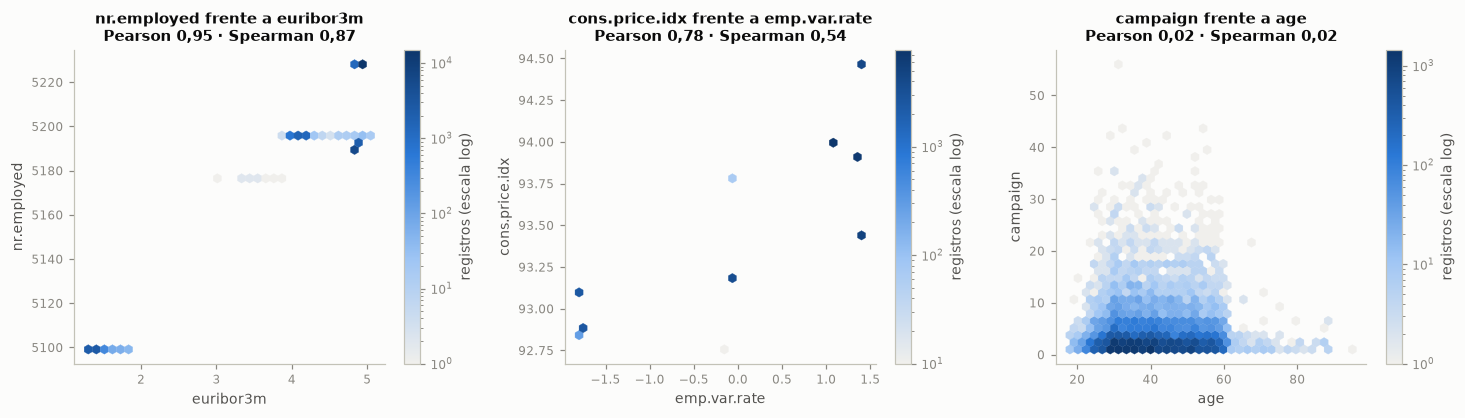

**Interpretación.** 3 pares tienen |Spearman| ≥ 0,7, todos entre indicadores macroeconómicos: `emp.var.rate`–`nr.employed` (0,94); `emp.var.rate`–`euribor3m` (0,93); `euribor3m`–`nr.employed` (0,87). Los *hexbin* muestran que esas relaciones se forman con pocas combinaciones de valores (una por periodo). La mayor diferencia entre Spearman y Pearson aparece en `cons.price.idx`–`euribor3m` (0,37 frente a 0,74), señal de que la asociación lineal depende de unos pocos grupos de valores (los periodos) más que de una relación monótona. La edad y el número de contactos de la campaña no están relacionados (Spearman 0,02).

Esto significa que las macro miden casi lo mismo (el ciclo económico del periodo), así que en un modelo lineal se reparten el efecto y sus coeficientes individuales se vuelven inestables y difíciles de interpretar.

Con base en esto, se propone cuantificar la multicolinealidad con el VIF (sección 3.3.5) y eliminar las variables redundantes antes del modelo base.

In [17]:
pares = []
for i, a in enumerate(NUMERICAS):
    for b in NUMERICAS[i + 1:]:
        sp = stats.spearmanr(tr[a], tr[b])
        pares.append({"Variable 1": a, "Variable 2": b, "Pearson": tr[a].corr(tr[b]), "Spearman": sp.statistic,
                      "p Spearman": sp.pvalue})
pares = pd.DataFrame(pares)
pares["p Spearman (Holm)"] = multipletests(pares["p Spearman"], method="holm")[1]
pares["|Spearman|"] = pares["Spearman"].abs()
pares = pares.sort_values("|Spearman|", ascending=False)
tabla(pares.drop(columns=["|Spearman|", "p Spearman"]).head(12), dec=3, indice=False)

fig, axs = plt.subplots(1, 3, figsize=(13.5, 3.9))
for ax, (a, b) in zip(axs, [("euribor3m", "nr.employed"), ("emp.var.rate", "cons.price.idx"), ("age", "campaign")]):
    hb = ax.hexbin(tr[a], tr[b], gridsize=35, bins="log", cmap=CMAP_SEQ, mincnt=1, linewidths=0.2)
    r_p, r_s = tr[a].corr(tr[b]), tr[a].corr(tr[b], method="spearman")
    ax.set_title(f"{b} frente a {a}\nPearson {num(r_p, 2)} · Spearman {num(r_s, 2)}", fontsize=9.5)
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.grid(False)
    fig.colorbar(hb, ax=ax, label="registros (escala log)")
plt.tight_layout()
plt.show()

fuertes = pares[pares["|Spearman|"] >= 0.7]
dif_lin = pares.assign(dif=(pares["Spearman"] - pares["Pearson"]).abs()).sort_values("dif", ascending=False).iloc[0]
interpretar(
    f"{len(fuertes)} pares tienen |Spearman| ≥ 0,7, todos entre indicadores macroeconómicos: "
    + "; ".join(f"`{r['Variable 1']}`–`{r['Variable 2']}` ({num(r['Spearman'], 2)})" for _, r in fuertes.iterrows())
    + f". Los *hexbin* muestran que esas relaciones se forman con pocas combinaciones de valores (una por periodo). "
    f"La mayor diferencia entre Spearman y Pearson aparece en `{dif_lin['Variable 1']}`–`{dif_lin['Variable 2']}` "
    f"({num(dif_lin['Spearman'], 2)} frente a {num(dif_lin['Pearson'], 2)}), "
    + ("señal de relación monótona no lineal. " if abs(dif_lin["Spearman"]) > abs(dif_lin["Pearson"]) else
       "señal de que la asociación lineal depende de unos pocos grupos de valores (los periodos) más que de una "
       "relación monótona. ")
    + ""
    f"La edad y el número de contactos de la campaña no están relacionados (Spearman "
    f"{num(tr['age'].corr(tr['campaign'], method='spearman'), 2)}).",
    "Esto significa que las macro miden casi lo mismo (el ciclo económico del periodo), así que en un modelo lineal se "
    "reparten el efecto y sus coeficientes individuales se vuelven inestables y difíciles de interpretar.",
    "Con base en esto, se propone cuantificar la multicolinealidad con el VIF (sección 3.3.5) y eliminar las variables "
    "redundantes antes del modelo base.")

#### 3.3.2 Categóricas frente a numéricas

Para cada par categórica-numérica se aplica Kruskal-Wallis (alternativa no paramétrica al ANOVA, adecuada porque la normalidad se rechazó en la sección 3.2.1). El tamaño de efecto es $\varepsilon^2 = H/(n-1)$, que se lee como la proporción de la variabilidad de los rangos explicada por la categoría (guía orientativa: 0,01 pequeño, 0,06 mediano, 0,14 grande).

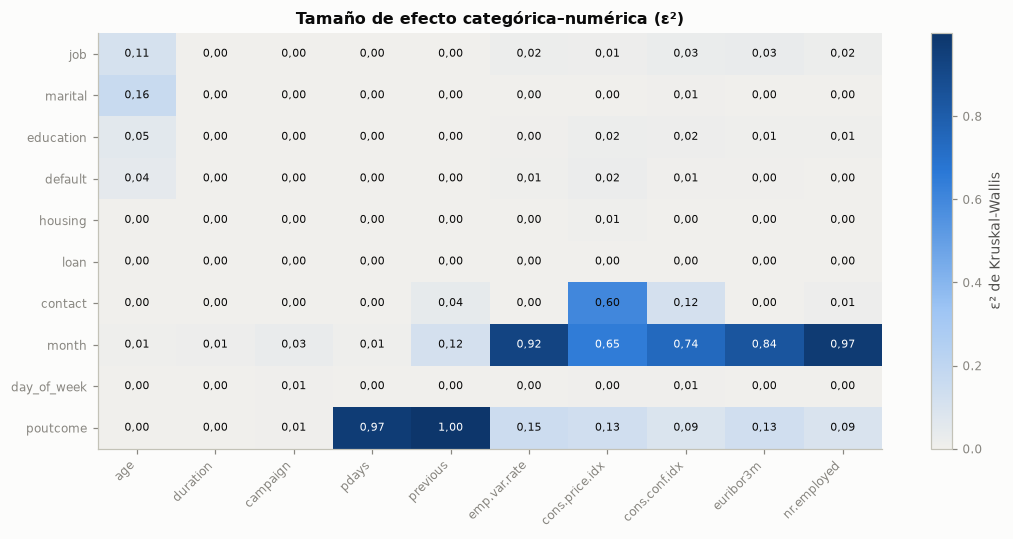

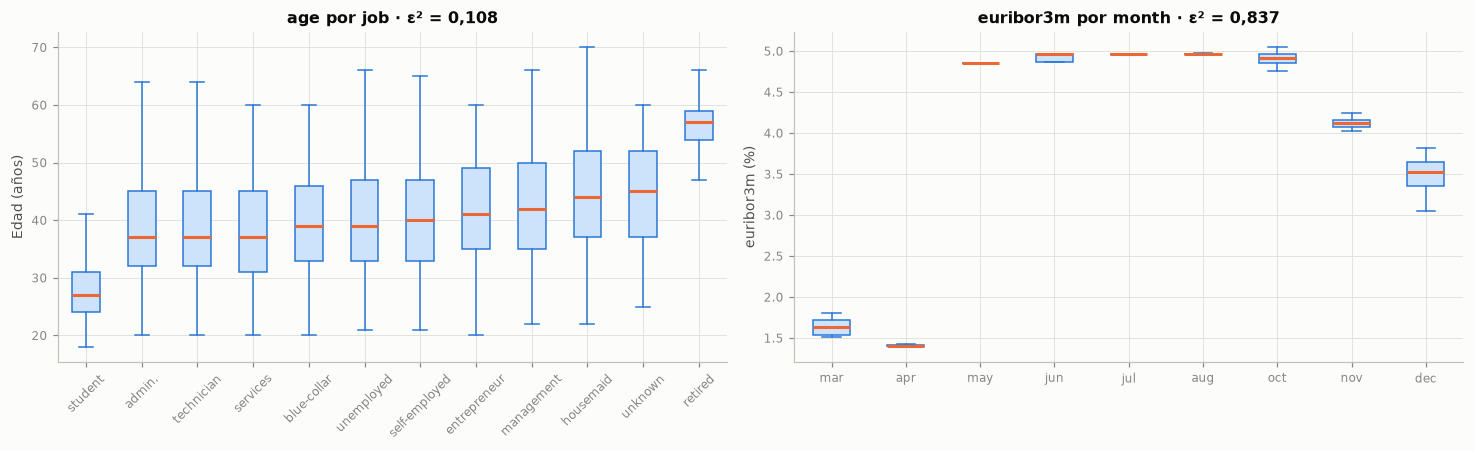

**Interpretación.** 72 de los 100 pares resultan significativos tras Holm, pero solo 17 alcanzan un efecto al menos mediano (ε² ≥ 0,06). Los mayores son `poutcome`–`previous` (1,000); `month`–`nr.employed` (0,969); `poutcome`–`pdays` (0,966); `month`–`emp.var.rate` (0,923); `month`–`euribor3m` (0,837); `month`–`cons.conf.idx` (0,740). Los dos primeros son estructurales: `poutcome = nonexistent` ocurre exactamente cuando `previous = 0` (sección 1.6.4). La edad varía con el estado civil (ε² = 0,163) y con la ocupación (ε² = 0,108): la mediana más baja es la de `student` (27 años) y la más alta la de `retired` (57 años); y la Euribor cambia con el mes porque el mes, junto con el orden del archivo, marca el periodo.

De esta forma, la alta significancia con efectos pequeños confirma que, con este n, el valor p no basta para seleccionar variables. Las asociaciones fuertes entre `month`, `contact`, `poutcome` y las macro indican que varias predictoras comparten la misma información del periodo y del historial.

En virtud de ello, se decide usar el tamaño de efecto, no el valor p, en la selección preliminar (sección 3.3.6) y tener presente que `month` y las macro son, en parte, sustitutos entre sí.

In [18]:
eps2 = pd.DataFrame(index=CATEGORICAS, columns=NUMERICAS, dtype=float)
pvals_kw = []
for c in CATEGORICAS:
    for v in NUMERICAS:
        muestras = [tr.loc[tr[c] == k, v].to_numpy() for k in tr[c].unique()]
        h, p = stats.kruskal(*muestras)
        eps2.loc[c, v] = h / (len(tr) - 1)
        pvals_kw.append({"Categórica": c, "Numérica": v, "H": h, "p": p, "ε²": h / (len(tr) - 1)})
kw = pd.DataFrame(pvals_kw)
kw["p (Holm)"] = multipletests(kw["p"], method="holm")[1]
n_sig_kw = int((kw["p (Holm)"] < 0.05).sum())

fig, ax = plt.subplots(figsize=(10, 5))
im = mapa_calor(ax, eps2.to_numpy(), CATEGORICAS, NUMERICAS, CMAP_SEQ, 0, max(0.3, eps2.max().max()), dec=2)
fig.colorbar(im, ax=ax, label="ε² de Kruskal-Wallis")
ax.set_title("Tamaño de efecto categórica–numérica (ε²)")
plt.tight_layout()
plt.show()

fig, axs = plt.subplots(1, 2, figsize=(13.5, 4.2))
orden_job = tr.groupby("job")["age"].median().sort_values().index
axs[0].boxplot([tr.loc[tr["job"] == k, "age"] for k in orden_job], tick_labels=orden_job, showfliers=False,
               patch_artist=True, boxprops={"facecolor": "#cde2fb", "edgecolor": AZUL},
               medianprops={"color": NARANJA, "lw": 2}, whiskerprops={"color": AZUL}, capprops={"color": AZUL})
axs[0].tick_params(axis="x", rotation=45)
axs[0].set_ylabel("Edad (años)")
axs[0].set_title(f"age por job · ε² = {num(eps2.loc['job', 'age'], 3)}")
meses = ORDEN_CAT["month"]
axs[1].boxplot([tr.loc[tr["month"] == m, "euribor3m"] for m in meses], tick_labels=meses, showfliers=False,
               patch_artist=True, boxprops={"facecolor": "#cde2fb", "edgecolor": AZUL},
               medianprops={"color": NARANJA, "lw": 2}, whiskerprops={"color": AZUL}, capprops={"color": AZUL})
axs[1].set_ylabel("euribor3m (%)")
axs[1].set_title(f"euribor3m por month · ε² = {num(eps2.loc['month', 'euribor3m'], 3)}")
plt.tight_layout()
plt.show()

top_kw = kw.sort_values("ε²", ascending=False).head(6)
interpretar(
    f"{n_sig_kw} de los {len(kw)} pares resultan significativos tras Holm, pero solo "
    f"{int((kw['ε²'] >= 0.06).sum())} alcanzan un efecto al menos mediano (ε² ≥ 0,06). Los mayores son "
    + "; ".join(f"`{r['Categórica']}`–`{r['Numérica']}` ({num(r['ε²'], 3)})" for _, r in top_kw.iterrows())
    + f". Los dos primeros son estructurales: `poutcome = nonexistent` ocurre exactamente cuando `previous = 0` "
    f"(sección 1.6.4). La edad varía con el estado civil (ε² = {num(eps2.loc['marital', 'age'], 3)}) y con la "
    f"ocupación (ε² = {num(eps2.loc['job', 'age'], 3)}): la mediana más baja es la de "
    f"`{orden_job[0]}` ({num(tr.loc[tr['job'] == orden_job[0], 'age'].median())} años) y la más alta la de "
    f"`{orden_job[-1]}` ({num(tr.loc[tr['job'] == orden_job[-1], 'age'].median())} años); y la Euribor cambia con el "
    "mes porque el mes, junto con el orden del archivo, marca el periodo.",
    "De esta forma, la alta significancia con efectos pequeños confirma que, con este n, el valor p no basta para "
    "seleccionar variables. Las asociaciones fuertes entre `month`, `contact`, `poutcome` y las macro indican que "
    "varias predictoras comparten la misma información del periodo y del historial.",
    "En virtud de ello, se decide usar el tamaño de efecto, no el valor p, en la selección preliminar (sección 3.3.6) "
    "y tener presente que `month` y las macro son, en parte, sustitutos entre sí.")

#### 3.3.3 Categóricas frente a categóricas

Para cada par de categóricas (incluida la variable objetivo) se construye la tabla de contingencia, se aplica la prueba χ² y se calcula la V de Cramér como tamaño de efecto (guía orientativa: 0,1 pequeña, 0,3 mediana, 0,5 grande), con ajuste de Holm.

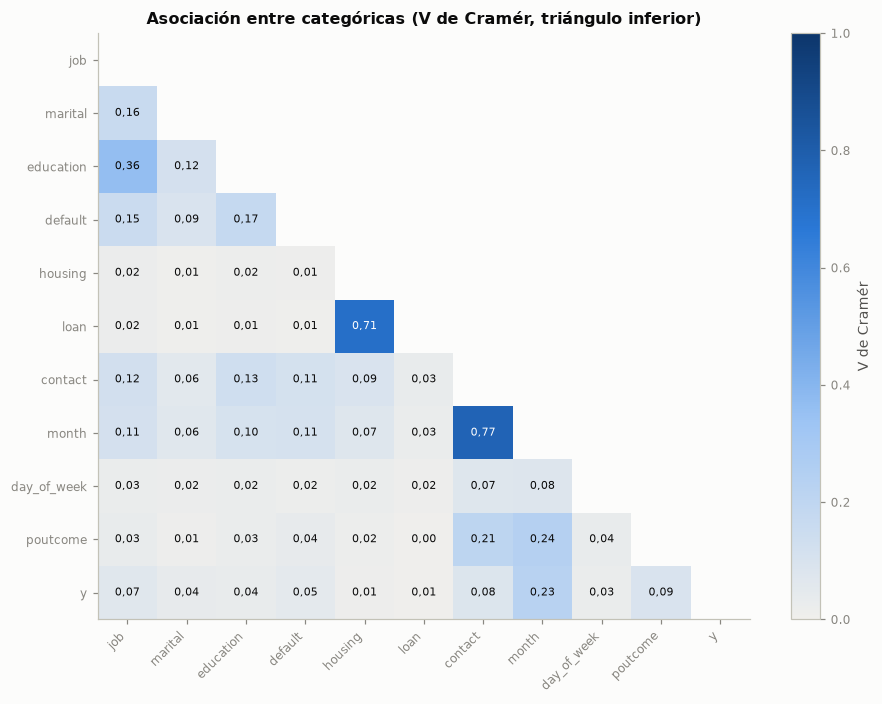

Tabla de contingencia housing × loan (entrenamiento):


loan,no,unknown,yes,Total
housing,,,,
no,13083,0,2103,15186
unknown,0,781,0,781
yes,14055,0,2918,16973
Total,27138,781,5021,32940


**Interpretación.** Los pares de predictoras más asociados son `contact`–`month` (V = 0,77); `housing`–`loan` (V = 0,71); `job`–`education` (V = 0,36); `month`–`poutcome` (V = 0,24); `contact`–`poutcome` (V = 0,21). La V entre `housing` y `loan` (0,71) se explica por la tabla de contingencia: las dos son `unknown` exactamente en los mismos 781 registros. Frente a la objetivo, las mayores asociaciones son `month` (0,23), `poutcome` (0,09), `contact` (0,08), `job` (0,07).

Por su parte, la asociación `month`–`contact` (V = 0,77) y `month`–`poutcome` (V = 0,24) refleja la estructura temporal: los canales y el historial cambian según el periodo de la campaña. `housing = unknown` y `loan = unknown` son la misma información duplicada.

Por tanto, corresponde mantener ambas variables (el resto de sus categorías sí difiere), sabiendo que sus indicadores de `unknown` son colineales; la regularización L2 del modelo base reparte ese efecto de forma estable.

In [19]:
CAT_Y = CATEGORICAS + ["y"]
tr_cat = tr[CATEGORICAS].assign(y=tr["y"].map({0: "no", 1: "yes"}))
V = pd.DataFrame(np.nan, index=CAT_Y, columns=CAT_Y)
pruebas_cc = []
for i, a in enumerate(CAT_Y):
    for b in CAT_Y[i + 1:]:
        v, chi2, p = v_cramer(pd.crosstab(tr_cat[a], tr_cat[b]))
        V.loc[b, a] = v
        pruebas_cc.append({"Variable 1": a, "Variable 2": b, "χ²": chi2, "p": p, "V de Cramér": v})
cc = pd.DataFrame(pruebas_cc)
cc["p (Holm)"] = multipletests(cc["p"], method="holm")[1]

fig, ax = plt.subplots(figsize=(8.5, 6.5))
im = mapa_calor(ax, V.to_numpy(), CAT_Y, CAT_Y, CMAP_SEQ, 0, 1, dec=2)
fig.colorbar(im, ax=ax, label="V de Cramér")
ax.set_title("Asociación entre categóricas (V de Cramér, triángulo inferior)")
plt.tight_layout()
plt.show()

print("Tabla de contingencia housing × loan (entrenamiento):")
display(pd.crosstab(tr["housing"], tr["loan"], margins=True, margins_name="Total"))

top_cc = cc[(cc["Variable 1"] != "y") & (cc["Variable 2"] != "y")].sort_values("V de Cramér", ascending=False).head(5)
cc_y = cc[(cc["Variable 2"] == "y")].sort_values("V de Cramér", ascending=False)
hl = cc[(cc["Variable 1"] == "housing") & (cc["Variable 2"] == "loan")].iloc[0]
interpretar(
    f"Los pares de predictoras más asociados son "
    + "; ".join(f"`{r['Variable 1']}`–`{r['Variable 2']}` (V = {num(r['V de Cramér'], 2)})" for _, r in top_cc.iterrows())
    + f". La V entre `housing` y `loan` ({num(hl['V de Cramér'], 2)}) se explica por la tabla de contingencia: "
    f"las dos son `unknown` exactamente en los mismos {num(int((tr['housing'] == 'unknown').sum()))} registros. "
    f"Frente a la objetivo, las mayores asociaciones son "
    + ", ".join(f"`{r['Variable 1']}` ({num(r['V de Cramér'], 2)})" for _, r in cc_y.head(4).iterrows()) + ".",
    (f"Por su parte, la asociación `month`–`contact` (V = {num(V.loc['month', 'contact'], 2)}) y `month`–`poutcome` "
     f"(V = {num(V.loc['poutcome', 'month'], 2)}) refleja la estructura temporal: los canales y el historial cambian "
     "según el periodo de la campaña. ")
    + "`housing = unknown` y `loan = unknown` son la misma información duplicada.",
    "Por tanto, corresponde mantener ambas variables (el resto de sus categorías sí difiere), sabiendo que sus "
    "indicadores de `unknown` son colineales; la regularización L2 del modelo base reparte ese efecto de forma "
    "estable.")

#### 3.3.4 Predictoras frente a la variable objetivo

- **Numéricas:** prueba de Mann-Whitney entre quienes suscriben y quienes no; tamaño de efecto con la correlación biserial de rangos $r = 2\,\mathrm{AUC} - 1$ (positiva si los valores son mayores entre quienes suscriben; guía orientativa: 0,1 pequeño, 0,3 mediano, 0,5 grande).
- **Categóricas:** χ² y V de Cramér.
- **Todas:** información mutua (no paramétrica, capta relaciones no lineales), estimada con `random_state = SEED`.

Los valores *p* de las 20 pruebas se ajustan por Holm y por FDR (Benjamini-Hochberg).

,Tipo,Prueba,Estadístico,Efecto,Medida de efecto,p (Holm),p (FDR),Información mutua,Rango IM
Variable,,,,,,,,,
duration,numérica,Mann-Whitney,"57 536 669,5000","0,7768",r biserial de rangos,"0,0000","0,0000","0,0798",1
euribor3m,numérica,Mann-Whitney,"27 191 391,0000","-0,1603",r biserial de rangos,"0,0000","0,0000","0,0226",2
cons.conf.idx,numérica,Mann-Whitney,"23 509 204,5000","-0,2740",r biserial de rangos,"0,0000","0,0000","0,0155",3
cons.price.idx,numérica,Mann-Whitney,"23 756 876,5000","-0,2664",r biserial de rangos,"0,0000","0,0000","0,0153",4
month,categórica,χ²,"1 736,5959","0,2296",V de Cramér,"0,0000","0,0000","0,0152",5
emp.var.rate,numérica,Mann-Whitney,"26 028 976,0000","-0,1962",r biserial de rangos,"0,0000","0,0000","0,0130",6
nr.employed,numérica,Mann-Whitney,"26 946 080,0000","-0,1679",r biserial de rangos,"0,0000","0,0000","0,0094",7
pdays,numérica,Mann-Whitney,"31 477 195,0000","-0,0279",r biserial de rangos,"0,0000","0,0000","0,0067",8
age,numérica,Mann-Whitney,"30 464 978,0000","-0,0592",r biserial de rangos,"0,0000","0,0000","0,0036",9


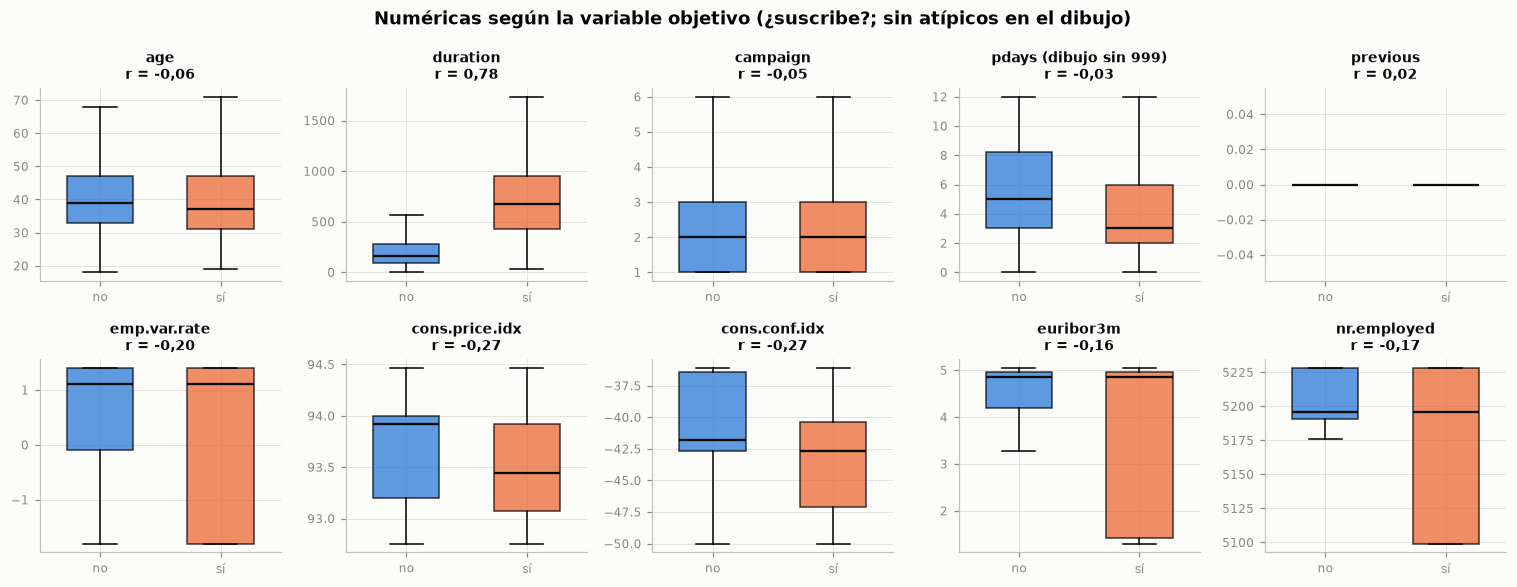

In [20]:
asoc = []
for c in NUMERICAS:
    pos, neg = tr.loc[tr["y"] == 1, c], tr.loc[tr["y"] == 0, c]
    u, p = stats.mannwhitneyu(pos, neg)
    asoc.append({"Variable": c, "Tipo": "numérica", "Prueba": "Mann-Whitney", "Estadístico": u, "p": p,
                 "Efecto": 2 * u / (len(pos) * len(neg)) - 1, "Medida de efecto": "r biserial de rangos"})
for c in CATEGORICAS:
    v, chi2, p = v_cramer(pd.crosstab(tr[c], tr["y"]))
    asoc.append({"Variable": c, "Tipo": "categórica", "Prueba": "χ²", "Estadístico": chi2, "p": p, "Efecto": v,
                 "Medida de efecto": "V de Cramér"})
asoc = pd.DataFrame(asoc).set_index("Variable")
asoc["p (Holm)"] = multipletests(asoc["p"], method="holm")[1]
asoc["p (FDR)"] = multipletests(asoc["p"], method="fdr_bh")[1]
X_im = tr[NUMERICAS + CATEGORICAS].copy()
for c in CATEGORICAS:
    X_im[c] = X_im[c].astype("category").cat.codes
im_vals = mutual_info_classif(X_im, tr["y"], discrete_features=[c in CATEGORICAS for c in X_im.columns],
                              random_state=SEED)
asoc["Información mutua"] = pd.Series(im_vals, index=X_im.columns)
asoc = asoc.sort_values("Información mutua", ascending=False)
asoc["Rango IM"] = np.arange(1, len(asoc) + 1)
tabla(asoc.drop(columns="p"), dec=4)

fig, axs = plt.subplots(2, 5, figsize=(14, 5.4))
for ax, c in zip(axs.ravel(), NUMERICAS):
    filtro = (tr["pdays"] != 999) if c == "pdays" else np.ones(len(tr), dtype=bool)
    datos = [tr.loc[(tr["y"] == k) & filtro, c] for k in (0, 1)]
    bp = ax.boxplot(datos, tick_labels=["no", "sí"], showfliers=False, patch_artist=True, widths=0.55,
                    medianprops={"color": TINTA, "lw": 1.5})
    for caja, col in zip(bp["boxes"], [AZUL, NARANJA]):
        caja.set_facecolor(col)
        caja.set_alpha(0.75)
    ax.set_title(("pdays (dibujo sin 999)" if c == "pdays" else c) + f"\nr = {num(asoc.loc[c, 'Efecto'], 2)}",
                 fontsize=9)
fig.suptitle("Numéricas según la variable objetivo (¿suscribe?; sin atípicos en el dibujo)")
plt.tight_layout()
plt.show()

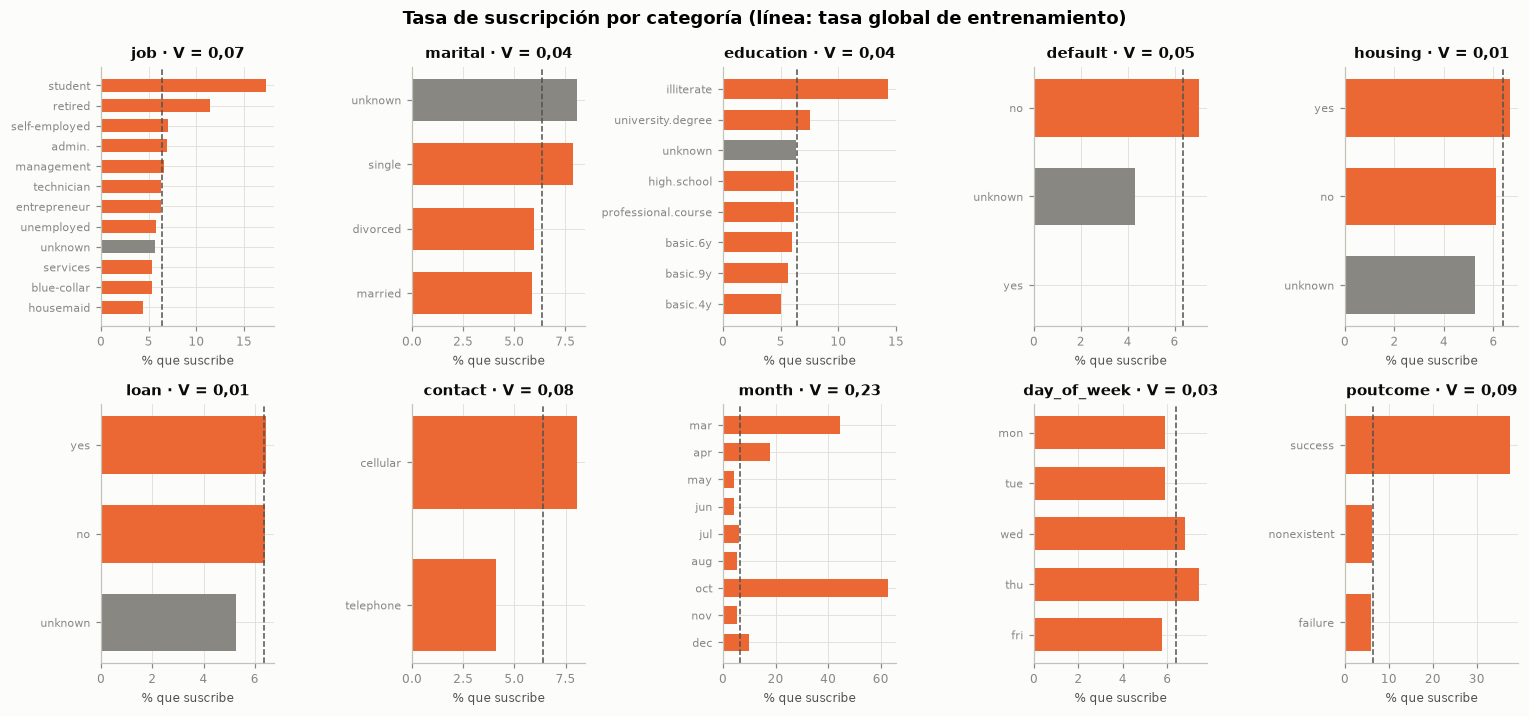

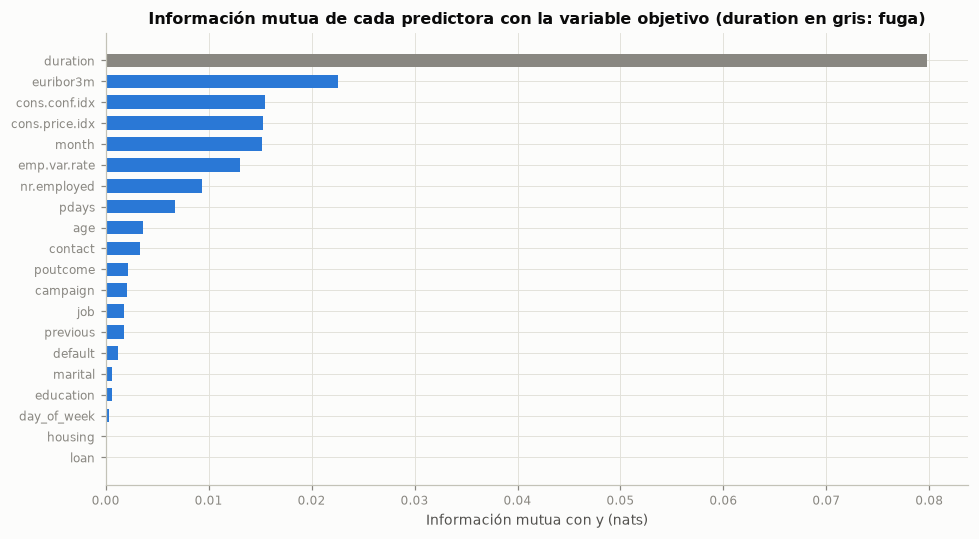

**Interpretación.** Entre las numéricas, el mayor efecto es el de `duration` (r = 0,78), seguido de `cons.conf.idx` (-0,27) y `cons.price.idx` (-0,27); `euribor3m`, `nr.employed` y `emp.var.rate` tienen efectos negativos: se suscribe más cuando la Euribor y el empleo son bajos. Entre las categóricas destacan `month` (V = 0,23) y `poutcome` (0,09): con `poutcome = success` suscribe el 37,5 %, frente al 6,2 % sin campaña previa. Por información mutua, las seis primeras son `duration`, `euribor3m`, `cons.conf.idx`, `cons.price.idx`, `month` y `emp.var.rate`. No son significativas tras Holm: `housing` y `loan`; en el caso de la edad, la información mutua (rango 9) sí detecta una relación, que no es monótona.

Entonces, sin `duration`, la mayor información mutua con `y` es la de `euribor3m`, `cons.conf.idx`, `cons.price.idx` y `month`, que describen sobre todo el contexto del periodo; el historial con el banco y el canal aportan menos, y los atributos del cliente, todavía menos. `duration` encabeza la lista, lo cual es una alerta de fuga más que una buena noticia. Las relaciones no son lineales en todos los casos: la tasa es del 12,9 % en menores de 25 años, del 6,1 % entre 25 y 60 y del 40,6 % en mayores de 60, un patrón en U que un término lineal en la edad no captura.

De ahí que se opte por conservar las predictoras con asociación no despreciable, excluir `duration` (sección 3.5) y documentar como limitación del modelo base que los efectos no lineales quedan sin capturar.

In [21]:
fig, axs = plt.subplots(2, 5, figsize=(14, 6.6))
tasa_global = 100 * tr["y"].mean()
for ax, c in zip(axs.ravel(), CATEGORICAS):
    t = tr.groupby(c)["y"].mean() * 100
    t = t.reindex(ORDEN_CAT[c]) if c in ORDEN_CAT else t.sort_values()
    ax.barh(t.index.astype(str), t.values, color=[GRIS if k == "unknown" else NARANJA for k in t.index], height=0.65)
    ax.axvline(tasa_global, color=TINTA_2, ls="--", lw=1)
    ax.set_title(f"{c} · V = {num(asoc.loc[c, 'Efecto'], 2)}", fontsize=9.5)
    ax.set_xlabel("% que suscribe", fontsize=8)
    ax.tick_params(axis="y", labelsize=7.5)
    if c in ORDEN_CAT:
        ax.invert_yaxis()
fig.suptitle("Tasa de suscripción por categoría (línea: tasa global de entrenamiento)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
im_orden = asoc["Información mutua"].sort_values()
ax.barh(im_orden.index, im_orden.values, color=[GRIS if k == "duration" else AZUL for k in im_orden.index],
        height=0.65)
ax.set_xlabel("Información mutua con y (nats)")
ax.set_title("Información mutua de cada predictora con la variable objetivo (duration en gris: fuga)")
plt.tight_layout()
plt.show()

num_ord = asoc[asoc["Tipo"] == "numérica"].sort_values("Efecto", key=np.abs, ascending=False)
cat_ord = asoc[asoc["Tipo"] == "categórica"].sort_values("Efecto", ascending=False)
no_sig = asoc.index[asoc["p (Holm)"] >= 0.05].tolist()
top_im = asoc.index[:6].tolist()
tasas_pout = tr.groupby("poutcome")["y"].mean()
tasa_edad = tr.groupby(pd.cut(tr["age"], [0, 24, 60, 120], labels=["<25", "25-60", ">60"]), observed=True)["y"].mean()
macro_neg = [c for c in ["euribor3m", "nr.employed", "emp.var.rate"] if asoc.loc[c, "Efecto"] < 0]
extremos = tasa_edad["<25"] > tasa_edad["25-60"] and tasa_edad[">60"] > tasa_edad["25-60"]
interpretar(
    f"Entre las numéricas, el mayor efecto es el de `{num_ord.index[0]}` (r = {num(num_ord.iloc[0]['Efecto'], 2)}), "
    f"seguido de `{num_ord.index[1]}` ({num(num_ord.iloc[1]['Efecto'], 2)}) y `{num_ord.index[2]}` "
    f"({num(num_ord.iloc[2]['Efecto'], 2)}); "
    + (f"{enumerar(macro_neg)} tienen efectos negativos: se suscribe más cuando la Euribor y el "
       "empleo son bajos. " if macro_neg else "")
    + f"Entre las categóricas destacan `{cat_ord.index[0]}` (V = {num(cat_ord.iloc[0]['Efecto'], 2)}) y "
    f"`{cat_ord.index[1]}` ({num(cat_ord.iloc[1]['Efecto'], 2)}): con `poutcome = success` suscribe el "
    f"{pct(tasas_pout['success'])}, frente al {pct(tasas_pout['nonexistent'])} sin campaña previa. Por información "
    f"mutua, las seis primeras son {enumerar(top_im)}. "
    + (f"No son significativas tras Holm: {enumerar(no_sig)}; en el caso de la edad, la información mutua "
       f"(rango {asoc.loc['age', 'Rango IM']}) sí detecta una relación, que no es monótona." if no_sig
       else "Todas las asociaciones son significativas tras Holm."),
    "Entonces, sin `duration`, la mayor información mutua con `y` es la de "
    f"{enumerar([c for c in asoc.index if c != 'duration'][:4])}, que describen sobre todo el contexto del periodo; el "
    "historial con el banco y el canal aportan menos, y los atributos del cliente, todavía menos. `duration` encabeza "
    "la lista, lo cual es una alerta de fuga más que una buena noticia. "
    + (f"Las relaciones no son lineales en todos los casos: la tasa es del {pct(tasa_edad['<25'])} en menores de 25 "
       f"años, del {pct(tasa_edad['25-60'])} entre 25 y 60 y del {pct(tasa_edad['>60'])} en mayores de 60, un patrón en "
       "U que un término lineal en la edad no captura." if extremos else
       "La tasa por edad no muestra un patrón en U marcado."),
    "De ahí que se opte por conservar las predictoras con asociación no despreciable, excluir `duration` (sección 3.5) "
    "y documentar como limitación del modelo base que los efectos no lineales quedan sin capturar.")

#### 3.3.5 Matriz de correlación y multicolinealidad

El mapa de calor usa Spearman (robusto a la asimetría) entre las numéricas y la variable objetivo. La multicolinealidad se mide con el factor de inflación de la varianza (VIF) de las numéricas candidatas a predictoras (sin `duration`; `pdays` entra como indicador de contacto previo para que el código 999 no distorsione el cálculo). Se aplica la regla habitual: mientras alguna variable tenga VIF > 10, se elimina la de mayor VIF y se recalcula.

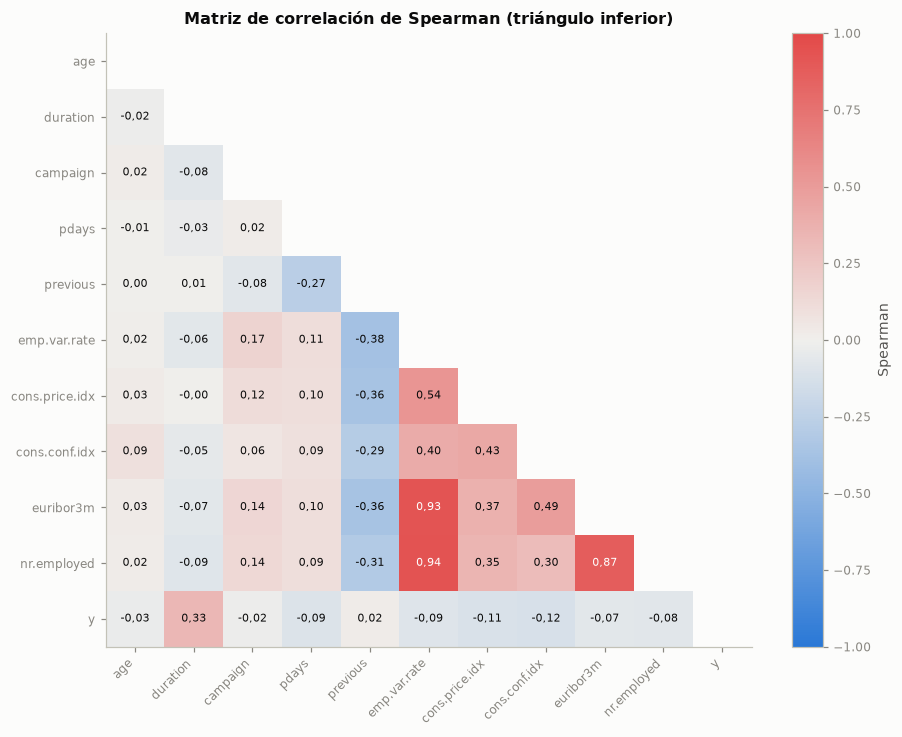

,VIF inicial,VIF tras la eliminación
age,"1,01","1,01"
campaign,"1,03","1,03"
cons.conf.idx,"6,76","1,47"
cons.price.idx,"6,03","1,83"
emp.var.rate,"45,36",—
euribor3m,"46,16",—
nr.employed,"37,03","2,26"
pdays,"1,09","1,09"
previous,"1,34","1,32"


Retiradas por VIF > 10 (en orden): ['euribor3m', 'emp.var.rate']


**Interpretación.** Las correlaciones más altas con `y` son las de `duration` (0,33), `cons.conf.idx` (-0,12) y `cons.price.idx` (-0,11). El VIF inicial es de 46,2 en `euribor3m`, 45,4 en `emp.var.rate`, 37,0 en `nr.employed`. La eliminación iterativa retira `euribor3m` y `emp.var.rate` y deja todos los VIF por debajo de 2,3.

Esto quiere decir que, con VIF tan altos, los coeficientes de las macro tendrían varianzas infladas y signos poco confiables; la información que se pierde al retirarlas es pequeña porque está contenida en las que quedan (por ejemplo, la correlación de Spearman entre `nr.employed` y `euribor3m` es 0,87).

Por tal motivo, se opta por excluir `euribor3m` y `emp.var.rate` del modelo base y verificar con validación cruzada que la pérdida de AUC sea despreciable (sección 3.7).

In [22]:
cols_corr = NUMERICAS + ["y"]
R = tr[cols_corr].corr(method="spearman")
R_inf = R.where(np.tril(np.ones(R.shape, dtype=bool), k=-1))
fig, ax = plt.subplots(figsize=(8.5, 6.8))
im = mapa_calor(ax, R_inf.to_numpy(), cols_corr, cols_corr, CMAP_DIV, -1, 1, dec=2)
fig.colorbar(im, ax=ax, label="Spearman")
ax.set_title("Matriz de correlación de Spearman (triángulo inferior)")
plt.tight_layout()
plt.show()

def vif_tabla(datos):
    Z = (datos - datos.mean()) / datos.std()
    Z = Z.assign(constante=1.0)
    return pd.Series([variance_inflation_factor(Z.to_numpy(), i) for i in range(Z.shape[1] - 1)],
                     index=datos.columns)

candidatas_vif = [c for c in NUMERICAS if c != "duration"]
base_vif = tr[candidatas_vif].astype(float).assign(pdays=(tr["pdays"] != 999).astype(float))
vif_inicial = vif_tabla(base_vif)
NUM_RETIRADAS_VIF, actuales = [], list(candidatas_vif)
while True:
    v = vif_tabla(base_vif[actuales])
    if v.max() <= 10:
        break
    NUM_RETIRADAS_VIF.append(v.idxmax())
    actuales.remove(v.idxmax())
vif_final = vif_tabla(base_vif[actuales])
tabla(pd.DataFrame({"VIF inicial": vif_inicial, "VIF tras la eliminación": vif_final}), dec=2)
print("Retiradas por VIF > 10 (en orden):", NUM_RETIRADAS_VIF)

r_y = R["y"].drop("y").sort_values(key=np.abs, ascending=False)
interpretar(
    f"Las correlaciones más altas con `y` son las de `{r_y.index[0]}` ({num(r_y.iloc[0], 2)}), `{r_y.index[1]}` "
    f"({num(r_y.iloc[1], 2)}) y `{r_y.index[2]}` ({num(r_y.iloc[2], 2)}). El VIF inicial es de "
    + ", ".join(f"{num(vif_inicial[c], 1)} en `{c}`" for c in vif_inicial.sort_values(ascending=False).index[:3])
    + f". La eliminación iterativa retira {enumerar(NUM_RETIRADAS_VIF)} y deja todos los VIF por "
    f"debajo de {num(vif_final.max(), 1)}.",
    "Esto quiere decir que, con VIF tan altos, los coeficientes de las macro tendrían varianzas infladas y signos poco "
    "confiables; la información que se pierde al retirarlas es pequeña porque está contenida en las que quedan (por "
    "ejemplo, la correlación de Spearman entre `nr.employed` y `euribor3m` es "
    f"{num(R.loc['nr.employed', 'euribor3m'], 2)}).",
    f"Por tal motivo, se opta por excluir {enumerar(NUM_RETIRADAS_VIF)} del modelo base y verificar con validación "
    "cruzada que la pérdida de AUC sea despreciable (sección 3.7).")

#### 3.3.6 Selección preliminar de variables

La tabla resume la decisión para cada predictora con su evidencia. La decisión definitiva sobre `duration` y sobre las variables en observación se toma en la auditoría de fuga (sección 3.5).

In [23]:
seleccion = []
for c in NUMERICAS + CATEGORICAS:
    efecto = asoc.loc[c, "Efecto"]
    if c == "duration":
        dec, motivo = "Excluir", "Fuga: solo se conoce al terminar la llamada (sección 3.5)"
    elif c in NUM_RETIRADAS_VIF:
        dec, motivo = "Excluir", f"Redundante: VIF inicial {num(vif_inicial[c], 1)} (sección 3.3.5)"
    elif c in MACRO or c in ("month", "campaign"):
        dec, motivo = "Conservar, en observación", "Asociada con y, pero marca el periodo o depende del proceso de la campaña (sección 3.5)"
    else:
        dec, motivo = "Conservar", f"Asociación {magnitud(efecto, (0.1, 0.3, 0.5), ('despreciable', 'pequeña', 'mediana', 'grande'))} con y"
    seleccion.append({"Variable": c, "Medida de efecto": asoc.loc[c, "Medida de efecto"], "Efecto": efecto,
                      "Rango IM": asoc.loc[c, "Rango IM"], "Decisión preliminar": dec, "Motivo": motivo})
seleccion = pd.DataFrame(seleccion).set_index("Variable").sort_values("Rango IM")
tabla(seleccion, dec=3)

conservadas = seleccion.index[seleccion["Decisión preliminar"].str.startswith("Conservar")].tolist()
debiles = [c for c in conservadas if abs(seleccion.loc[c, "Efecto"]) < 0.1]
interpretar(
    f"Se conservan {len(conservadas)} de las {len(seleccion)} predictoras y se excluyen "
    f"{len(seleccion) - len(conservadas)} (`duration` por fuga y {enumerar(NUM_RETIRADAS_VIF)} por redundancia). Las "
    f"conservadas con efecto marginal despreciable (menor que 0,1) son {enumerar(debiles)}.",
    "Así mismo, las variables débiles se mantienen porque la regularización del modelo controla su aporte y porque un "
    "efecto marginal pequeño puede ser útil en combinación con otras; descartarlas aquí sería una selección "
    "prematura.",
    "En consecuencia, se procede a llevar al modelo base las predictoras conservadas, con la auditoría de fuga como "
    "filtro final.")

,Medida de efecto,Efecto,Rango IM,Decisión preliminar,Motivo
Variable,,,,,
duration,r biserial de rangos,"0,777",1,Excluir,Fuga: solo se conoce al terminar la llamada (sección 3.5)
euribor3m,r biserial de rangos,"-0,160",2,Excluir,"Redundante: VIF inicial 46,2 (sección 3.3.5)"
cons.conf.idx,r biserial de rangos,"-0,274",3,"Conservar, en observación","Asociada con y, pero marca el periodo o depende del proceso de la campaña (sección 3.5)"
cons.price.idx,r biserial de rangos,"-0,266",4,"Conservar, en observación","Asociada con y, pero marca el periodo o depende del proceso de la campaña (sección 3.5)"
month,V de Cramér,"0,230",5,"Conservar, en observación","Asociada con y, pero marca el periodo o depende del proceso de la campaña (sección 3.5)"
emp.var.rate,r biserial de rangos,"-0,196",6,Excluir,"Redundante: VIF inicial 45,4 (sección 3.3.5)"
nr.employed,r biserial de rangos,"-0,168",7,"Conservar, en observación","Asociada con y, pero marca el periodo o depende del proceso de la campaña (sección 3.5)"
pdays,r biserial de rangos,"-0,028",8,Conservar,Asociación despreciable con y
age,r biserial de rangos,"-0,059",9,Conservar,Asociación despreciable con y


**Interpretación.** Se conservan 17 de las 20 predictoras y se excluyen 3 (`duration` por fuga y `euribor3m` y `emp.var.rate` por redundancia). Las conservadas con efecto marginal despreciable (menor que 0,1) son `pdays`, `age`, `contact`, `poutcome`, `campaign`, `job`, `previous`, `default`, `marital`, `education`, `day_of_week`, `housing` y `loan`.

Así mismo, las variables débiles se mantienen porque la regularización del modelo controla su aporte y porque un efecto marginal pequeño puede ser útil en combinación con otras; descartarlas aquí sería una selección prematura.

En consecuencia, se procede a llevar al modelo base las predictoras conservadas, con la auditoría de fuga como filtro final.

### 3.4 Análisis multivariado (enunciado, sección 2.4)

Se usa una matriz numérica estandarizada con las candidatas a predictoras: `age`, `log1p(campaign)`, `log1p(previous)`, un indicador de contacto previo (`pdays ≠ 999`) y los cinco indicadores macroeconómicos. Se incluyen todas las macro para ver la redundancia que detectó el VIF.

#### 3.4.1 Reducción de dimensionalidad (PCA)

,CP1,CP2,CP3
age,"0,021","0,268","0,950"
log1p(campaign),"0,091","0,083","0,097"
log1p(previous),"-0,265","0,466","-0,102"
contacto_previo,"-0,100","0,814","-0,247"
emp.var.rate,"0,474","0,094","-0,048"
cons.price.idx,"0,382","0,058","-0,090"
cons.conf.idx,"0,348","0,093","0,052"
euribor3m,"0,471","0,101","-0,040"
nr.employed,"0,445","0,101","-0,050"


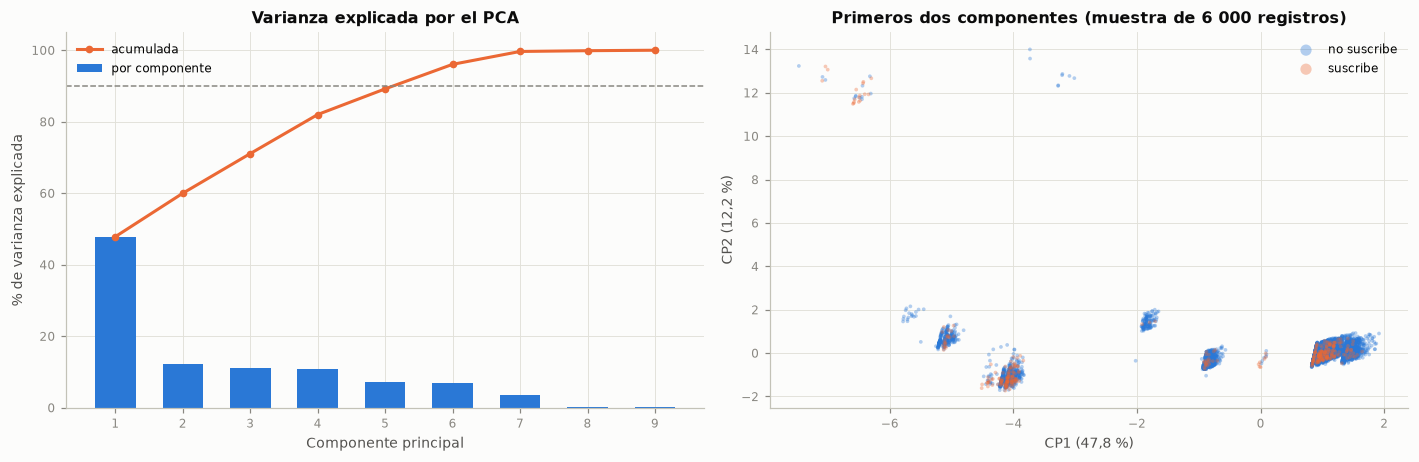

**Interpretación.** El primer componente explica el 47,8 % de la varianza y está dominado por `emp.var.rate`, `euribor3m`, `nr.employed` y `cons.price.idx`: es el eje del ciclo económico del periodo. El segundo (12,2 %) lo forman sobre todo `contacto_previo`, `log1p(previous)` y `age`. Se necesitan 4, 6 y 6 componentes para el 80 %, 90 % y 95 % de la varianza, de 9 variables. La media del CP1 es -1,12 entre quienes suscriben y 0,08 entre quienes no, pero en el plano CP1–CP2 las clases se superponen mucho.

Lo anterior indica que la dimensionalidad efectiva es menor que el número de variables por la redundancia de las macro, lo que respalda la eliminación por VIF. La superposición de clases anticipa que ninguna frontera lineal las separará bien: el techo de desempeño de un modelo lineal es moderado.

Por esta razón, se decide no usar el PCA como entrada del modelo base (perdería interpretabilidad sin ganar información) y mantener la selección por VIF.

In [24]:
M = pd.DataFrame({"age": tr["age"], "log1p(campaign)": np.log1p(tr["campaign"]),
                  "log1p(previous)": np.log1p(tr["previous"]), "contacto_previo": (tr["pdays"] != 999).astype(int)}
                 ).join(tr[MACRO])
Zm = StandardScaler().fit_transform(M)
pca = PCA(random_state=SEED).fit(Zm)
var_exp = pca.explained_variance_ratio_
acum = np.cumsum(var_exp)
k80, k90, k95 = (int(np.searchsorted(acum, u) + 1) for u in (0.80, 0.90, 0.95))

cargas = pd.DataFrame(pca.components_[:3].T, index=M.columns, columns=["CP1", "CP2", "CP3"])
tabla(cargas, dec=3)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.3))
k = np.arange(1, len(var_exp) + 1)
axs[0].bar(k, 100 * var_exp, color=AZUL, width=0.6, label="por componente")
axs[0].plot(k, 100 * acum, color=NARANJA, marker="o", ms=4, label="acumulada")
axs[0].axhline(90, color=GRIS, ls="--", lw=1)
axs[0].set_xticks(k)
axs[0].set_xlabel("Componente principal")
axs[0].set_ylabel("% de varianza explicada")
axs[0].set_title("Varianza explicada por el PCA")
axs[0].legend()
rng = np.random.default_rng(SEED)
muestra = rng.choice(len(Zm), size=6000, replace=False)
P = pca.transform(Zm[muestra])[:, :2]
ym = tr["y"].to_numpy()[muestra]
for clase in (0, 1):
    axs[1].scatter(P[ym == clase, 0], P[ym == clase, 1], s=6, alpha=0.35, color=COLOR_Y[clase],
                   label=ETIQUETA_Y[clase], edgecolors="none")
axs[1].set_xlabel(f"CP1 ({num(100 * var_exp[0], 1)} %)")
axs[1].set_ylabel(f"CP2 ({num(100 * var_exp[1], 1)} %)")
axs[1].set_title("Primeros dos componentes (muestra de 6 000 registros)")
axs[1].legend(markerscale=3)
plt.tight_layout()
plt.show()

cp1_top = cargas["CP1"].abs().sort_values(ascending=False).index[:4].tolist()
cp1_clase = pd.Series(pca.transform(Zm)[:, 0]).groupby(tr["y"].to_numpy()).mean()
cp2_top = cargas["CP2"].abs().sort_values(ascending=False).index[:3].tolist()
interpretar(
    f"El primer componente explica el {pct(var_exp[0])} de la varianza y está dominado por "
    f"{enumerar(cp1_top)}"
    + (": es el eje del ciclo económico del periodo. " if sum(c in MACRO for c in cp1_top) >= 3 else ". ")
    + f"El segundo "
    f"({pct(var_exp[1])}) lo forman sobre todo {enumerar(cp2_top)}. Se necesitan {k80}, {k90} y "
    f"{k95} componentes para el 80 %, 90 % y 95 % de la varianza, de {M.shape[1]} variables. La media del CP1 es "
    f"{num(cp1_clase[1], 2)} entre quienes suscriben y {num(cp1_clase[0], 2)} entre quienes no, pero en el plano "
    "CP1–CP2 las clases se superponen mucho.",
    "Lo anterior indica que la dimensionalidad efectiva es menor que el número de variables por la redundancia de las "
    "macro, lo que respalda la eliminación por VIF. La superposición de clases anticipa que ninguna frontera lineal "
    "las separará bien: el techo de desempeño de un modelo lineal es moderado.",
    "Por esta razón, se decide no usar el PCA como entrada del modelo base (perdería interpretabilidad sin ganar "
    "información) y mantener la selección por VIF.")

#### 3.4.2 Atípicos multivariados (Mahalanobis e Isolation Forest)

La distancia de Mahalanobis al cuadrado se compara con el cuantil 0,999 de una χ² con tantos grados de libertad como variables (la referencia es aproximada, porque las variables no son normales). Isolation Forest (`random_state = SEED`, 300 árboles, contaminación automática) no supone ninguna distribución.

,Registros,% del entrenamiento,% que suscribe (atípicos),% que suscribe (resto),% con contacto previo (atípicos)
"Mahalanobis (χ² 0,999)",430,"1,31","32,33","6,03","40,47"
Isolation Forest,13 021,"39,53","8,85","4,75","1,34"
Ambos métodos,430,"1,31","32,33","6,03","40,47"


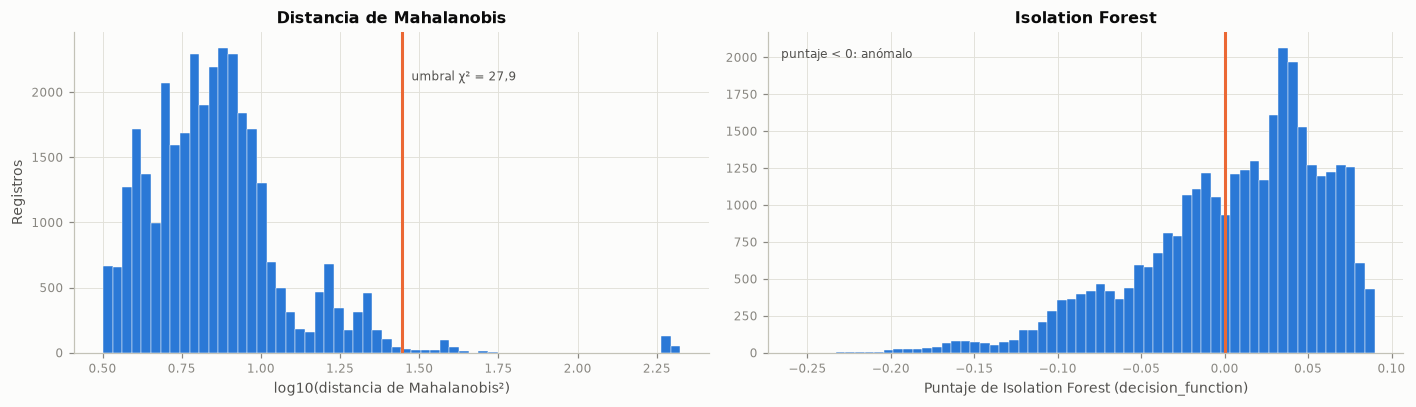

**Interpretación.** Mahalanobis marca 430 registros (1,3 %) e Isolation Forest 13 021 (39,5 %); coinciden 430 (Jaccard = 0,03). Entre los atípicos de Mahalanobis suscribe el 32,3 % frente al 6,0 % del resto, y el 40,5 % tuvo contacto previo.

En ese sentido, los atípicos multivariados corresponden a combinaciones poco frecuentes de valores plausibles, no a errores. Eliminarlos quitaría información valiosa de la clase minoritaria.

Por lo anterior, conviene no eliminar atípicos multivariados y mantener la transformación `log1p` y el escalado para limitar su palanca.

In [25]:
cov_inv = np.linalg.pinv(np.cov(Zm, rowvar=False))
d2 = np.einsum("ij,jk,ik->i", Zm, cov_inv, Zm)
umbral_d2 = stats.chi2.ppf(0.999, df=Zm.shape[1])
atip_maha = d2 > umbral_d2
iso = IsolationForest(n_estimators=300, contamination="auto", random_state=SEED).fit(Zm)
puntaje_iso = iso.decision_function(Zm)
atip_iso = puntaje_iso < 0
ambos = atip_maha & atip_iso
yy = tr["y"].to_numpy()
atipicos_mv = pd.DataFrame({
    "Registros": [int(atip_maha.sum()), int(atip_iso.sum()), int(ambos.sum())],
    "% del entrenamiento": [100 * atip_maha.mean(), 100 * atip_iso.mean(), 100 * ambos.mean()],
    "% que suscribe (atípicos)": [100 * yy[atip_maha].mean(), 100 * yy[atip_iso].mean(), 100 * yy[ambos].mean()],
    "% que suscribe (resto)": [100 * yy[~atip_maha].mean(), 100 * yy[~atip_iso].mean(), 100 * yy[~ambos].mean()],
    "% con contacto previo (atípicos)": [100 * M["contacto_previo"][atip_maha].mean(),
                                         100 * M["contacto_previo"][atip_iso].mean(),
                                         100 * M["contacto_previo"][ambos].mean()]},
    index=["Mahalanobis (χ² 0,999)", "Isolation Forest", "Ambos métodos"])
tabla(atipicos_mv, dec=2)
jaccard = ambos.sum() / (atip_maha | atip_iso).sum()

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
axs[0].hist(np.log10(d2 + 1e-9), bins=60, color=AZUL, edgecolor=FONDO, linewidth=0.3)
axs[0].axvline(np.log10(umbral_d2), color=NARANJA, lw=2)
axs[0].text(np.log10(umbral_d2) + 0.03, axs[0].get_ylim()[1] * 0.85, f"umbral χ² = {num(umbral_d2, 1)}",
            color=TINTA_2, fontsize=8)
axs[0].set_xlabel("log10(distancia de Mahalanobis²)")
axs[0].set_ylabel("Registros")
axs[0].set_title("Distancia de Mahalanobis")
axs[1].hist(puntaje_iso, bins=60, color=AZUL, edgecolor=FONDO, linewidth=0.3)
axs[1].axvline(0, color=NARANJA, lw=2)
axs[1].text(0.02, 0.92, "puntaje < 0: anómalo", transform=axs[1].transAxes, color=TINTA_2, fontsize=8)
axs[1].set_xlabel("Puntaje de Isolation Forest (decision_function)")
axs[1].set_title("Isolation Forest")
plt.tight_layout()
plt.show()

interpretar(
    f"Mahalanobis marca {num(int(atip_maha.sum()))} registros ({pct(atip_maha.mean())}) e Isolation Forest "
    f"{num(int(atip_iso.sum()))} ({pct(atip_iso.mean())}); coinciden {num(int(ambos.sum()))} (Jaccard = "
    f"{num(jaccard, 2)}). Entre los atípicos de Mahalanobis suscribe el "
    f"{num(atipicos_mv.iloc[0]['% que suscribe (atípicos)'], 1)} % frente al "
    f"{num(atipicos_mv.iloc[0]['% que suscribe (resto)'], 1)} % del resto, y el "
    f"{num(atipicos_mv.iloc[0]['% con contacto previo (atípicos)'], 1)} % tuvo contacto previo.",
    ("En ese sentido, los atípicos multivariados no son errores: son sobre todo clientes con historial de campañas y "
     "contextos económicos poco frecuentes, justamente donde la tasa de suscripción es distinta. "
     if atipicos_mv.iloc[0]["% con contacto previo (atípicos)"] > 50 else
     "En ese sentido, los atípicos multivariados corresponden a combinaciones poco frecuentes de valores plausibles, "
     "no a errores. ")
    + ("Eliminarlos quitaría información valiosa de la clase minoritaria."
       if atipicos_mv.iloc[0]["% que suscribe (atípicos)"] > atipicos_mv.iloc[0]["% que suscribe (resto)"]
       else "Su tasa de suscripción no es mayor que la del resto, pero tampoco hay razón para eliminarlos."),
    "Por lo anterior, conviene no eliminar atípicos multivariados y mantener la transformación `log1p` y el escalado "
    "para limitar su palanca.")

#### 3.4.3 Estructura de grupos (clustering exploratorio)

Se explora si existen subpoblaciones con K-medias (`random_state = SEED`, 10 inicializaciones) sobre la misma matriz estandarizada, eligiendo *k* entre 2 y 6 con el coeficiente de silueta calculado en una muestra de 5 000 registros.

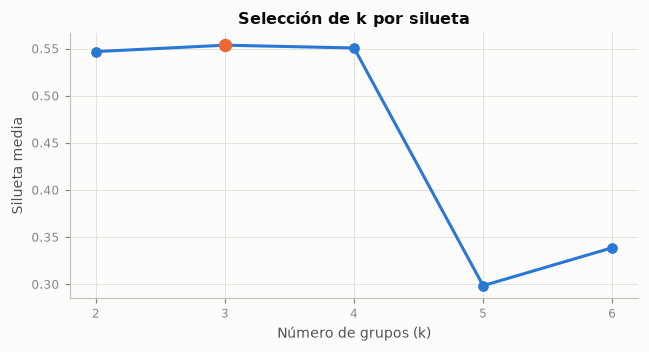

,registros,% que suscribe,Edad media,Euribor media,% con contacto previo,% de 2008,% del total
cluster,,,,,,,
0,27 637,"4,83","40,19","4,82","0,00","100,00","83,90"
1,174,"37,93","41,17","1,92","100,00","20,11","0,53"
2,5 129,"13,63","39,10","1,39","0,00","0,19","15,57"


**Interpretación.** La silueta es máxima con k = 3 (0,554). Los perfiles son: grupo 0: 83,9 % de los registros, Euribor media de 4,82 %, 100,0 % de 2008, 0,0 % con contacto previo y 4,8 % que suscribe; grupo 1: 0,5 % de los registros, Euribor media de 1,92 %, 20,1 % de 2008, 100,0 % con contacto previo y 37,9 % que suscribe; grupo 2: 15,6 % de los registros, Euribor media de 1,39 %, 0,2 % de 2008, 0,0 % con contacto previo y 13,6 % que suscribe. La edad media apenas cambia entre grupos (de 39,1 a 41,2 años).

Entonces, las subpoblaciones no son perfiles sociodemográficos sino combinaciones de **régimen económico** (antes y después de la caída de la Euribor) e **historial de contacto**, con tasas de éxito muy distintas. Esto refuerza que el periodo y el historial son los principales factores de variación y que un modelo evaluado al azar puede apoyarse en el periodo.

Así las cosas, se decide no crear variables de grupo para el modelo base (repetirían la información del periodo) y verificar la fuga temporal en la sección 3.6.

In [26]:
siluetas = {}
for k_ in range(2, 7):
    km = KMeans(n_clusters=k_, n_init=10, random_state=SEED).fit(Zm)
    siluetas[k_] = silhouette_score(Zm, km.labels_, sample_size=5000, random_state=SEED)
k_opt = max(siluetas, key=siluetas.get)
km = KMeans(n_clusters=k_opt, n_init=10, random_state=SEED).fit(Zm)
perfil = (pd.DataFrame({"cluster": km.labels_, "y": yy, "age": tr["age"].to_numpy(),
                        "euribor3m": tr["euribor3m"].to_numpy(), "contacto_previo": M["contacto_previo"].to_numpy(),
                        "anio_2008": (anio_tr.to_numpy() == 2008).astype(int)})
          .groupby("cluster").agg(registros=("y", "size"), suscribe=("y", "mean"), edad_media=("age", "mean"),
                                  euribor_media=("euribor3m", "mean"), contacto_previo=("contacto_previo", "mean"),
                                  de_2008=("anio_2008", "mean")))
perfil["% del total"] = 100 * perfil["registros"] / len(tr)
for c in ["suscribe", "contacto_previo", "de_2008"]:
    perfil[c] = 100 * perfil[c]
perfil = perfil.rename(columns={"suscribe": "% que suscribe", "contacto_previo": "% con contacto previo",
                                "de_2008": "% de 2008", "edad_media": "Edad media", "euribor_media": "Euribor media"})

fig, ax = plt.subplots(figsize=(6, 3.3))
ax.plot(list(siluetas), list(siluetas.values()), color=AZUL, marker="o")
ax.scatter([k_opt], [siluetas[k_opt]], color=NARANJA, s=60, zorder=3)
ax.set_xticks(list(siluetas))
ax.set_xlabel("Número de grupos (k)")
ax.set_ylabel("Silueta media")
ax.set_title("Selección de k por silueta")
plt.tight_layout()
plt.show()
tabla(perfil, dec=2)

descr_grupos = "; ".join(
    f"grupo {g}: {num(r['% del total'], 1)} % de los registros, Euribor media de {num(r['Euribor media'], 2)} %, "
    f"{num(r['% de 2008'], 1)} % de 2008, {num(r['% con contacto previo'], 1)} % con contacto previo y "
    f"{num(r['% que suscribe'], 1)} % que suscribe" for g, r in perfil.iterrows())
interpretar(
    f"La silueta es máxima con k = {k_opt} ({num(siluetas[k_opt], 3)}). Los perfiles son: {descr_grupos}. La edad "
    f"media apenas cambia entre grupos (de {num(perfil['Edad media'].min(), 1)} a {num(perfil['Edad media'].max(), 1)} años).",
    "Entonces, las subpoblaciones no son perfiles sociodemográficos sino combinaciones de **régimen económico** (antes "
    "y después de la caída de la Euribor) e **historial de contacto**, con tasas de éxito muy distintas. Esto refuerza "
    "que el periodo y el historial son los principales factores de variación y que un modelo evaluado al azar puede "
    "apoyarse en el periodo.",
    "Así las cosas, se decide no crear variables de grupo para el modelo base (repetirían la información del periodo) "
    "y verificar la fuga temporal en la sección 3.6.")

### 3.5 Auditoría de fuga de datos (enunciado, sección 2.5)

#### 3.5.1 Disponibilidad de cada variable en el momento de la predicción

El momento de predicción es **antes de realizar la llamada** de la campaña actual. No hay identificadores ni variables derivadas de forma explícita de la variable objetivo.

| Variable | ¿Disponible antes de la llamada? | Justificación | Decisión |
|---|---|---|---|
| `age`, `job`, `marital`, `education` | Sí | Atributos del cliente registrados en el banco | Usar |
| `default`, `housing`, `loan` | Sí | Situación crediticia registrada en el banco | Usar |
| `contact` | Sí | Canal por el que se hará la llamada | Usar |
| `month`, `day_of_week` | Sí | Fecha programada de la llamada (sin año) | Usar, en observación: `month` marca el periodo |
| `duration` | **No** | Solo se conoce al terminar la llamada; si vale 0, `y = no` (sección 1.6.4) | **Descartar** |
| `campaign` | Parcial | Cuenta los contactos de la campaña incluido el actual, así que se conoce antes de cada llamada; pero es razonable suponer que la campaña deja de llamar a quien ya suscribió, de modo que su valor puede depender del resultado | Usar, en observación |
| `pdays`, `previous`, `poutcome` | Sí | Historial de campañas anteriores | Usar |
| Indicadores macroeconómicos | Parcial | Son públicos, pero los trimestrales y mensuales se publican con rezago: el valor del periodo en curso podría no conocerse el día de la llamada | Usar las que deja el VIF, en observación (fuga temporal, sección 3.6) |

#### 3.5.2 Desempeño univariado de cada variable

Para cada predictora se ajusta una regresión logística con esa sola variable (codificación *one-hot* si es categórica) y se calcula el AUC promedio de los cinco pliegues de la **validación temporal** (sección 3). Un AUC cercano a 1 sería una alerta de fuga o de variable sustituta del objetivo.

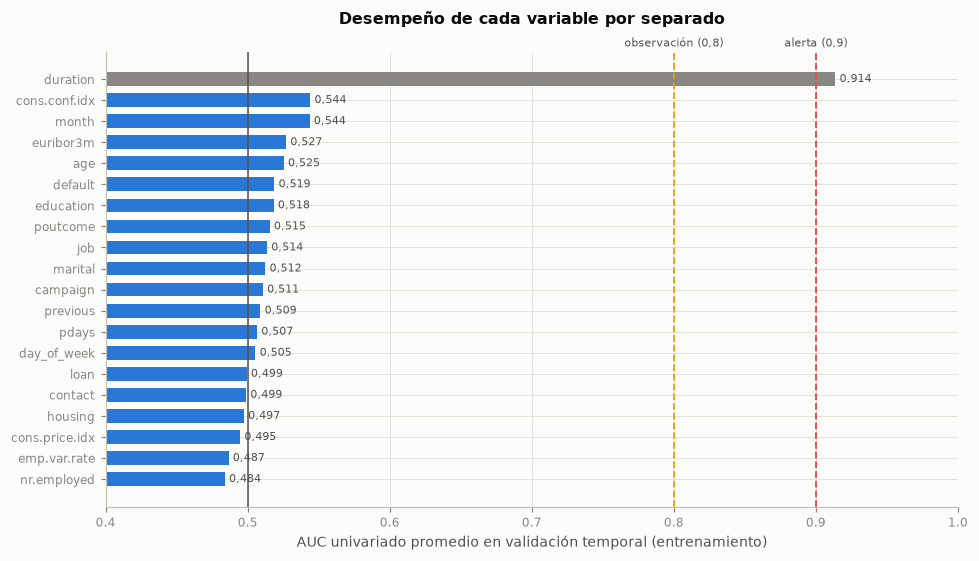

**Interpretación.** `duration` alcanza el umbral de alerta de 0,9. La de mayor AUC es `duration` (0,914); sin ella, la mejor es `cons.conf.idx` (0,544), seguida de `month` (0,544) y `euribor3m` (0,527). 19 de las 19 predictoras sin `duration` quedan por debajo de 0,55.

De esta forma, el AUC univariado de `duration` supera el umbral de alerta, lo que confirma su fuga. La fuga se identifica por la disponibilidad (sección 3.5.1) y por la ganancia que produce dentro del modelo completo (sección 3.5.3). Con validación temporal, la mayoría de las predictoras ordena a los clientes del periodo siguiente apenas mejor que el azar: su relación con `y` no se sostiene bien de un periodo a otro.

Por ello, se procede a descartar `duration` y mantener en observación las macro, `month` y `campaign`.

In [27]:
def pipeline_auditoria(numericas, categoricas, C=1.0):
    """Instrumento de auditoría: escalado + one-hot + regresión logística (no es el modelo final)."""
    pre = ColumnTransformer([("num", StandardScaler(), numericas),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)])
    return Pipeline([("pre", pre), ("lr", LogisticRegression(C=C, max_iter=5000))])


auc_uni = {}
for c in NUMERICAS + CATEGORICAS:
    p_uni = pipeline_auditoria([c] if c in NUMERICAS else [], [c] if c in CATEGORICAS else [])
    auc_uni[c] = cross_validate(p_uni, X_tr[[c]], y_tr, cv=tss, scoring="roc_auc")["test_score"].mean()
auc_uni = pd.Series(auc_uni).sort_values()

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(auc_uni.index, auc_uni.values, color=[GRIS if c == "duration" else AZUL for c in auc_uni.index], height=0.65)
ax.axvline(0.5, color=TINTA_2, lw=1)
ax.axvline(0.8, color=AMARILLO, ls="--", lw=1.2)
ax.axvline(0.9, color=ROJO, ls="--", lw=1.2)
ax.text(0.8, 1.005, "observación (0,8)", transform=ax.get_xaxis_transform(), ha="center", va="bottom",
        fontsize=7.5, color=TINTA_2)
ax.text(0.9, 1.005, "alerta (0,9)", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=7.5,
        color=TINTA_2)
ax.set_xlim(min(0.4, auc_uni.min() - 0.03), 1.0)
ax.set_xlabel("AUC univariado promedio en validación temporal (entrenamiento)")
ax.set_title("Desempeño de cada variable por separado", pad=18)
for i, v in enumerate(auc_uni.values):
    ax.text(v + 0.003, i, num(v, 3), va="center", fontsize=7.5, color=TINTA_2)
plt.tight_layout()
plt.show()

sin_dur = auc_uni.drop("duration")
alertas = auc_uni.index[auc_uni >= 0.9].tolist()
cerca_azar = sin_dur.index[sin_dur < 0.55].tolist()
interpretar(
    (f"{enumerar(alertas)} alcanza el umbral de alerta de 0,9. " if alertas else
     "Ninguna variable alcanza el umbral de alerta de 0,9. ")
    + f"La de mayor AUC es `{auc_uni.index[-1]}` ({num(auc_uni.iloc[-1], 3)}); sin ella, la mejor es "
    f"`{sin_dur.index[-1]}` ({num(sin_dur.iloc[-1], 3)}), seguida de `{sin_dur.index[-2]}` ({num(sin_dur.iloc[-2], 3)}) y "
    f"`{sin_dur.index[-3]}` ({num(sin_dur.iloc[-3], 3)}). {len(cerca_azar)} de las {len(sin_dur)} predictoras sin "
    "`duration` quedan por debajo de 0,55.",
    ("De esta forma, el AUC univariado por sí solo no detecta la fuga de `duration`: su valor es alto pero no extremo. "
     if auc_uni["duration"] < 0.9 else
     "De esta forma, el AUC univariado de `duration` supera el umbral de alerta, lo que confirma su fuga. ")
    + "La fuga se identifica por la disponibilidad (sección 3.5.1) y por la ganancia que produce dentro del modelo "
    "completo (sección 3.5.3). Con validación temporal, la mayoría de las predictoras ordena a los clientes del "
    "periodo siguiente apenas mejor que el azar: su relación con `y` no se sostiene bien de un periodo a otro.",
    "Por ello, se procede a descartar `duration` y mantener en observación las macro, `month` y `campaign`.")

#### 3.5.3 Efecto de `duration` en el modelo completo

Se compara el AUC de la validación temporal (sección 3, solo entrenamiento) del instrumento de auditoría con todas las predictoras salvo `duration` y con `duration` incluida.

In [28]:
num_sin_dur = [c for c in NUMERICAS if c != "duration"]
cv_sin = cross_validate(pipeline_auditoria(num_sin_dur, CATEGORICAS), X_tr, y_tr, cv=tss,
                        scoring=["roc_auc", "average_precision"])
cv_con = cross_validate(pipeline_auditoria(NUMERICAS, CATEGORICAS), X_tr, y_tr, cv=tss,
                        scoring=["roc_auc", "average_precision"])
efecto_dur = pd.DataFrame({
    "AUC media": [cv_sin["test_roc_auc"].mean(), cv_con["test_roc_auc"].mean()],
    "AUC desv. est.": [cv_sin["test_roc_auc"].std(), cv_con["test_roc_auc"].std()],
    "AUC-PR media": [cv_sin["test_average_precision"].mean(), cv_con["test_average_precision"].mean()]},
    index=["Sin duration", "Con duration"])
tabla(efecto_dur, dec=3)
auc_sin_dur, auc_con_dur = efecto_dur["AUC media"]
interpretar(
    f"Agregar `duration` sube el AUC de validación de {num(auc_sin_dur, 3)} a {num(auc_con_dur, 3)} y el AUC-PR de "
    f"{num(efecto_dur.iloc[0, 2], 3)} a {num(efecto_dur.iloc[1, 2], 3)}.",
    "Sin embargo, ese salto no es capacidad predictiva utilizable: proviene de una variable que se conoce cuando la "
    "llamada ya terminó y, por tanto, cuando el resultado ya se sabe. Un modelo con `duration` sería inútil para "
    "decidir a quién llamar y su desempeño reportado sería engañoso.",
    "En consecuencia, se excluye `duration` de forma definitiva; el AUC sin ella es la referencia honesta para el "
    "modelo base.")

,AUC media,AUC desv. est.,AUC-PR media
Sin duration,"0,540","0,073","0,087"
Con duration,"0,856","0,084","0,401"


**Interpretación.** Agregar `duration` sube el AUC de validación de 0,540 a 0,856 y el AUC-PR de 0,087 a 0,401.

Sin embargo, ese salto no es capacidad predictiva utilizable: proviene de una variable que se conoce cuando la llamada ya terminó y, por tanto, cuando el resultado ya se sabe. Un modelo con `duration` sería inútil para decidir a quién llamar y su desempeño reportado sería engañoso.

En consecuencia, se excluye `duration` de forma definitiva; el AUC sin ella es la referencia honesta para el modelo base.

#### 3.5.4 Duplicados y entidades repetidas entre entrenamiento y prueba

Se verifica si hay registros de prueba cuyo vector de predictoras aparece también en entrenamiento: con las 20 predictoras (incluida `duration`) y con las 19 que usaría un modelo sin `duration`. No es posible verificar clientes repetidos porque no hay identificador (sección 1.5).

In [29]:
def huella(datos, columnas):
    return pd.util.hash_pandas_object(datos[columnas], index=False)


h_tr20, h_te20 = huella(X_tr, NUMERICAS + CATEGORICAS), huella(X_te, NUMERICAS + CATEGORICAS)
h_tr19, h_te19 = huella(X_tr, PRED_SIN_DUR), huella(X_te, PRED_SIN_DUR)
rep20 = h_te20.isin(set(h_tr20)).to_numpy()
rep19 = h_te19.isin(set(h_tr19)).to_numpy()
# Concordancia de la etiqueta: y de prueba frente a la y mayoritaria del mismo perfil en entrenamiento
y_perfil_tr = pd.Series(y_tr.to_numpy(), index=h_tr19.to_numpy()).groupby(level=0).mean()
y_perfil = h_te19[rep19].map(y_perfil_tr).to_numpy()
concord = ((y_perfil >= 0.5).astype(int) == y_te.to_numpy()[rep19]).mean()
concord_mayoritaria = 1 - y_te.to_numpy()[rep19].mean()
en_corte = (periodo_te.to_numpy()[rep19] == periodo_corte).mean() if rep19.any() else 0.0
cruce = pd.DataFrame({
    "Registros de prueba": [int(rep20.sum()), int(rep19.sum())],
    "% de prueba": [100 * rep20.mean(), 100 * rep19.mean()]},
    index=["Vector de 20 predictoras (con duration) presente en entrenamiento",
           "Vector de 19 predictoras (sin duration) presente en entrenamiento"])
tabla(cruce, dec=2)
print(f"En los perfiles repetidos sin duration, la etiqueta de prueba coincide con la mayoritaria del perfil en "
      f"entrenamiento en el {pct(concord)} de los casos (tasa de positivos en esos registros: "
      f"{pct(y_te.to_numpy()[rep19].mean())}).")

interpretar(
    f"Tras eliminar los duplicados exactos, {int(rep20.sum())} registros de prueba repiten el vector completo de "
    f"entrenamiento. Sin `duration`, {num(int(rep19.sum()))} registros de prueba ({pct(rep19.mean(), 2)}) comparten "
    f"perfil con alguno de entrenamiento, y su etiqueta coincide con la mayoritaria de ese perfil en el "
    f"{pct(concord)} de los casos. El {pct(en_corte)} de esos registros pertenece a {periodo_corte}, el mes en que "
    "cae el corte, porque solo ahí coinciden también los indicadores macroeconómicos.",
    ("Es decir, son tan pocos que no pueden inflar la evaluación: con la partición cronológica, los perfiles de prueba "
     "casi nunca coinciden con los de entrenamiento, porque los indicadores macroeconómicos cambian entre periodos."
     if rep19.sum() < 30 else
     "Es decir, los perfiles compartidos son combinaciones frecuentes de atributos gruesos en el mismo periodo (mismas "
     f"macro), no copias de un mismo contacto; su concordancia de etiqueta ({pct(concord)}) es "
     + ("similar a" if abs(concord - concord_mayoritaria) < 0.03 else ("mayor que" if concord > concord_mayoritaria else "menor que"))
     + f" la de predecir siempre la clase mayoritaria en esos registros ({pct(concord_mayoritaria)}) y representan solo "
     f"el {pct(rep19.mean(), 2)} de la prueba, así que no inflan la evaluación de forma apreciable."),
    "Por tanto, no hay fuga por duplicados que corregir; el riesgo relevante es el temporal, que se analiza a "
    "continuación.")

,Registros de prueba,% de prueba
Vector de 20 predictoras (con duration) presente en entrenamiento,0,"0,00"
Vector de 19 predictoras (sin duration) presente en entrenamiento,2,"0,02"


En los perfiles repetidos sin duration, la etiqueta de prueba coincide con la mayoritaria del perfil en entrenamiento en el 50,0 % de los casos (tasa de positivos en esos registros: 0,0 %).


**Interpretación.** Tras eliminar los duplicados exactos, 0 registros de prueba repiten el vector completo de entrenamiento. Sin `duration`, 2 registros de prueba (0,02 %) comparten perfil con alguno de entrenamiento, y su etiqueta coincide con la mayoritaria de ese perfil en el 50,0 % de los casos. El 100,0 % de esos registros pertenece a 2009-05, el mes en que cae el corte, porque solo ahí coinciden también los indicadores macroeconómicos.

Es decir, son tan pocos que no pueden inflar la evaluación: con la partición cronológica, los perfiles de prueba casi nunca coinciden con los de entrenamiento, porque los indicadores macroeconómicos cambian entre periodos.

Por tanto, no hay fuga por duplicados que corregir; el riesgo relevante es el temporal, que se analiza a continuación.

### 3.6 Componente temporal y verificación de fuga temporal (enunciado, secciones 2.5 y 2.6)

El archivo no trae fechas, pero el orden documentado de los registros permite reconstruir el año, el mes y el día de contacto (sección 1.5). Con esa variable temporal, y solo con el conjunto de entrenamiento, se cubren los puntos de la sección 2.6 del enunciado:

- **3.6.1** Contexto económico y deriva de las covariables entre periodos.
- **3.6.2** Fuga temporal: validación aleatoria frente a validación temporal y poder predictivo del periodo.
- **3.6.3** Validación de la variable temporal, serie diaria y semanal, medias y varianzas móviles y cambios de régimen.
- **3.6.4** Descomposición STL, estacionariedad (ADF y KPSS), dependencia temporal (ACF y PACF) y correlación cruzada con las macro.
- **3.6.5** Deriva de concepto: si la relación de cada predictora con la variable objetivo cambia entre años.

La serie mensual del entrenamiento es demasiado corta para una descomposición estacional, que exige al menos dos ciclos completos; por eso la descomposición y las pruebas usan la **serie diaria** de días de contacto. Estos resultados respaldan la partición cronológica (sección 2), la validación temporal (sección 3), la elección de la regularización (sección 4.1) y la recalibración del intercepto (sección 4.7.1).

#### 3.6.1 Contexto económico y deriva entre periodos

En la prueba, el 98,5 % de los registros tiene un valor de euribor3m por debajo del mínimo observado en el entrenamiento (1,30 %): la tasa se movió en un rango de 0,63 % a 1,30 %, mientras que en el entrenamiento estuvo entre 1,30 % y 5,04 %. Por eso el modelo entrenado no ve la mayor parte del régimen de prueba.

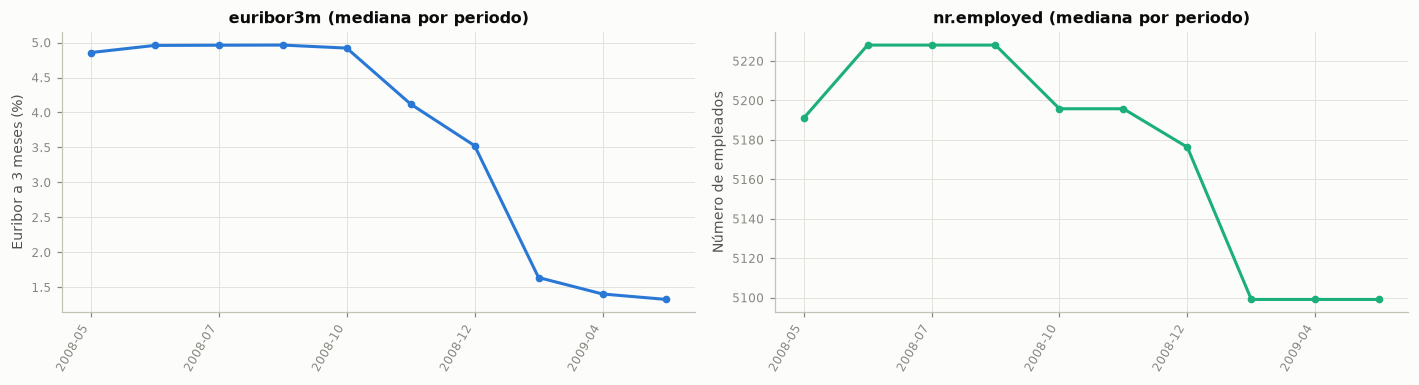

,Medida,Deriva,p (Holm)
Variable,,,
nr.employed,KS,"1,000","0,000"
cons.conf.idx,KS,"1,000","0,000"
emp.var.rate,KS,"1,000","0,000"
euribor3m,KS,"1,000","0,000"
cons.price.idx,KS,"1,000","0,000"
month,V de Cramér,"0,755","0,000"
poutcome,V de Cramér,"0,386","0,000"
contact,V de Cramér,"0,319","0,000"
previous,KS,"0,267","0,000"


**Interpretación.** La Euribor pasa de una mediana de 4,86 % en 2008-05 a 1,33 % en 2009-05. Entre 2008 y el tramo de 2009 incluido en entrenamiento (2009-03 a 2009-05) la mayor deriva está en `nr.employed` (KS = 1,00), `cons.conf.idx` (KS = 1,00), `emp.var.rate` (KS = 1,00), `euribor3m` (KS = 1,00), y la tasa de suscripción pasa del 4,8 % al 14,5 %.

Lo anterior indica que hay deriva de covariables (*covariate shift*: cambian las macro, el canal y el historial) y deriva de la prevalencia (la tasa base se multiplica). Un modelo entrenado con un periodo y aplicado en otro enfrenta distribuciones distintas, y las macro le permiten reconocer el periodo cuando la validación es aleatoria.

De ahí que se proceda a cuantificar el poder predictivo del periodo y a comparar la validación aleatoria con la temporal.

In [30]:
macro_periodo = tr.groupby(periodo_tr)[["euribor3m", "nr.employed"]].median()
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, c, col in zip(axs, ["euribor3m", "nr.employed"], [AZUL, AGUAMARINA]):
    ax.plot(np.arange(len(macro_periodo)), macro_periodo[c], color=col, marker="o", ms=4)
    ax.set_xticks(np.arange(len(macro_periodo))[::2], macro_periodo.index[::2], rotation=60, ha="right")
    ax.set_title(f"{c} (mediana por periodo)")
axs[0].set_ylabel("Euribor a 3 meses (%)")
axs[1].set_ylabel("Número de empleados")
plt.tight_layout()
plt.show()

despues = anio_tr >= 2009
deriva = []
for c in num_sin_dur:
    ks = stats.ks_2samp(tr.loc[~despues, c], tr.loc[despues, c])
    deriva.append({"Variable": c, "Medida": "KS", "Deriva": ks.statistic, "p": ks.pvalue})
for c in CATEGORICAS:
    v, _, p = v_cramer(pd.crosstab(tr[c], despues))
    deriva.append({"Variable": c, "Medida": "V de Cramér", "Deriva": v, "p": p})
deriva = pd.DataFrame(deriva).set_index("Variable")
deriva["p (Holm)"] = multipletests(deriva["p"], method="holm")[1]
deriva = deriva.drop(columns="p").sort_values("Deriva", ascending=False)
tabla(deriva, dec=3)
tasa_08, tasa_0910 = tr.loc[~despues, "y"].mean(), tr.loc[despues, "y"].mean()
tramo_despues = f"{periodo_tr[despues].iloc[0]} a {periodo_tr[despues].iloc[-1]}"
top_deriva = ", ".join(f"`{c}` ({r.Medida} = {num(r.Deriva, 2)})" for c, r in deriva.head(4).iterrows())

interpretar(
    f"La Euribor pasa de una mediana de {num(macro_periodo['euribor3m'].iloc[0], 2)} % en {macro_periodo.index[0]} a "
    f"{num(macro_periodo['euribor3m'].iloc[-1], 2)} % en {macro_periodo.index[-1]}. Entre 2008 y el tramo de 2009 "
    f"incluido en entrenamiento ({tramo_despues}) la mayor deriva está en {top_deriva}, "
    f"y la tasa de suscripción pasa del {pct(tasa_08)} al {pct(tasa_0910)}.",
    "Lo anterior indica que hay deriva de covariables (*covariate shift*: cambian las macro, el canal y el historial) "
    "y deriva de la prevalencia (la tasa base se multiplica). Un modelo entrenado con un periodo y aplicado en otro "
    "enfrenta distribuciones distintas, y las macro le permiten reconocer el periodo cuando la validación es "
    "aleatoria.",
    "De ahí que se proceda a cuantificar el poder predictivo del periodo y a comparar la validación aleatoria con la "
    "temporal.")

#### 3.6.2 Validación aleatoria frente a validación temporal

Se comparan tres resultados con el instrumento de auditoría (todas las predictoras salvo `duration`):

1. **Validación estratificada aleatoria** (cinco pliegues, `SEED`): el contraste, es decir, lo que se habría obtenido ignorando el tiempo.
2. **Modelo que solo conoce el periodo** (año-mes reconstruido, codificado *one-hot*), con la misma validación aleatoria: mide cuánto AUC se obtiene sin saber nada del cliente.
3. **Validación temporal** con `TimeSeriesSplit` y separación de un día (sección 3): siempre se ajusta con el pasado y se valida con el bloque siguiente.

Además, se calcula el AUC de las predicciones fuera de pliegue de la validación aleatoria **dentro de cada año**, que mide la capacidad de ordenar clientes del mismo periodo.

,Ajusta hasta,Valida desde,Valida hasta,% positivos (ajuste),% positivos (validación),AUC,AUC-PR
Pliegue,,,,,,,
1,2008-05,2008-05,2008-06,"2,910","3,880","0,528","0,040"
2,2008-06,2008-06,2008-07,"3,409","6,047","0,565","0,073"
3,2008-07,2008-07,2008-08,"4,266","5,920","0,498","0,061"
4,2008-08,2008-08,2008-11,"4,727","5,446","0,446","0,052"
5,2008-11,2008-11,2009-05,"4,821","14,026","0,663","0,208"


,AUC media,AUC mín.,AUC máx.,AUC-PR media
Aleatoria estratificada (todas las predictoras),"0,670","0,650","0,694","0,205"
"Aleatoria, solo el periodo (año-mes)","0,660",—,—,"0,161"
Temporal TimeSeriesSplit con separación (todas las predictoras),"0,540","0,446","0,663","0,087"


,AUC fuera de pliegue dentro del año,Registros
Año,,
2008,"0,582",27 682
2009,"0,741",5 258


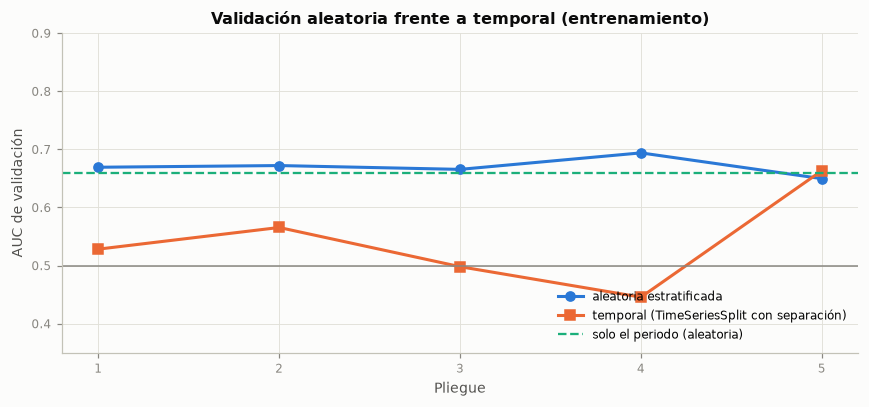

**Interpretación.** Con validación aleatoria el AUC es 0,670; un modelo que solo conoce el año-mes logra 0,660, es decir, el 98 % de ese valor sin ninguna información del cliente. Con validación temporal el AUC cae a 0,540 en promedio (de 0,446 a 0,663), con 2 pliegues por debajo de 0,5, es decir, peores que el azar. Dentro de cada año, el AUC de las predicciones aleatorias es de 0,582 en 2008 y 0,741 en 2009; en 2008 es menor que el global, señal de que parte del AUC aleatorio viene de distinguir periodos.

Esto quiere decir que la evaluación aleatoria está inflada por **fuga temporal**: entrenamiento y validación comparten periodos, y las macro y `month` permiten al modelo reconocer el periodo y su tasa base. Ese conocimiento no existe cuando se predice una campaña futura, cuyo contexto y prevalencia aún no se han observado. La validación temporal mide mejor el desempeño de uso real, aunque es variable porque los periodos son muy distintos entre sí.

En suma, esta evidencia, obtenida solo con entrenamiento, respalda la partición cronológica (sección 2) y la validación temporal (sección 3) como esquema principal; la validación aleatoria queda únicamente como contraste (sección 4.10).

In [31]:
VARS_AUDIT_NUM, VARS_AUDIT_CAT = num_sin_dur, CATEGORICAS
modelo_aud = pipeline_auditoria(VARS_AUDIT_NUM, VARS_AUDIT_CAT)
oof_aud = cross_val_predict(modelo_aud, X_tr, y_tr, cv=skf, method="predict_proba")[:, 1]
cv_aleatoria = cross_validate(modelo_aud, X_tr, y_tr, cv=skf, scoring=["roc_auc", "average_precision"])

solo_periodo = make_pipeline(OneHotEncoder(handle_unknown="ignore"), LogisticRegression(max_iter=5000))
oof_periodo = cross_val_predict(solo_periodo, periodo_tr.to_frame(), y_tr, cv=skf, method="predict_proba")[:, 1]
auc_periodo = roc_auc_score(y_tr, oof_periodo)

filas_tss = []
for k_, (i_ent, i_val) in enumerate(tss.split(X_tr), start=1):
    m_ = pipeline_auditoria(VARS_AUDIT_NUM, VARS_AUDIT_CAT).fit(X_tr.iloc[i_ent], y_tr.iloc[i_ent])
    prob = m_.predict_proba(X_tr.iloc[i_val])[:, 1]
    filas_tss.append({"Pliegue": k_, "Ajusta hasta": periodo_tr.iloc[i_ent[-1]],
                      "Valida desde": periodo_tr.iloc[i_val[0]], "Valida hasta": periodo_tr.iloc[i_val[-1]],
                      "% positivos (ajuste)": 100 * y_tr.iloc[i_ent].mean(),
                      "% positivos (validación)": 100 * y_tr.iloc[i_val].mean(),
                      "AUC": roc_auc_score(y_tr.iloc[i_val], prob),
                      "AUC-PR": average_precision_score(y_tr.iloc[i_val], prob)})
cv_tss = pd.DataFrame(filas_tss).set_index("Pliegue")
tabla(cv_tss, dec=3)

comparacion_val = pd.DataFrame({
    "AUC media": [cv_aleatoria["test_roc_auc"].mean(), auc_periodo, cv_tss["AUC"].mean()],
    "AUC mín.": [cv_aleatoria["test_roc_auc"].min(), np.nan, cv_tss["AUC"].min()],
    "AUC máx.": [cv_aleatoria["test_roc_auc"].max(), np.nan, cv_tss["AUC"].max()],
    "AUC-PR media": [cv_aleatoria["test_average_precision"].mean(),
                     average_precision_score(y_tr, oof_periodo), cv_tss["AUC-PR"].mean()]},
    index=["Aleatoria estratificada (todas las predictoras)", "Aleatoria, solo el periodo (año-mes)",
           "Temporal TimeSeriesSplit con separación (todas las predictoras)"])
tabla(comparacion_val, dec=3)

auc_por_anio = pd.Series({a: roc_auc_score(y_tr[anio_tr == a], oof_aud[(anio_tr == a).to_numpy()])
                          for a in sorted(anio_tr.unique())})
tabla(pd.DataFrame({"AUC fuera de pliegue dentro del año": auc_por_anio,
                    "Registros": anio_tr.value_counts().sort_index()}).rename_axis("Año"), dec=3)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(np.arange(1, 6), cv_aleatoria["test_roc_auc"], color=AZUL, marker="o", label="aleatoria estratificada")
ax.plot(cv_tss.index, cv_tss["AUC"], color=NARANJA, marker="s", label="temporal (TimeSeriesSplit con separación)")
ax.axhline(auc_periodo, color=AGUAMARINA, ls="--", lw=1.5, label="solo el periodo (aleatoria)")
ax.axhline(0.5, color=GRIS, lw=1)
ax.set_xticks(range(1, 6))
ax.set_xlabel("Pliegue")
ax.set_ylabel("AUC de validación")
ax.set_ylim(0.35, 0.9)
ax.set_title("Validación aleatoria frente a temporal (entrenamiento)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

auc_alea = cv_aleatoria["test_roc_auc"].mean()
interpretar(
    f"Con validación aleatoria el AUC es {num(auc_alea, 3)}; un modelo que solo conoce el año-mes logra "
    f"{num(auc_periodo, 3)}, es decir, el {pct(auc_periodo / auc_alea, 0)} de ese valor sin ninguna información del "
    f"cliente. Con validación temporal el AUC cae a {num(cv_tss['AUC'].mean(), 3)} en promedio (de "
    f"{num(cv_tss['AUC'].min(), 3)} a {num(cv_tss['AUC'].max(), 3)})"
    + ((", con un pliegue por debajo de 0,5, es decir, peor que el azar" if (cv_tss["AUC"] < 0.5).sum() == 1 else
        f", con {int((cv_tss['AUC'] < 0.5).sum())} pliegues por debajo de 0,5, es decir, peores que el azar")
       if (cv_tss["AUC"] < 0.5).any() else "")
    + ". Dentro de cada año, el AUC de las predicciones aleatorias es de "
    + enumerar([f"{num(v, 3)} en {a}" for a, v in auc_por_anio.items()], codigo=False)
    + (", menor que el global en todos los años: parte del AUC aleatorio viene de distinguir periodos."
       if (auc_por_anio < auc_alea).all() else
       f"; en {enumerar([str(a) for a, v in auc_por_anio.items() if v < auc_alea], codigo=False)} es menor que el "
       "global, señal de que parte del AUC aleatorio viene de distinguir periodos."
       if (auc_por_anio < auc_alea).any() else "."),
    "Esto quiere decir que la evaluación aleatoria está inflada por **fuga temporal**: entrenamiento y validación "
    "comparten periodos, y las macro y `month` permiten al modelo reconocer el periodo y su tasa base. Ese "
    "conocimiento no existe cuando se predice una campaña futura, cuyo contexto y prevalencia aún no se han observado. "
    "La validación temporal mide mejor el desempeño de uso real, aunque es variable porque los periodos son muy "
    "distintos entre sí.",
    "En suma, esta evidencia, obtenida solo con entrenamiento, respalda la partición cronológica (sección 2) y la "
    "validación temporal (sección 3) como esquema principal; la validación aleatoria queda únicamente como contraste "
    "(sección 4.10).")

#### 3.6.3 Variable temporal, serie diaria y cambios de régimen

La tabla valida la variable temporal reconstruida: formato, frecuencia, marcas repetidas, huecos y cobertura. La figura muestra la serie completa: la tasa de cada día de contacto (el tamaño del punto indica cuántos contactos tuvo) y la de cada semana (la mensual está en la sección 3.1); debajo, la media ponderada y la desviación estándar móviles de 10 días de contacto, y el volumen diario.

Los cambios de régimen se detectan con **segmentación binaria** (Truong et al., 2020) sobre el arcoseno de la raíz de la tasa diaria, cuya varianza (≈ 1/(4n)) no depende del nivel de la tasa. Cada día pesa según sus contactos, la sobredispersión se estima con la mediana de las diferencias entre días consecutivos, la penalización sigue el criterio BIC y cada régimen debe abarcar al menos 10 días de contacto (dos semanas), para no confundir la variación de una semana con un cambio de régimen.

Aspecto,Evidencia (entrenamiento),Conclusión
Formato y zona horaria,"El archivo no trae fecha ni hora; el año y el día de contacto se reconstruyen con el orden de los registros, `month` y `day_of_week` (sección 1.5)",Orden consistente; sin hora ni zona horaria
Frecuencia,"166 días de contacto, solo de lunes a viernes; 25 de 38 semanas tienen los cinco días",Irregular: días hábiles con huecos
Marcas de tiempo repetidas,"Varios contactos por día (mediana 192, máximo 822); son llamadas distintas, no registros duplicados",Esperado: la unidad temporal es el día
Huecos,"Meses sin contactos dentro del rango: 2008-09, 2009-01 y 2009-02; 41 días con menos de 10 contactos",Cobertura desigual en el tiempo
Cobertura,"2008-05 a 2009-05 (10 meses con contactos); el 84,0 % de los registros es de 2008",Menos de dos ciclos anuales: no se puede estimar la estacionalidad anual
Panel,No hay identificador de cliente,No aplica el análisis por entidad


,Desde,Hasta,Días de contacto,Contactos,% que suscribe
Régimen,,,,,
1,2008-05,2008-07,42,12 376,"3,5"
2,2008-07,2008-08,27,8 451,"6,5"
3,2008-08,2008-12,48,6 854,"5,2"
4,2008-12,2009-03,23,283,"44,9"
5,2009-04,2009-04,10,907,"16,2"
6,2009-04,2009-05,16,4 069,"12,0"


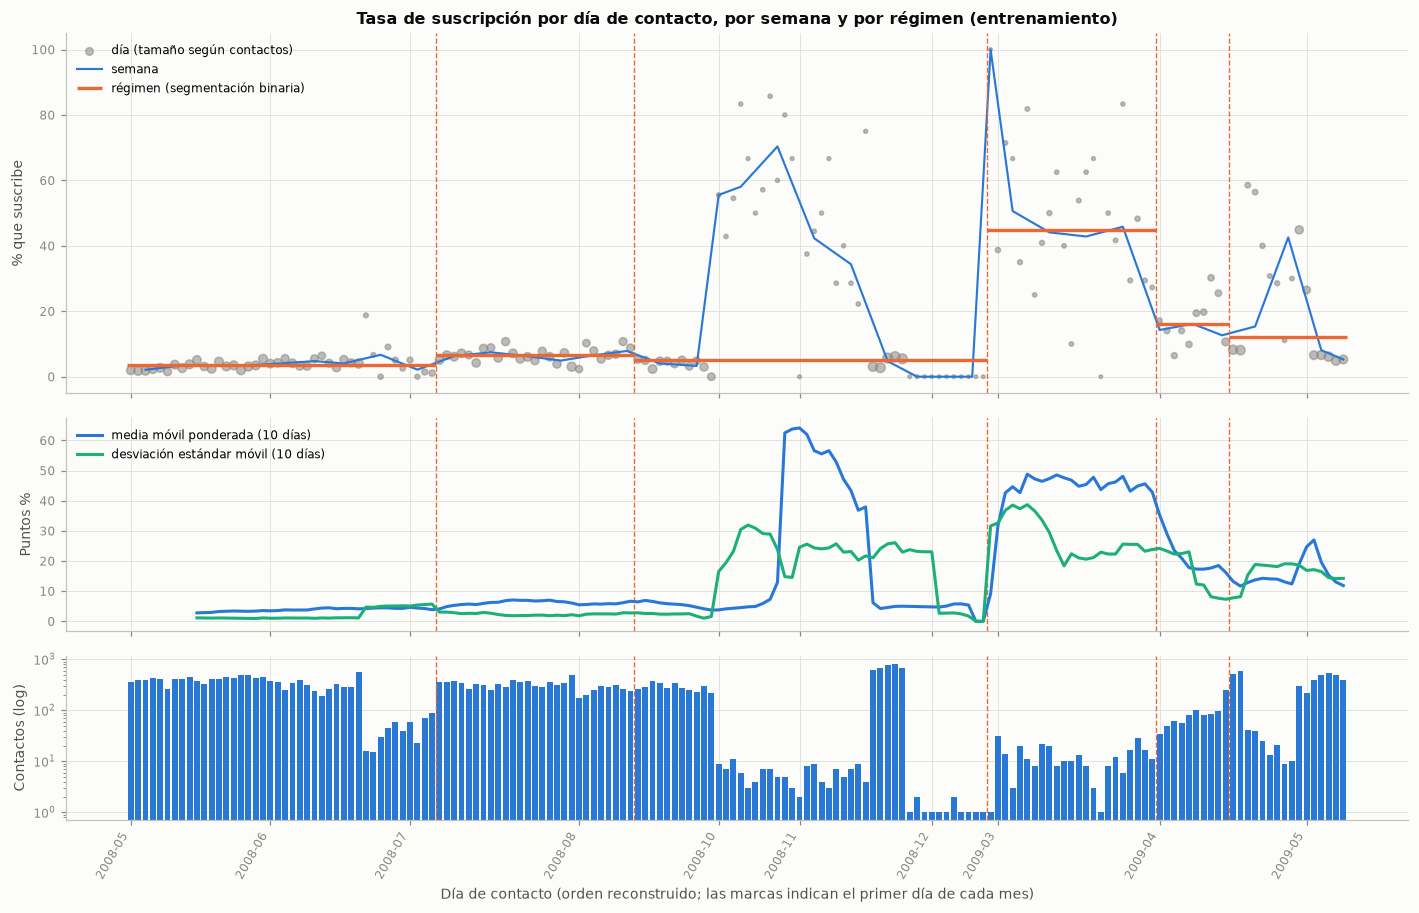

**Interpretación.** En entrenamiento hay 166 días de contacto, pero solo 25 de las 38 semanas están completas, faltan 2008-09, 2009-01 y 2009-02 y 41 días tienen menos de 10 contactos. La segmentación binaria encuentra 5 cambios de régimen: la tasa es del 3,5 % de 2008-05 a 2008-07, sube a un máximo del 44,9 % de 2008-12 a 2009-03, con apenas 12 contactos por día frente a 295 en el primer régimen, y termina en el 12,0 % de 2009-04 a 2009-05. La media móvil de 10 días va del 0,0 % al 64,2 % y la desviación móvil crece en los tramos de poco volumen.

En otras palabras, la serie no tiene un nivel estable: la tasa base cambia por tramos. Después del hueco de septiembre de 2008, en plena crisis financiera, aparecen tramos con pocos contactos y tasas altas, muy distintos de las campañas masivas del primer régimen (de 2008-05 a 2008-07). Un modelo ajustado con el primer régimen enfrenta otra prevalencia en los siguientes (desplazamiento de la clase), y la variabilidad diaria tampoco es constante, porque depende del volumen de llamadas.

Por tal motivo, se opta por mantener la partición y la validación cronológicas; no suponer una tasa base fija, sino actualizar el intercepto con los meses ya cerrados (sección 4.7.1); y no usar `month` ni las macro como si describieran efectos que se repiten de un año a otro.

In [32]:
ORDEN_DOW = ["mon", "tue", "wed", "thu", "fri"]
diario = (tr.assign(dia=dia_tr.to_numpy(), periodo=periodo_tr.to_numpy())
          .groupby("dia", sort=True)
          .agg(contactos=("y", "size"), suscripciones=("y", "sum"), periodo=("periodo", "first"),
               dia_semana=("day_of_week", "first"), **{c: (c, "mean") for c in MACRO}))
diario["tasa"] = diario["suscripciones"] / diario["contactos"]
pos_dow = diario["dia_semana"].map({d: i for i, d in enumerate(ORDEN_DOW)}).to_numpy()
diario["semana"] = np.r_[0, np.cumsum(pos_dow[1:] <= pos_dow[:-1])]   # nueva semana si el día no avanza
dias_por_semana = diario.groupby("semana").size()
rango_meses = pd.period_range(periodo_tr.iloc[0], periodo_tr.iloc[-1], freq="M").strftime("%Y-%m")
meses_sin = [m for m in rango_meses if m not in set(periodo_tr)]
pocos = diario["contactos"] < 10


def segmentacion_binaria(a, w, penal, minimo=5):
    """Puntos de cambio en la media ponderada de `a` (costo: suma de cuadrados ponderada)."""
    def sse(i, j):
        return np.sum(w[i:j] * (a[i:j] - np.average(a[i:j], weights=w[i:j])) ** 2)

    def dividir(i, j):
        if j - i < 2 * minimo:
            return []
        base = sse(i, j)
        ganancia, t = max((base - sse(i, t) - sse(t, j), t) for t in range(i + minimo, j - minimo + 1))
        return dividir(i, t) + [t] + dividir(t, j) if ganancia > penal else []
    return dividir(0, len(a))


# arcoseno de la raíz: varianza ≈ 1/(4n) sin importar la tasa; sobredispersión estimada con días consecutivos
a_dia = np.arcsin(np.sqrt(diario["tasa"].to_numpy()))
w_dia = 4 * diario["contactos"].to_numpy().astype(float)
z_dif = np.diff(a_dia) / np.sqrt(1 / w_dia[1:] + 1 / w_dia[:-1])
phi = np.median(z_dif ** 2) / stats.chi2.ppf(0.5, 1)
cambios = segmentacion_binaria(a_dia, w_dia, penal=2 * phi * np.log(len(a_dia)), minimo=10)
limites = [0] + cambios + [len(diario)]
segmentos = pd.DataFrame([{
    "Desde": diario["periodo"].iloc[i], "Hasta": diario["periodo"].iloc[j - 1], "Días de contacto": j - i,
    "Contactos": int(diario["contactos"].iloc[i:j].sum()),
    "% que suscribe": 100 * diario["suscripciones"].iloc[i:j].sum() / diario["contactos"].iloc[i:j].sum()}
    for i, j in zip(limites[:-1], limites[1:])], index=pd.RangeIndex(1, len(limites), name="Régimen"))

validacion_t = pd.DataFrame([
    ("Formato y zona horaria", "El archivo no trae fecha ni hora; el año y el día de contacto se reconstruyen con el "
     "orden de los registros, `month` y `day_of_week` (sección 1.5)", "Orden consistente; sin hora ni zona horaria"),
    ("Frecuencia", f"{len(diario)} días de contacto, solo de lunes a viernes; {int((dias_por_semana == 5).sum())} de "
     f"{len(dias_por_semana)} semanas tienen los cinco días", "Irregular: días hábiles con huecos"),
    ("Marcas de tiempo repetidas", f"Varios contactos por día (mediana {num(diario['contactos'].median())}, máximo "
     f"{num(diario['contactos'].max())}); son llamadas distintas, no registros duplicados",
     "Esperado: la unidad temporal es el día"),
    ("Huecos", f"Meses sin contactos dentro del rango: {enumerar(meses_sin, codigo=False)}; "
     f"{int(pocos.sum())} días con menos de 10 contactos", "Cobertura desigual en el tiempo"),
    ("Cobertura", f"{periodo_tr.iloc[0]} a {periodo_tr.iloc[-1]} ({periodo_tr.nunique()} meses con contactos); "
     f"el {pct((anio_tr == 2008).mean())} de los registros es de 2008",
     "Menos de dos ciclos anuales: no se puede estimar la estacionalidad anual"),
    ("Panel", "No hay identificador de cliente", "No aplica el análisis por entidad"),
], columns=["Aspecto", "Evidencia (entrenamiento)", "Conclusión"])
tabla(validacion_t, indice=False)
tabla(segmentos, dec=1)

x_dia = np.arange(len(diario))
semanal = diario.groupby("semana").agg(x=("contactos", lambda s: x_dia[s.index - diario.index[0]].mean()),
                                       k=("suscripciones", "sum"), n=("contactos", "sum"))
movil_media = (diario["suscripciones"].rolling(10).sum() / diario["contactos"].rolling(10).sum()).to_numpy()
movil_desv = diario["tasa"].rolling(10).std().to_numpy()
inicio_mes = np.flatnonzero(np.r_[True, diario["periodo"].to_numpy()[1:] != diario["periodo"].to_numpy()[:-1]])

fig, axs = plt.subplots(3, 1, figsize=(13, 8.4), sharex=True, gridspec_kw={"height_ratios": [2.2, 1.3, 1]})
axs[0].scatter(x_dia, 100 * diario["tasa"], s=4 + 40 * np.sqrt(diario["contactos"] / diario["contactos"].max()),
               color=GRIS, alpha=0.55, label="día (tamaño según contactos)")
axs[0].plot(semanal["x"], 100 * semanal["k"] / semanal["n"], color=AZUL, lw=1.4, label="semana")
for r_, (i_, j_) in enumerate(zip(limites[:-1], limites[1:]), start=1):
    axs[0].hlines(segmentos.loc[r_, "% que suscribe"], i_ - 0.5, j_ - 0.5, color=NARANJA, lw=2.2,
                  label="régimen (segmentación binaria)" if r_ == 1 else None)
for t_ in cambios:
    for ax_ in axs:
        ax_.axvline(t_ - 0.5, color=NARANJA, ls="--", lw=0.9)
axs[0].set_ylabel("% que suscribe")
axs[0].set_title("Tasa de suscripción por día de contacto, por semana y por régimen (entrenamiento)")
axs[0].legend(loc="upper left")
axs[1].plot(x_dia, 100 * movil_media, color=AZUL, label="media móvil ponderada (10 días)")
axs[1].plot(x_dia, 100 * movil_desv, color=AGUAMARINA, label="desviación estándar móvil (10 días)")
axs[1].set_ylabel("Puntos %")
axs[1].legend(loc="upper left")
axs[2].bar(x_dia, diario["contactos"], color=AZUL, width=0.8)
axs[2].set_yscale("log")
axs[2].set_ylabel("Contactos (log)")
axs[2].set_xticks(inicio_mes, diario["periodo"].iloc[inicio_mes], rotation=60, ha="right")
axs[2].set_xlabel("Día de contacto (orden reconstruido; las marcas indican el primer día de cada mes)")
plt.tight_layout()
plt.show()

def tramo(r):
    d, h = segmentos.loc[r, "Desde"], segmentos.loc[r, "Hasta"]
    return f"en {d}" if d == h else f"de {d} a {h}"


reg_alto = segmentos["% que suscribe"].idxmax()
dias_por_contacto = segmentos["Contactos"] / segmentos["Días de contacto"]
interpretar(
    f"En entrenamiento hay {len(diario)} días de contacto, pero solo {int((dias_por_semana == 5).sum())} de las "
    f"{len(dias_por_semana)} semanas están completas, faltan {enumerar(meses_sin, codigo=False)} y "
    f"{int(pocos.sum())} días tienen menos de 10 contactos. La segmentación binaria encuentra {len(cambios)} cambios "
    f"de régimen: la tasa es del {num(segmentos['% que suscribe'].iloc[0], 1)} % {tramo(1)}, sube a un máximo del "
    f"{num(segmentos.loc[reg_alto, '% que suscribe'], 1)} % {tramo(reg_alto)}, con apenas "
    f"{num(dias_por_contacto.loc[reg_alto], 0)} contactos por día frente a {num(dias_por_contacto.iloc[0], 0)} en el "
    f"primer régimen, y termina en el {num(segmentos['% que suscribe'].iloc[-1], 1)} % {tramo(len(segmentos))}. "
    f"La media móvil de 10 días va del {num(np.nanmin(100 * movil_media), 1)} % al "
    f"{num(np.nanmax(100 * movil_media), 1)} % y la desviación móvil crece en los tramos de poco volumen.",
    conectar('En otras palabras,', "La serie no tiene un nivel estable: la tasa base cambia por tramos. Después del hueco de septiembre de 2008, "
    "en plena crisis financiera, aparecen tramos con pocos contactos y tasas altas, muy distintos de las campañas "
    f"masivas del primer régimen ({tramo(1)}). Un modelo ajustado con el primer régimen enfrenta otra prevalencia en los "
    "siguientes (desplazamiento de la clase), y la variabilidad diaria tampoco es constante, porque depende del "
    "volumen de llamadas."),
    conectar('Por tal motivo, se opta por', "Mantener la partición y la validación cronológicas; no suponer una tasa base fija, sino actualizar el "
    "intercepto con los meses ya cerrados (sección 4.7.1); y no usar `month` ni las macro como si describieran "
    "efectos que se repiten de un año a otro."))


#### 3.6.4 Descomposición, estacionariedad y dependencia temporal

- **Descomposición STL** (Cleveland et al., 1990) de la tasa diaria con un ciclo de cinco días hábiles, el único que la cobertura permite estimar. La fuerza de la tendencia y del ciclo se mide como en Hyndman y Athanasopoulos (2021): 0 si el componente no aporta frente al residuo y 1 si domina. STL no admite ponderaciones, así que los días con pocos contactos aportan ruido. Al lado, la tasa por día de la semana y por mes (estacionalidad por ciclo), con una caja por día de contacto.
- **Estacionariedad:** pruebas ADF (Dickey y Fuller, 1979; H0: raíz unitaria) y KPSS (Kwiatkowski et al., 1992; H0: estacionariedad) en nivel, en nivel con tendencia y en primera diferencia. Se leen juntas porque sus hipótesis nulas son opuestas; las medias y varianzas móviles están en la figura de la sección 3.6.3.
- **Dependencia temporal:** ACF y PACF de la tasa diaria y ACF del residuo STL.
- **Correlación cruzada** entre la tasa del día y cada indicador macroeconómico de 0 a 5 días antes, en niveles y en primeras diferencias, con corrección de Holm.

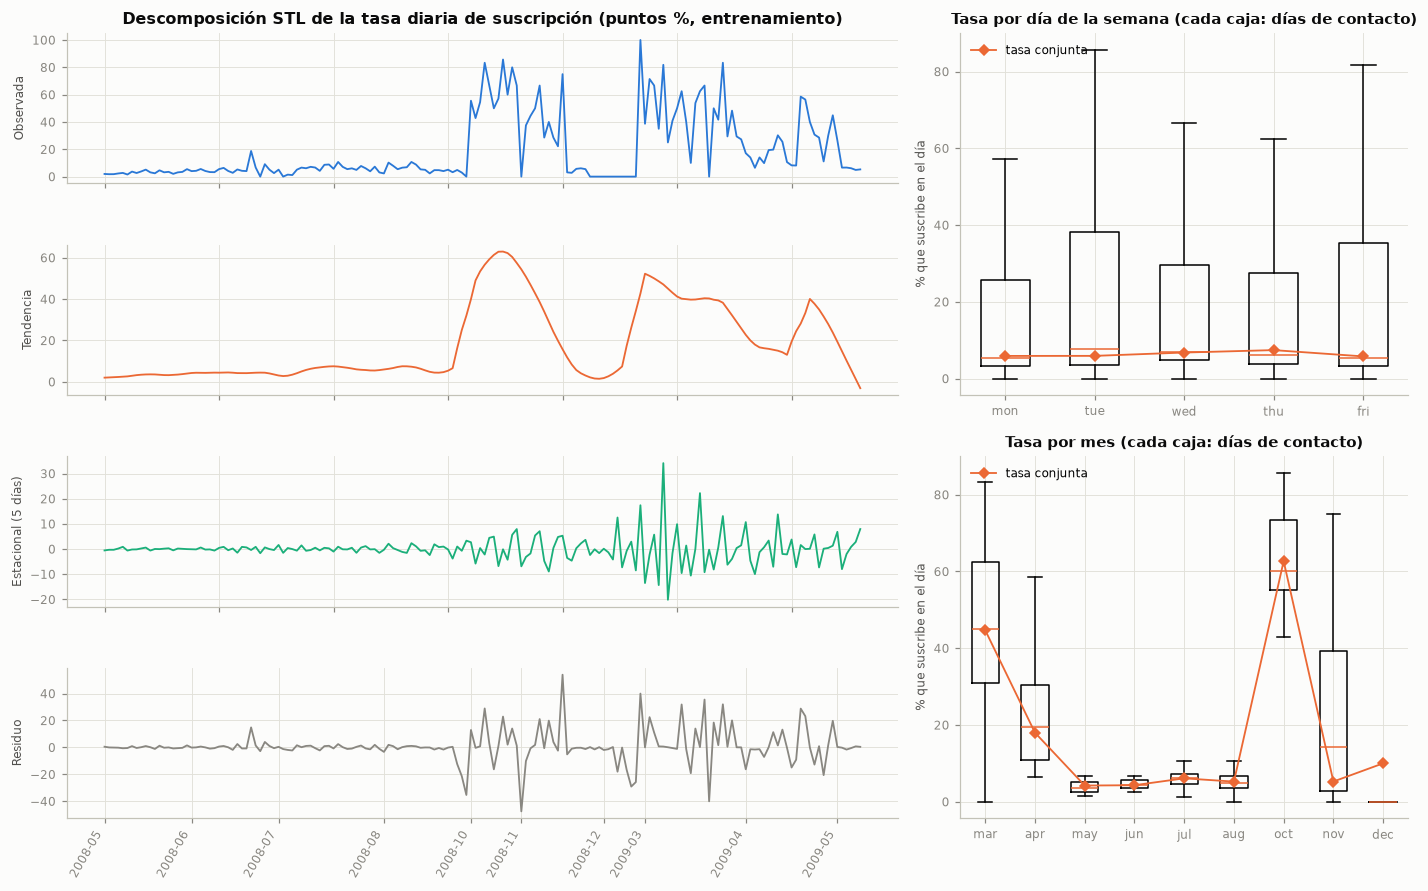

,ADF: p (H0: raíz unitaria),KPSS: p (H0: estacionaria),Conclusión
Serie,,,
"Nivel, con constante","0,141","0,013",No estacionaria
"Nivel, con constante y tendencia","0,005","0,100",Estacionaria
Primera diferencia,"0,000","0,100",Estacionaria


KPSS reporta p acotado a [0,01; 0,10]: 0,010 significa p ≤ 0,01 y 0,100 significa p ≥ 0,10.


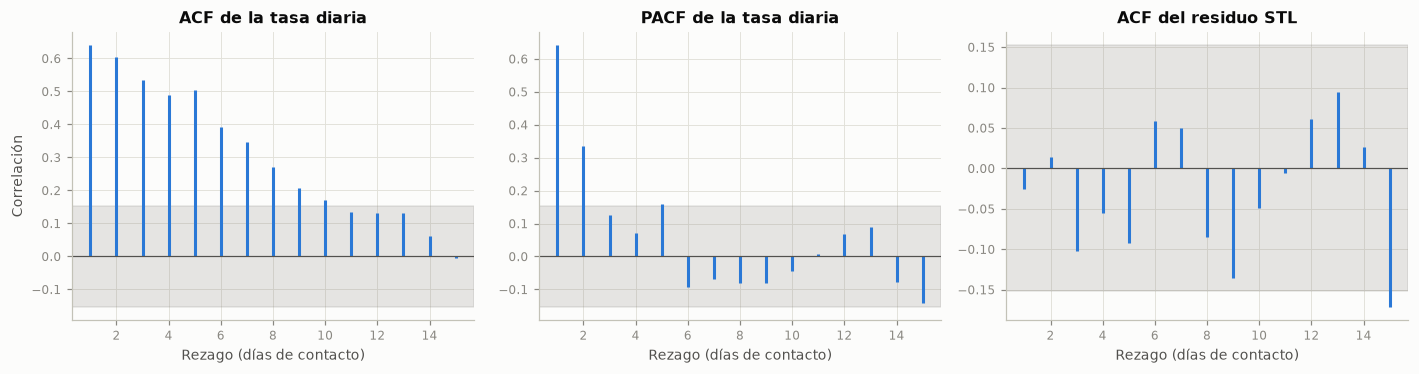

,Correlación en niveles (rezago 0),Correlación más fuerte en diferencias,Rezago (días),"p (Holm, 30 pruebas)"
Indicador,,,,
emp.var.rate,"-0,513","0,204",5,"0,283"
cons.price.idx,"-0,346","0,169",0,"0,818"
cons.conf.idx,"-0,397","0,132",5,"1,000"
euribor3m,"-0,347","0,177",0,"0,636"
nr.employed,"-0,414","0,205",5,"0,283"


**Interpretación.** La fuerza de la tendencia en la descomposición STL es de 0,72 y la del ciclo semanal, de 0,22 (0 = ausente, 1 = domina sobre el residuo). La tasa conjunta por día de la semana va del 5,8 % (fri) al 7,4 % (thu); por mes, del 4,2 % (may) al 62,7 % (oct), aunque 8 de los 9 meses aparecen en un solo año del entrenamiento. Las pruebas dan: en nivel con constante, «no estacionaria»; con tendencia, «estacionaria»; en primera diferencia, «estacionaria». La ACF empieza en 0,64 y cae dentro de la banda del 95 % (0,15) en el rezago 11; la PACF es significativa en los rezagos 1, 2 y 5, mientras que el residuo STL solo sale de la banda en 1 de 15 rezagos. Las macro se correlacionan con la tasa en niveles (de -0,51 a -0,35); en diferencias la correlación más fuerte no pasa de 0,20 y, tras la corrección de Holm, ninguna es significativa.

En ese sentido, la tasa diaria no sigue un ciclo semanal que se repita, y las diferencias por mes no son estacionalidad: como casi cada mes corresponde a un solo año, el mes identifica el régimen. Lo que domina es un nivel que cambia por tramos. Por eso la serie no es estacionaria en nivel y sí lo es al quitarle la tendencia o diferenciarla, y la ACF decae despacio: los días consecutivos se parecen porque pertenecen al mismo régimen, y una vez descontada la tendencia apenas queda dependencia de un día a otro. Que las macro acompañen el nivel pero no los cambios diarios indica que marcan el régimen en que ocurre la llamada, no que lo anticipen (la correlación en niveles entre series no estacionarias puede ser espuria; Granger y Newbold, 1974): un modelo que las usa aprende la tasa base de los regímenes vistos y la extrapola a los nuevos, lo que se refleja en la inestabilidad de sus coeficientes (sección 4.9.1).

En consecuencia, se decide mantener la validación temporal con separación entre bloques (la dependencia entre días consecutivos haría optimista una validación aleatoria); no modelar la tasa como un proceso ARIMA, porque el objetivo es la respuesta de cada cliente y el resultado de los días previos de la campaña no está disponible al llamar; y corregir el nivel de la tasa base con los meses ya cerrados (sección 4.7.1).

In [33]:
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf

serie = 100 * diario["tasa"].to_numpy()
stl = STL(serie, period=5, robust=True).fit()   # ciclo de cinco días hábiles
fuerza_tend = max(0.0, 1 - np.var(stl.resid) / np.var(stl.trend + stl.resid))
fuerza_est = max(0.0, 1 - np.var(stl.resid) / np.var(stl.seasonal + stl.resid))
tasa_dow = diario.groupby("dia_semana")[["suscripciones", "contactos"]].sum().reindex(ORDEN_DOW)
tasa_dow = 100 * tasa_dow["suscripciones"] / tasa_dow["contactos"]
mes_dia = np.array([ORDEN_MESES[int(p[5:7]) - 1] for p in diario["periodo"]])
meses_dia = [m for m in ORDEN_MESES if m in set(mes_dia)]
tasa_mes = diario.groupby(mes_dia)[["suscripciones", "contactos"]].sum().reindex(meses_dia)
tasa_mes = 100 * tasa_mes["suscripciones"] / tasa_mes["contactos"]
anios_por_mes = pd.Series([p[:4] for p in diario["periodo"]]).groupby(mes_dia).nunique().reindex(meses_dia)

fig = plt.figure(figsize=(13, 8.2))
rejilla = fig.add_gridspec(4, 2, width_ratios=[2.6, 1.4])
for k_, (valores_, nombre_, color_) in enumerate([(serie, "Observada", AZUL), (stl.trend, "Tendencia", NARANJA),
                                                 (stl.seasonal, "Estacional (5 días)", AGUAMARINA),
                                                 (stl.resid, "Residuo", GRIS)]):
    ax_ = fig.add_subplot(rejilla[k_, 0])
    ax_.plot(x_dia, valores_, color=color_, lw=1.2)
    ax_.set_ylabel(nombre_, fontsize=8)
    if k_ == 0:
        ax_.set_title("Descomposición STL de la tasa diaria de suscripción (puntos %, entrenamiento)")
    if k_ < 3:
        ax_.tick_params(labelbottom=False)
    else:
        ax_.set_xticks(inicio_mes, diario["periodo"].iloc[inicio_mes], rotation=60, ha="right")
for ax_, grupos_, etiquetas_, conjunta_, titulo_ in [
        (fig.add_subplot(rejilla[:2, 1]), [serie[diario["dia_semana"].to_numpy() == d] for d in ORDEN_DOW], ORDEN_DOW,
         tasa_dow, "Tasa por día de la semana"),
        (fig.add_subplot(rejilla[2:, 1]), [serie[mes_dia == m] for m in meses_dia], meses_dia, tasa_mes,
         "Tasa por mes")]:
    ax_.boxplot(grupos_, tick_labels=etiquetas_, showfliers=False, widths=0.55)
    ax_.plot(range(1, len(etiquetas_) + 1), conjunta_.to_numpy(), color=NARANJA, marker="D", ms=5, lw=1.2,
             label="tasa conjunta")
    ax_.set_ylabel("% que suscribe en el día", fontsize=8)
    ax_.set_title(titulo_ + " (cada caja: días de contacto)", fontsize=9.5)
    ax_.legend(loc="upper left")
plt.tight_layout()
plt.show()

filas_est = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    warnings.simplefilter("ignore", InterpolationWarning)
    for nombre_, s_, reg_ in [("Nivel, con constante", serie, "c"), ("Nivel, con constante y tendencia", serie, "ct"),
                              ("Primera diferencia", np.diff(serie), "c")]:
        p_adf = adfuller(s_, autolag="AIC", regression=reg_)[1]
        p_kpss = kpss(s_, regression=reg_, nlags="auto")[1]
        if p_adf < 0.05 <= p_kpss:
            concl = "Estacionaria"
        elif p_kpss < 0.05 <= p_adf:
            concl = "No estacionaria"
        elif p_adf < 0.05 and p_kpss < 0.05:
            concl = "Contradictoria (posible cambio estructural)"
        else:
            concl = "No concluyente"
        filas_est.append({"Serie": nombre_, "ADF: p (H0: raíz unitaria)": p_adf,
                          "KPSS: p (H0: estacionaria)": p_kpss, "Conclusión": concl})
estacionariedad = pd.DataFrame(filas_est).set_index("Serie")
tabla(estacionariedad, dec=3)
print("KPSS reporta p acotado a [0,01; 0,10]: 0,010 significa p ≤ 0,01 y 0,100 significa p ≥ 0,10.")

rezagos = 15
banda_d = 1.96 / np.sqrt(len(serie))
acf_d, pacf_d = acf(serie, nlags=rezagos), pacf(serie, nlags=rezagos, method="ols")
acf_res_stl = acf(stl.resid, nlags=rezagos)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.5))
for ax_, valores_, titulo_ in [(axs[0], acf_d, "ACF de la tasa diaria"), (axs[1], pacf_d, "PACF de la tasa diaria"),
                               (axs[2], acf_res_stl, "ACF del residuo STL")]:
    ax_.vlines(range(1, rezagos + 1), 0, valores_[1:], color=AZUL, lw=2)
    ax_.axhspan(-banda_d, banda_d, color=GRIS, alpha=0.2)
    ax_.axhline(0, color=TINTA_2, lw=0.8)
    ax_.set_xlabel("Rezago (días de contacto)")
    ax_.set_title(titulo_)
axs[0].set_ylabel("Correlación")
plt.tight_layout()
plt.show()

# Correlación cruzada tasa(t) con indicador(t - k): en niveles puede ser espuria entre series no estacionarias,
# por eso se contrasta con las primeras diferencias y se corrige por comparaciones múltiples (Holm)
d_serie = np.diff(serie)
filas_cc = []
for c_ in MACRO:
    x_ = diario[c_].to_numpy()
    d_x = np.diff(x_)
    for k_ in range(6):
        r_cc = np.corrcoef(d_serie[k_:], d_x[:len(d_x) - k_])[0, 1]
        n_par = len(d_serie) - k_
        p_cc = 2 * stats.t.sf(abs(r_cc) * np.sqrt((n_par - 2) / (1 - r_cc ** 2)), n_par - 2)
        filas_cc.append({"Indicador": c_, "Rezago": k_, "r": r_cc, "p": p_cc,
                         "nivel": np.corrcoef(serie, x_)[0, 1]})
cc_tabla = pd.DataFrame(filas_cc)
cc_tabla["p (Holm)"] = multipletests(cc_tabla["p"], method="holm")[1]
mas_fuerte = (cc_tabla.loc[cc_tabla.groupby("Indicador")["r"].apply(lambda s: s.abs().idxmax())]
              .set_index("Indicador"))
correlacion_cruzada = pd.DataFrame({
    "Correlación en niveles (rezago 0)": mas_fuerte["nivel"],
    "Correlación más fuerte en diferencias": mas_fuerte["r"],
    "Rezago (días)": mas_fuerte["Rezago"].astype(int),
    "p (Holm, 30 pruebas)": mas_fuerte["p (Holm)"]}).reindex(MACRO)
tabla(correlacion_cruzada, dec=3)

r_lento = int(np.argmax(np.abs(acf_d[1:]) < banda_d)) + 1 if (np.abs(acf_d[1:]) < banda_d).any() else rezagos
pacf_sig = [k for k in range(1, rezagos + 1) if abs(pacf_d[k]) > banda_d]
res_sig = [k for k in range(1, rezagos + 1) if abs(acf_res_stl[k]) > banda_d]
cc_sig = correlacion_cruzada.index[correlacion_cruzada["p (Holm, 30 pruebas)"] < 0.05]
conc = estacionariedad["Conclusión"]
interpretar(
    f"La fuerza de la tendencia en la descomposición STL es de {num(fuerza_tend, 2)} y la del ciclo semanal, de "
    f"{num(fuerza_est, 2)} (0 = ausente, 1 = domina sobre el residuo). La tasa conjunta por día de la semana va del "
    f"{num(tasa_dow.min(), 1)} % ({tasa_dow.idxmin()}) al {num(tasa_dow.max(), 1)} % ({tasa_dow.idxmax()}); por mes, del "
    f"{num(tasa_mes.min(), 1)} % ({tasa_mes.idxmin()}) al {num(tasa_mes.max(), 1)} % ({tasa_mes.idxmax()}), aunque "
    f"{int((anios_por_mes == 1).sum())} de los {len(meses_dia)} meses aparecen en un solo año del entrenamiento. Las pruebas "
    f"dan: en nivel con constante, «{conc.iloc[0].lower()}»; con tendencia, «{conc.iloc[1].lower()}»; en primera "
    f"diferencia, «{conc.iloc[2].lower()}». La ACF empieza en {num(acf_d[1], 2)} y "
    + (f"cae dentro de la banda del 95 % ({num(banda_d, 2)}) en el rezago {r_lento}; " if r_lento < rezagos else
       f"sigue fuera de la banda del 95 % ({num(banda_d, 2)}) en los {rezagos} rezagos; ")
    + f"la PACF es significativa en los rezagos {enumerar([str(k) for k in pacf_sig], codigo=False) or 'ninguno'}, "
    f"mientras que el residuo STL solo sale de la banda en {len(res_sig)} de {rezagos} rezagos. Las macro se "
    f"correlacionan con la tasa en niveles (de {num(correlacion_cruzada.iloc[:, 0].min(), 2)} a "
    f"{num(correlacion_cruzada.iloc[:, 0].max(), 2)}); en diferencias la correlación más fuerte no pasa de "
    f"{num(correlacion_cruzada.iloc[:, 1].abs().max(), 2)} y, tras la corrección de Holm, "
    + ("ninguna es significativa." if len(cc_sig) == 0 else
       f"solo {enumerar(list(cc_sig))} lo {'son' if len(cc_sig) > 1 else 'es'}."),
    conectar('En ese sentido,', "La tasa diaria no sigue un ciclo semanal que se repita, y las diferencias por mes no son estacionalidad: como "
    "casi cada mes corresponde a un solo año, el mes identifica el régimen. Lo que domina es un nivel que cambia por "
    "tramos. Por "
    "eso la serie no es estacionaria en nivel y sí lo es al quitarle la tendencia o diferenciarla, y la ACF decae "
    "despacio: los días consecutivos se parecen porque pertenecen al mismo régimen, y una vez descontada la "
    "tendencia apenas queda dependencia de un día a otro. Que las macro acompañen el nivel pero no los cambios "
    "diarios indica que marcan el régimen en que ocurre la llamada, no que lo anticipen (la correlación en niveles "
    "entre series no estacionarias puede ser espuria; Granger y Newbold, 1974): un modelo que las usa aprende la "
    "tasa base de los regímenes vistos y la extrapola a los nuevos, lo que se refleja en la inestabilidad de sus "
    "coeficientes (sección 4.9.1)."),
    conectar('En consecuencia, se decide', "Mantener la validación temporal con separación entre bloques (la dependencia entre días consecutivos haría "
    "optimista una validación aleatoria); no modelar la tasa como un proceso ARIMA, porque el objetivo es la "
    "respuesta de cada cliente y el resultado de los días previos de la campaña no está disponible al llamar; y "
    "corregir el nivel de la tasa base con los meses ya cerrados (sección 4.7.1)."))


#### 3.6.5 Deriva de concepto

La sección 3.6.1 mide el cambio en la distribución de las predictoras (*covariate shift*). Aquí se mide si cambia su **relación con la variable objetivo** (*concept drift*): para cada predictora se compara una regresión logística con la variable y el año contra otra que añade su interacción. El año absorbe el cambio de prevalencia, así que una interacción significativa indica que el efecto de la variable no es el mismo en ambos años (prueba de razón de verosimilitudes, con corrección de Holm). Se excluyen las macro y `month`, porque dentro de un año solo distinguen meses. Como tamaño de efecto se reporta el AUC univariado (numéricas) o la V de Cramér (categóricas) de cada año.

In [34]:
import statsmodels.formula.api as smf

a0, a1 = sorted(anio_tr.unique())[0], sorted(anio_tr.unique())[-1]
es_a1 = (anio_tr == a1).astype(int).to_numpy()
# Variables cuya relación con y puede compararse entre años; las macro y month se excluyen porque dentro de cada
# año solo distinguen meses (sus cambios entre años son deriva de covariables, sección 3.6.1)
REPRESENTACION = {"age": ("num", tr["age"]), "campaign": ("num", np.log1p(tr["campaign"])),
                  "previous": ("num", np.log1p(tr["previous"])),
                  "pdays": ("cat", np.where(tr["pdays"] == 999, "sin registro (999)", "con registro"))}
REPRESENTACION.update({c: ("cat", tr[c]) for c in CATEGORICAS if c != "month"})


def prueba_interaccion(tipo, x):
    """Razón de verosimilitudes de y ~ x * año frente a y ~ x + año (año absorbe el cambio de prevalencia)."""
    d = pd.DataFrame({"y": y_tr.to_numpy(), "x": np.asarray(x), "a": es_a1})
    if tipo == "cat":
        conteo = pd.crosstab(d["x"], d["a"])
        d = d[d["x"].isin(conteo.index[(conteo >= 30).all(axis=1)])]
        termino = "C(x)"
    else:
        d["x"] = (d["x"] - d["x"].mean()) / d["x"].std()
        termino = "x"
    m0 = smf.logit(f"y ~ {termino} + a", d).fit(disp=0)
    m1 = smf.logit(f"y ~ {termino} * a", d).fit(disp=0)
    lr, gl = 2 * (m1.llf - m0.llf), int(m1.df_model - m0.df_model)
    return lr, gl, stats.chi2.sf(lr, gl)


filas_cd = []
for c_, (tipo_, x_cd) in REPRESENTACION.items():
    x_cd = pd.Series(np.asarray(x_cd), index=tr.index)
    efecto_cd = {}
    for a_ in (a0, a1):
        m_cd = (anio_tr == a_).to_numpy()
        efecto_cd[a_] = (roc_auc_score(y_tr[m_cd], x_cd[m_cd]) if tipo_ == "num" else
                         v_cramer(pd.crosstab(x_cd[m_cd], y_tr[m_cd]))[0])
    lr_cd, gl_cd, p_cd = prueba_interaccion(tipo_, x_cd)
    filas_cd.append({"Variable": c_, "Medida": "AUC univariado" if tipo_ == "num" else "V de Cramér",
                     str(a0): efecto_cd[a0], str(a1): efecto_cd[a1], "χ² (interacción con el año)": lr_cd,
                     "gl": gl_cd, "p": p_cd})
deriva_concepto = pd.DataFrame(filas_cd).set_index("Variable")
deriva_concepto["p (Holm)"] = multipletests(deriva_concepto["p"], method="holm")[1]
deriva_concepto = deriva_concepto.drop(columns="p").sort_values("χ² (interacción con el año)", ascending=False)
tabla(deriva_concepto, dec=3)

vars_deriva_concepto = deriva_concepto.index[deriva_concepto["p (Holm)"] < 0.05].tolist()
vars_concepto_estable = deriva_concepto.index[deriva_concepto["p (Holm)"] >= 0.05].tolist()
top_cd = deriva_concepto.index[0]
interpretar(
    f"La tasa de suscripción pasa del {pct(y_tr[es_a1 == 0].mean())} en {a0} al {pct(y_tr[es_a1 == 1].mean())} en el "
    f"tramo de {a1} incluido en entrenamiento. Con ese cambio de prevalencia descontado, la relación con `y` difiere "
    f"entre años (interacción significativa tras Holm) en {len(vars_deriva_concepto)} de las {len(deriva_concepto)} "
    "variables" + (f": {enumerar(vars_deriva_concepto)}" if vars_deriva_concepto else "")
    + f". La mayor diferencia es la de `{top_cd}` ({deriva_concepto.loc[top_cd, 'Medida']} de "
    f"{num(deriva_concepto.loc[top_cd, str(a0)], 3)} en {a0} frente a {num(deriva_concepto.loc[top_cd, str(a1)], 3)} "
    f"en {a1}). "
    + (f"Se mantienen estables {enumerar(vars_concepto_estable)}." if vars_concepto_estable else
       "Ninguna se mantiene estable."),
    conectar('Esto significa que,', "Además del cambio de covariables (sección 3.6.1) y de la prevalencia, hay **deriva de concepto**: para "
    + ("estas variables" if vars_deriva_concepto else "ninguna variable")
    + " la asociación con la suscripción aprendida en " + str(a0) + " no es la que rige en " + str(a1) + ". Los "
    "coeficientes estimados con un periodo dominado por " + str(a0) + " describen ese periodo y se trasladan con "
    "error a los siguientes; cuanto menos regularizado esté el modelo, más se ajusta a esas relaciones que luego "
    "cambian."),
    conectar('Por lo anterior, conviene', "Interpretar los coeficientes como asociaciones del periodo de ajuste (sección 4.9), elegir una "
    "regularización que no sobreajuste las relaciones inestables (sección 4.9.1) y vigilar la deriva con la "
    "validación temporal y el desempeño por año (sección 4.10)."))


,Medida,2008,2009,χ² (interacción con el año),gl,p (Holm)
Variable,,,,,,
job,V de Cramér,"0,022","0,193","103,045",10,"0,000"
education,V de Cramér,"0,021","0,133","54,873",6,"0,000"
default,V de Cramér,"0,016","0,120","53,827",1,"0,000"
day_of_week,V de Cramér,"0,018","0,109","45,517",4,"0,000"
marital,V de Cramér,"0,017","0,087","12,373",2,"0,016"
age,AUC univariado,"0,475","0,476","10,842",1,"0,009"
poutcome,V de Cramér,"0,012","0,180","7,132",2,"0,198"
housing,V de Cramér,"0,012","0,027","6,296",2,"0,258"
loan,V de Cramér,"0,012","0,013","3,645",2,"0,646"


**Interpretación.** La tasa de suscripción pasa del 4,8 % en 2008 al 14,5 % en el tramo de 2009 incluido en entrenamiento. Con ese cambio de prevalencia descontado, la relación con `y` difiere entre años (interacción significativa tras Holm) en 6 de las 13 variables: `job`, `education`, `default`, `day_of_week`, `marital` y `age`. La mayor diferencia es la de `job` (V de Cramér de 0,022 en 2008 frente a 0,193 en 2009). Se mantienen estables `poutcome`, `housing`, `loan`, `pdays`, `campaign`, `contact` y `previous`.

Esto significa que, además del cambio de covariables (sección 3.6.1) y de la prevalencia, hay **deriva de concepto**: para estas variables la asociación con la suscripción aprendida en 2008 no es la que rige en 2009. Los coeficientes estimados con un periodo dominado por 2008 describen ese periodo y se trasladan con error a los siguientes; cuanto menos regularizado esté el modelo, más se ajusta a esas relaciones que luego cambian.

Por lo anterior, conviene interpretar los coeficientes como asociaciones del periodo de ajuste (sección 4.9), elegir una regularización que no sobreajuste las relaciones inestables (sección 4.9.1) y vigilar la deriva con la validación temporal y el desempeño por año (sección 4.10).

### 3.7 Preprocesamiento (enunciado, sección 2.9)

Todo el preprocesamiento se implementa dentro de un `Pipeline` de scikit-learn con un `ColumnTransformer`, de modo que cada parámetro (medianas, medias, desviaciones, categorías) se ajusta **solo con los datos de entrenamiento** de cada pliegue y luego se aplica sin cambios a validación y prueba. La tabla traza cada decisión al hallazgo del EDA que la motiva.

In [35]:
VARS_NUM = [c for c in NUMERICAS if c != "duration" and c not in NUM_RETIRADAS_VIF]
VARS_CAT = list(CATEGORICAS)
VARS_LOG = [c for c in ("campaign", "previous") if c in VARS_NUM]
VARS_ESCALA = [c for c in VARS_NUM if c not in VARS_LOG + ["pdays"]]

meses_ausentes_tr = [m for m in ORDEN_MESES if m not in set(X_tr["month"])]
decisiones = pd.DataFrame([
    (f"Partición cronológica 80/20 y validación TimeSeriesSplit con separación de {GAP} registros",
     f"Fuga temporal: AUC aleatorio de {num(auc_alea, 3)} frente a {num(cv_tss['AUC'].mean(), 3)} temporal; el periodo "
     f"solo logra {num(auc_periodo, 3)}", "1.5, 2 y 3.6"),
    ("Excluir duration", "Solo se conoce después de la llamada; sube el AUC de "
     f"{num(auc_sin_dur, 3)} a {num(auc_con_dur, 3)}", "3.5"),
    (f"Excluir {enumerar(NUM_RETIRADAS_VIF, codigo=False)}",
     f"VIF inicial de {enumerar([num(vif_inicial[c], 1) for c in NUM_RETIRADAS_VIF], codigo=False)}", "3.3.5"),
    ("unknown como categoría propia (sin imputar la moda ni eliminar filas)",
     "Faltantes no MCAR e informativos; eliminarlos quitaría el " + pct(alguno.mean()) + " de los registros", "1.6.1 y 1.6.2"),
    ("pdays = 999 → faltante + indicador; imputación por la mediana (de entrenamiento)",
     "999 es un código, no días; inconsistente con previous en " + num(inc_pdays) + " registros", "1.6.4"),
    ("log1p en " + enumerar(VARS_LOG, codigo=False), "Asimetría de " + enumerar([num(uni_num.loc[c, "Asimetría"], 1) for c in VARS_LOG], codigo=False)
     + " y atípicos legítimos de cola larga", "3.2.1 y 3.4.2"),
    ("Sin eliminar atípicos", "Son valores plausibles y concentran clientes con historial", "1.6.5 y 3.4.2"),
    ("Estandarización de todas las numéricas", "Escalas muy distintas (edad, índices, empleo) y penalización L2", "3.2.1"),
    ("One-hot con referencia (drop='first') para las categóricas",
     "Variables nominales; la referencia facilita leer los odds ratios", "3.2.2"),
    (f"Categorías con menos del {pct(MIN_FREQ)} agrupadas como infrecuentes; las no vistas en entrenamiento "
     "van a la categoría infrecuente o a la de referencia",
     f"{len(muy_raras)} categorías raras con coeficientes inestables; meses ausentes en entrenamiento: "
     f"{enumerar(meses_ausentes_tr, codigo=False)}", "3.2.2"),
    ("Sin variables de periodo ni de clúster", "El periodo no se conoce hacia el futuro; los clústeres repiten el periodo",
     "3.4.3 y 3.6"),
    ("Elegir C con la pérdida logarítmica de la validación temporal (sección 4.1)",
     f"Las macro solo marcan el régimen y la relación con y cambia entre años en {len(vars_deriva_concepto)} de "
     f"{len(deriva_concepto)} variables: un modelo poco regularizado extrapola mal a periodos nuevos", "3.6.4 y 3.6.5"),
    ("Recalibrar el intercepto cada mes con los meses ya cerrados (sección 4.7.1)",
     f"La tasa cambia por regímenes ({len(segmentos)} tramos, del {num(segmentos['% que suscribe'].min(), 1)} % al "
     f"{num(segmentos['% que suscribe'].max(), 1)} %) y no es estacionaria en nivel", "3.6.3 y 3.6.4"),
], columns=["Decisión", "Hallazgo del EDA que la motiva", "Sección"])
tabla(decisiones, indice=False)

Decisión,Hallazgo del EDA que la motiva,Sección
Partición cronológica 80/20 y validación TimeSeriesSplit con separación de 507 registros,"Fuga temporal: AUC aleatorio de 0,670 frente a 0,540 temporal; el periodo solo logra 0,660","1.5, 2 y 3.6"
Excluir duration,"Solo se conoce después de la llamada; sube el AUC de 0,540 a 0,856",3.5
Excluir euribor3m y emp.var.rate,"VIF inicial de 46,2 y 45,4",3.3.5
unknown como categoría propia (sin imputar la moda ni eliminar filas),"Faltantes no MCAR e informativos; eliminarlos quitaría el 26,0 % de los registros",1.6.1 y 1.6.2
pdays = 999 → faltante + indicador; imputación por la mediana (de entrenamiento),"999 es un código, no días; inconsistente con previous en 4 110 registros",1.6.4
log1p en campaign y previous,"Asimetría de 4,6 y 3,9 y atípicos legítimos de cola larga",3.2.1 y 3.4.2
Sin eliminar atípicos,Son valores plausibles y concentran clientes con historial,1.6.5 y 3.4.2
Estandarización de todas las numéricas,"Escalas muy distintas (edad, índices, empleo) y penalización L2",3.2.1
One-hot con referencia (drop='first') para las categóricas,Variables nominales; la referencia facilita leer los odds ratios,3.2.2
"Categorías con menos del 0,5 % agrupadas como infrecuentes; las no vistas en entrenamiento van a la categoría infrecuente o a la de referencia","5 categorías raras con coeficientes inestables; meses ausentes en entrenamiento: jan, feb y sep",3.2.2


In [36]:
def pdays_a_nan(X):
    """Convierte el código 999 de pdays en faltante para imputarlo y marcarlo con un indicador."""
    X = np.asarray(X, dtype=float).copy()
    X[X == 999] = np.nan
    return X


def construir_preprocesador(numericas=None, categoricas=None):
    numericas = VARS_NUM if numericas is None else numericas
    categoricas = VARS_CAT if categoricas is None else categoricas
    escala = [c for c in numericas if c not in ("campaign", "previous", "pdays")]
    logs = [c for c in ("campaign", "previous") if c in numericas]
    pasos = [
        ("num", StandardScaler(), escala),
        ("log", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), logs),
        ("cat", OneHotEncoder(drop="first", min_frequency=MIN_FREQ, handle_unknown="infrequent_if_exist",
                              sparse_output=False), categoricas),
    ]
    if "pdays" in numericas:
        pasos.insert(2, ("pdays", make_pipeline(
            FunctionTransformer(pdays_a_nan, feature_names_out="one-to-one"),
            SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True),
            StandardScaler()), ["pdays"]))
    return ColumnTransformer(pasos)


def construir_modelo(C=1.0, numericas=None, categoricas=None):
    return Pipeline([("pre", construir_preprocesador(numericas, categoricas)),
                     ("lr", LogisticRegression(C=C, max_iter=5000))])


# En validación cronológica pueden aparecer meses no vistos; el codificador los envía a la categoría
# infrecuente (o a la referencia) por diseño, así que el aviso correspondiente se silencia.
warnings.filterwarnings("ignore", message="Found unknown categories")

pre_ajustado = construir_preprocesador().fit(X_tr, y_tr)
nombres_salida = pre_ajustado.get_feature_names_out()
codif = pre_ajustado.named_transformers_["cat"]
infrecuentes = {c: list(v) for c, v in zip(VARS_CAT, codif.infrequent_categories_) if v is not None}
print(pre_ajustado)
print(f"\nPredictoras de entrada: {len(VARS_NUM)} numéricas + {len(VARS_CAT)} categóricas = "
      f"{len(VARS_NUM) + len(VARS_CAT)}")
print(f"Columnas tras el preprocesamiento: {len(nombres_salida)}")
print("Categorías agrupadas como infrecuentes (ajustadas en entrenamiento):", infrecuentes)
print(f"Mediana de pdays (sin 999) aprendida en entrenamiento: "
      f"{pre_ajustado.named_transformers_['pdays'].named_steps['simpleimputer'].statistics_[0]:.0f} días")

cv_vif = {}
for nombre, numericas in [("Con todas las macro", [c for c in NUMERICAS if c != "duration"]),
                          ("Sin las retiradas por VIF (modelo base)", VARS_NUM)]:
    r = cross_validate(construir_modelo(numericas=numericas), X_tr, y_tr, cv=tss, scoring=["roc_auc", "average_precision"])
    cv_vif[nombre] = {"AUC media": r["test_roc_auc"].mean(), "AUC desv. est.": r["test_roc_auc"].std(),
                      "AUC-PR media": r["test_average_precision"].mean()}
cv_vif = pd.DataFrame(cv_vif).T
tabla(cv_vif, dec=4)

perdida_vif = cv_vif.iloc[0]["AUC media"] - cv_vif.iloc[1]["AUC media"]
interpretar(
    f"El preprocesamiento convierte {len(VARS_NUM) + len(VARS_CAT)} predictoras en {len(nombres_salida)} columnas "
    f"(n/p efectivo = {num(len(X_tr) / len(nombres_salida), 0)}; {num(y_tr.sum() / len(nombres_salida), 0)} eventos por "
    f"columna). Retirar {enumerar(NUM_RETIRADAS_VIF)} cambia el AUC de validación de "
    f"{num(cv_vif.iloc[0]['AUC media'], 4)} a {num(cv_vif.iloc[1]['AUC media'], 4)} en la validación temporal "
    f"(diferencia de {num(perdida_vif, 4)}; la desviación entre pliegues es de {num(cv_vif.iloc[1]['AUC desv. est.'], 4)}).",
    ("Esto significa que la eliminación por VIF no cuesta desempeño apreciable frente a la variabilidad entre pliegues "
     "y deja coeficientes interpretables. " if abs(perdida_vif) < cv_vif.iloc[1]["AUC desv. est."] else
     "Esto significa que la eliminación por VIF cambia el AUC más que la variabilidad entre pliegues; se mantiene por "
     "interpretabilidad y se declara su costo. ")
    + "El número de eventos por columna es amplio, así que el riesgo de sobreajuste por dimensionalidad es bajo.",
    "Por lo anterior, conviene usar este `Pipeline` como base del modelo de la sección 4, con el hiperparámetro de "
    "regularización elegido por validación cruzada.")

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['age', 'cons.price.idx', 'cons.conf.idx',
                                  'nr.employed']),
                                ('log',
                                 Pipeline(steps=[('functiontransformer',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<ufunc 'log1p'>)),
                                                 ('standardscaler',
                                                  StandardScaler())]),
                                 ['campaign', 'previous']),
                                ('pdays',
                                 Pipeline(steps=[('functiontransformer',
                                                  Function...
                                                 ('simpleimputer',
                                                  SimpleImputer

,AUC media,AUC desv. est.,AUC-PR media
Con todas las macro,"0,5345","0,0573","0,0855"
Sin las retiradas por VIF (modelo base),"0,5374","0,0753","0,0961"


**Interpretación.** El preprocesamiento convierte 17 predictoras en 49 columnas (n/p efectivo = 672; 43 eventos por columna). Retirar `euribor3m` y `emp.var.rate` cambia el AUC de validación de 0,5345 a 0,5374 en la validación temporal (diferencia de -0,0029; la desviación entre pliegues es de 0,0753).

Esto significa que la eliminación por VIF no cuesta desempeño apreciable frente a la variabilidad entre pliegues y deja coeficientes interpretables. El número de eventos por columna es amplio, así que el riesgo de sobreajuste por dimensionalidad es bajo.

Por lo anterior, conviene usar este `Pipeline` como base del modelo de la sección 4, con el hiperparámetro de regularización elegido por validación cruzada.

#### Módulos del tercer entregable

A partir de aquí se cargan el paquete del proyecto (`src/bm`) y las librerías nuevas de este entregable. La celda va después del EDA heredado para que ninguna variable de las secciones 1 a 3 oculte las funciones del paquete.

In [37]:
import json
import pickle
import subprocess
import sys

sys.path.insert(0, str(Path("src").resolve()))

import arch
import deap
import faiss
import imblearn
import lime
import optuna
import scikit_posthocs as sp
import shap
import xgboost
from scipy.special import expit
from sklearn.metrics import (ConfusionMatrixDisplay, mean_absolute_error, precision_recall_curve as curva_pr,
                             r2_score, root_mean_squared_error)

from statsmodels.tsa.stattools import acf

from bm import computacional as comp
from bm import config as cfg
from bm import estadistica as st
from bm import evaluacion as evm
from bm.anidada import cargar_corridas, id_tarea, lista_combinaciones, particion
from bm.datos import cv_externa, cv_interna
from bm.espacios import ESPACIOS, JUSTIFICACION, REJILLAS, n_puntos_rejilla

assert SEED == cfg.SEED
RECALCULAR = False  # True: vuelve a ejecutar la validación anidada (cerca de una hora con 10 núcleos)
if RECALCULAR:
    subprocess.run([sys.executable, "scripts/ejecutar_experimentos.py"], check=True)
    subprocess.run([sys.executable, "scripts/ejecutar_finales.py", "--computacional"], check=True)

RES = cfg.RUTA_RESULTADOS
NM, NB, NO = cfg.NOMBRE_MODELO, cfg.NOMBRE_BALANCEO, cfg.NOMBRE_OPTIMIZADOR
# Paleta categórica validada, en orden fijo (la identidad sigue a la entidad, nunca al rango)
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
COLOR_MODELO = {m: CAT[i] for i, m in enumerate(cfg.MODELOS_CLF)}
COLOR_MODELO_REG = {m: CAT[i] for i, m in enumerate(cfg.MODELOS_REG)}
ORDEN_OPT = ["grid", "random", "bayes", "genetico", "halving"]
COLOR_OPT = {o: CAT[i] for i, o in enumerate(ORDEN_OPT)}
COLOR_BAL = {b: CAT[i] for i, b in enumerate(cfg.BALANCEOS)}

def ms(serie, d=3):
    """Media ± desviación estándar con coma decimal."""
    return f"{num(np.mean(serie), d)} ± {num(np.std(serie, ddof=1), d)}"


def etiqueta(r):
    """Nombre legible de una combinación."""
    partes = [NM[r["modelo"]]]
    if r["tarea"] == "clf":
        partes.append(NB[r["balanceo"]])
    partes.append(NO[r["optimizador"]])
    return " · ".join(partes)


versiones_e3 = pd.DataFrame({
    "Componente": ["imbalanced-learn", "xgboost", "optuna", "deap", "shap", "lime", "arch", "faiss-cpu",
                   "scikit-posthocs"],
    "Versión": [imblearn.__version__, xgboost.__version__, optuna.__version__, deap.__version__, shap.__version__,
                getattr(lime, "__version__", "0.2.0.1"), arch.__version__, faiss.__version__, sp.__version__]})
tabla(versiones_e3, indice=False)

DASH = Path("dashboard") / "datos"
DASH.mkdir(parents=True, exist_ok=True)


def exportar(nombre, obj):
    """Guarda un resultado para el dashboard y el Jupyter Book (mismas cifras que este cuaderno)."""
    if isinstance(obj, pd.Series):
        obj = obj.to_frame()
    if isinstance(obj, pd.DataFrame):
        df_ = obj.copy()
        df_.columns = [" · ".join(map(str, c)) if isinstance(c, tuple) else str(c) for c in df_.columns]
        for c in df_.columns:
            if df_[c].dtype == object:
                df_[c] = df_[c].map(lambda v: v if v is None or isinstance(v, str) else str(v))
        df_.to_parquet(DASH / f"{nombre}.parquet")
    else:
        (DASH / f"{nombre}.json").write_text(json.dumps(obj, default=float, ensure_ascii=False, indent=1),
                                             encoding="utf-8")


C:\Users\donov\miniconda3\envs\bm_e3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Componente,Versión
imbalanced-learn,0.14.2
xgboost,3.4.1
optuna,5.0.0
deap,1.4
shap,0.54.1
lime,0.2.0.1
arch,8.0.0
faiss-cpu,1.15.1
scikit-posthocs,0.17.1


### 3.8 Nuevos hallazgos para el tercer entregable

El desarrollo de este entregable exige dos análisis que el EDA anterior no cubría: la variable continua de la rama de regresión, que la guía pide aunque *Bank Marketing* sea un problema de clasificación, y el desbalance dentro de los pliegues de la validación anidada, que condiciona la viabilidad de SMOTE y ADASYN. Ambos se calculan solo con el conjunto de entrenamiento.

#### 3.8.1 Variable objetivo de la rama de regresión: `log1p(duration)`

La única variable continua del archivo con sentido como objetivo a nivel de cliente es `duration`, la duración de la llamada en segundos. En la clasificación se excluye porque solo se conoce después de la llamada (sección 3.5), pero como **objetivo** es legítima: estimar antes de marcar cuánto durará la llamada sirve para planificar la carga de los asesores. Las predictoras son las mismas de la clasificación (información previa a la llamada) y `y` no se usa, porque también se conoce después.

,duration (s),log1p(duration)
Media,"255,99","5,16"
Mediana,"175,00","5,17"
Desv. est.,"261,26","0,91"
Asimetría,"3,32","-0,30"
Registros con 0 s,"3,00",—
Máximo,"4 918,00","8,50"


Variable,Medida,Valor,p
nr.employed,Spearman |rho|,"0,0858","0,0000"
campaign,Spearman |rho|,"0,0768","0,0000"
cons.conf.idx,Spearman |rho|,"0,0503","0,0000"
pdays,Spearman |rho|,"0,0313","0,0000"
age,Spearman |rho|,"0,0193","0,0005"
month,eta²,"0,0124","0,0000"
previous,Spearman |rho|,"0,0061","0,2684"
cons.price.idx,Spearman |rho|,"0,0044","0,4295"


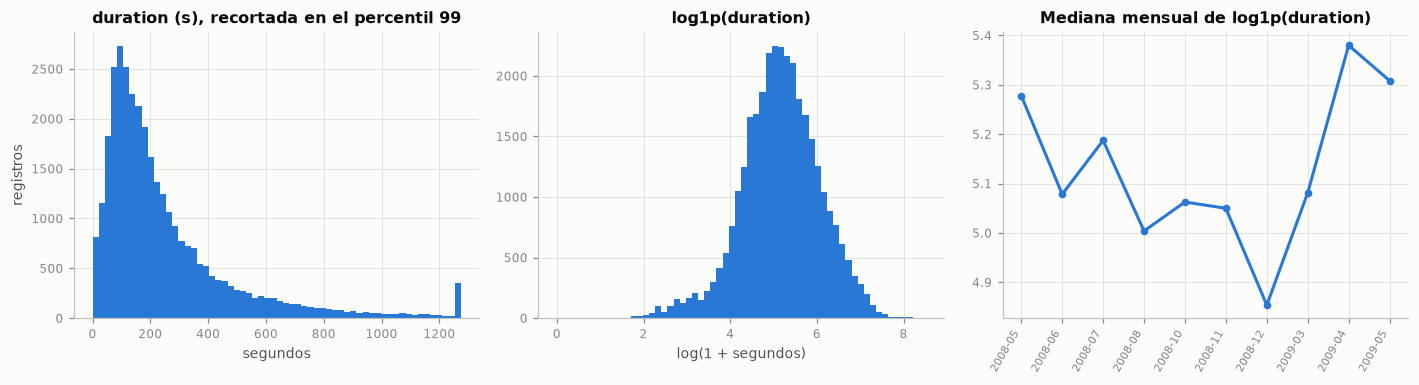

**Interpretación.** La duración tiene media de 256 s y mediana de 175 s, con asimetría de 3,3 y 3 llamadas de 0 s; en escala `log1p` la asimetría baja a -0,30. La asociación más fuerte con una predictora previa a la llamada es la de `nr.employed` (Spearman |rho| = 0,086); ninguna otra supera 0,077. La mediana mensual se mueve entre 4,85 y 5,38 en escala log.

Esto significa que la transformación logarítmica vuelve la distribución casi simétrica y evita que unas pocas llamadas largas dominen el RMSE, pero la señal disponible antes de la llamada es débil: las asociaciones son estadísticamente significativas por el tamaño de muestra, aunque de magnitud pequeña. Es de esperar que los modelos de regresión apenas superen a la media histórica.

Por tal motivo, se opta por modelar `log1p(duration)` y reportar el RMSE y el MAE en escala log y en segundos, comparando siempre contra el pronóstico de la media del entrenamiento. Un resultado nulo en esta rama no es un error del pipeline: es evidencia de que la duración depende de lo que ocurre durante la llamada.

In [38]:
dur = tr["duration"].astype(float)
log_dur = np.log1p(dur)
resumen_dur = pd.DataFrame({
    "duration (s)": [dur.mean(), dur.median(), dur.std(), stats.skew(dur), (dur == 0).sum(), dur.max()],
    "log1p(duration)": [log_dur.mean(), log_dur.median(), log_dur.std(), stats.skew(log_dur), np.nan, log_dur.max()]},
    index=["Media", "Mediana", "Desv. est.", "Asimetría", "Registros con 0 s", "Máximo"])
tabla(resumen_dur, dec=2)

# Asociación con las predictoras previas a la llamada: Spearman (numéricas) y eta² (categóricas)
asoc = []
for c in VARS_NUM:
    rho, p_ = stats.spearmanr(tr[c], log_dur)
    asoc.append({"Variable": c, "Medida": "Spearman |rho|", "Valor": abs(rho), "p": p_})
for c in VARS_CAT:
    g = log_dur.groupby(tr[c])
    eta2 = (g.size() * (g.mean() - log_dur.mean()) ** 2).sum() / ((log_dur - log_dur.mean()) ** 2).sum()
    asoc.append({"Variable": c, "Medida": "eta²", "Valor": eta2, "p": stats.kruskal(*[v for _, v in g]).pvalue})
asoc = pd.DataFrame(asoc).sort_values("Valor", ascending=False)
tabla(asoc.head(8), dec=4, indice=False)

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
axs[0].hist(dur.clip(upper=dur.quantile(0.99)), bins=60, color=AZUL)
axs[0].set(title="duration (s), recortada en el percentil 99", xlabel="segundos", ylabel="registros")
axs[1].hist(log_dur, bins=60, color=AZUL)
axs[1].set(title="log1p(duration)", xlabel="log(1 + segundos)")
med_mes = log_dur.groupby(periodo_tr).median()
axs[2].plot(range(len(med_mes)), med_mes.values, color=AZUL, marker="o", ms=4)
axs[2].set_xticks(range(len(med_mes)), med_mes.index, rotation=60, ha="right", fontsize=7)
axs[2].set(title="Mediana mensual de log1p(duration)")
plt.tight_layout()
plt.show()

asim_log = stats.skew(log_dur)
top = asoc.iloc[0]
interpretar(
    f"La duración tiene media de {num(dur.mean())} s y mediana de {num(dur.median())} s, con asimetría de "
    f"{num(stats.skew(dur), 1)} y {int((dur == 0).sum())} llamadas de 0 s; en escala `log1p` la asimetría baja a "
    f"{num(asim_log, 2)}. La asociación más fuerte con una predictora previa a la llamada es la de `{top['Variable']}` "
    f"({top['Medida']} = {num(top['Valor'], 3)}); ninguna otra supera {num(asoc['Valor'].iloc[1], 3)}. La mediana mensual "
    f"se mueve entre {num(med_mes.min(), 2)} y {num(med_mes.max(), 2)} en escala log.",
    conectar("Esto significa que", "La transformación logarítmica vuelve la distribución casi simétrica y evita que unas "
             "pocas llamadas largas dominen el RMSE, pero la señal disponible antes de la llamada es débil: las "
             "asociaciones son estadísticamente significativas por el tamaño de muestra, aunque de magnitud pequeña. Es "
             "de esperar que los modelos de regresión apenas superen a la media histórica."),
    conectar("Por tal motivo, se opta por", "Modelar `log1p(duration)` y reportar el RMSE y el MAE en escala log y en "
             "segundos, comparando siempre contra el pronóstico de la media del entrenamiento. Un resultado nulo en esta "
             "rama no es un error del pipeline: es evidencia de que la duración depende de lo que ocurre durante la "
             "llamada."))

#### 3.8.2 Desbalance dentro de los pliegues de la validación anidada

SMOTE necesita al menos `k + 1 = 6` positivos en cada ajuste para interpolar entre vecinos, y ADASYN además necesita positivos rodeados de negativos. Como la prevalencia de 2008 es muy baja y los pliegues internos de la validación anidada son pequeños, se verifica cuántos positivos tiene el ajuste más pequeño de cada pliegue externo antes de comprometer el diseño.

In [39]:
filas = []
for k_, (i_e, i_v) in enumerate(cv_externa(GAP).split(X_tr), start=1):
    internos = list(cv_interna(GAP).split(i_e))
    i_min = i_e[internos[0][0]]
    filas.append({"Pliegue externo": k_, "Positivos en el ajuste externo": int(y_tr.iloc[i_e].sum()),
                  "% positivos ajuste externo": 100 * y_tr.iloc[i_e].mean(),
                  "Filas del ajuste interno más pequeño": len(i_min),
                  "Positivos en el ajuste interno más pequeño": int(y_tr.iloc[i_min].sum()),
                  "Razón negativos/positivos (ajuste externo)": (1 - y_tr.iloc[i_e].mean()) / y_tr.iloc[i_e].mean(),
                  "% positivos validación externa": 100 * y_tr.iloc[i_v].mean()})
desb = pd.DataFrame(filas).set_index("Pliegue externo")
tabla(desb, dec=2)

interpretar(
    f"El ajuste interno más pequeño tiene {num(desb['Positivos en el ajuste interno más pequeño'].min())} positivos, "
    + ("por encima de los seis que necesita SMOTE con k = 5. " if desb['Positivos en el ajuste interno más pequeño'].min() >= 6
       else "por debajo de los seis que necesita SMOTE con k = 5. ") +
    f"La razón negativos/positivos del ajuste externo va de "
    f"{num(desb['Razón negativos/positivos (ajuste externo)'].min(), 1)} a "
    f"{num(desb['Razón negativos/positivos (ajuste externo)'].max(), 1)}, mientras que la prevalencia de validación "
    f"externa va del {num(desb['% positivos validación externa'].min(), 1)} % al "
    f"{num(desb['% positivos validación externa'].max(), 1)} %; en prueba es del {pct(y_te.mean())}.",
    conectar("Lo anterior indica que", "El sobremuestreo es viable en todos los pliegues, pero el desbalance que corrige "
             "no es el único problema: la prevalencia cambia entre periodos (*prior shift*), y ninguna técnica de "
             "balanceo, que equilibra las clases dentro del ajuste, anticipa ese cambio. Además, balancear desplaza las "
             "probabilidades hacia 0,5, de modo que su efecto debe medirse en métricas de umbral (recall, F1) y de "
             "calibración, no solo en AUC o AUC-PR, que dependen del orden."),
    conectar("Por tanto, corresponde", "Mantener SMOTE y ADASYN dentro del `Pipeline` de `imblearn` (solo actúan en `fit`), "
             "comparar el balanceo con métricas de umbral y de calibración (secciones 7.2 y 7.4) y separar su efecto del "
             "cambio de prevalencia, que se trata con la recalibración mensual heredada del Entregable 2."))

,Positivos en el ajuste externo,% positivos ajuste externo,Filas del ajuste interno más pequeño,Positivos en el ajuste interno más pequeño,Razón negativos/positivos (ajuste externo),% positivos validación externa
Pliegue externo,,,,,,
1,145,"2,91",741,14,"33,37","3,88"
2,357,"3,41",2 112,46,"28,34","6,05"
3,681,"4,27",3 486,88,"22,44","5,92"
4,1 014,"4,73",4 857,139,"20,16","5,45"
5,1 299,"4,82",6 231,184,"19,74","14,03"


**Interpretación.** El ajuste interno más pequeño tiene 14 positivos, por encima de los seis que necesita SMOTE con k = 5. La razón negativos/positivos del ajuste externo va de 19,7 a 33,4, mientras que la prevalencia de validación externa va del 3,9 % al 14,0 %; en prueba es del 30,8 %.

Lo anterior indica que el sobremuestreo es viable en todos los pliegues, pero el desbalance que corrige no es el único problema: la prevalencia cambia entre periodos (*prior shift*), y ninguna técnica de balanceo, que equilibra las clases dentro del ajuste, anticipa ese cambio. Además, balancear desplaza las probabilidades hacia 0,5, de modo que su efecto debe medirse en métricas de umbral (recall, F1) y de calibración, no solo en AUC o AUC-PR, que dependen del orden.

Por tanto, corresponde mantener SMOTE y ADASYN dentro del `Pipeline` de `imblearn` (solo actúan en `fit`), comparar el balanceo con métricas de umbral y de calibración (secciones 7.2 y 7.4) y separar su efecto del cambio de prevalencia, que se trata con la recalibración mensual heredada del Entregable 2.

## 4. Diseño experimental del tercer entregable

### 4.1 Preguntas de investigación

El problema principal sigue siendo el del Entregable 2: predecir, **con la información disponible antes de la llamada**, si el cliente suscribirá el depósito a término, para decidir a quién llamar primero. Este entregable lo amplía en tres direcciones, cada una con una pregunta:

1. **Modelos y balanceo.** ¿Qué combinación de modelo, técnica de balanceo y optimizador discrimina mejor a los clientes que suscriben, medida en el bucle externo de la validación anidada, y supera de forma significativa al modelo base del Entregable 2?
2. **Optimización.** ¿Son la optimización bayesiana y la genética más eficientes que Grid Search y Random Search, es decir, alcanzan mejores soluciones por unidad de presupuesto computacional?
3. **Regresión.** ¿Permite la información previa a la llamada pronosticar su duración mejor que la media histórica?

### 4.2 Explosión combinatoria: cuántos modelos se entrenan

La guía (sección 2) exige un diseño factorial: cada modelo se combina con cada técnica de balanceo (solo en clasificación) y cada combinación se optimiza con cada método. El número de modelos es el producto de las alternativas, no la suma.

In [40]:
part = particion()
assert part.X_tr.index.equals(X_tr.index) and part.X_te.index.equals(X_te.index)  # misma partición del EDA

pliegues = pd.read_parquet(RES / "pliegues.parquet")
historial = pd.read_parquet(RES / "historial.parquet")
oof = pd.read_parquet(RES / "oof.parquet")
maestra = pd.read_parquet(RES / "tabla_maestra.parquet")
corridas = cargar_corridas()
finales = {}
for ruta in sorted((RES / "finales").glob("*_s42.pkl")) + [RES / "finales" / "clf_referencia_e2.pkl"]:
    with open(ruta, "rb") as f:
        r = pickle.load(f)
    finales[f"{r['tarea']}_{r['modelo']}"] = r


print(f"Corridas leídas: {len(corridas)} · combinaciones en la tabla maestra: {len(maestra)} · "
      f"modelos finales: {len(finales)}")

Corridas leídas: 755 · combinaciones en la tabla maestra: 140 · modelos finales: 15


In [41]:
combos = pd.DataFrame(lista_combinaciones(), columns=["tarea", "modelo", "balanceo", "optimizador"])
desglose = pd.DataFrame([
    ("Clasificación (guía)", 7, 4, 4, "7 × 4 × 4", 112),
    ("Regresión (guía)", 7, "no aplica", 4, "7 × 4", 28),
], columns=["Rama", "Modelos", "Balanceo", "Optimizadores", "Operación", "Combinaciones"])
desglose.loc[len(desglose)] = ["Total", "", "", "", "", desglose["Combinaciones"].sum()]
tabla(desglose, indice=False)

conteo = combos.groupby("tarea").size()
assert conteo["clf"] == 112 and conteo["reg"] == 28 and len(combos) == 140 == len(maestra)

n_eval_int = int(pliegues["n_eval"].sum())
n_ajustes = n_eval_int * cfg.K_INTERNO + len(pliegues)
horas_cpu = pliegues["t_opt"].sum() / 3600
interpretar(
    f"El diseño produce {len(combos)} combinaciones, las que exige la guía: {conteo['clf']} de clasificación y "
    f"{conteo['reg']} de regresión. Cada una se evalúa en {cfg.K_EXTERNO} pliegues externos con un presupuesto de "
    f"{cfg.PRESUPUESTO} configuraciones por pliegue, lo que sumó {num(n_eval_int)} evaluaciones internas, "
    f"{num(n_ajustes)} ajustes de modelos y {num(horas_cpu, 1)} horas de CPU de optimización.",
    conectar("En ese sentido,", "Entrenar modelo por modelo era inviable: el *pipeline* se programó como una función "
             "parametrizada (modelo → balanceo → optimizador → pliegue) que se ejecuta en paralelo y guarda cada tarea en "
             "disco, de forma que una corrida interrumpida continúa donde quedó y cada resultado es trazable."),
    conectar("Por ello, se decide", "Registrar todas las combinaciones en una tabla maestra (sección 7.1) y reportar de forma "
             "exhaustiva las más informativas: el mejor representante de cada modelo, los contrastes de balanceo y los de "
             "optimizadores, sin descartar ninguna de la comparación estadística global de la sección 8."))

exportar("desglose", desglose)
exportar("contexto", {"registros": int(len(df)), "registros_limpios": int(len(df_limpio)), "n_tr": int(len(X_tr)),
                      "n_te": int(len(X_te)), "prev_tr": float(y_tr.mean()), "prev_te": float(y_te.mean()),
                      "desde_tr": periodo_tr.iloc[0], "hasta_tr": periodo_tr.iloc[-1], "desde_te": periodo_te.iloc[0],
                      "hasta_te": periodo_te.iloc[-1], "gap": int(GAP), "combinaciones": int(len(combos)),
                      "tareas": int(len(pliegues)), "evaluaciones": n_eval_int, "ajustes": int(n_ajustes),
                      "horas_cpu": float(horas_cpu), "presupuesto": cfg.PRESUPUESTO, "k_ext": cfg.K_EXTERNO,
                      "k_int": cfg.K_INTERNO})


Rama,Modelos,Balanceo,Optimizadores,Operación,Combinaciones
Clasificación (guía),7,4,4,7 × 4 × 4,112
Regresión (guía),7,no aplica,4,7 × 4,28
Total,,,,,140


**Interpretación.** El diseño produce 140 combinaciones, las que exige la guía: 112 de clasificación y 28 de regresión. Cada una se evalúa en 5 pliegues externos con un presupuesto de 20 configuraciones por pliegue, lo que sumó 13 730 evaluaciones internas, 41 890 ajustes de modelos y 29,9 horas de CPU de optimización.

En ese sentido, entrenar modelo por modelo era inviable: el *pipeline* se programó como una función parametrizada (modelo → balanceo → optimizador → pliegue) que se ejecuta en paralelo y guarda cada tarea en disco, de forma que una corrida interrumpida continúa donde quedó y cada resultado es trazable.

Por ello, se decide registrar todas las combinaciones en una tabla maestra (sección 7.1) y reportar de forma exhaustiva las más informativas: el mejor representante de cada modelo, los contrastes de balanceo y los de optimizadores, sin descartar ninguna de la comparación estadística global de la sección 8.

### 4.3 Validación cruzada anidada

Reportar la métrica del mejor modelo con el mismo esquema que se usó para elegirlo produce una estimación optimista (Varma y Simon, 2006; Cawley y Talbot, 2010). Por eso todas las métricas de las secciones 5 a 8 vienen del **bucle externo**:

- **Bucle externo:** `TimeSeriesSplit` de **5 pliegues** sobre el entrenamiento (en orden temporal), con una separación de `GAP` registros (un día de contactos, sección 3) entre ajuste y validación. Cada pliegue externo solo estima el desempeño del modelo ya optimizado.
- **Bucle interno:** dentro del ajuste de cada pliegue externo, `TimeSeriesSplit` de **3 pliegues** con la misma separación, donde cada optimizador evalúa sus configuraciones.
- **Por qué 5 y 3.** El orden temporal impide barajar, y en un `TimeSeriesSplit` el primer ajuste es el más pequeño: con 5 pliegues externos el primero conserva cerca de 5 000 registros y cada bloque de validación tiene alrededor de 5 500, suficientes para estimar el AUC-PR aun con una prevalencia cercana al 5 %. Cinco bloques son además el mínimo razonable para el test de Friedman de la sección 8. En el bucle interno el costo crece con el número de pliegues por cada una de las 20 configuraciones; con 3 pliegues el ajuste interno más pequeño conserva varios cientos de registros y más de una docena de positivos (sección 3.8.2), suficientes para SMOTE, y el costo total es manejable. Un `StratifiedKFold` no se usa porque reintroduciría la fuga temporal documentada en la sección 3.6.
- **Modelo final.** Los hiperparámetros elegidos cambian entre pliegues externos; por eso, para la evaluación en prueba (sección 7.3) se repite la optimización con todo el entrenamiento y la validación temporal de 5 pliegues del Entregable 2, y el conjunto de prueba se usa una sola vez.

,Registros de ajuste,Ajusta hasta,Valida desde,Valida hasta,Registros de validación,% positivos validación,Ajuste interno (mín.–máx.),Validación interna
Pliegue externo,,,,,,,,
1,4 983,2008-05,2008-05,2008-06,5 490,"3,88",741–3 231,1 245
2,10 473,2008-06,2008-06,2008-07,5 490,"6,05",2 112–7 348,2 618
3,15 963,2008-07,2008-07,2008-08,5 490,"5,92",3 486–11 466,3 990
4,21 453,2008-08,2008-08,2008-11,5 490,"5,45",4 857–15 583,5 363
5,26 943,2008-11,2008-11,2009-05,5 490,"14,03",6 231–19 701,6 735


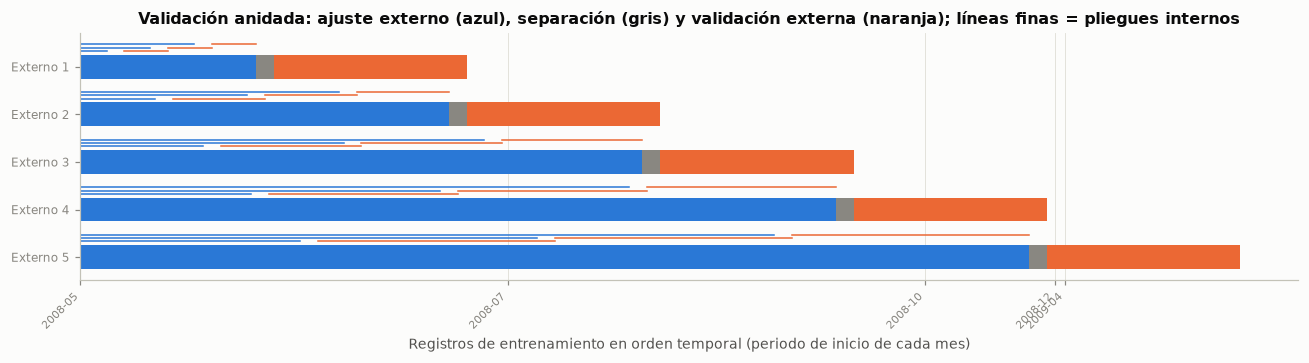

**Interpretación.** El ajuste externo crece de 4 983 a 26 943 registros y cada bloque de validación tiene 5 490. Los primeros pliegues validan dentro de 2008, con una prevalencia entre el 3,9 % y el 6,0 %, y el último valida de 2008-11 a 2009-05 con el 14,0 %.

Hay que tener en cuenta que los pliegues no son intercambiables: el último es el único que se parece a la prueba (2009-2010, prevalencia alta) y los de 2008 miden la capacidad de ordenar clientes en un régimen de tasa baja, donde el Entregable 2 ya mostró que casi ningún modelo discrimina. La media ± desviación estándar entre pliegues mezcla, entonces, variabilidad de muestreo y cambio de régimen.

Por lo anterior, conviene reportar siempre la media ± desviación estándar entre pliegues externos (sección 7.7), usar pruebas de rangos por pliegue, que no suponen bloques intercambiables en escala (sección 8), y contrastar las conclusiones con el conjunto de prueba.

In [42]:
filas = []
for k_, (i_e, i_v) in enumerate(cv_externa(GAP).split(X_tr), start=1):
    internos = list(cv_interna(GAP).split(i_e))
    filas.append({"Pliegue externo": k_, "Registros de ajuste": len(i_e), "Ajusta hasta": periodo_tr.iloc[i_e[-1]],
                  "Valida desde": periodo_tr.iloc[i_v[0]], "Valida hasta": periodo_tr.iloc[i_v[-1]],
                  "Registros de validación": len(i_v), "% positivos validación": 100 * y_tr.iloc[i_v].mean(),
                  "Ajuste interno (mín.–máx.)": f"{num(len(internos[0][0]))}–{num(len(internos[-1][0]))}",
                  "Validación interna": num(len(internos[0][1]))})
esquema_anidado = pd.DataFrame(filas).set_index("Pliegue externo")
tabla(esquema_anidado, dec=2)

fig, ax = plt.subplots(figsize=(12, 3.4))
for k_, (i_e, i_v) in enumerate(cv_externa(GAP).split(X_tr)):
    yk = cfg.K_EXTERNO - k_
    ax.barh(yk, len(i_e), left=0, color=AZUL, height=0.5)
    ax.barh(yk, GAP, left=i_e[-1] + 1, color=GRIS, height=0.5)
    ax.barh(yk, len(i_v), left=i_v[0], color=NARANJA, height=0.5)
    for j, (a_, b_) in enumerate(cv_interna(GAP).split(i_e)):
        ax.plot([a_[0], a_[-1]], [yk + 0.33 + 0.07 * j] * 2, color=AZUL, lw=1)
        ax.plot([b_[0], b_[-1]], [yk + 0.33 + 0.07 * j] * 2, color=NARANJA, lw=1)
ax.set_yticks(range(1, cfg.K_EXTERNO + 1), [f"Externo {cfg.K_EXTERNO - i}" for i in range(cfg.K_EXTERNO)])
cortes = [np.flatnonzero(periodo_tr.to_numpy() == p_)[0] for p_ in periodo_tr.unique()[::2]]
ax.set_xticks(cortes, periodo_tr.unique()[::2], rotation=45, ha="right", fontsize=7.5)
ax.set_xlabel("Registros de entrenamiento en orden temporal (periodo de inicio de cada mes)")
ax.set_title("Validación anidada: ajuste externo (azul), separación (gris) y validación externa (naranja); "
             "líneas finas = pliegues internos")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

interpretar(
    f"El ajuste externo crece de {num(esquema_anidado['Registros de ajuste'].iloc[0])} a "
    f"{num(esquema_anidado['Registros de ajuste'].iloc[-1])} registros y cada bloque de validación tiene "
    f"{num(esquema_anidado['Registros de validación'].iloc[0])}. Los primeros pliegues validan dentro de 2008, con una "
    f"prevalencia entre el {num(esquema_anidado['% positivos validación'].min(), 1)} % y el "
    f"{num(esquema_anidado['% positivos validación'].iloc[:-1].max(), 1)} %, y el último valida de "
    f"{esquema_anidado['Valida desde'].iloc[-1]} a {esquema_anidado['Valida hasta'].iloc[-1]} con el "
    f"{num(esquema_anidado['% positivos validación'].iloc[-1], 1)} %.",
    conectar("Hay que tener en cuenta que", "Los pliegues no son intercambiables: el último es el único que se parece a "
             "la prueba (2009-2010, prevalencia alta) y los de 2008 miden la capacidad de ordenar clientes en un régimen "
             "de tasa baja, donde el Entregable 2 ya mostró que casi ningún modelo discrimina. La media ± desviación "
             "estándar entre pliegues mezcla, entonces, variabilidad de muestreo y cambio de régimen."),
    conectar("Por lo anterior, conviene", "Reportar siempre la media ± desviación estándar entre pliegues externos "
             "(sección 7.7), usar pruebas de rangos por pliegue, que no suponen bloques intercambiables en escala "
             "(sección 8), y contrastar las conclusiones con el conjunto de prueba."))

exportar("esquema_anidado", esquema_anidado.reset_index())


### 4.4 Métrica de validación

**Criterio principal: AUC-PR (precisión promedio, `average_precision`).** Es la métrica que optimiza cada método en el bucle interno y la que ordena las combinaciones. La justificación sale del problema:

- La clase positiva es minoritaria (6,4 % en entrenamiento) y el uso del modelo es priorizar a quién llamar. Un **falso negativo** es un cliente que habría suscrito y no se llama (ingreso perdido); un **falso positivo** es una llamada sin éxito (unos minutos de un asesor). El costo del falso negativo es mayor, lo que favorece métricas centradas en la clase positiva.
- El AUC-ROC premia también el orden entre negativos y es poco sensible al desbalance; la curva precisión-recall describe directamente el compromiso entre encontrar suscriptores (*recall*) y no desperdiciar llamadas (*precision*), y es más informativa en clases desbalanceadas (Saito y Rehmsmeier, 2015).
- No depende de un umbral, así que permite comparar en igualdad de condiciones modelos con y sin balanceo (el balanceo desplaza las probabilidades) y modelos sin probabilidades (la SVM lineal usa su función de decisión).

Junto a ella se reportan accuracy, precision, recall, F1 (con el umbral por defecto del modelo: 0,5 en probabilidad o 0 en la función de decisión), AUC-ROC, Brier y pérdida logarítmica. El *recall* es la métrica de umbral que mejor refleja el costo del negocio, pero optimizarlo directamente favorecería al modelo que llama a todos; por eso se usa como métrica de contraste del balanceo (sección 7.2) y no como criterio de selección.

**Regresión:** RMSE en escala `log1p(duration)` (`neg_root_mean_squared_error`), que penaliza más los errores grandes en la planificación de la carga; el MAE y el error en segundos se reportan como complemento.

### 4.5 Reproducibilidad e ingeniería del *pipeline*

El código está separado en módulos con *docstrings* estilo NumPy para toda función reutilizada, y cada combinación se registra en la tabla maestra con sus hiperparámetros finales por pliegue, métricas del bucle externo, tiempos y semilla.

In [43]:
modulos = pd.DataFrame([
    ("src/bm/config.py", "Semilla global, rutas, variables, presupuesto y nombres de modelos, balanceos y optimizadores"),
    ("src/bm/datos.py", "Carga, reconstrucción del calendario, partición cronológica y esquemas de validación"),
    ("src/bm/preprocesamiento.py", "ColumnTransformer del Entregable 2 (escalado, log1p, pdays = 999, one-hot)"),
    ("src/bm/modelos.py", "Pipelines de imblearn: preprocesamiento → balanceo → modelo; equivalentes de class_weight"),
    ("src/bm/espacios.py", "Espacios de búsqueda compartidos y rejillas de Grid Search"),
    ("src/bm/optimizadores.py", "Evaluador común con presupuesto y registro anytime; Grid, Random, Optuna y DEAP"),
    ("src/bm/anidada.py", "Validación anidada por tarea, Successive Halving, consolidación de la tabla maestra"),
    ("src/bm/evaluacion.py", "Finalistas en prueba, calibración (Platt, isotónica, mensual) y diagnóstico de residuos"),
    ("src/bm/estadistica.py", "Friedman, Nemenyi, DeLong, BCa, Cliff, MCS, GW, Clark-West, DM-HLN, SPA"),
    ("src/bm/computacional.py", "Complejidad, escalamiento, paralelización y perfilamiento"),
    ("scripts/ejecutar_experimentos.py", "Ejecución paralela y reanudable de las 700 tareas (140 combinaciones × 5 pliegues)"),
    ("scripts/ejecutar_finales.py", "Finalistas, recalibración, sensibilidad a semillas y experimentos computacionales"),
], columns=["Módulo", "Responsabilidad"])
tabla(modulos, indice=False)
print("Columnas de la tabla maestra (resultados/tabla_maestra.csv y .parquet):")
print(", ".join(maestra.columns))
print(f"\nSemilla registrada en todas las combinaciones: {sorted(maestra['seed'].unique())}")

Módulo,Responsabilidad
src/bm/config.py,"Semilla global, rutas, variables, presupuesto y nombres de modelos, balanceos y optimizadores"
src/bm/datos.py,"Carga, reconstrucción del calendario, partición cronológica y esquemas de validación"
src/bm/preprocesamiento.py,"ColumnTransformer del Entregable 2 (escalado, log1p, pdays = 999, one-hot)"
src/bm/modelos.py,Pipelines de imblearn: preprocesamiento → balanceo → modelo; equivalentes de class_weight
src/bm/espacios.py,Espacios de búsqueda compartidos y rejillas de Grid Search
src/bm/optimizadores.py,"Evaluador común con presupuesto y registro anytime; Grid, Random, Optuna y DEAP"
src/bm/anidada.py,"Validación anidada por tarea, Successive Halving, consolidación de la tabla maestra"
src/bm/evaluacion.py,"Finalistas en prueba, calibración (Platt, isotónica, mensual) y diagnóstico de residuos"
src/bm/estadistica.py,"Friedman, Nemenyi, DeLong, BCa, Cliff, MCS, GW, Clark-West, DM-HLN, SPA"
src/bm/computacional.py,"Complejidad, escalamiento, paralelización y perfilamiento"


Columnas de la tabla maestra (resultados/tabla_maestra.csv y .parquet):
tarea, modelo, balanceo, optimizador, accuracy_media, precision_media, recall_media, f1_media, auc_media, auc_pr_media, brier_media, log_loss_media, rmse_media, mae_media, r2_media, rmse_seg_media, mae_seg_media, accuracy_de, precision_de, recall_de, f1_de, auc_de, auc_pr_de, brier_de, log_loss_de, rmse_de, mae_de, r2_de, rmse_seg_de, mae_seg_de, n_pliegues, n_eval_total, t_opt_total, t_por_eval, t_fit_medio, t_pred_medio, puntaje_interno_medio, seed, params_por_pliegue

Semilla registrada en todas las combinaciones: [np.int64(42)]


## 5. Optimización de hiperparámetros

### 5.1 Espacios de búsqueda

Cada modelo tiene **un único espacio de búsqueda, compartido por todos los optimizadores**, con a lo sumo cuatro hiperparámetros (los de mayor efecto documentado en el modelo) y rangos tomados de la práctica habitual y del Entregable 2, no arbitrarios. Las escalas son logarítmicas para `C`, `alpha`, `learning_rate`, `gamma`, `var_smoothing`, `min_samples_leaf` y el número de vecinos, porque su efecto es multiplicativo. Grid Search recorre una rejilla explícita de a lo sumo 20 puntos dentro del mismo espacio, de modo que todos los métodos tienen el mismo presupuesto de **20 configuraciones por pliegue externo**.

In [44]:
filas = []
for (t_, m_), esp in ESPACIOS.items():
    for n_, e in esp.items():
        nombre = n_.split("__")[-1]
        if e["tipo"] == "cat":
            rango, escala = enumerar(e["opciones"], codigo=False), "categórica"
        else:
            rango = f"[{num_c(e['bajo'])}; {num_c(e['alto'])}]"
            escala = ("log" if e["log"] else "lineal") + (", entera" if e["tipo"] == "int" else "")
        rej = REJILLAS[(t_, m_)][n_]
        filas.append({"Tarea": "Clasificación" if t_ == "clf" else "Regresión", "Modelo": NM[m_],
                      "Hiperparámetro": nombre, "Rango": rango, "Escala": escala,
                      "Rejilla (Grid Search)": enumerar([num_c(v) if isinstance(v, float) else v for v in rej],
                                                        codigo=False)})
tabla(pd.DataFrame(filas), indice=False)

just = pd.DataFrame([{"Modelo": NM[m_], "Puntos de la rejilla (clf / reg)":
                      " / ".join(str(n_puntos_rejilla(t_, m_)) for t_ in ("clf", "reg") if (t_, m_) in ESPACIOS),
                      "Justificación del espacio": JUSTIFICACION[m_]} for m_ in JUSTIFICACION])
tabla(just, indice=False)

exportar("espacios", pd.DataFrame(filas))
exportar("justificacion", just)


Tarea,Modelo,Hiperparámetro,Rango,Escala,Rejilla (Grid Search)
Clasificación,KNN,n_neighbors,[5; 300],"log, entera","5, 15, 40, 100 y 300"
Clasificación,KNN,weights,uniform y distance,categórica,uniform y distance
Clasificación,KNN,p,1 y 2,categórica,1 y 2
Clasificación,Naive Bayes,var_smoothing,[1e-12; 1],log,"1e-12, 4,28133e-12, 1,83298e-11, 7,8476e-11, 3,35982e-10, 1,43845e-09, 6,15848e-09, 2,63665e-08, 1,12884e-07, 4,83293e-07, 2,06914e-06, 8,85867e-06, 3,79269e-05, 0,000162378, 0,000695193, 0,00297635, 0,0127427, 0,0545559, 0,233572 y 1"
Clasificación,Logística L1/L2,C,"[0,0001; 100]",log,"0,0001, 0,000464159, 0,00215443, 0,01, 0,0464159, 0,215443, 1, 4,64159, 21,5443 y 100"
Clasificación,Logística L1/L2,l1_ratio,0.0 y 1.0,categórica,0 y 1
Clasificación,Árbol de decisión,max_depth,[2; 30],"lineal, entera","3, 5, 8, 12 y 20"
Clasificación,Árbol de decisión,min_samples_leaf,[1; 1000],"log, entera",5 y 50
Clasificación,Árbol de decisión,criterion,gini y entropy,categórica,gini y entropy
Clasificación,Random Forest,n_estimators,[50; 300],"lineal, entera",100 y 250


Modelo,Puntos de la rejilla (clf / reg),Justificación del espacio
KNN,20 / 20,"k de 5 a 300 en escala log: con miles de registros por pliegue, k pequeño sobreajusta y k cercano a 300 suaviza hacia la prevalencia; ponderación uniforme o por distancia y métrica Manhattan (p = 1) o euclídea (p = 2), relevante con decenas de columnas binarias."
Naive Bayes,20,var_smoothing de 1e-12 a 1 (log): las columnas one-hot tienen varianzas casi nulas dentro de una clase y el suavizado controla esa inestabilidad; es el único hiperparámetro continuo.
Logística L1/L2,20,"C de 1e-4 a 100 (log), el rango donde la logística pasa de casi constante a casi sin penalizar (en el Entregable 2 el óptimo por log-loss fue 0,01); penalización L1 o L2 vía l1_ratio."
Árbol de decisión,20 / 20,"Profundidad de 2 a 30 y hojas de 1 a 1000 registros (log): controlan el sesgo-varianza del árbol, que sin restricciones memoriza el entrenamiento; criterio o fracción de variables por división."
Random Forest,16 / 16,"50 a 300 árboles (más árboles no cambian el sesgo y encarecen), profundidad 3 a 30, hojas 1 a 200 (log) y fracción de variables por división, el principal mecanismo de decorrelación."
XGBoost,16 / 16,"Tasa de aprendizaje 0,01 a 0,3 (log) y número de árboles 50 a 500, que interactúan (menor tasa, más árboles); profundidad 2 a 10 y submuestreo 0,5 a 1 como regularización estocástica."
SVM,18,"Núcleo RBF aproximado con Nyström (100 a 600 componentes) y SVM lineal: gamma de 1e-3 a 1 y C de 1e-3 a 10 en escala log, con la interacción C × gamma típica del núcleo gaussiano."
Ridge,20,alpha de 1e-3 a 1e4 (log): desde casi mínimos cuadrados hasta una contracción fuerte.
Lasso,20,alpha de 1e-5 a 1 (log): por encima de 1 el Lasso anula todos los coeficientes con el objetivo estandarizado en escala log.
SVR,18,"Nyström RBF (300 componentes) con SVR lineal sobre el objetivo estandarizado: gamma y C en escala log y epsilon de 0 a 0,5 desviaciones estándar del objetivo."


### 5.2 Métodos de optimización y su justificación

Todos los métodos llaman al mismo evaluador (`src/bm/optimizadores.py`), que ajusta el `Pipeline` completo (preprocesamiento, balanceo y modelo) **dentro de cada pliegue interno**; así, Optuna y DEAP, que no integran esa funcionalidad, tampoco tienen fuga de información. El evaluador cuenta como presupuesto las configuraciones distintas (las repetidas salen de un caché) y registra cada evaluación con su tiempo de pared para las curvas *anytime*.

**Grid Search.** Recorre la rejilla en orden. Garantiza cobertura uniforme de los valores elegidos, pero el número de puntos crece como el producto de los niveles y desperdicia evaluaciones en dimensiones poco influyentes (Bergstra y Bengio, 2012).

**Random Search.** Muestrea el espacio continuo de forma uniforme (log-uniforme en las escalas logarítmicas). Con el mismo presupuesto explora más valores distintos de cada hiperparámetro que la rejilla, que es lo que importa cuando solo unos pocos hiperparámetros son relevantes.

**Optimización bayesiana (Optuna).**

- *Modelo sustituto:* **Tree-structured Parzen Estimator (TPE)** (Bergstra et al., 2011). En lugar de modelar p(y | x) como un proceso gaussiano, TPE divide las configuraciones evaluadas por el cuantil γ de la métrica y estima dos densidades: l(x) con las buenas y g(x) con las demás. Se prefiere al proceso gaussiano porque maneja de forma natural hiperparámetros enteros, categóricos y en escala log, y su costo crece de forma lineal con el número de evaluaciones.
- *Función de adquisición:* **Mejora Esperada (Expected Improvement, EI)**. Bajo TPE, maximizar la EI equivale a maximizar el cociente l(x)/g(x); Optuna lo evalúa en 24 candidatos muestreados de l(x) y elige el de mayor cociente.
- *Exploración y explotación:* las 5 primeras configuraciones son aleatorias (exploración pura, para tener con qué estimar las densidades). Después, la EI privilegia la **explotación** de las regiones con alta densidad de buenas configuraciones, y la exploración se mantiene porque los candidatos se muestrean de l(x), que tiene colas, y porque g(x) penaliza solo las regiones ya evaluadas como malas.

**Algoritmo genético (DEAP).** Cada individuo es un vector de genes en [0, 1] que se decodifica al espacio de búsqueda (escala log, enteros y tramos iguales para las categóricas).

- *Selección:* **torneo de tamaño 3**, que mantiene una presión selectiva moderada y no depende de la escala de la métrica (a diferencia de la ruleta).
- *Cruce:* **binario simulado acotado (SBX, η = 15)** con probabilidad **0,7**, diseñado para genes reales (Deb y Agrawal, 1995): los hijos quedan cerca de los padres con una dispersión controlada por η.
- *Mutación:* **polinomial acotada (η = 20)** con probabilidad **0,3** por individuo y **1/d** por gen.
- *Elitismo y población:* el **mejor individuo** pasa intacto a la siguiente generación y la población es de **6 individuos**. Con un presupuesto de 20 configuraciones, una población mayor dejaría muy pocas generaciones con individuos nuevos; con 6, la población inicial consume 6 evaluaciones y las generaciones siguientes se suceden hasta agotar las 14 restantes. Como los clones de individuos ya evaluados no consumen presupuesto, el número de generaciones crece cuando la población converge (hasta un tope de 50).
- *Diversidad genética:* se registra en cada generación la distancia euclídea media entre individuos, normalizada por √d (sección 5.6).

**Multi-fidelidad: Successive Halving (técnica adicional).** Para Random Forest y XGBoost sin balanceo se implementa `HalvingRandomSearchCV` con el **número de árboles como fidelidad**: 27 configuraciones aleatorias se evalúan con un noveno del máximo de árboles, sobrevive un tercio (**factor de reducción 3**) con el triple de árboles y así hasta el máximo. El número de árboles es una fidelidad natural porque el desempeño de un *ensemble* con pocos árboles está fuertemente correlacionado con el que alcanza con muchos, y el costo crece de forma lineal con ellos; el factor 3 es el valor por defecto de Hyperband (Li et al., 2018) y da tres rondas con el rango de árboles de cada modelo.

### 5.3 Comparación de los métodos en el bucle externo

La comparación se hace en tres niveles: la métrica del bucle externo, el costo (tiempo total, tiempo por evaluación y número de evaluaciones) y la prueba de Friedman con bloques = (modelo, balanceo, pliegue externo), que compara los optimizadores dentro de cada bloque y elimina la variación entre modelos.

In [45]:
NUCLEO = ["grid", "random", "bayes", "genetico"]
clf_pl, reg_pl = pliegues[pliegues["tarea"] == "clf"], pliegues[pliegues["tarea"] == "reg"]


def resumen_optimizadores(df, metrica, orden):
    g = df.groupby("optimizador")
    salida = pd.DataFrame({
        "Métrica externa (media ± DE)": g[metrica].apply(ms),
        "Evaluaciones por pliegue": g["n_eval"].mean(), "Evaluaciones (total)": g["n_eval"].sum(),
        "Tiempo total (min)": g["t_opt"].sum() / 60, "Tiempo por evaluación (s)": g["t_por_eval"].mean(),
        "Pliegues": g.size()})
    salida.index = [NO[o] for o in salida.index]
    return salida.loc[[NO[o] for o in orden if NO[o] in salida.index]]


def friedman_optimizadores(df, metrica, orden, signo=1):
    mat = df.pivot_table(index=["modelo", "balanceo", "pliegue"], columns="optimizador", values=metrica)[orden]
    return st.friedman(signo * mat.dropna())


print("Clasificación: AUC-PR del bucle externo, 4 métodos de la guía en los 28 pares modelo-balanceo")
tabla(resumen_optimizadores(clf_pl[clf_pl["optimizador"].isin(NUCLEO)], "auc_pr", NUCLEO), dec=3)
print("Regresión: RMSE del bucle externo (escala log), 4 métodos en los 7 modelos")
tabla(resumen_optimizadores(reg_pl[reg_pl["optimizador"].isin(NUCLEO)], "rmse", NUCLEO), dec=4)

fr_clf = friedman_optimizadores(clf_pl[clf_pl["optimizador"].isin(NUCLEO)], "auc_pr", NUCLEO)
fr_reg = friedman_optimizadores(reg_pl[reg_pl["optimizador"].isin(NUCLEO)], "rmse", NUCLEO, signo=-1)
tabla(pd.DataFrame({
    "Tarea": ["Clasificación (AUC-PR)", "Regresión (−RMSE)"],
    "Bloques": [fr_clf["n_bloques"], fr_reg["n_bloques"]],
    "χ² de Friedman": [fr_clf["chi2"], fr_reg["chi2"]], "g. l.": [fr_clf["gl"], fr_reg["gl"]],
    "Valor p": [pval(fr_clf["p"]), pval(fr_reg["p"])],
    "Rangos promedio (1 = mejor)": ["; ".join(f"{NO[o]} {num(r_, 2)}" for o, r_ in fr["rangos"].items())
                                    for fr in (fr_clf, fr_reg)]}), indice=False)

res_clf = resumen_optimizadores(clf_pl[clf_pl["optimizador"].isin(NUCLEO)], "auc_pr", NUCLEO)
mejor_rango = fr_clf["rangos"].index[0]
t_min = res_clf["Tiempo por evaluación (s)"]
interpretar(
    f"En clasificación, el AUC-PR externo promedio de los cuatro métodos va de "
    f"{num(clf_pl[clf_pl['optimizador'].isin(NUCLEO)].groupby('optimizador')['auc_pr'].mean().min(), 3)} a "
    f"{num(clf_pl[clf_pl['optimizador'].isin(NUCLEO)].groupby('optimizador')['auc_pr'].mean().max(), 3)}, y la prueba de "
    f"Friedman sobre {fr_clf['n_bloques']} bloques da χ² = {num(fr_clf['chi2'], 2)} ({p_txt(fr_clf['p'])}); el mejor "
    f"rango promedio es el de {NO[mejor_rango]} ({num(fr_clf['rangos'].iloc[0], 2)}). En regresión, Friedman da "
    f"χ² = {num(fr_reg['chi2'], 2)} ({p_txt(fr_reg['p'])}). El tiempo por evaluación va de {num(t_min.min(), 2)} s "
    f"({t_min.idxmin()}) a {num(t_min.max(), 2)} s ({t_min.idxmax()}).",
    ("Esto significa que, con el mismo presupuesto de 20 configuraciones, el método de búsqueda cambia de forma "
     "sistemática la calidad del modelo que llega al bucle externo, aunque la diferencia es pequeña frente a la que "
     "hay entre modelos (sección 7). " if fr_clf["p"] < 0.05 else
     "Esto significa que, con el mismo presupuesto de 20 configuraciones, no hay evidencia de que el método de "
     "búsqueda cambie la calidad del modelo en el bucle externo: las diferencias entre métodos son menores que la "
     "variación entre bloques. ")
    + "Las diferencias de tiempo por evaluación reflejan qué regiones del espacio visita cada método (por ejemplo, "
      "bosques con más árboles), no el costo propio del optimizador, que es despreciable frente al ajuste de los modelos.",
    conectar("Por lo anterior, conviene", "Juzgar la eficiencia no solo por el valor final sino por la rapidez con que "
             "cada método llega a buenas soluciones (curvas *anytime*, secciones 5.4 y 5.5), que es donde la teoría "
             "predice la ventaja de los métodos bayesiano y genético."))

exportar("opt_clf", resumen_optimizadores(clf_pl[clf_pl["optimizador"].isin(NUCLEO)], "auc_pr", NUCLEO).reset_index())
exportar("opt_reg", resumen_optimizadores(reg_pl[reg_pl["optimizador"].isin(NUCLEO)], "rmse", NUCLEO).reset_index())
exportar("friedman_opt", {"clf": {"chi2": fr_clf["chi2"], "p": fr_clf["p"], "n": fr_clf["n_bloques"],
                                  "rangos": {NO[k]: v for k, v in fr_clf["rangos"].items()}},
                          "reg": {"chi2": fr_reg["chi2"], "p": fr_reg["p"], "n": fr_reg["n_bloques"],
                                  "rangos": {NO[k]: v for k, v in fr_reg["rangos"].items()}}})


Clasificación: AUC-PR del bucle externo, 4 métodos de la guía en los 28 pares modelo-balanceo


,Métrica externa (media ± DE),Evaluaciones por pliegue,Evaluaciones (total),Tiempo total (min),Tiempo por evaluación (s),Pliegues
Grid Search,"0,085 ± 0,065","18,571",2 600,"328,079","7,918",140
Random Search,"0,084 ± 0,064","20,000",2 800,"405,385","8,687",140
Bayesiana (Optuna TPE),"0,084 ± 0,065","20,000",2 800,"390,933","8,369",140
Genético (DEAP),"0,085 ± 0,066","19,857",2 780,"448,661","9,644",140


Regresión: RMSE del bucle externo (escala log), 4 métodos en los 7 modelos


,Métrica externa (media ± DE),Evaluaciones por pliegue,Evaluaciones (total),Tiempo total (min),Tiempo por evaluación (s),Pliegues
Grid Search,"0,916 ± 0,034","18,5714",650,"50,3962","4,9117",35
Random Search,"0,917 ± 0,032","20,0000",700,"57,6188","4,9386",35
Bayesiana (Optuna TPE),"0,917 ± 0,034","20,0000",700,"53,9244","4,6141",35
Genético (DEAP),"0,915 ± 0,033","20,0000",700,"59,0997","5,0648",35


Tarea,Bloques,χ² de Friedman,g. l.,Valor p,Rangos promedio (1 = mejor)
Clasificación (AUC-PR),140,"9,338",3,"0,025","Grid Search 2,23; Bayesiana (Optuna TPE) 2,52; Genético (DEAP) 2,56; Random Search 2,69"
Regresión (−RMSE),35,"0,914",3,"0,822","Grid Search 2,34; Genético (DEAP) 2,49; Bayesiana (Optuna TPE) 2,54; Random Search 2,63"


**Interpretación.** En clasificación, el AUC-PR externo promedio de los cuatro métodos va de 0,084 a 0,085, y la prueba de Friedman sobre 140 bloques da χ² = 9,34 (p = 0,025); el mejor rango promedio es el de Grid Search (2,23). En regresión, Friedman da χ² = 0,91 (p = 0,822). El tiempo por evaluación va de 7,92 s (Grid Search) a 9,64 s (Genético (DEAP)).

Esto significa que, con el mismo presupuesto de 20 configuraciones, el método de búsqueda cambia de forma sistemática la calidad del modelo que llega al bucle externo, aunque la diferencia es pequeña frente a la que hay entre modelos (sección 7). Las diferencias de tiempo por evaluación reflejan qué regiones del espacio visita cada método (por ejemplo, bosques con más árboles), no el costo propio del optimizador, que es despreciable frente al ajuste de los modelos.

Por lo anterior, conviene juzgar la eficiencia no solo por el valor final sino por la rapidez con que cada método llega a buenas soluciones (curvas *anytime*, secciones 5.4 y 5.5), que es donde la teoría predice la ventaja de los métodos bayesiano y genético.

### 5.4 Convergencia: curvas de desempeño en cualquier momento (*anytime*)

Para cada bloque (tarea, modelo, balanceo, pliegue externo) se registra el mejor puntaje de validación interna encontrado hasta la evaluación *t*. Para promediar bloques con escalas distintas, el puntaje se normaliza dentro del bloque entre el peor y el mejor valor que encontró **cualquier** método: 1 significa haber llegado al mejor valor conocido del bloque. La curva frente al tiempo usa el tiempo acumulado relativo al método más lento del bloque.

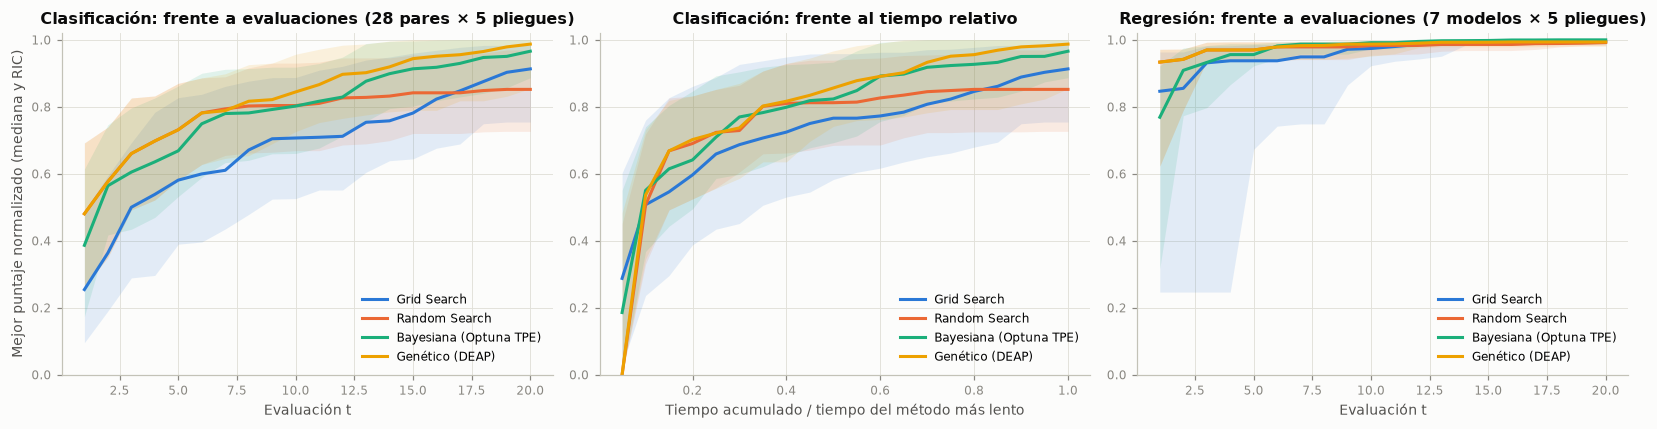

**Interpretación.** En la mediana de los bloques de clasificación, el puntaje normalizado llega a 0,9 en la evaluación 19 con Grid Search; nunca (en 20) con Random Search; 15 con Bayesiana (Optuna TPE); 13 con Genético (DEAP). Tras 5 evaluaciones, la mediana es de 0,58 (Grid Search), 0,73 (Random Search), 0,67 (Bayesiana (Optuna TPE)) y 0,73 (Genético (DEAP)); al final del presupuesto, de 0,91 (Grid Search), 0,85 (Random Search), 0,97 (Bayesiana (Optuna TPE)) y 0,99 (Genético (DEAP)).

Hay que tener en cuenta que las cinco primeras evaluaciones de Optuna son aleatorias, así que su curva solo puede separarse de la de Random Search a partir de la sexta; el genético tampoco puede mejorar antes de completar la población inicial de seis individuos. La forma de las curvas, más que su punto final, muestra cuánto presupuesto necesita cada método para llegar a una buena región.

De ahí que se opte por cuantificar esa diferencia con el área bajo la curva *anytime* y con las evaluaciones necesarias para llegar al 99 % del mejor valor (sección 5.5), y probarla estadísticamente.

In [46]:
T = cfg.PRESUPUESTO
h = historial.copy()
h["bloque"] = h["tarea"] + "|" + h["modelo"] + "|" + h["balanceo"] + "|" + h["pliegue"].astype(str)
finito = h[np.isfinite(h["puntaje"])]
ref = finito.groupby("bloque")["puntaje"].agg(ref_max="max", ref_min="min")
T_bloque = h.groupby(["bloque", "optimizador"])["t_acum"].max().groupby("bloque").max()
REJ_TAU = np.linspace(0.05, 1, 20)

curvas, curvas_t, eficiencia = {}, {}, []
for (b_, o_), g in h.groupby(["bloque", "optimizador"]):
    lo, hi = ref.loc[b_, "ref_min"], ref.loc[b_, "ref_max"]
    rango = hi - lo if hi > lo else 1.0
    mejor = g.set_index("n")["mejor"].reindex(range(1, T + 1)).ffill().replace(-np.inf, np.nan).fillna(lo)
    norm = ((mejor - lo) / rango).clip(0, 1).to_numpy()
    curvas[(b_, o_)] = norm
    tt = g["t_acum"].to_numpy() / T_bloque.loc[b_]
    mt = np.array([g["mejor"][tt <= tau].max() if (tt <= tau).any() else lo for tau in REJ_TAU])
    curvas_t[(b_, o_)] = np.clip((np.where(np.isfinite(mt), mt, lo) - lo) / rango, 0, 1)
    tarea_ = b_.split("|")[0]
    alcanza = (mejor >= 0.99 * hi) if tarea_ == "clf" else (-mejor <= 1.01 * -hi)
    eficiencia.append({"bloque": b_, "tarea": tarea_, "modelo": b_.split("|")[1], "optimizador": o_,
                       "AUAC evaluaciones": norm.mean(), "AUAC tiempo": curvas_t[(b_, o_)].mean(),
                       "Final normalizado": norm[-1],
                       "Evaluaciones al 99 %": int(np.argmax(alcanza.to_numpy())) + 1 if alcanza.any() else np.nan,
                       "Tiempo total (s)": g["t_acum"].max()})
eficiencia = pd.DataFrame(eficiencia)


def banda(ax, claves, x, opt, matriz):
    M = np.vstack([matriz[c] for c in claves])
    ax.plot(x, np.median(M, axis=0), color=COLOR_OPT[opt], label=NO[opt])
    ax.fill_between(x, np.quantile(M, 0.25, axis=0), np.quantile(M, 0.75, axis=0), color=COLOR_OPT[opt], alpha=0.12,
                    lw=0)


fig, axs = plt.subplots(1, 3, figsize=(15, 4))
bloques_clf = [b_ for b_ in ref.index if b_.startswith("clf")]
bloques_reg = [b_ for b_ in ref.index if b_.startswith("reg")]
for o_ in NUCLEO:
    banda(axs[0], [(b_, o_) for b_ in bloques_clf], np.arange(1, T + 1), o_, curvas)
    banda(axs[1], [(b_, o_) for b_ in bloques_clf], REJ_TAU, o_, curvas_t)
    banda(axs[2], [(b_, o_) for b_ in bloques_reg], np.arange(1, T + 1), o_, curvas)
axs[0].set(title="Clasificación: frente a evaluaciones (28 pares × 5 pliegues)", xlabel="Evaluación t",
           ylabel="Mejor puntaje normalizado (mediana y RIC)")
axs[1].set(title="Clasificación: frente al tiempo relativo", xlabel="Tiempo acumulado / tiempo del método más lento")
axs[2].set(title="Regresión: frente a evaluaciones (7 modelos × 5 pliegues)", xlabel="Evaluación t")
for ax in axs:
    ax.set_ylim(0, 1.02)
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

med = {o_: np.median(np.vstack([curvas[(b_, o_)] for b_ in bloques_clf]), axis=0) for o_ in NUCLEO}
t90 = {o_: (int(np.argmax(med[o_] >= 0.9)) + 1 if (med[o_] >= 0.9).any() else None) for o_ in NUCLEO}
interpretar(
    "En la mediana de los bloques de clasificación, el puntaje normalizado llega a 0,9 en la evaluación "
    + "; ".join(f"{t90[o_] if t90[o_] else 'nunca (en 20)'} con {NO[o_]}" for o_ in NUCLEO)
    + f". Tras 5 evaluaciones, la mediana es de {enumerar([num(med[o_][4], 2) + ' (' + NO[o_] + ')' for o_ in NUCLEO], codigo=False)}; "
    f"al final del presupuesto, de {enumerar([num(med[o_][-1], 2) + ' (' + NO[o_] + ')' for o_ in NUCLEO], codigo=False)}.",
    conectar("Hay que tener en cuenta que", "Las cinco primeras evaluaciones de Optuna son aleatorias, así que su curva "
             "solo puede separarse de la de Random Search a partir de la sexta; el genético tampoco puede mejorar antes "
             "de completar la población inicial de seis individuos. La forma de las curvas, más que su punto final, "
             "muestra cuánto presupuesto necesita cada método para llegar a una buena región."),
    conectar("De ahí que se opte por", "Cuantificar esa diferencia con el área bajo la curva *anytime* y con las "
             "evaluaciones necesarias para llegar al 99 % del mejor valor (sección 5.5), y probarla estadísticamente."))

filas_any = []
for t_, bloques_t in (("clf", bloques_clf), ("reg", bloques_reg)):
    for o_ in NUCLEO:
        for eje, x, mat in (("evaluaciones", np.arange(1, T + 1), curvas), ("tiempo", REJ_TAU, curvas_t)):
            M = np.vstack([mat[(b_, o_)] for b_ in bloques_t])
            for xi, me, q1, q3 in zip(x, np.median(M, 0), np.quantile(M, .25, 0), np.quantile(M, .75, 0)):
                filas_any.append({"grupo": t_, "optimizador": NO[o_], "eje": eje, "x": float(xi), "mediana": me,
                                  "q1": q1, "q3": q3})
exportar("anytime", pd.DataFrame(filas_any))


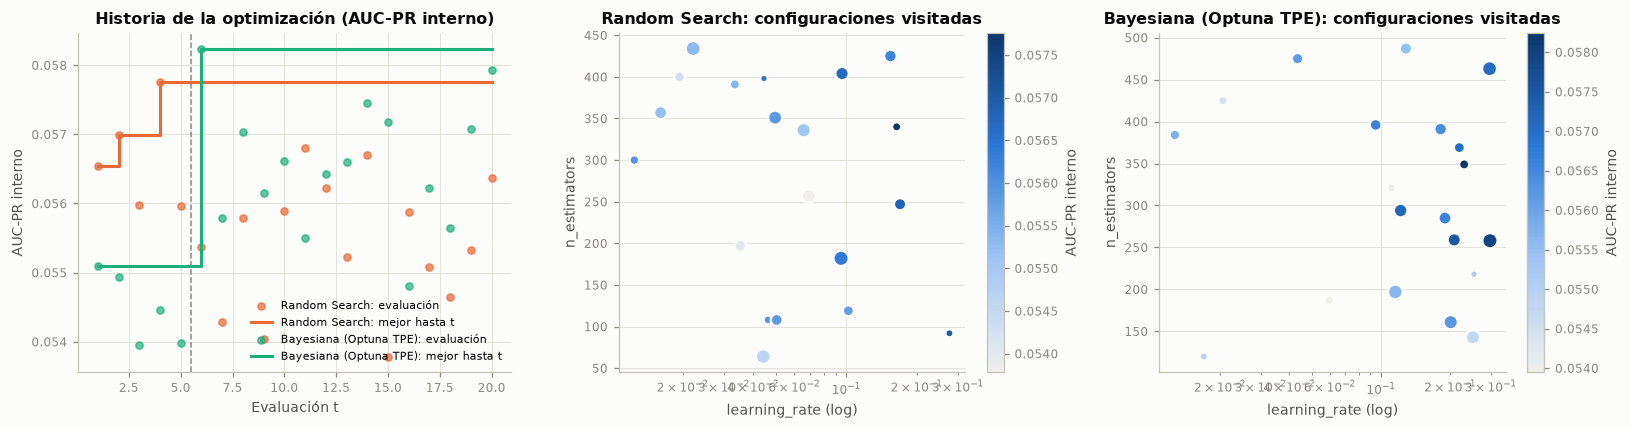

El tamaño del punto crece con el orden de la evaluación; la línea discontinua marca el fin de la fase aleatoria de TPE.


In [47]:
# Historia de Optuna y regiones visitadas: XGBoost sin balanceo, último pliegue externo
b_ej = "clf|xgboost|ninguno|4"
ej = h[h["bloque"] == b_ej]
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for o_ in ["random", "bayes"]:
    g = ej[ej["optimizador"] == o_]
    axs[0].scatter(g["n"], g["puntaje"], s=22, color=COLOR_OPT[o_], alpha=0.7, label=f"{NO[o_]}: evaluación")
    axs[0].step(g["n"], g["mejor"], where="post", color=COLOR_OPT[o_], lw=2, label=f"{NO[o_]}: mejor hasta t")
axs[0].axvline(5.5, color=GRIS, lw=1, ls="--")
axs[0].set(title="Historia de la optimización (AUC-PR interno)", xlabel="Evaluación t", ylabel="AUC-PR interno")
axs[0].legend(fontsize=7)
for ax, o_ in zip(axs[1:], ["random", "bayes"]):
    g = ej[ej["optimizador"] == o_]
    pr = pd.DataFrame([json.loads(p_) for p_ in g["params"]])
    sc = ax.scatter(pr["modelo__learning_rate"], pr["modelo__n_estimators"], c=g["puntaje"].to_numpy(), cmap=CMAP_SEQ,
                    s=20 + 4 * g["n"].to_numpy(), edgecolor=FONDO, lw=1.5)
    ax.set_xscale("log")
    ax.set(title=f"{NO[o_]}: configuraciones visitadas", xlabel="learning_rate (log)", ylabel="n_estimators")
    fig.colorbar(sc, ax=ax, label="AUC-PR interno")
plt.tight_layout()
plt.show()
print("El tamaño del punto crece con el orden de la evaluación; la línea discontinua marca el fin de la fase aleatoria de TPE.")

exportar("optuna_ejemplo", ej[["optimizador", "n", "puntaje", "mejor", "params"]].assign(optimizador=lambda d: d["optimizador"].map(NO)))


### 5.5 Eficiencia: calidad por unidad de presupuesto

La guía pide demostrar con evidencia cuantitativa, y no solo visual, si los métodos bayesiano y genético son más eficientes que Grid y Random Search. Para cada bloque y método se calculan tres indicadores: el **área bajo la curva *anytime*** frente a evaluaciones y frente al tiempo (promedio del puntaje normalizado; 1 = llegar al mejor valor desde la primera evaluación), y las **evaluaciones necesarias para alcanzar el 99 % del mejor valor** del bloque. Las diferencias se prueban con Friedman sobre los bloques, con comparaciones de Wilcoxon por pares ajustadas por Holm y con el delta de Cliff como tamaño de efecto.

In [48]:
from scipy.stats import wilcoxon

ef = eficiencia[eficiencia["optimizador"].isin(NUCLEO)]
for tarea_, nombre in (("clf", "Clasificación"), ("reg", "Regresión")):
    e_ = ef[ef["tarea"] == tarea_]
    res = e_.groupby("optimizador").agg(**{
        "AUAC evaluaciones": ("AUAC evaluaciones", "mean"), "AUAC tiempo": ("AUAC tiempo", "mean"),
        "Final normalizado": ("Final normalizado", "mean"),
        "% de bloques que llega al 99 %": ("Evaluaciones al 99 %", lambda s: 100 * s.notna().mean()),
        "Evaluaciones al 99 % (mediana)": ("Evaluaciones al 99 %", "median")}).loc[NUCLEO]
    res.index = [NO[o] for o in res.index]
    print(nombre)
    tabla(res, dec=3)

e_clf = ef[ef["tarea"] == "clf"]
mat_auac = e_clf.pivot(index="bloque", columns="optimizador", values="AUAC evaluaciones")[NUCLEO]
mat_auac_t = e_clf.pivot(index="bloque", columns="optimizador", values="AUAC tiempo")[NUCLEO]
fr_auac, fr_auac_t = st.friedman(mat_auac), st.friedman(mat_auac_t)
pares = [("bayes", "grid"), ("bayes", "random"), ("genetico", "grid"), ("genetico", "random"), ("bayes", "genetico"),
         ("random", "grid")]
filas = []
for a_, b2 in pares:
    for nombre, M in (("evaluaciones", mat_auac), ("tiempo", mat_auac_t)):
        w = wilcoxon(M[a_], M[b2])
        filas.append({"Comparación": f"{NO[a_]} vs {NO[b2]}", "AUAC frente a": nombre,
                      "Diferencia media": (M[a_] - M[b2]).mean(), "p crudo": w.pvalue,
                      "delta de Cliff": st.delta_cliff(M[a_], M[b2])})
comp_ef = pd.DataFrame(filas)
comp_ef["p Holm"] = np.nan
for nombre in ("evaluaciones", "tiempo"):
    m_ = comp_ef["AUAC frente a"] == nombre
    comp_ef.loc[m_, "p Holm"] = st.ajustar_p(comp_ef.loc[m_, "p crudo"], "holm")
comp_ef["Magnitud"] = comp_ef["delta de Cliff"].apply(st.magnitud_cliff)
print(f"Friedman sobre el AUAC (clasificación, {fr_auac['n_bloques']} bloques): frente a evaluaciones "
      f"χ² = {num(fr_auac['chi2'], 2)}, {p_txt(fr_auac['p'])}; frente al tiempo χ² = {num(fr_auac_t['chi2'], 2)}, "
      f"{p_txt(fr_auac_t['p'])}")
tabla(comp_ef.assign(**{"p crudo": comp_ef["p crudo"].map(pval), "p Holm": comp_ef["p Holm"].map(pval)}), dec=3,
      indice=False)

auac_m = mat_auac.mean()
sig = comp_ef[(comp_ef["AUAC frente a"] == "evaluaciones") & (comp_ef["p Holm"] < 0.05)]
b_vs = comp_ef[(comp_ef["AUAC frente a"] == "evaluaciones") & comp_ef["Comparación"].str.startswith(NO["bayes"])]
g_vs = comp_ef[(comp_ef["AUAC frente a"] == "evaluaciones") & comp_ef["Comparación"].str.startswith(NO["genetico"])]
interpretar(
    f"El área bajo la curva *anytime* frente a evaluaciones es de "
    f"{enumerar([num(auac_m[o_], 3) + ' (' + NO[o_] + ')' for o_ in NUCLEO], codigo=False)}; Friedman da "
    f"{p_txt(fr_auac['p'])} frente a evaluaciones y {p_txt(fr_auac_t['p'])} frente al tiempo. Frente a Grid y Random "
    f"Search, el delta de Cliff de la optimización bayesiana es de "
    f"{enumerar([num(d_, 2) for d_ in b_vs['delta de Cliff'].iloc[:2]], codigo=False)} y el del genético de "
    f"{enumerar([num(d_, 2) for d_ in g_vs['delta de Cliff'].iloc[:2]], codigo=False)}; "
    f"{len(sig)} de las {len(pares)} comparaciones por pares son significativas tras el ajuste de Holm.",
    conectar("Esto quiere decir que", (
        f"Frente a Grid Search la ventaja de los métodos adaptativos es clara (efecto {st.magnitud_cliff(b_vs['delta de Cliff'].iloc[0])} "
        f"en la bayesiana y {st.magnitud_cliff(g_vs['delta de Cliff'].iloc[0])} en el genético, según el delta de Cliff): la "
        "rejilla gasta las primeras evaluaciones en combinaciones fijas, a menudo en regiones malas, mientras que los "
        "métodos adaptativos usan las evaluaciones anteriores para concentrar el presupuesto. "
        if (b_vs["Diferencia media"].iloc[0] > 0 and g_vs["Diferencia media"].iloc[0] > 0) else
        "Frente a Grid Search no hay una ventaja uniforme de los métodos adaptativos. ")
        + (f"Frente a Random Search, en cambio, el efecto es {st.magnitud_cliff(b_vs['delta de Cliff'].iloc[1])} en la "
           f"bayesiana y {st.magnitud_cliff(g_vs['delta de Cliff'].iloc[1])} en el genético: la fase inicial aleatoria (5 "
           "evaluaciones en Optuna, 6 en el genético) consume una parte grande de un presupuesto de 20, y en espacios de "
           "dos a cuatro dimensiones el muestreo aleatorio ya cubre bien las regiones relevantes. La magnitud del efecto, "
           "y no solo el valor p, es la que indica si la diferencia importa en la práctica.")),
    conectar("Así las cosas, se decide", "Interpretar la eficiencia como un resultado condicionado al presupuesto y a la "
             "dimensión del espacio: con espacios de mayor dimensión o presupuestos mayores, la teoría y la literatura "
             "predicen que la ventaja de TPE crece (Bergstra et al., 2011), algo que este diseño no alcanza a medir."))

exportar("eficiencia", pd.concat([ef[ef["tarea"] == t_].groupby("optimizador")[["AUAC evaluaciones", "AUAC tiempo",
         "Final normalizado"]].mean().assign(tarea=t_).rename(index=NO) for t_ in ("clf", "reg")]).reset_index())
exportar("eficiencia_pruebas", comp_ef)


Clasificación


,AUAC evaluaciones,AUAC tiempo,Final normalizado,% de bloques que llega al 99 %,Evaluaciones al 99 % (mediana)
Grid Search,"0,670","0,706","0,847","52,143","12,000"
Random Search,"0,753","0,741","0,830","41,429","5,500"
Bayesiana (Optuna TPE),"0,773","0,777","0,920","66,429","11,000"
Genético (DEAP),"0,781","0,768","0,895","68,571","9,000"


Regresión


,AUAC evaluaciones,AUAC tiempo,Final normalizado,% de bloques que llega al 99 %,Evaluaciones al 99 % (mediana)
Grid Search,"0,842","0,830","0,990","97,143","1,000"
Random Search,"0,949","0,931","0,982","97,143","1,000"
Bayesiana (Optuna TPE),"0,943","0,926","0,993","100,000","1,000"
Genético (DEAP),"0,954","0,940","0,986","100,000","1,000"


Friedman sobre el AUAC (clasificación, 140 bloques): frente a evaluaciones χ² = 43,99, p < 0,001; frente al tiempo χ² = 23,94, p < 0,001


Comparación,AUAC frente a,Diferencia media,p crudo,delta de Cliff,p Holm,Magnitud
Bayesiana (Optuna TPE) vs Grid Search,evaluaciones,"0,103","< 0,001","0,329","< 0,001",pequeño
Bayesiana (Optuna TPE) vs Grid Search,tiempo,"0,071","< 0,001","0,186","< 0,001",pequeño
Bayesiana (Optuna TPE) vs Random Search,evaluaciones,"0,020","0,130","0,043","0,261",despreciable
Bayesiana (Optuna TPE) vs Random Search,tiempo,"0,036","0,013","0,124","0,038",despreciable
Genético (DEAP) vs Grid Search,evaluaciones,"0,112","< 0,001","0,338","< 0,001",mediano
Genético (DEAP) vs Grid Search,tiempo,"0,061","0,008","0,158","0,031",pequeño
Genético (DEAP) vs Random Search,evaluaciones,"0,028","< 0,001","0,127","< 0,001",despreciable
Genético (DEAP) vs Random Search,tiempo,"0,027","< 0,001","0,129","0,002",despreciable
Bayesiana (Optuna TPE) vs Genético (DEAP),evaluaciones,"-0,008","0,662","-0,104","0,662",despreciable
Bayesiana (Optuna TPE) vs Genético (DEAP),tiempo,"0,009","0,628","-0,031","0,628",despreciable


**Interpretación.** El área bajo la curva *anytime* frente a evaluaciones es de 0,670 (Grid Search), 0,753 (Random Search), 0,773 (Bayesiana (Optuna TPE)) y 0,781 (Genético (DEAP)); Friedman da p < 0,001 frente a evaluaciones y p < 0,001 frente al tiempo. Frente a Grid y Random Search, el delta de Cliff de la optimización bayesiana es de 0,33 y 0,04 y el del genético de 0,34 y 0,13; 4 de las 6 comparaciones por pares son significativas tras el ajuste de Holm.

Esto quiere decir que frente a Grid Search la ventaja de los métodos adaptativos es clara (efecto pequeño en la bayesiana y mediano en el genético, según el delta de Cliff): la rejilla gasta las primeras evaluaciones en combinaciones fijas, a menudo en regiones malas, mientras que los métodos adaptativos usan las evaluaciones anteriores para concentrar el presupuesto. Frente a Random Search, en cambio, el efecto es despreciable en la bayesiana y despreciable en el genético: la fase inicial aleatoria (5 evaluaciones en Optuna, 6 en el genético) consume una parte grande de un presupuesto de 20, y en espacios de dos a cuatro dimensiones el muestreo aleatorio ya cubre bien las regiones relevantes. La magnitud del efecto, y no solo el valor p, es la que indica si la diferencia importa en la práctica.

Así las cosas, se decide interpretar la eficiencia como un resultado condicionado al presupuesto y a la dimensión del espacio: con espacios de mayor dimensión o presupuestos mayores, la teoría y la literatura predicen que la ventaja de TPE crece (Bergstra et al., 2011), algo que este diseño no alcanza a medir.

### 5.6 Algoritmo genético: diversidad y convergencia prematura

Una población que pierde diversidad antes de encontrar buenas soluciones converge de forma prematura: el cruce entre individuos casi iguales ya no explora. La diversidad se mide como la distancia euclídea media entre los genes de los individuos, normalizada por √d, en cada generación de todas las corridas del genético.

,Corridas,Diversidad (mediana),Q1,Q3,"% con diversidad < 0,1",Evaluaciones acumuladas (mediana)
generacion,,,,,,
0,175,"0,388","0,386","0,411","0,000","6,000"
1,175,"0,236","0,139","0,315","9,143","10,000"
2,175,"0,098","0,022","0,186","51,429","10,000"
3,175,"0,017","0,003","0,060","79,429","11,000"
4,175,"0,038","0,004","0,049","90,286","12,000"
5,174,"0,018","0,006","0,038","96,552","13,000"
6,168,"0,018","0,004","0,035","99,405","14,000"
7,142,"0,014","0,004","0,022","99,296","15,000"
8,133,"0,021","0,011","0,034","100,000","16,000"


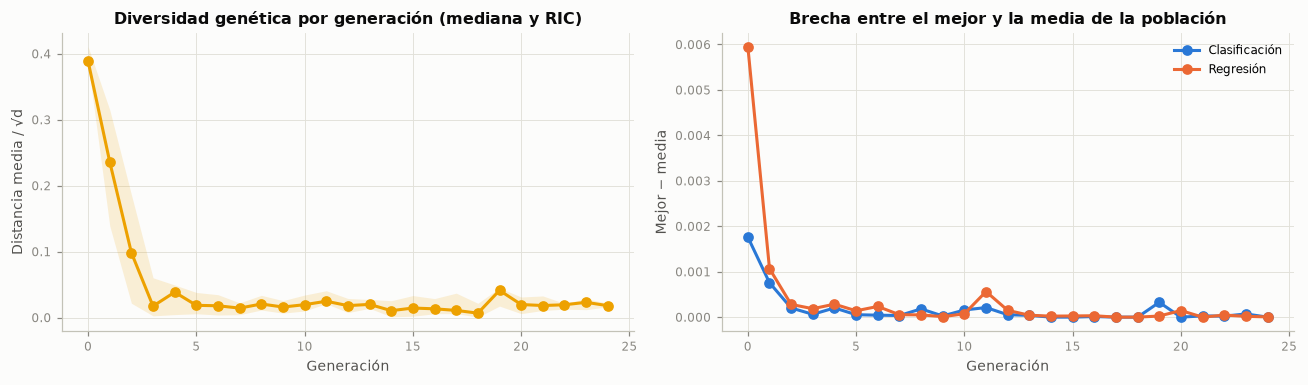

**Interpretación.** La diversidad mediana pasa de 0,388 en la población inicial a 0,018 en la generación 24 (una caída del 95 %), y el porcentaje de corridas con diversidad menor que 0,1 sube del 0,0 % al 100,0 %. La población inicial de un genoma uniforme tiene una diversidad esperada cercana a 0,41. Cada corrida usó una mediana de 11 generaciones (entre 4 y 50).

Lo anterior indica que la población se concentra rápido, como se espera con elitismo y torneo de tamaño 3: el genético pasa casi de inmediato a explotar la región del mejor individuo y, cuando la población converge, las generaciones siguientes producen sobre todo clones ya evaluados (por eso hay corridas con muchas generaciones y pocas evaluaciones nuevas). Es una señal de convergencia prematura, con riesgo de quedarse en un óptimo local.

Por esta razón, lo indicado es leer el buen desempeño del genético en las curvas *anytime* (sección 5.5) como el de una búsqueda que explota pronto una región buena, no como una exploración completa del espacio. Con más presupuesto convendría una población mayor, una mutación adaptativa que reinyecte diversidad cuando caiga por debajo de un umbral o reemplazar los clones por individuos aleatorios.

In [49]:
gen = pd.DataFrame([{**{k: c[k] for k in ("tarea", "modelo", "balanceo", "pliegue")}, **g_}
                    for c in corridas if c["optimizador"] == "genetico" and c["seed"] == SEED
                    for g_ in c["info"]["generaciones"]])
div = gen.groupby("generacion").agg(corridas=("diversidad", "size"), diversidad_mediana=("diversidad", "median"),
                                    q25=("diversidad", lambda s: s.quantile(0.25)),
                                    q75=("diversidad", lambda s: s.quantile(0.75)),
                                    pct_baja=("diversidad", lambda s: 100 * (s < 0.1).mean()),
                                    n_eval=("n_eval", "median"))
div = div[div["corridas"] >= 10]
tabla(div.rename(columns={"corridas": "Corridas", "diversidad_mediana": "Diversidad (mediana)", "q25": "Q1", "q75": "Q3",
                          "pct_baja": "% con diversidad < 0,1", "n_eval": "Evaluaciones acumuladas (mediana)"}), dec=3)

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
axs[0].plot(div.index, div["diversidad_mediana"], color=CAT[3], marker="o")
axs[0].fill_between(div.index, div["q25"], div["q75"], color=CAT[3], alpha=0.15, lw=0)
axs[0].set(title="Diversidad genética por generación (mediana y RIC)", xlabel="Generación",
           ylabel="Distancia media / √d")
gen["brecha"] = gen["mejor"] - gen["media"]
br = gen[gen["generacion"].isin(div.index)].groupby(["tarea", "generacion"])["brecha"].median().unstack(0)
for t_, col in zip(br.columns, [AZUL, NARANJA]):
    axs[1].plot(br.index, br[t_], marker="o", color=col, label="Clasificación" if t_ == "clf" else "Regresión")
axs[1].set(title="Brecha entre el mejor y la media de la población", xlabel="Generación", ylabel="Mejor − media")
axs[1].legend()
plt.tight_layout()
plt.show()

d0, dU = div["diversidad_mediana"].iloc[0], div["diversidad_mediana"].iloc[-1]
n_gen = gen.groupby(["tarea", "modelo", "balanceo", "pliegue"])["generacion"].max()
interpretar(
    f"La diversidad mediana pasa de {num(d0, 3)} en la población inicial a {num(dU, 3)} en la generación "
    f"{div.index[-1]} (una caída del {pct(1 - dU / d0, 0)}), y el porcentaje de corridas con diversidad menor que 0,1 "
    f"sube del {num(div['pct_baja'].iloc[0], 1)} % al {num(div['pct_baja'].iloc[-1], 1)} %. La población inicial de "
    f"un genoma uniforme tiene una diversidad esperada cercana a 0,41. Cada corrida usó una mediana de "
    f"{num(n_gen.median())} generaciones (entre {num(n_gen.min())} y {num(n_gen.max())}).",
    conectar("Lo anterior indica que", ("La población se concentra rápido, como se espera con elitismo y torneo de "
             "tamaño 3: el genético pasa casi de inmediato a explotar la región del mejor individuo y, cuando la "
             "población converge, las generaciones siguientes producen sobre todo clones ya evaluados (por eso hay "
             "corridas con muchas generaciones y pocas evaluaciones nuevas). Es una señal de convergencia prematura, "
             "con riesgo de quedarse en un óptimo local."
             if dU / d0 < 0.5 else "La población conserva buena parte de su diversidad en las pocas generaciones que "
             "permite el presupuesto, así que el genético sigue explorando y no hay señales de convergencia prematura; "
             "el costo es que tampoco alcanza a explotar a fondo la mejor región.")),
    conectar("Por esta razón, lo indicado es", "Leer el buen desempeño del genético en las curvas *anytime* (sección "
             "5.5) como el de una búsqueda que explota pronto una región buena, no como una exploración completa del "
             "espacio. Con más presupuesto convendría una población mayor, una mutación adaptativa que reinyecte "
             "diversidad cuando caiga por debajo de un umbral o reemplazar los clones por individuos aleatorios."))

exportar("genetico_diversidad", div.reset_index())


### 5.7 Multi-fidelidad: Successive Halving

Successive Halving se compara con Random Search y con Optuna en las mismas combinaciones (Random Forest y XGBoost sin balanceo) y en los mismos pliegues externos. Su costo se expresa en **evaluaciones equivalentes**: suma de árboles entrenados en todas las configuraciones dividida por el número máximo de árboles.

In [50]:
hv = pd.DataFrame([{k: c[k] for k in ("modelo", "pliegue", "auc_pr", "auc", "t_opt", "n_eval", "eval_equivalentes")}
                   for c in corridas if c["optimizador"] == "halving"])
ref_hv = pliegues[(pliegues["tarea"] == "clf") & (pliegues["balanceo"] == "ninguno") &
                  pliegues["modelo"].isin(["bosque", "xgboost"]) & pliegues["optimizador"].isin(["random", "bayes"])]
filas = []
for m_ in ("bosque", "xgboost"):
    for o_, d_ in [("halving", hv[hv["modelo"] == m_])] + [(o_, ref_hv[(ref_hv["modelo"] == m_) &
                                                                       (ref_hv["optimizador"] == o_)])
                                                           for o_ in ("random", "bayes")]:
        filas.append({"Modelo": NM[m_], "Método": NO[o_], "AUC-PR externo": ms(d_["auc_pr"]),
                      "AUC externo": ms(d_["auc"]), "Configuraciones evaluadas por pliegue": d_["n_eval"].mean(),
                      "Evaluaciones equivalentes por pliegue": d_["eval_equivalentes"].mean() if o_ == "halving"
                      else d_["n_eval"].mean(), "Tiempo por pliegue (s)": d_["t_opt"].mean()})
tabla(pd.DataFrame(filas), dec=1, indice=False)

rondas_hv = pd.DataFrame([{**r_, "modelo": c["modelo"]} for c in corridas if c["optimizador"] == "halving"
                          for r_ in c["rondas"]])
tabla(rondas_hv.groupby(["modelo", "iter"]).agg(Candidatos=("candidatos", "first"), Árboles=("arboles", "first"),
                                                **{"Mejor AUC-PR interno (media)": ("mejor", "mean")}), dec=4)

t_hv = hv.groupby("modelo")["t_opt"].mean()
t_rs = ref_hv[ref_hv["optimizador"] == "random"].groupby("modelo")["t_opt"].mean()
ap_hv = hv.groupby("modelo")["auc_pr"].mean()
ap_rs = ref_hv[ref_hv["optimizador"] == "random"].groupby("modelo")["auc_pr"].mean()
interpretar(
    f"Successive Halving evalúa {int(hv['n_eval'].mean())} configuraciones por pliegue con un costo equivalente a "
    f"{num(hv['eval_equivalentes'].mean(), 1)} evaluaciones completas, frente a las 20 de Random Search. Su tiempo por "
    f"pliegue es {num(t_hv['xgboost'], 0)} s en XGBoost y {num(t_hv['bosque'], 0)} s en Random Forest, frente a "
    f"{num(t_rs['xgboost'], 0)} s y {num(t_rs['bosque'], 0)} s de Random Search; el AUC-PR externo cambia en "
    f"{num(ap_hv['xgboost'] - ap_rs['xgboost'], 3)} y {num(ap_hv['bosque'] - ap_rs['bosque'], 3)}, respectivamente.",
    "Es decir, con " + pct(hv["eval_equivalentes"].mean() / cfg.PRESUPUESTO, 0) + " de las evaluaciones "
    "equivalentes de Random Search, la eliminación sucesiva examina el doble de configuraciones porque descarta "
    "temprano las que rinden mal con pocos árboles. El ahorro de tiempo (" + pct(1 - t_hv["xgboost"] / t_rs["xgboost"], 0)
    + " en XGBoost y " + pct(1 - t_hv["bosque"] / t_rs["bosque"], 0) + " en Random Forest) es menor que el de árboles, "
    "porque cada evaluación tiene costos que no dependen del número de árboles (preprocesamiento y tres pliegues "
    "internos). La condición para que funcione es que el orden de las configuraciones con pocos árboles se parezca al "
    "orden con muchos; la tabla de rondas muestra si el mejor puntaje sube o baja al aumentar la fidelidad.",
    conectar("Por ello, se recomienda", "Usar la multi-fidelidad cuando el costo por evaluación domina (bosques y "
             "*boosting* con muchos árboles) y reasignar el presupuesto ahorrado a más configuraciones, tal como pide la "
             "guía; en modelos baratos como Naive Bayes o la logística la ganancia no compensa la complejidad."))

exportar("halving", pd.DataFrame(filas))


Modelo,Método,AUC-PR externo,AUC externo,Configuraciones evaluadas por pliegue,Evaluaciones equivalentes por pliegue,Tiempo por pliegue (s)
Random Forest,Successive Halving,"0,092 ± 0,086","0,534 ± 0,086","39,0","8,9","149,3"
Random Forest,Random Search,"0,088 ± 0,078","0,523 ± 0,081","20,0","20,0","207,3"
Random Forest,Bayesiana (Optuna TPE),"0,095 ± 0,092","0,538 ± 0,079","20,0","20,0","282,3"
XGBoost,Successive Halving,"0,087 ± 0,073","0,528 ± 0,056","39,0","8,9","140,6"
XGBoost,Random Search,"0,088 ± 0,076","0,537 ± 0,065","20,0","20,0","163,3"
XGBoost,Bayesiana (Optuna TPE),"0,088 ± 0,078","0,529 ± 0,066","20,0","20,0","159,4"


**Interpretación.** Successive Halving evalúa 39 configuraciones por pliegue con un costo equivalente a 8,9 evaluaciones completas, frente a las 20 de Random Search. Su tiempo por pliegue es 141 s en XGBoost y 149 s en Random Forest, frente a 163 s y 207 s de Random Search; el AUC-PR externo cambia en -0,001 y 0,004, respectivamente.

Es decir, con 45 % de las evaluaciones equivalentes de Random Search, la eliminación sucesiva examina el doble de configuraciones porque descarta temprano las que rinden mal con pocos árboles. El ahorro de tiempo (14 % en XGBoost y 28 % en Random Forest) es menor que el de árboles, porque cada evaluación tiene costos que no dependen del número de árboles (preprocesamiento y tres pliegues internos). La condición para que funcione es que el orden de las configuraciones con pocos árboles se parezca al orden con muchos; la tabla de rondas muestra si el mejor puntaje sube o baja al aumentar la fidelidad.

Por ello, se recomienda usar la multi-fidelidad cuando el costo por evaluación domina (bosques y *boosting* con muchos árboles) y reasignar el presupuesto ahorrado a más configuraciones, tal como pide la guía; en modelos baratos como Naive Bayes o la logística la ganancia no compensa la complejidad.

### 5.8 Estabilidad de las soluciones ante distintas semillas

Los métodos estocásticos (Random Search, Optuna y el genético) se repiten con tres semillas adicionales (1, 2 y 3) en XGBoost sin balanceo, en los cinco pliegues externos. Grid Search es determinista dado el espacio, así que su variación por semilla del optimizador es nula.

In [51]:
sem = pd.DataFrame([{k: c[k] for k in ("optimizador", "pliegue", "seed", "auc_pr", "puntaje_interno")}
                    | {"lr": c["params"]["modelo__learning_rate"], "arboles": c["params"]["modelo__n_estimators"]}
                    for c in corridas if c["tarea"] == "clf" and c["modelo"] == "xgboost" and c["balanceo"] == "ninguno"
                    and c["optimizador"] in ("random", "bayes", "genetico")])
por_sem = sem.groupby(["optimizador", "seed"])["auc_pr"].mean().unstack()
estab = pd.DataFrame({
    "AUC-PR externo por semilla (media de 5 pliegues)": por_sem.apply(lambda r_: "; ".join(num(v, 4) for v in r_), axis=1),
    "Desv. est. entre semillas": por_sem.std(axis=1, ddof=1),
    "Desv. est. entre pliegues (semilla 42)": sem[sem["seed"] == SEED].groupby("optimizador")["auc_pr"].std(),
    "Desv. est. de log10(learning_rate) entre semillas (media por pliegue)":
        sem.assign(llr=np.log10(sem["lr"])).groupby(["optimizador", "pliegue"])["llr"].std().groupby("optimizador").mean(),
    "Desv. est. del puntaje interno entre semillas":
        sem.groupby(["optimizador", "pliegue"])["puntaje_interno"].std().groupby("optimizador").mean()})
estab.index = [NO[o] for o in estab.index]
tabla(estab, dec=4)

r_ = estab["Desv. est. entre semillas"] / estab["Desv. est. entre pliegues (semilla 42)"]
interpretar(
    f"La desviación del AUC-PR externo entre semillas es de "
    f"{enumerar([num(v, 4) + ' (' + i + ')' for i, v in estab['Desv. est. entre semillas'].items()], codigo=False)}, "
    f"entre {num(r_.min(), 2)} y {num(r_.max(), 2)} veces la desviación entre pliegues. La tasa de aprendizaje elegida "
    f"varía en promedio {enumerar([num(v, 2) for v in estab.iloc[:, 3]], codigo=False)} órdenes de magnitud (log10) "
    f"entre semillas.",
    conectar("Esto significa que", "Las soluciones de los métodos estocásticos no son únicas: semillas distintas llevan a "
             "hiperparámetros diferentes con desempeños parecidos, lo que indica una superficie de respuesta plana "
             "cerca del óptimo. " + ("La variación por semilla es pequeña frente a la que hay entre periodos, así que no "
             "cambia las conclusiones." if r_.max() < 0.5 else "La variación por semilla no es despreciable frente a la "
             "que hay entre periodos, así que una sola corrida puede ordenar mal dos métodos cercanos.")),
    conectar("Por tanto, corresponde", "Reportar los hiperparámetros elegidos como una de varias soluciones equivalentes y "
             "no sobreinterpretar su valor exacto; para la comparación entre métodos, la prueba por bloques de la "
             "sección 5.5 ya promedia esta fuente de variación."))

exportar("semillas_optimizador", estab.reset_index())


,AUC-PR externo por semilla (media de 5 pliegues),Desv. est. entre semillas,Desv. est. entre pliegues (semilla 42),Desv. est. de log10(learning_rate) entre semillas (media por pliegue),Desv. est. del puntaje interno entre semillas
Bayesiana (Optuna TPE),"0,0871; 0,0876; 0,0844; 0,0880","0,0017","0,0782","0,3458","0,0021"
Genético (DEAP),"0,0887; 0,0881; 0,0909; 0,0893","0,0012","0,0756","0,3027","0,0015"
Random Search,"0,0875; 0,0925; 0,0826; 0,0885","0,0041","0,0759","0,3693","0,0015"


**Interpretación.** La desviación del AUC-PR externo entre semillas es de 0,0017 (Bayesiana (Optuna TPE)), 0,0012 (Genético (DEAP)) y 0,0041 (Random Search), entre 0,02 y 0,05 veces la desviación entre pliegues. La tasa de aprendizaje elegida varía en promedio 0,35, 0,30 y 0,37 órdenes de magnitud (log10) entre semillas.

Esto significa que las soluciones de los métodos estocásticos no son únicas: semillas distintas llevan a hiperparámetros diferentes con desempeños parecidos, lo que indica una superficie de respuesta plana cerca del óptimo. La variación por semilla es pequeña frente a la que hay entre periodos, así que no cambia las conclusiones.

Por tanto, corresponde reportar los hiperparámetros elegidos como una de varias soluciones equivalentes y no sobreinterpretar su valor exacto; para la comparación entre métodos, la prueba por bloques de la sección 5.5 ya promedia esta fuente de variación.

## 6. Optimización computacional

Los experimentos de esta sección se ejecutaron con la máquina libre (después de la validación anidada), con un hilo por proceso salvo en el análisis de paralelización, y cada tiempo es el promedio de dos o tres repeticiones. Los modelos se miden sobre la matriz ya preprocesada (49 columnas densas), para aislar el costo del algoritmo. La máquina tiene 12 núcleos lógicos y no tiene GPU NVIDIA.

### 6.1 Complejidad algorítmica teórica

La tabla resume la complejidad de entrenamiento e inferencia de cada modelo en función de n (observaciones), p (características), B (árboles), k (vecinos), m (componentes de Nyström) y n_sv (vectores de soporte). Las secciones siguientes la contrastan con el tiempo medido y con el **exponente empírico**, la pendiente de log(tiempo) frente a log(n): un exponente cercano a 1 es lineal y cercano a 2, cuadrático.

In [52]:
RC = RES / "computacional"
cp = {f.stem: pd.read_parquet(f) for f in RC.glob("*.parquet")}
with open(RC / "perfil.pkl", "rb") as f:
    perfil = pickle.load(f)
tabla(comp.COMPLEJIDAD, indice=False)
exportar("comp_complejidad", comp.COMPLEJIDAD)
interpretar(
    'La tabla agrupa los algoritmos en tres órdenes de costo de entrenamiento: lineales en n (Naive Bayes, la logística y Ridge/Lasso con SAGA o SGD, el descenso por coordenadas de Lasso, la SVM lineal, Nyström + SVM lineal y XGBoost con histogramas), casi lineales del orden n log n (árbol de decisión, Random Forest, XGBoost exacto y la construcción del KD-Tree y el Ball Tree) y superlineales, de O(n²) a O(n³), en la SVM con núcleo. En inferencia, los modelos paramétricos cuestan O(p) por consulta sin importar el tamaño del entrenamiento, mientras que la KNN exhaustiva cuesta O(n · p) y la SVM con núcleo O(n_sv · p), porque ambas guardan los datos de entrenamiento o parte de ellos.',
    conectar('En ese sentido,', 'Con n = 32 940 observaciones de entrenamiento y p = 49 columnas, los cuellos de botella esperados son el entrenamiento de la SVM con núcleo y la consulta de la KNN, principalmente porque son los únicos cuyo costo crece más que linealmente con n o se paga de nuevo en cada predicción. Así mismo, el término p³ de Cholesky en Ridge es despreciable con 49 columnas, de modo que la ventaja asintótica de SAGA solo aparecería con p grande o con datos dispersos.'),
    conectar('Con base en esto, se propone', 'Concentrar la optimización en tres frentes, que son las estructuras de búsqueda y los vecinos aproximados para la KNN, la aproximación de Nyström con LinearSVC para evitar el núcleo exacto y los histogramas en XGBoost, y contrastar cada orden teórico con el exponente empírico de las secciones siguientes, porque la notación O(·) omite las constantes, el uso de BLAS y el paralelismo interno, que en tamaños moderados pueden pesar más que el orden asintótico.'),
)
for k_, v_ in cp.items():
    if k_ != "perfil_tabla":
        exportar(f"comp_{k_}", v_)
exportar("comp_perfil", {"total_s": perfil["total_s"], "memoria_pico_mb": perfil["memoria_pico_mb"]})


def exponentes(df, x="n", y="Ajuste (s)", grupo="Método"):
    return df.groupby(grupo).apply(lambda g: comp.exponente(g[x], g[y]), include_groups=False).rename("Exponente empírico")


def grafico_escalamiento(ax, df, y, titulo, grupo="Método"):
    for i, (m_, g) in enumerate(df.groupby(grupo, sort=False)):
        ax.loglog(g["n"], g[y], marker="o", color=CAT[i], label=m_)
    ax.set(title=titulo, xlabel="n (escala log)", ylabel=f"{y} (escala log)")
    ax.legend(fontsize=7)

Modelo,Entrenamiento,Inferencia,Implementación
KNN (búsqueda exhaustiva),O(1) (solo almacena),O(n · p) por consulta,brute
KNN (KD-Tree / Ball Tree),O(p · n log n),O(log n) en baja dimensión; tiende a O(n · p) si p es alto,kd_tree / ball_tree
KNN aproximado (FAISS HNSW),O(n log n · M),"≈ O(log n) por consulta, con pérdida de exactitud",IndexHNSWFlat
Naive Bayes gaussiano,O(n · p),O(p · c) por consulta,fit / partial_fit
Regresión logística (SAGA),O(n · p) por época,O(p) por consulta,solver saga
Ridge (Cholesky),O(n · p² + p³),O(p),cholesky
Ridge / Lasso (SAGA o SGD),O(n · p) por época,O(p),saga / SGD
Lasso (descenso por coordenadas),O(n · p) por pasada,O(p),cd
Árbol de decisión,O(p · n log n),O(profundidad),CART
Random Forest,O(B · p' · n log n),O(B · profundidad),"B árboles, p' variables por división"


**Interpretación.** La tabla agrupa los algoritmos en tres órdenes de costo de entrenamiento: lineales en n (Naive Bayes, la logística y Ridge/Lasso con SAGA o SGD, el descenso por coordenadas de Lasso, la SVM lineal, Nyström + SVM lineal y XGBoost con histogramas), casi lineales del orden n log n (árbol de decisión, Random Forest, XGBoost exacto y la construcción del KD-Tree y el Ball Tree) y superlineales, de O(n²) a O(n³), en la SVM con núcleo. En inferencia, los modelos paramétricos cuestan O(p) por consulta sin importar el tamaño del entrenamiento, mientras que la KNN exhaustiva cuesta O(n · p) y la SVM con núcleo O(n_sv · p), porque ambas guardan los datos de entrenamiento o parte de ellos.

En ese sentido, con n = 32 940 observaciones de entrenamiento y p = 49 columnas, los cuellos de botella esperados son el entrenamiento de la SVM con núcleo y la consulta de la KNN, principalmente porque son los únicos cuyo costo crece más que linealmente con n o se paga de nuevo en cada predicción. Así mismo, el término p³ de Cholesky en Ridge es despreciable con 49 columnas, de modo que la ventaja asintótica de SAGA solo aparecería con p grande o con datos dispersos.

Con base en esto, se propone concentrar la optimización en tres frentes, que son las estructuras de búsqueda y los vecinos aproximados para la KNN, la aproximación de Nyström con LinearSVC para evitar el núcleo exacto y los histogramas en XGBoost, y contrastar cada orden teórico con el exponente empírico de las secciones siguientes, porque la notación O(·) omite las constantes, el uso de BLAS y el paralelismo interno, que en tamaños moderados pueden pesar más que el orden asintótico.

### 6.2 KNN: búsqueda exhaustiva, KD-Tree, Ball Tree y vecinos aproximados con FAISS

Se buscan los 40 vecinos de las 8 236 observaciones de prueba entre las 32 940 de entrenamiento. Además del tiempo, se mide el *recall*@40 de cada método frente a la búsqueda exacta y el AUC-PR del clasificador que resulta de la proporción de vecinos positivos, que es el costo en exactitud de la aproximación.

Método,Búsqueda,Construcción (s),Consulta prueba (s),ms por consulta,Recall@k vs exacta,AUC-PR (prueba)
sklearn brute,exacta,"0,0025","3,0447","0,3697","1,0000","0,5060"
sklearn kd_tree,exacta,"0,3809","7,6172","0,9249","0,9953","0,5055"
sklearn ball_tree,exacta,"0,2270","20,4339","2,4810","0,9957","0,5056"
FAISS IndexFlatL2,exacta,"0,0039","1,9328","0,2347","0,9945","0,5057"
FAISS IndexHNSWFlat (M = 32),aproximada,"1,8577","0,2637","0,0320","0,8901","0,4850"
"FAISS IndexIVFFlat (100 listas, nprobe = 8)",aproximada,"0,2018","0,6198","0,0753","0,9911","0,5058"


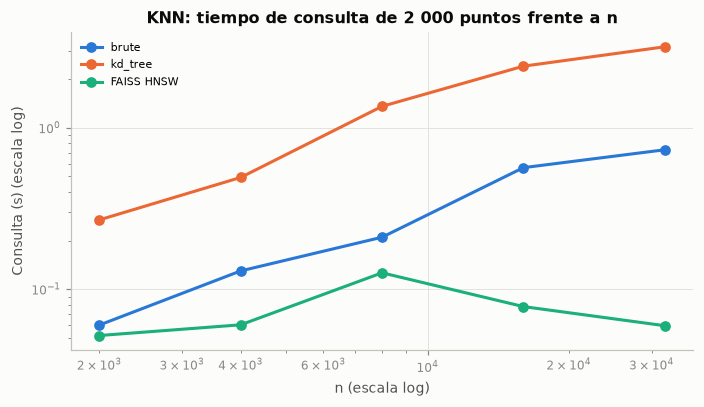

,Exponente empírico
Método,
FAISS HNSW,"0,08"
brute,"0,93"
kd_tree,"0,94"


**Interpretación.** La búsqueda exhaustiva tarda 3,04 s en consultar la prueba, el KD-Tree 7,62 s y FAISS HNSW 0,26 s, con un *recall*@40 de 0,890 frente a la búsqueda exacta y un AUC-PR de 0,4850 (exacta: 0,5060). El exponente empírico de la consulta es 0,08 (FAISS HNSW), 0,93 (brute) y 0,94 (kd_tree).

Esto significa que con 49 dimensiones, la mayoría binarias, los árboles de partición espacial pierden su ventaja teórica de O(log n): la maldición de la dimensionalidad obliga a visitar muchas hojas y el KD-Tree se acerca al costo exhaustivo, que además aprovecha BLAS. El grafo HNSW de FAISS sí escala de forma sublineal porque sacrifica exactitud, y en este problema esa pérdida casi no cambia la métrica.

Por lo anterior, conviene usar la búsqueda exhaustiva vectorizada en la validación anidada (lo que se hizo, con `algorithm='brute'`) y reservar FAISS para escenarios de inferencia masiva, donde el ahorro por consulta compensa la construcción del índice y la pérdida de exactitud es aceptable.

In [53]:
kb = cp["knn_busqueda"]
tabla(kb, dec=4, indice=False)
ke = cp["knn_escalamiento"]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
grafico_escalamiento(ax, ke, "Consulta (s)", "KNN: tiempo de consulta de 2 000 puntos frente a n")
plt.tight_layout()
plt.show()
exp_knn = exponentes(ke, y="Consulta (s)")
tabla(exp_knn.to_frame(), dec=2)

bru = kb[kb["Método"] == "sklearn brute"].iloc[0]
kd = kb[kb["Método"] == "sklearn kd_tree"].iloc[0]
hn = kb[kb["Método"].str.contains("HNSW")].iloc[0]
interpretar(
    f"La búsqueda exhaustiva tarda {num(bru['Consulta prueba (s)'], 2)} s en consultar la prueba, el KD-Tree "
    f"{num(kd['Consulta prueba (s)'], 2)} s y FAISS HNSW {num(hn['Consulta prueba (s)'], 2)} s, con un *recall*@40 de "
    f"{num(hn['Recall@k vs exacta'], 3)} frente a la búsqueda exacta y un AUC-PR de {num(hn['AUC-PR (prueba)'], 4)} "
    f"(exacta: {num(bru['AUC-PR (prueba)'], 4)}). El exponente empírico de la consulta es "
    f"{enumerar([num(v, 2) + ' (' + k + ')' for k, v in exp_knn.items()], codigo=False)}.",
    conectar("Esto significa que", "Con 49 dimensiones, la mayoría binarias, los árboles de partición espacial pierden su "
             "ventaja teórica de O(log n): la maldición de la dimensionalidad obliga a visitar muchas hojas y el "
             "KD-Tree se acerca al costo exhaustivo, que además aprovecha BLAS. El grafo HNSW de FAISS sí escala de forma "
             "sublineal porque sacrifica exactitud, y en este problema esa pérdida casi no cambia la métrica."
             if kd["Consulta prueba (s)"] > 0.5 * bru["Consulta prueba (s)"] else
             "Incluso con 49 dimensiones el KD-Tree mantiene una ventaja sobre la búsqueda exhaustiva, porque muchas "
             "columnas binarias reducen la dimensión efectiva; FAISS HNSW la amplía a costa de una pérdida mínima de "
             "exactitud."),
    conectar("Por lo anterior, conviene", "Usar la búsqueda exhaustiva vectorizada en la validación anidada (lo que se "
             "hizo, con `algorithm='brute'`) y reservar FAISS para escenarios de inferencia masiva, donde el ahorro por "
             "consulta compensa la construcción del índice y la pérdida de exactitud es aceptable."))

### 6.3 Ridge, Lasso y regresión logística: solucionadores

La guía sugiere SAGA, cuyo costo por época es lineal en n y p y que admite matrices dispersas. Se compara con los solucionadores directos (Cholesky, SVD), con el descenso por coordenadas del Lasso y con SGD, midiendo el tiempo de ajuste y la métrica en prueba.

Modelo,Solucionador,Ajuste (s),Desv. (s),Métrica,Valor
Ridge,cholesky,"0,0243","0,0069",RMSE,"1,0972"
Ridge,svd,"0,1951","0,0145",RMSE,"1,0973"
Ridge,sag,"7,2652","0,6553",RMSE,"1,0959"
Ridge,saga,"14,0636","0,5573",RMSE,"1,0866"
Lasso,descenso por coordenadas,"0,1041","0,0085",RMSE,"1,0173"
Lasso,SGD (L1),"0,1967","0,0079",RMSE,"1,4410"
Logística L2,lbfgs,"0,0946","0,0067",AUC-PR,"0,5484"
Logística L2,saga,"1,7024","0,1525",AUC-PR,"0,5497"
Logística L1,saga,"0,8945","0,0169",AUC-PR,"0,5406"
Logística L1,liblinear,"0,2062","0,0313",AUC-PR,"0,5719"


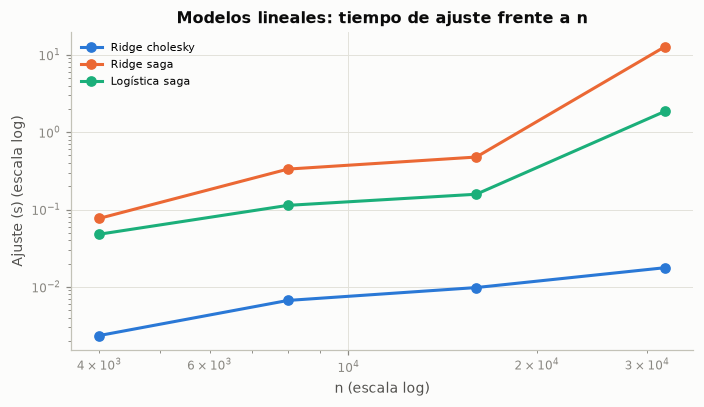

,Exponente empírico
Método,
Logística saga,"1,63"
Ridge cholesky,"0,93"
Ridge saga,"2,26"


**Interpretación.** Ridge con Cholesky se ajusta en 0,024 s y con SAGA en 14,064 s, con un RMSE de 1,0972 y 1,0866. Los exponentes empíricos son 1,63 (Logística saga), 0,93 (Ridge cholesky) y 2,26 (Ridge saga).

Hay que tener en cuenta que con p = 49, el término p³ de Cholesky es despreciable y su costo O(n · p²) es una sola pasada muy optimizada por BLAS; SAGA necesita varias épocas para converger, así que su ventaja asintótica solo aparece cuando p es grande o los datos son dispersos. Ambos resuelven el mismo problema convexo; la pequeña diferencia de RMSE se debe a que SAGA se detiene por tolerancia antes de converger del todo.

De ahí que se opte por mantener el solucionador directo para Ridge en este tamaño de problema y SAGA en la logística L1/L2, donde además es el que admite ambas penalizaciones con un mismo algoritmo.

In [54]:
lin = cp["lineales"]
tabla(lin, dec=4, indice=False)
le = cp["lineales_escalamiento"]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
grafico_escalamiento(ax, le, "Ajuste (s)", "Modelos lineales: tiempo de ajuste frente a n")
plt.tight_layout()
plt.show()
exp_lin = exponentes(le)
tabla(exp_lin.to_frame(), dec=2)

rc = lin[(lin["Modelo"] == "Ridge") & (lin["Solucionador"] == "cholesky")].iloc[0]
rs = lin[(lin["Modelo"] == "Ridge") & (lin["Solucionador"] == "saga")].iloc[0]
interpretar(
    f"Ridge con Cholesky se ajusta en {num(rc['Ajuste (s)'], 3)} s y con SAGA en {num(rs['Ajuste (s)'], 3)} s, con un RMSE "
    f"de {num(rc['Valor'], 4)} y {num(rs['Valor'], 4)}. Los exponentes empíricos son "
    f"{enumerar([num(v, 2) + ' (' + k + ')' for k, v in exp_lin.items()], codigo=False)}.",
    conectar("Hay que tener en cuenta que", "Con p = 49, el término p³ de Cholesky es despreciable y su costo O(n · p²) "
             "es una sola pasada muy optimizada por BLAS; SAGA necesita varias épocas para converger, así que su ventaja "
             "asintótica solo aparece cuando p es grande o los datos son dispersos. Ambos resuelven el mismo problema "
             "convexo; la pequeña diferencia de RMSE se debe a que SAGA se detiene por tolerancia antes de converger del "
             "todo."),
    conectar("De ahí que se opte por", "Mantener el solucionador directo para Ridge en este tamaño de problema y SAGA en "
             "la logística L1/L2, donde además es el que admite ambas penalizaciones con un mismo algoritmo."))

### 6.4 Naive Bayes: aprendizaje incremental con `partial_fit`

Para simular un conjunto que no cabe en memoria, el archivo se lee por lotes de 2 000 filas, cada lote se transforma con el preprocesador ya ajustado y se descarta después de actualizar las medias y varianzas del modelo.

In [55]:
nb_ = cp["naive_bayes"]
tabla(nb_, dec=4, indice=False)
f0, f1 = nb_.iloc[0], nb_.iloc[1]
interpretar(
    f"El ajuste completo usa {num(f0['Memoria pico (MB)'], 1)} MB de memoria pico y el incremental "
    f"{num(f1['Memoria pico (MB)'], 1)} MB, con tiempos de {num(f0['Tiempo (s)'], 3)} s y {num(f1['Tiempo (s)'], 3)} s; el "
    f"AUC-PR en prueba es {num(f0['AUC-PR prueba'], 4)} con `fit` y {num(f1['AUC-PR prueba'], 4)} con `partial_fit`.",
    conectar("Esto quiere decir que", "Las medias y varianzas de Naive Bayes son estadísticos suficientes que se "
             "actualizan exactamente por lotes; la pequeña diferencia viene del suavizado de varianza, que `partial_fit` "
             "calcula con la varianza máxima del primer lote y `fit` con la de todos los datos. El tiempo "
             "adicional es el de leer y transformar el archivo por partes, y la memoria queda acotada por el tamaño del "
             "lote y no por n."),
    conectar("Por ello, se recomienda", "Usar `partial_fit` cuando los datos crezcan más allá de la memoria disponible; con "
             "41 000 registros no es necesario, pero el resultado demuestra que el pipeline lo admite sin cambios."))

Modo,Tiempo (s),Memoria pico (MB),AUC-PR prueba,n_entrenamiento
fit (todo en memoria),"1,3438","35,5140","0,4560",32 940
partial_fit (lotes de 2000 filas leídos del CSV),"2,8373","3,3825","0,4569",32 940


**Interpretación.** El ajuste completo usa 35,5 MB de memoria pico y el incremental 3,4 MB, con tiempos de 1,344 s y 2,837 s; el AUC-PR en prueba es 0,4560 con `fit` y 0,4569 con `partial_fit`.

Esto quiere decir que las medias y varianzas de Naive Bayes son estadísticos suficientes que se actualizan exactamente por lotes; la pequeña diferencia viene del suavizado de varianza, que `partial_fit` calcula con la varianza máxima del primer lote y `fit` con la de todos los datos. El tiempo adicional es el de leer y transformar el archivo por partes, y la memoria queda acotada por el tamaño del lote y no por n.

Por ello, se recomienda usar `partial_fit` cuando los datos crezcan más allá de la memoria disponible; con 41 000 registros no es necesario, pero el resultado demuestra que el pipeline lo admite sin cambios.

### 6.5 XGBoost: histogramas frente al método exacto, parada temprana y GPU

Configuración,Ajuste (s),Inferencia (s),AUC-PR prueba,AUC prueba,GPU
"tree_method='exact' (CPU, 1 hilo)","18,8640","0,0611","0,4022","0,5848","no disponible, porque no hay GPU NVIDIA (con device='cuda', XGBoost recurre a la CPU sin error)"
"tree_method='approx' (CPU, 1 hilo)","13,1762","0,0630","0,4022","0,5869","no disponible, porque no hay GPU NVIDIA (con device='cuda', XGBoost recurre a la CPU sin error)"
"tree_method='hist' (CPU, 1 hilo)","1,8721","0,0580","0,4022","0,5869","no disponible, porque no hay GPU NVIDIA (con device='cuda', XGBoost recurre a la CPU sin error)"


Configuración,Árboles usados,Ajuste (s),AUC-PR prueba
Sin parada temprana (2000 árboles),2 000,"16,1139","0,3650"
Con parada temprana (paciencia 50),4,"0,5587","0,3380"


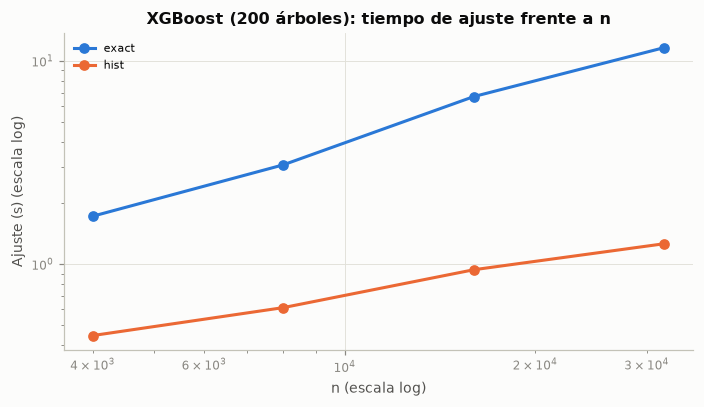

,Exponente empírico
Método,
exact,"0,94"
hist,"0,51"


**Interpretación.** Con 300 árboles, el método exacto tarda 18,86 s y el de histogramas 1,87 s (10,1 veces menos), con un AUC-PR de 0,4022 y 0,4022. La parada temprana usa 4 de 2000 árboles y reduce el ajuste de 16,1 s a 0,6 s, con un AUC-PR de 0,3380 frente a 0,3650.

Lo anterior indica que discretizar cada característica en a lo sumo 256 bins elimina el ordenamiento O(n log n) por nodo del método exacto, y la pérdida de exactitud es nula en la práctica porque la mayoría de las columnas son binarias o tienen pocos valores distintos. La parada temprana ahorra cómputo, pero aquí se detuvo con muy pocos árboles: el conjunto de validación (el final del entrenamiento, ya en 2009) deja de mejorar casi de inmediato porque lo aprendido con 2008 no se traslada, y en prueba pierde AUC-PR. Su efecto de regularización depende de que la validación represente el periodo de uso.

Por tal motivo, se opta por `tree_method='hist'` en todos los experimentos (como se hizo) y por no usar GPU. La máquina no tiene GPU NVIDIA y, con unos 41 000 registros, tampoco se justifica: con histogramas, el ajuste en CPU ya tarda 1,87 s, y scikit-learn está diseñado para CPU (su soporte de GPU es experimental y cubre pocos estimadores), de modo que el preprocesamiento, el balanceo y los demás modelos seguirían en CPU.

In [56]:
import shutil
xg = cp["xgboost"].copy()
gpu_txt = ("disponible" if (xgboost.build_info().get("USE_CUDA") and shutil.which("nvidia-smi")) else
           "no disponible, porque no hay GPU NVIDIA (con device='cuda', XGBoost recurre a la CPU sin error)")
xg["GPU"] = gpu_txt
tabla(xg, dec=4, indice=False)
xe = cp["xgboost_escalamiento"]
xp = cp["xgboost_parada"]
tabla(xp, dec=4, indice=False)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
grafico_escalamiento(ax, xe, "Ajuste (s)", "XGBoost (200 árboles): tiempo de ajuste frente a n")
plt.tight_layout()
plt.show()
exp_xgb = exponentes(xe)
tabla(exp_xgb.to_frame(), dec=2)

ex = xg[xg["Configuración"].str.contains("exact")].iloc[0]
hi_ = xg[xg["Configuración"].str.contains("hist")].iloc[0]
interpretar(
    f"Con 300 árboles, el método exacto tarda {num(ex['Ajuste (s)'], 2)} s y el de histogramas {num(hi_['Ajuste (s)'], 2)} s "
    f"({num(ex['Ajuste (s)'] / hi_['Ajuste (s)'], 1)} veces menos), con un AUC-PR de {num(ex['AUC-PR prueba'], 4)} y "
    f"{num(hi_['AUC-PR prueba'], 4)}. La parada temprana usa {int(xp['Árboles usados'].iloc[1])} de "
    f"{int(xp['Árboles usados'].iloc[0])} árboles y reduce el ajuste de {num(xp['Ajuste (s)'].iloc[0], 1)} s a "
    f"{num(xp['Ajuste (s)'].iloc[1], 1)} s, con un AUC-PR de {num(xp['AUC-PR prueba'].iloc[1], 4)} frente a "
    f"{num(xp['AUC-PR prueba'].iloc[0], 4)}.",
    conectar("Lo anterior indica que", "Discretizar cada característica en a lo sumo 256 bins elimina el ordenamiento "
             "O(n log n) por nodo del método exacto, y la pérdida de exactitud es nula en la práctica porque la mayoría "
             "de las columnas son binarias o tienen pocos valores distintos. " + ("La parada temprana ahorra cómputo, "
             "pero aquí se detuvo con muy pocos árboles: el conjunto de validación (el final del entrenamiento, ya en "
             "2009) deja de mejorar casi de inmediato porque lo aprendido con 2008 no se traslada, y en prueba pierde "
             "AUC-PR. Su efecto de regularización depende de que la validación represente el periodo de uso."
             if xp["AUC-PR prueba"].iloc[1] < xp["AUC-PR prueba"].iloc[0] else
             "La parada temprana ahorra cómputo y actúa como regularización, siempre que el conjunto de validación sea "
             "independiente y posterior en el tiempo.")),
    conectar("Por tal motivo, se opta por", "`tree_method='hist'` en todos los experimentos (como se hizo) y por no usar "
             "GPU. La máquina no tiene GPU NVIDIA y, con unos 41 000 registros, tampoco se justifica: con histogramas, el "
             f"ajuste en CPU ya tarda {num(hi_['Ajuste (s)'], 2)} s, y scikit-learn está diseñado para CPU (su soporte de "
             "GPU es experimental y cubre pocos estimadores), de modo que el preprocesamiento, el balanceo y los demás "
             "modelos seguirían en CPU."))

### 6.6 SVM: núcleo exacto frente a LinearSVC, SGD y aproximación de Nyström

Método,n,Ajuste (s),Inferencia (s),AUC prueba,AUC-PR prueba
SVC núcleo RBF (exacto),1 000,"0,0121","0,1150","0,6119","0,3837"
LinearSVC,1 000,"0,0036","0,0016","0,4565","0,2948"
SGD (bisagra),1 000,"0,0084","0,0007","0,5391","0,3330"
Nyström (300) + LinearSVC,1 000,"0,0795","0,1759","0,6732","0,5008"
SVC núcleo RBF (exacto),2 000,"0,0438","0,2452","0,6309","0,4012"
LinearSVC,2 000,"0,0076","0,0016","0,4528","0,2953"
SGD (bisagra),2 000,"0,0155","0,0008","0,5353","0,3350"
Nyström (300) + LinearSVC,2 000,"0,1169","0,1190","0,6739","0,5012"
SVC núcleo RBF (exacto),4 000,"0,2283","0,5992","0,5291","0,3096"
LinearSVC,4 000,"0,0209","0,0020","0,4538","0,2967"


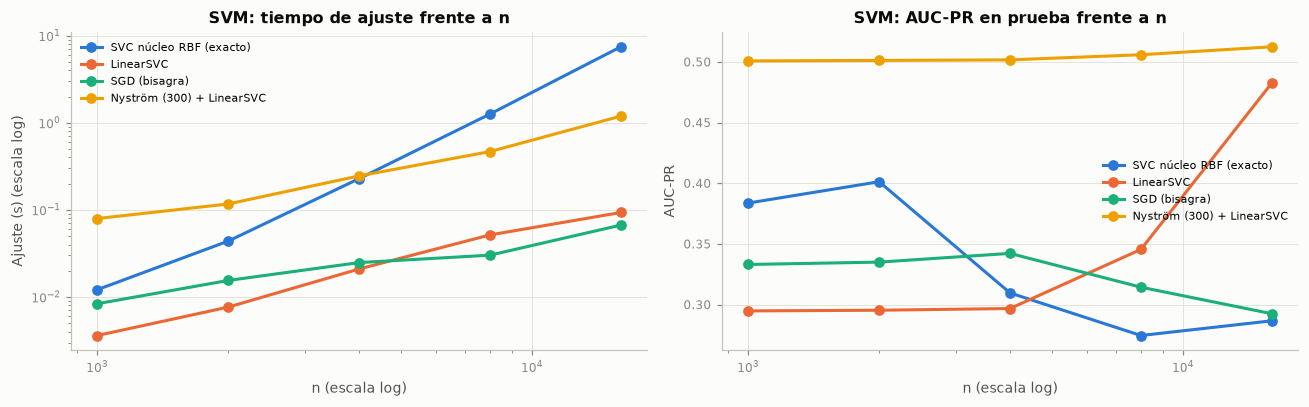

,Exponente empírico
Método,
LinearSVC,"1,21"
Nyström (300) + LinearSVC,"0,98"
SGD (bisagra),"0,70"
SVC núcleo RBF (exacto),"2,34"


**Interpretación.** El exponente empírico del SVC con núcleo exacto es 1,21, frente a 1,21 (LinearSVC), 0,98 (Nyström (300) + LinearSVC) y 0,70 (SGD (bisagra)). Con n = 16 000, el núcleo exacto tarda 7,5 s y Nyström + LinearSVC 1,19 s, con AUC-PR de 0,2866 y 0,5124.

Así mismo, el exponente del núcleo exacto queda por debajo del cuadrático teórico en este rango de n, porque SMO trabaja sobre los vectores de soporte y la caché del núcleo; aun así, su tiempo absoluto es varias veces el de la aproximación y su costo teórico crece de forma cuadrática a cúbica cuando n aumenta. Además, con gamma='scale' y C = 1 sin ajustar, el núcleo exacto discrimina peor en prueba que la aproximación de Nyström con gamma = 0,03: la elección de gamma importa más que la exactitud del núcleo. Con 20 configuraciones por pliegue en la validación anidada, el núcleo exacto multiplicaría el costo sin ventaja demostrada.

En consecuencia, se decide usar Nyström + LinearSVC como la SVM del proyecto (y Nyström + LinearSVR como la SVR), con el número de componentes y gamma como hiperparámetros, tal como recomienda la guía para problemas de gran tamaño de muestra.

In [57]:
sv = cp["svm_escalamiento"]
tabla(sv, dec=4, indice=False)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
grafico_escalamiento(axs[0], sv, "Ajuste (s)", "SVM: tiempo de ajuste frente a n")
for i, (m_, g) in enumerate(sv.groupby("Método", sort=False)):
    axs[1].semilogx(g["n"], g["AUC-PR prueba"], marker="o", color=CAT[i], label=m_)
axs[1].set(title="SVM: AUC-PR en prueba frente a n", xlabel="n (escala log)", ylabel="AUC-PR")
axs[1].legend(fontsize=7)
plt.tight_layout()
plt.show()
exp_svm = exponentes(sv)
tabla(exp_svm.to_frame(), dec=2)

nmax = sv[sv["Método"].str.startswith("SVC")]["n"].max()
s_k = sv[(sv["Método"].str.startswith("SVC")) & (sv["n"] == nmax)].iloc[0]
s_n = sv[(sv["Método"].str.startswith("Nyström")) & (sv["n"] == nmax)].iloc[0]
interpretar(
    f"El exponente empírico del SVC con núcleo exacto es {num(exp_svm.filter(like='SVC').iloc[0], 2)}, frente a "
    f"{enumerar([num(v, 2) + ' (' + k + ')' for k, v in exp_svm.items() if not k.startswith('SVC')], codigo=False)}. Con "
    f"n = {num(nmax)}, el núcleo exacto tarda {num(s_k['Ajuste (s)'], 1)} s y Nyström + LinearSVC "
    f"{num(s_n['Ajuste (s)'], 2)} s, con AUC-PR de {num(s_k['AUC-PR prueba'], 4)} y {num(s_n['AUC-PR prueba'], 4)}.",
    ("Así mismo, el crecimiento superlineal del núcleo exacto confirma el costo cuadrático a cúbico de SMO. "
     if exp_svm.filter(like="SVC").iloc[0] >= 1.8 else
     "Así mismo, el exponente del núcleo exacto queda por debajo del cuadrático teórico en este rango de n, porque "
     "SMO trabaja sobre los vectores de soporte y la caché del núcleo; aun así, su tiempo absoluto es varias veces el "
     "de la aproximación y su costo teórico crece de forma cuadrática a cúbica cuando n aumenta. ")
    + "Además, con gamma='scale' y C = 1 sin ajustar, el núcleo exacto discrimina peor en prueba que la aproximación de "
      "Nyström con gamma = 0,03: la elección de gamma importa más que la exactitud del núcleo. Con 20 configuraciones "
      "por pliegue en la validación anidada, el núcleo exacto multiplicaría el costo sin ventaja demostrada.",
    conectar("En consecuencia, se decide", "Usar Nyström + LinearSVC como la SVM del proyecto (y Nyström + LinearSVR como "
             "la SVR), con el número de componentes y gamma como hiperparámetros, tal como recomienda la guía para "
             "problemas de gran tamaño de muestra."))

### 6.7 Paralelización con `joblib`

Se mide la validación cruzada de un Random Forest (200 árboles) paralelizando entre pliegues con los *backends* `loky` (procesos) y `threading` (hilos), y paralelizando entre árboles dentro del propio bosque. La aceleración es el tiempo con un núcleo dividido por el tiempo con n_jobs núcleos; la eficiencia es la aceleración dividida por n_jobs.

Nivel,Backend,n_jobs,Tiempo (s),Aceleración,Eficiencia
entre pliegues (cross_validate),loky,1,"7,97","1,00","1,00"
entre pliegues (cross_validate),loky,2,"9,20","0,87","0,43"
entre pliegues (cross_validate),loky,4,"8,22","0,97","0,24"
entre pliegues (cross_validate),loky,8,"9,84","0,81","0,10"
entre pliegues (cross_validate),threading,1,"7,34","1,00","1,00"
entre pliegues (cross_validate),threading,2,"6,19","1,18","0,59"
entre pliegues (cross_validate),threading,4,"6,54","1,12","0,28"
entre pliegues (cross_validate),threading,8,"5,16","1,42","0,18"
entre árboles (RandomForest n_jobs),threading (interno),1,"7,69","1,00","1,00"
entre árboles (RandomForest n_jobs),threading (interno),2,"5,19","1,48","0,74"


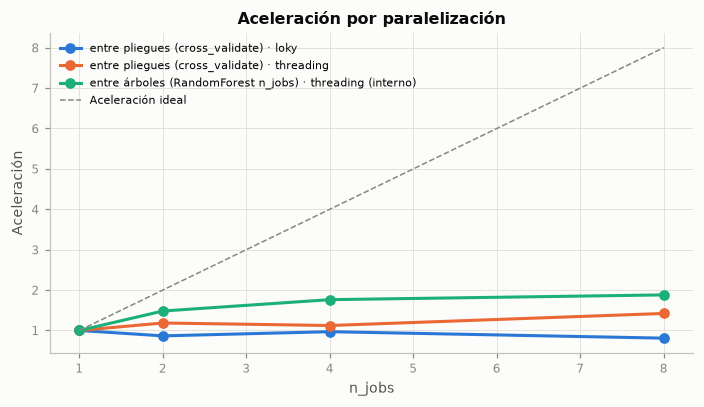

**Interpretación.** La mayor aceleración es de 1,9 veces con 8 núcleos (entre árboles (RandomForest n_jobs), threading (interno)), una eficiencia del 24 %. Con 3 pliegues internos, paralelizar entre pliegues no puede superar una aceleración de 3, porque no hay más tareas que repartir.

Es decir, la granularidad decide la escalabilidad: entre pliegues hay pocas tareas grandes y entre árboles hay muchas tareas pequeñas. Los hilos funcionan bien en scikit-learn y XGBoost porque el núcleo de cómputo libera el GIL; los procesos de `loky` pagan el arranque de cada trabajador y la copia de los datos, y con tareas de pocos segundos ese costo fijo anula la ganancia (aquí `loky` entre pliegues fue incluso más lento que un solo núcleo).

Por tal motivo, se opta por paralelizar al nivel más grueso disponible, que en este proyecto son las 700 tareas (combinación × pliegue externo): 10 procesos independientes con un hilo cada uno, sin sobresuscribir los núcleos. Herramientas distribuidas como Dask o Ray no se justifican con 41 000 registros que caben en memoria y una sola máquina; serían la opción si el número de combinaciones o el tamaño de los datos exigiera varios nodos.

In [58]:
pa = cp["paralelizacion"]
tabla(pa, dec=2, indice=False)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for i, ((niv, be), g) in enumerate(pa.groupby(["Nivel", "Backend"], sort=False)):
    ax.plot(g["n_jobs"], g["Aceleración"], marker="o", color=CAT[i], label=f"{niv} · {be}")
ax.plot(pa["n_jobs"].unique(), pa["n_jobs"].unique(), color=GRIS, ls="--", lw=1, label="Aceleración ideal")
ax.set(title="Aceleración por paralelización", xlabel="n_jobs", ylabel="Aceleración")
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

mej = pa.loc[pa["Aceleración"].idxmax()]
interpretar(
    f"La mayor aceleración es de {num(mej['Aceleración'], 1)} veces con {int(mej['n_jobs'])} núcleos "
    f"({mej['Nivel']}, {mej['Backend']}), una eficiencia del {pct(mej['Eficiencia'], 0)}. Con 3 pliegues internos, "
    "paralelizar entre pliegues no puede superar una aceleración de 3, porque no hay más tareas que repartir.",
    conectar("Es decir,", "La granularidad decide la escalabilidad: entre pliegues hay pocas tareas grandes y entre árboles "
             "hay muchas tareas pequeñas. Los hilos funcionan bien en scikit-learn y XGBoost porque el núcleo de cómputo "
             "libera el GIL; los procesos de `loky` pagan el arranque de cada trabajador y la copia de los datos, y con "
             "tareas de pocos segundos ese costo fijo anula la ganancia"
             + (" (aquí `loky` entre pliegues fue incluso más lento que un solo núcleo)."
                if (pa[(pa["Backend"] == "loky") & (pa["n_jobs"] > 1)]["Aceleración"] < 1).any() else ".")),
    conectar("Por tal motivo, se opta por", "Paralelizar al nivel más grueso disponible, que en este proyecto son las 700 "
             "tareas (combinación × pliegue externo): 10 procesos independientes con un hilo cada uno, sin sobresuscribir "
             "los núcleos. Herramientas distribuidas como Dask o Ray no se justifican con 41 000 registros que caben en "
             "memoria y una sola máquina; serían la opción si el número de combinaciones o el tamaño de los datos "
             "exigiera varios nodos."))

### 6.8 Perfilamiento: dónde está el costo real

Se perfila con `cProfile` (tiempo de CPU por función) y `memory_profiler` (memoria pico) una combinación completa del bucle anidado: XGBoost con SMOTE y optimización bayesiana en el pliegue externo más grande, es decir, 20 configuraciones × 3 pliegues internos más el reajuste final.

In [59]:
pc = cp["perfil_componentes"]
tabla(pc, dec=2, indice=False)
print(f"Tiempo total perfilado: {num(perfil['total_s'], 1)} s · memoria pico: {num(perfil['memoria_pico_mb'], 0)} MB")
dom = pc.iloc[0]
interpretar(
    f"El componente dominante es \"{dom['Componente']}\", con el {num(dom['% del total'], 1)} % del tiempo; le siguen "
    f"{enumerar([f'{r.Componente} ({num(r._3, 1)} %)' for r in pc.iloc[1:3].itertuples()], codigo=False)}. La memoria "
    f"pico de la combinación es de {num(perfil['memoria_pico_mb'], 0)} MB.",
    conectar("Esto significa que", "El costo propio del optimizador (el muestreo de TPE) es despreciable frente al "
             "ajuste de los modelos. "
             + (f"El preprocesamiento sí pesa ({num(pc.set_index('Componente').loc['Preprocesamiento (ColumnTransformer)', '% del total'], 1)} %): "
                "se reajusta en cada uno de los 60 ajustes internos aunque sus parámetros apenas cambian entre "
                "configuraciones, de modo que precalcularlo por pliegue (con `memory` en el `Pipeline`) es la "
                "optimización con mejor relación costo-beneficio después del modelo. "
                if pc.set_index('Componente').loc['Preprocesamiento (ColumnTransformer)', '% del total'] > 10 else
                "El preprocesamiento también es marginal, así que optimizarlo sería una optimización prematura. ")
             + "La memoria no es una restricción en este tamaño de datos."),
    conectar("Por lo anterior, conviene", "Concentrar las mejoras en reducir el número de ajustes (multi-fidelidad, "
             "parada temprana, menos configuraciones malas gracias a métodos adaptativos) y en el método de "
             "construcción de los árboles (`hist`), que son las palancas que actúan sobre el cuello de botella real."))

Componente,Tiempo acumulado (s),% del total
Ajuste de XGBoost (booster),"116,81","69,04"
Preprocesamiento (ColumnTransformer),"32,50","19,21"
Cálculo de la métrica (scorer),"6,42","3,80"
Predicción de XGBoost,"1,82","1,07"
SMOTE (fit_resample),"1,72","1,01"
Muestreo TPE de Optuna,"0,00","0,00"


Tiempo total perfilado: 169,2 s · memoria pico: 495 MB


**Interpretación.** El componente dominante es "Ajuste de XGBoost (booster)", con el 69,0 % del tiempo; le siguen Preprocesamiento (ColumnTransformer) (19,2 %) y Cálculo de la métrica (scorer) (3,8 %). La memoria pico de la combinación es de 495 MB.

Esto significa que el costo propio del optimizador (el muestreo de TPE) es despreciable frente al ajuste de los modelos. El preprocesamiento sí pesa (19,2 %): se reajusta en cada uno de los 60 ajustes internos aunque sus parámetros apenas cambian entre configuraciones, de modo que precalcularlo por pliegue (con `memory` en el `Pipeline`) es la optimización con mejor relación costo-beneficio después del modelo. La memoria no es una restricción en este tamaño de datos.

Por lo anterior, conviene concentrar las mejoras en reducir el número de ajustes (multi-fidelidad, parada temprana, menos configuraciones malas gracias a métodos adaptativos) y en el método de construcción de los árboles (`hist`), que son las palancas que actúan sobre el cuello de botella real.

### 6.9 Tabla comparativa: modelo estándar frente a optimizado

La tabla que pide la guía resume, para cada par, la complejidad teórica, el tiempo de ajuste, el tiempo de inferencia sobre la prueba, la memoria del ajuste y la variación del desempeño predictivo (AUC-PR o RMSE en prueba). La memoria es el incremento de la memoria residente del proceso durante el ajuste, medido con `memory_profiler` en un proceso nuevo para cada versión: así incluye las reservas internas de las librerías escritas en C/C++ (XGBoost, FAISS y libsvm), que `tracemalloc` no registra, y no se mezcla con la memoria liberada por ajustes anteriores.

In [60]:
co = cp["comparativa"]
tabla(co, dec=4, indice=False)
pares_c = co.groupby("Modelo", sort=False)
ahorro = pares_c.apply(lambda g: g["Ajuste (s)"].iloc[0] / g["Ajuste (s)"].iloc[1], include_groups=False)
ahorro_i = pares_c.apply(lambda g: g["Inferencia (s)"].iloc[0] / g["Inferencia (s)"].iloc[1], include_groups=False)
dif_m = pares_c["Variación de la métrica"].last()
mem = pares_c["Memoria del ajuste (MB)"].agg(["first", "last"])
def veces(v, fem=False):
    if 0.9 <= v <= 1.1:
        return "similar"
    a = "a" if fem else "o"
    return f"{num(v, 1)} veces más rápid{a}" if v > 1 else f"{num(1 / v, 1 if 1 / v < 10 else 0)} veces más lent{a}"

interpretar(
    "Frente a la versión estándar, el ajuste de la versión optimizada es "
    + enumerar([f"{veces(v)} ({k})" for k, v in ahorro.items()], codigo=False)
    + "; la inferencia es " + enumerar([f"{veces(v, fem=True)} ({k})" for k, v in ahorro_i.items()], codigo=False)
    + ". La memoria del ajuste pasa de " + enumerar([f"{num(r['first'], 1)} a {num(r['last'], 1)} MB ({k})" for k, r in mem.iterrows()], codigo=False)
    + ", y la métrica cambia en " + enumerar([f"{num(v, 4)} ({k})" for k, v in dif_m.items()], codigo=False) + ".",
    conectar("En síntesis,", "Cada optimización actúa sobre una fase distinta: los histogramas abaratan el ajuste de XGBoost "
             "sin perder desempeño; FAISS HNSW encarece la construcción del índice pero abarata cada consulta, con una "
             "pérdida pequeña de AUC-PR; Nyström abarata la SVM y, con un gamma adecuado, incluso mejora la métrica. "
             "SAGA, que solo mejora la complejidad asintótica, es mucho más lento que Cholesky con 49 columnas. En memoria, "
             "los histogramas también reducen el consumo de XGBoost, mientras que el índice de FAISS y la matriz de "
             "componentes de Nyström cambian velocidad por memoria."),
    conectar("Así las cosas, se decide", "Mantener en el pipeline las versiones optimizadas que ganan en tiempo sin perder "
             "desempeño y documentar las que no aplican a este tamaño de problema, en lugar de adoptarlas por defecto."))

Modelo,Versión,Complejidad teórica,Ajuste (s),Inferencia (s),Memoria del ajuste (MB),Métrica,Valor,Variación de la métrica
KNN (k = 40),Estándar: búsqueda exhaustiva,O(n · p) por consulta,"0,0017","2,5164","0,1836",AUC-PR,"0,5060","0,0000"
KNN (k = 40),Optimizado: FAISS HNSW (aproximado),≈ O(log n) por consulta,"1,6692","0,2007","14,7188",AUC-PR,"0,4850","-0,0210"
Ridge,Estándar: Cholesky,O(n · p² + p³),"0,0192","0,0005","6,8438",RMSE,"1,0972","0,0000"
Ridge,Optimizado: SAGA,O(n · p) por época,"10,3464","0,0005","6,4336",RMSE,"1,0866","-0,0106"
XGBoost (300 árboles),Estándar: tree_method='exact',O(B · p · n log n),"15,0611","0,0489","28,7266",AUC-PR,"0,4022","0,0000"
XGBoost (300 árboles),Optimizado: tree_method='hist',O(B · p · n),"1,7643","0,0671","6,1641",AUC-PR,"0,4022","-0,0000"
SVM RBF (n = 8000),Estándar: SVC núcleo exacto,O(n²) a O(n³),"1,0683","1,1883","55,2812",AUC-PR,"0,2745","0,0000"
SVM RBF (n = 8000),Optimizado: Nyström (300) + LinearSVC,O(n · m · p + n · m² + m³),"0,4048","0,1261","65,3008",AUC-PR,"0,5059","0,2314"


**Interpretación.** Frente a la versión estándar, el ajuste de la versión optimizada es 955 veces más lento (KNN (k = 40)), 538 veces más lento (Ridge), 8,5 veces más rápido (XGBoost (300 árboles)) y 2,6 veces más rápido (SVM RBF (n = 8000)); la inferencia es 12,5 veces más rápida (KNN (k = 40)), similar (Ridge), 1,4 veces más lenta (XGBoost (300 árboles)) y 9,4 veces más rápida (SVM RBF (n = 8000)). La memoria del ajuste pasa de 0,2 a 14,7 MB (KNN (k = 40)), 6,8 a 6,4 MB (Ridge), 28,7 a 6,2 MB (XGBoost (300 árboles)) y 55,3 a 65,3 MB (SVM RBF (n = 8000)), y la métrica cambia en -0,0210 (KNN (k = 40)), -0,0106 (Ridge), -0,0000 (XGBoost (300 árboles)) y 0,2314 (SVM RBF (n = 8000)).

En síntesis, cada optimización actúa sobre una fase distinta: los histogramas abaratan el ajuste de XGBoost sin perder desempeño; FAISS HNSW encarece la construcción del índice pero abarata cada consulta, con una pérdida pequeña de AUC-PR; Nyström abarata la SVM y, con un gamma adecuado, incluso mejora la métrica. SAGA, que solo mejora la complejidad asintótica, es mucho más lento que Cholesky con 49 columnas. En memoria, los histogramas también reducen el consumo de XGBoost, mientras que el índice de FAISS y la matriz de componentes de Nyström cambian velocidad por memoria.

Así las cosas, se decide mantener en el pipeline las versiones optimizadas que ganan en tiempo sin perder desempeño y documentar las que no aplican a este tamaño de problema, en lugar de adoptarlas por defecto.

## 7. Evaluación de modelos

### 7.1 Tabla maestra de las 140 combinaciones

Cada fila de la tabla maestra (`resultados/tabla_maestra.csv`) es una combinación con la media y la desviación estándar de sus métricas en los cinco pliegues externos, el número de evaluaciones, los tiempos, los hiperparámetros elegidos en cada pliegue y la semilla. El mapa de calor muestra, para cada par modelo-balanceo, el mejor AUC-PR externo entre los optimizadores.

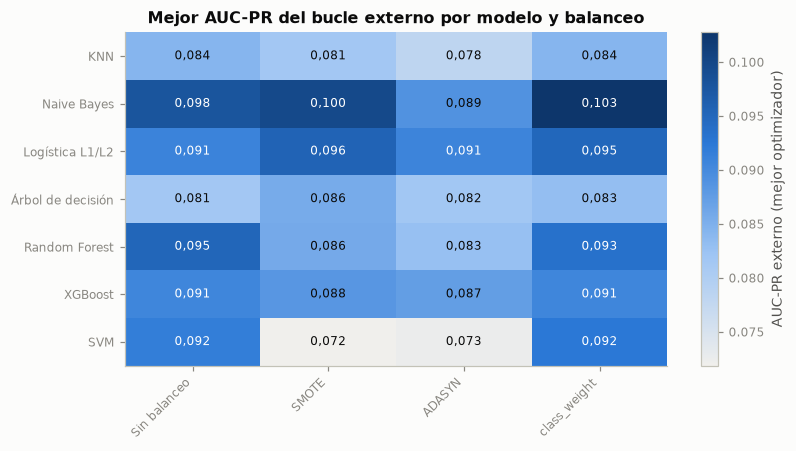

modelo,balanceo,optimizador,AUC-PR media,AUC-PR DE,AUC media,Recall media,F1 media,Tiempo (min),Evaluaciones
Naive Bayes,class_weight,Bayesiana (Optuna TPE),"0,1028","0,1081","0,5368","0,8498","0,1443","2,5239",100
Naive Bayes,SMOTE,Genético (DEAP),"0,0997","0,0955","0,5405","0,8120","0,1432","2,7966",100
Naive Bayes,SMOTE,Random Search,"0,0997","0,0958","0,5405","0,7967","0,1466","2,8013",100
Naive Bayes,SMOTE,Bayesiana (Optuna TPE),"0,0997","0,0953","0,5407","0,8086","0,1432","2,8029",100
Naive Bayes,Sin balanceo,Grid Search,"0,0978","0,0932","0,5340","0,0438","0,0511","2,6944",100
Naive Bayes,class_weight,Grid Search,"0,0978","0,0933","0,5340","0,7060","0,1065","2,5203",100
Naive Bayes,Sin balanceo,Genético (DEAP),"0,0976","0,0936","0,5321","0,0511","0,0540","2,6325",100
Naive Bayes,class_weight,Genético (DEAP),"0,0973","0,0939","0,5312","0,6658","0,1068","2,5828",100
Logística L1/L2,SMOTE,Random Search,"0,0955","0,0956","0,5213","0,7053","0,1323","9,5666",100
Random Forest,Sin balanceo,Bayesiana (Optuna TPE),"0,0952","0,0921","0,5379","0,0000","0,0000","23,5223",100


modelo,optimizador,RMSE media (log),RMSE DE,MAE media (log),R² media,RMSE media (s)
XGBoost,Bayesiana (Optuna TPE),"0,9060","0,0326","0,7130","0,0198","270,3610"
XGBoost,Random Search,"0,9062","0,0327","0,7138","0,0194","270,6820"
XGBoost,Grid Search,"0,9068","0,0331","0,7135","0,0181","270,6955"
XGBoost,Genético (DEAP),"0,9079","0,0344","0,7136","0,0158","270,6281"
Random Forest,Random Search,"0,9080","0,0331","0,7143","0,0156","270,4630"
Random Forest,Grid Search,"0,9082","0,0345","0,7141","0,0153","270,6833"
Random Forest,Genético (DEAP),"0,9083","0,0330","0,7146","0,0150","270,5584"
Random Forest,Bayesiana (Optuna TPE),"0,9094","0,0344","0,7147","0,0125","270,4607"


AUC externo por modelo y pliegue (máximo entre balanceos y optimizadores)


pliegue,Pliegue 1 (2008-06),Pliegue 2 (2008-07),Pliegue 3 (2008-08),Pliegue 4 (2008-11),Pliegue 5 (2009-05)
modelo,,,,,
KNN,"0,499","0,535","0,521","0,487","0,619"
Naive Bayes,"0,526","0,509","0,515","0,486","0,716"
Logística L1/L2,"0,518","0,511","0,499","0,469","0,681"
Árbol de decisión,"0,533","0,512","0,526","0,499","0,658"
Random Forest,"0,522","0,535","0,543","0,491","0,679"
XGBoost,"0,527","0,523","0,529","0,517","0,656"
SVM,"0,530","0,530","0,511","0,473","0,673"


AUC-PR externo por modelo y pliegue (máximo entre balanceos y optimizadores)


pliegue,Pliegue 1 (2008-06),Pliegue 2 (2008-07),Pliegue 3 (2008-08),Pliegue 4 (2008-11),Pliegue 5 (2009-05)
modelo,,,,,
KNN,"0,042","0,069","0,065","0,053","0,203"
Naive Bayes,"0,046","0,062","0,066","0,058","0,296"
Logística L1/L2,"0,041","0,064","0,064","0,054","0,266"
Árbol de decisión,"0,043","0,068","0,064","0,054","0,215"
Random Forest,"0,044","0,068","0,070","0,054","0,259"
XGBoost,"0,045","0,064","0,066","0,058","0,231"
SVM,"0,043","0,064","0,065","0,050","0,255"


**Interpretación.** La mejor combinación de clasificación por AUC-PR externo medio es Naive Bayes · class_weight · Bayesiana (Optuna TPE), con 0,1028 ± 0,1081 y un AUC medio de 0,5368. Pliegue por pliegue, en los cuatro que validan dentro de 2008 el mejor AUC de cada modelo va de 0,469 a 0,543, mientras que en el último (Pliegue 5 (2009-05)) va de 0,619 (KNN) a 0,716 (Naive Bayes). En regresión, el mejor RMSE medio es 0,9060 con un R² medio de 0,020.

Esto significa que dentro de 2008 ningún modelo ordena a los clientes mejor que el azar con información previa a la llamada: la señal aparece al validar en 2009, cuando las variables macroeconómicas y de calendario marcan un régimen distinto. Por eso el promedio de los cinco pliegues queda cerca del azar y el orden entre combinaciones lo decide casi por completo el último pliegue. En ese pliegue los modelos más simples (Naive Bayes, la logística) igualan o superan a los más flexibles, porque extrapolan con menos varianza a un régimen que no vieron, el mismo patrón que mostró la sección 4.11 del Entregable 2. En regresión, un R² cercano a cero confirma lo anticipado en la sección 3.8.1.

Por tanto, corresponde mantener el esquema de validación tal como se declaró antes de ver los resultados (cambiarlo ahora sería *data snooping*), leer las métricas del bucle externo como una estimación conservadora, contrastar con el conjunto de prueba (2009-2010, sección 7.3) y decidir con pruebas estadísticas que incluyan bloques mensuales, con más potencia que cinco pliegues (sección 8.1).

In [61]:
m_clf = maestra[maestra["tarea"] == "clf"].copy()
m_reg = maestra[maestra["tarea"] == "reg"].copy()
mapa = m_clf.pivot_table(index="modelo", columns="balanceo", values="auc_pr_media", aggfunc="max")
mapa = mapa.loc[cfg.MODELOS_CLF, cfg.BALANCEOS]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
im = mapa_calor(ax, mapa.to_numpy(), [NM[m_] for m_ in mapa.index], [NB[b_] for b_ in mapa.columns], CMAP_SEQ,
                mapa.min().min(), mapa.max().max(), dec=3, tam=8)
fig.colorbar(im, ax=ax, label="AUC-PR externo (mejor optimizador)")
ax.set_title("Mejor AUC-PR del bucle externo por modelo y balanceo")
plt.tight_layout()
plt.show()

cols = ["modelo", "balanceo", "optimizador", "auc_pr_media", "auc_pr_de", "auc_media", "recall_media", "f1_media",
        "t_opt_total", "n_eval_total"]
top = m_clf.sort_values("auc_pr_media", ascending=False)[cols].head(12).copy()
top["modelo"], top["balanceo"], top["optimizador"] = top["modelo"].map(NM), top["balanceo"].map(NB), top["optimizador"].map(NO)
top["t_opt_total"] = top["t_opt_total"] / 60
tabla(top.rename(columns={"auc_pr_media": "AUC-PR media", "auc_pr_de": "AUC-PR DE", "auc_media": "AUC media",
                          "recall_media": "Recall media", "f1_media": "F1 media", "t_opt_total": "Tiempo (min)",
                          "n_eval_total": "Evaluaciones"}), dec=4, indice=False)
topr = m_reg.sort_values("rmse_media")[["modelo", "optimizador", "rmse_media", "rmse_de", "mae_media", "r2_media",
                                         "rmse_seg_media"]].head(8).copy()
topr["modelo"], topr["optimizador"] = topr["modelo"].map(NM), topr["optimizador"].map(NO)
tabla(topr.rename(columns={"rmse_media": "RMSE media (log)", "rmse_de": "RMSE DE", "mae_media": "MAE media (log)",
                           "r2_media": "R² media", "rmse_seg_media": "RMSE media (s)"}), dec=4, indice=False)

por_pliegue = {met: clf_pl.pivot_table(index="modelo", columns="pliegue", values=met, aggfunc="max")
               .loc[cfg.MODELOS_CLF].rename(index=NM, columns=lambda k: f"Pliegue {k + 1} ({esquema_anidado['Valida hasta'].iloc[k]})")
               for met in ("auc", "auc_pr")}
print("AUC externo por modelo y pliegue (máximo entre balanceos y optimizadores)")
tabla(por_pliegue["auc"], dec=3)
print("AUC-PR externo por modelo y pliegue (máximo entre balanceos y optimizadores)")
tabla(por_pliegue["auc_pr"], dec=3)
exportar("auc_por_pliegue", por_pliegue["auc"].reset_index(names="Modelo"))

mejor_c = m_clf.loc[m_clf["auc_pr_media"].idxmax()]
auc_p = por_pliegue["auc"]
ult = auc_p.columns[-1]
interpretar(
    f"La mejor combinación de clasificación por AUC-PR externo medio es {etiqueta(mejor_c)}, con "
    f"{num(mejor_c['auc_pr_media'], 4)} ± {num(mejor_c['auc_pr_de'], 4)} y un AUC medio de "
    f"{num(mejor_c['auc_media'], 4)}. Pliegue por pliegue, en los cuatro que validan dentro de 2008 el mejor AUC de "
    f"cada modelo va de {num(auc_p.iloc[:, :-1].min().min(), 3)} a {num(auc_p.iloc[:, :-1].max().max(), 3)}, mientras "
    f"que en el último ({ult}) va de {num(auc_p[ult].min(), 3)} ({auc_p[ult].idxmin()}) a {num(auc_p[ult].max(), 3)} "
    f"({auc_p[ult].idxmax()}). En regresión, el mejor RMSE medio es {num(m_reg['rmse_media'].min(), 4)} con un R² medio "
    f"de {num(m_reg.loc[m_reg['rmse_media'].idxmin(), 'r2_media'], 3)}.",
    conectar("Esto significa que", "Dentro de 2008 ningún modelo ordena a los clientes mejor que el azar con información "
             "previa a la llamada: la señal aparece al validar en 2009, cuando las variables macroeconómicas y de "
             "calendario marcan un régimen distinto. Por eso el promedio de los cinco pliegues queda cerca del azar y "
             "el orden entre combinaciones lo decide casi por completo el último pliegue. En ese pliegue los modelos "
             "más simples (Naive Bayes, la logística) igualan o superan a los más flexibles, porque extrapolan con menos "
             "varianza a un régimen que no vieron, el mismo patrón que mostró la sección 4.11 del Entregable 2. En "
             "regresión, un R² cercano a cero confirma lo anticipado en la sección 3.8.1."),
    conectar("Por tanto, corresponde", "Mantener el esquema de validación tal como se declaró antes de ver los resultados "
             "(cambiarlo ahora sería *data snooping*), leer las métricas del bucle externo como una estimación "
             "conservadora, contrastar con el conjunto de prueba (2009-2010, sección 7.3) y decidir con pruebas "
             "estadísticas que incluyan bloques mensuales, con más potencia que cinco pliegues (sección 8.1)."))

exportar("maestra", maestra.drop(columns=["params_por_pliegue"]).assign(
    Modelo=lambda d: d["modelo"].map(NM), Balanceo=lambda d: d["balanceo"].map(NB),
    Optimizador=lambda d: d["optimizador"].map(NO)))
exportar("mapa_balanceo", mapa.rename(index=NM, columns=NB).reset_index())


### 7.2 Balanceo de clases: SMOTE, ADASYN y `class_weight`

**SMOTE** genera ejemplos sintéticos de la clase minoritaria interpolando entre un positivo y uno de sus k = 5 vecinos positivos. **ADASYN** hace lo mismo pero genera más ejemplos alrededor de los positivos más difíciles, los que tienen más vecinos negativos. **`class_weight='balanced'`** no crea datos: pondera la pérdida con el inverso de la frecuencia de cada clase. En KNN, Naive Bayes y XGBoost, que no aceptan `class_weight`, se usan equivalentes exactos: votos ponderados por clase, priors iguales y `scale_pos_weight = n_negativos / n_positivos` (`src/bm/modelos.py`). Los sobremuestreos se aplican después del *one-hot*, de modo que los ejemplos sintéticos pueden tener valores intermedios en columnas binarias; SMOTE-NC evitaría ese efecto, pero no está en la guía y se deja como limitación.

El efecto se mide promediando cada métrica sobre optimizadores y pliegues, y probando cada técnica contra "sin balanceo" con Wilcoxon por bloques (modelo, optimizador, pliegue), ajuste de Holm y delta de Cliff.

,AUC-PR,AUC,Recall,Precision,F1,Brier
Sin balanceo,"0,0866","0,5190","0,0470","0,0463","0,0324","0,0811"
SMOTE,"0,0843","0,5161","0,4031","0,0760","0,1032","0,2700"
ADASYN,"0,0811","0,5095","0,3922","0,0764","0,0867","0,2652"
class_weight,"0,0864","0,5159","0,5160","0,0835","0,1193","0,2980"


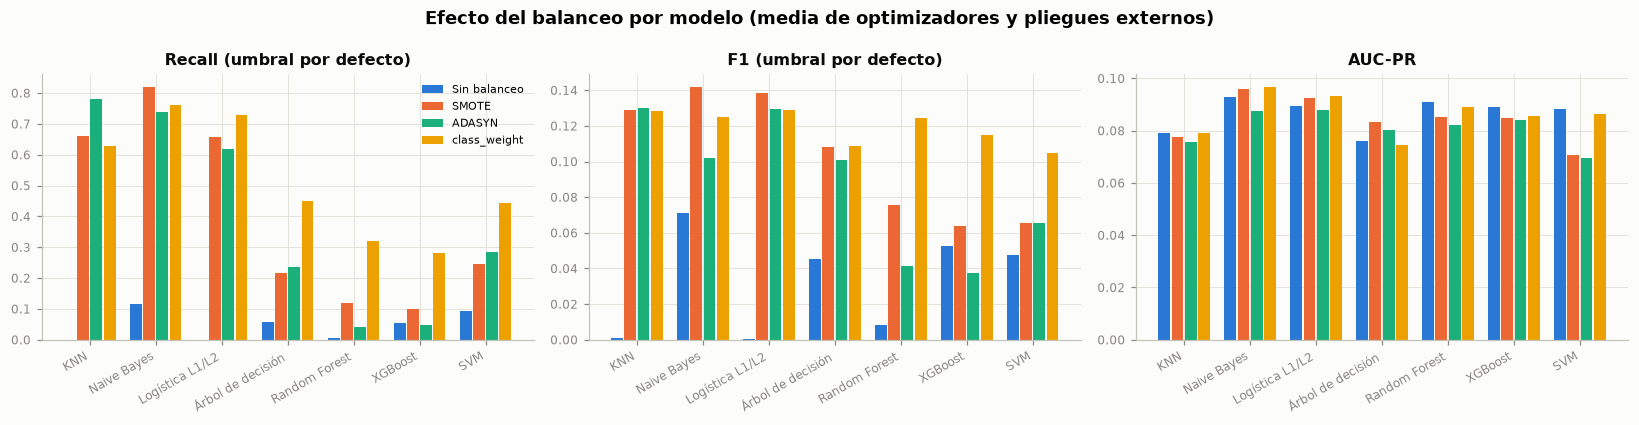

Técnica,Métrica,Diferencia media vs sin balanceo,p crudo,delta de Cliff,p Holm,Magnitud
SMOTE,recall,"0,3562","< 0,001","0,7862","< 0,001",grande
SMOTE,f1,"0,0708","< 0,001","0,6931","< 0,001",grande
SMOTE,auc_pr,"-0,0023","0,520","-0,0040","0,896",despreciable
SMOTE,brier,"0,1889","< 0,001","0,8037","< 0,001",grande
ADASYN,recall,"0,3452","< 0,001","0,7510","< 0,001",grande
ADASYN,f1,"0,0543","< 0,001","0,6558","< 0,001",grande
ADASYN,auc_pr,"-0,0055","0,029","-0,0186","0,087",despreciable
ADASYN,brier,"0,1841","< 0,001","0,7965","< 0,001",grande
class_weight,recall,"0,4691","< 0,001","0,9114","< 0,001",grande
class_weight,f1,"0,0869","< 0,001","0,7851","< 0,001",grande


**Interpretación.** Sin balanceo, el recall medio con el umbral por defecto es 0,047; con SMOTE sube a 0,403, con ADASYN a 0,392 y con class_weight a 0,516. El F1 pasa de 0,032 a 0,103, 0,087 y 0,119, mientras que el AUC-PR cambia en -0,0023, -0,0055 y -0,0002 y el Brier sube de 0,081 a 0,270, 0,265 y 0,298.

Esto significa que el balanceo funciona como un desplazamiento del umbral: al igualar las clases en el ajuste, las probabilidades suben y con el umbral de 0,5 se marcan más clientes, lo que eleva el recall y el F1. No mejora el orden de los clientes (el AUC-PR casi no cambia o baja) y empeora la calibración, porque las probabilidades dejan de reflejar la tasa real.

Por tal motivo, se opta por elegir el balanceo por el punto de operación que necesita el negocio y no por la discriminación: si el objetivo es encontrar más suscriptores con el umbral por defecto, class_weight logra el aumento de recall sin crear datos sintéticos; si se necesitan probabilidades para estimar el número esperado de suscripciones, conviene no balancear o recalibrar (sección 7.4).

In [62]:
met_bal = ["auc_pr", "auc", "recall", "precision", "f1", "brier"]
clf_n = clf_pl[clf_pl["optimizador"].isin(NUCLEO)]
bal = clf_n.groupby("balanceo")[met_bal].mean().loc[cfg.BALANCEOS]
bal.index = [NB[b_] for b_ in bal.index]
tabla(bal.rename(columns={"auc_pr": "AUC-PR", "auc": "AUC", "recall": "Recall", "precision": "Precision", "f1": "F1",
                          "brier": "Brier"}), dec=4)

fig, axs = plt.subplots(1, 3, figsize=(15, 3.9), sharey=False)
anchura = 0.2
for ax, met in zip(axs, ["recall", "f1", "auc_pr"]):
    g = clf_n.groupby(["modelo", "balanceo"])[met].mean().unstack().loc[cfg.MODELOS_CLF, cfg.BALANCEOS]
    x = np.arange(len(g))
    for j, b_ in enumerate(cfg.BALANCEOS):
        ax.bar(x + (j - 1.5) * anchura, g[b_], width=anchura - 0.02, color=COLOR_BAL[b_], label=NB[b_])
    ax.set_xticks(x, [NM[m_] for m_ in g.index], rotation=30, ha="right", fontsize=8)
    ax.set_title({"recall": "Recall (umbral por defecto)", "f1": "F1 (umbral por defecto)", "auc_pr": "AUC-PR"}[met])
axs[0].legend(fontsize=7)
fig.suptitle("Efecto del balanceo por modelo (media de optimizadores y pliegues externos)")
plt.tight_layout()
plt.show()

filas = []
for b_ in ["smote", "adasyn", "class_weight"]:
    for met in ["recall", "f1", "auc_pr", "brier"]:
        M = clf_n.pivot_table(index=["modelo", "optimizador", "pliegue"], columns="balanceo", values=met).dropna(
            subset=[b_, "ninguno"])
        w = wilcoxon(M[b_], M["ninguno"])
        filas.append({"Técnica": NB[b_], "Métrica": met, "Diferencia media vs sin balanceo": (M[b_] - M["ninguno"]).mean(),
                      "p crudo": w.pvalue, "delta de Cliff": st.delta_cliff(M[b_], M["ninguno"])})
pb = pd.DataFrame(filas)
pb["p Holm"] = st.ajustar_p(pb["p crudo"], "holm")
pb["Magnitud"] = pb["delta de Cliff"].apply(st.magnitud_cliff)
tabla(pb.assign(**{"p crudo": pb["p crudo"].map(pval), "p Holm": pb["p Holm"].map(pval)}), dec=4, indice=False)

r_ = pb.set_index(["Técnica", "Métrica"])
interpretar(
    f"Sin balanceo, el recall medio con el umbral por defecto es {num(bal.loc['Sin balanceo', 'recall'], 3)}; con SMOTE "
    f"sube a {num(bal.loc['SMOTE', 'recall'], 3)}, con ADASYN a {num(bal.loc['ADASYN', 'recall'], 3)} y con class_weight "
    f"a {num(bal.loc['class_weight', 'recall'], 3)}. El F1 pasa de {num(bal.loc['Sin balanceo', 'f1'], 3)} a "
    f"{enumerar([num(bal.loc[k, 'f1'], 3) for k in ('SMOTE', 'ADASYN', 'class_weight')], codigo=False)}, mientras que el "
    f"AUC-PR cambia en {enumerar([num(r_.loc[(k, 'auc_pr'), 'Diferencia media vs sin balanceo'], 4) for k in ('SMOTE', 'ADASYN', 'class_weight')], codigo=False)} "
    f"y el Brier sube de {num(bal.loc['Sin balanceo', 'brier'], 3)} a "
    f"{enumerar([num(bal.loc[k, 'brier'], 3) for k in ('SMOTE', 'ADASYN', 'class_weight') if np.isfinite(bal.loc[k, 'brier'])], codigo=False)}.",
    conectar("Esto significa que", "El balanceo funciona como un desplazamiento del umbral: al igualar las clases en el "
             "ajuste, las probabilidades suben y con el umbral de 0,5 se marcan más clientes, lo que eleva el recall y "
             "el F1. No mejora el orden de los clientes (el AUC-PR casi no cambia o baja) y empeora la calibración, "
             "porque las probabilidades dejan de reflejar la tasa real."),
    conectar("Por tal motivo, se opta por", "Elegir el balanceo por el punto de operación que necesita el negocio y no "
             "por la discriminación: si el objetivo es encontrar más suscriptores con el umbral por defecto, "
             "class_weight logra el aumento de recall sin crear datos sintéticos; si se necesitan probabilidades para "
             "estimar el número esperado de suscripciones, conviene no balancear o recalibrar (sección 7.4)."))

exportar("balanceo_modelo", clf_n.groupby(["modelo", "balanceo"])[met_bal].mean().reset_index().assign(
    Modelo=lambda d: d["modelo"].map(NM), Balanceo=lambda d: d["balanceo"].map(NB)))
exportar("balanceo_pruebas", pb)


### 7.3 Finalistas en el conjunto de prueba

Para cada modelo se toma la combinación (balanceo, optimizador) con mayor AUC-PR externo, se repite su optimización con todo el entrenamiento y se evalúa **una sola vez** en la prueba (último 20 %, de 2009 a 2010). Se agrega el modelo base del Entregable 2 (logística L2, C = 0,01, sin balanceo) como referencia. Las métricas de umbral usan el umbral por defecto (0,5 en probabilidad; 0 en la función de decisión de la SVM). Los intervalos de confianza al 95 % del AUC y del AUC-PR son *bootstrap* BCa con 1 000 réplicas.

Modelo,Balanceo,Optimizador,Accuracy,Precision,Recall,F1,AUC,AUC IC 95 %,AUC-PR,AUC-PR IC 95 %
KNN,class_weight,Grid Search,"0,444","0,345","0,895","0,498","0,688","[0,675; 0,701]","0,500","[0,478; 0,518]"
Naive Bayes,class_weight,Bayesiana (Optuna TPE),"0,524","0,377","0,840","0,521","0,714","[0,702; 0,727]","0,534","[0,515; 0,552]"
Logística L1/L2,SMOTE,Random Search,"0,394","0,326","0,907","0,480","0,681","[0,667; 0,695]","0,530","[0,507; 0,550]"
Árbol de decisión,SMOTE,Bayesiana (Optuna TPE),"0,659","0,417","0,271","0,329","0,567","[0,554; 0,580]","0,374","[0,357; 0,390]"
Random Forest,Sin balanceo,Bayesiana (Optuna TPE),"0,692","0,667","0,001","0,002","0,720","[0,708; 0,732]","0,503","[0,482; 0,521]"
XGBoost,class_weight,Genético (DEAP),"0,593","0,352","0,382","0,367","0,559","[0,546; 0,573]","0,369","[0,349; 0,386]"
SVM,class_weight,Grid Search,"0,411","0,337","0,937","0,495","0,724","[0,711; 0,736]","0,538","[0,516; 0,560]"
"Referencia E2 (logística C = 0,01)",Sin balanceo,—,"0,710","0,750","0,087","0,157","0,710","[0,696; 0,721]","0,548","[0,526; 0,568]"


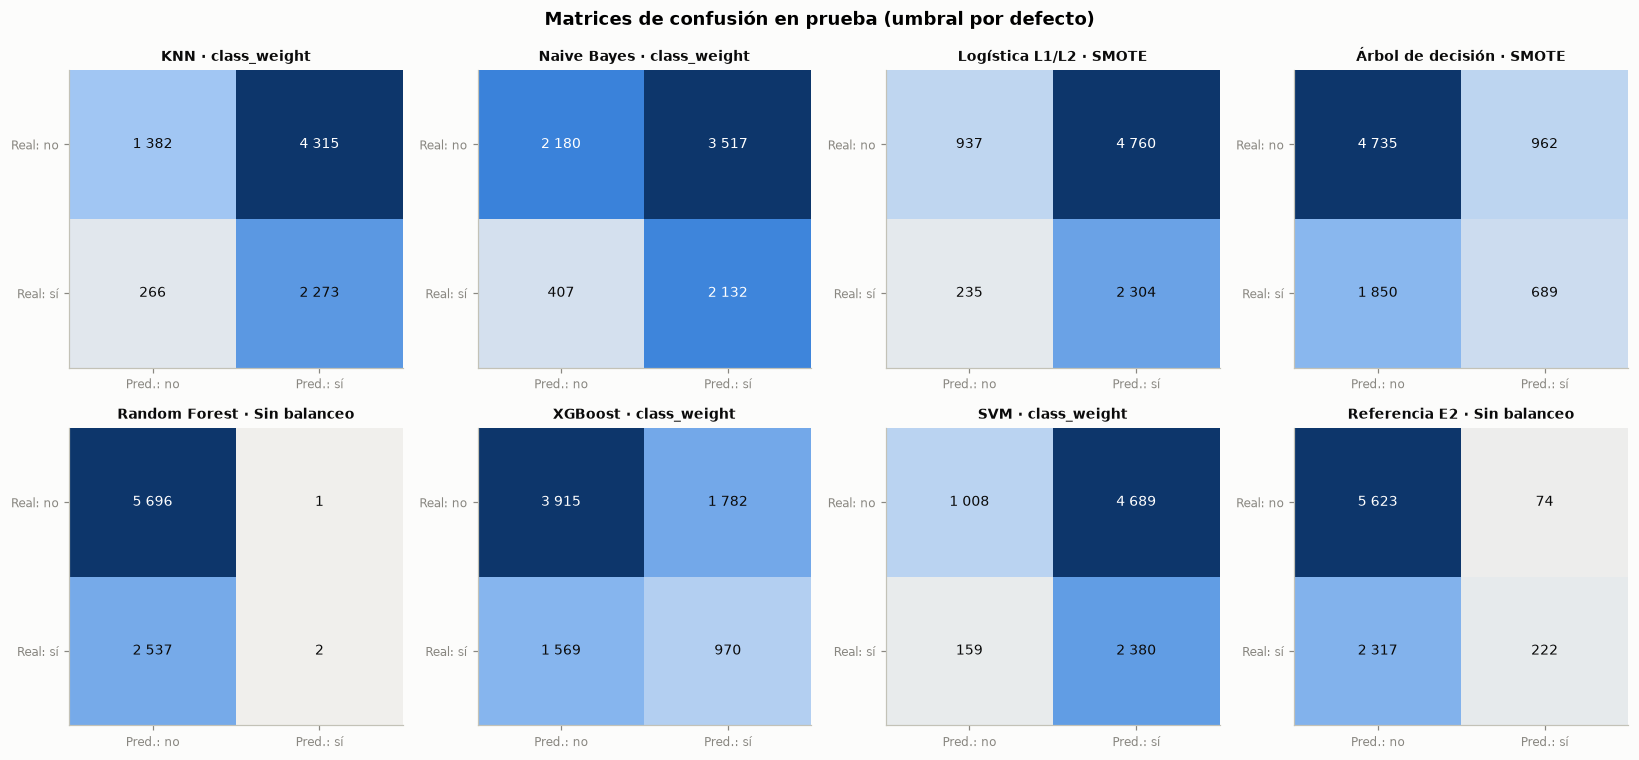

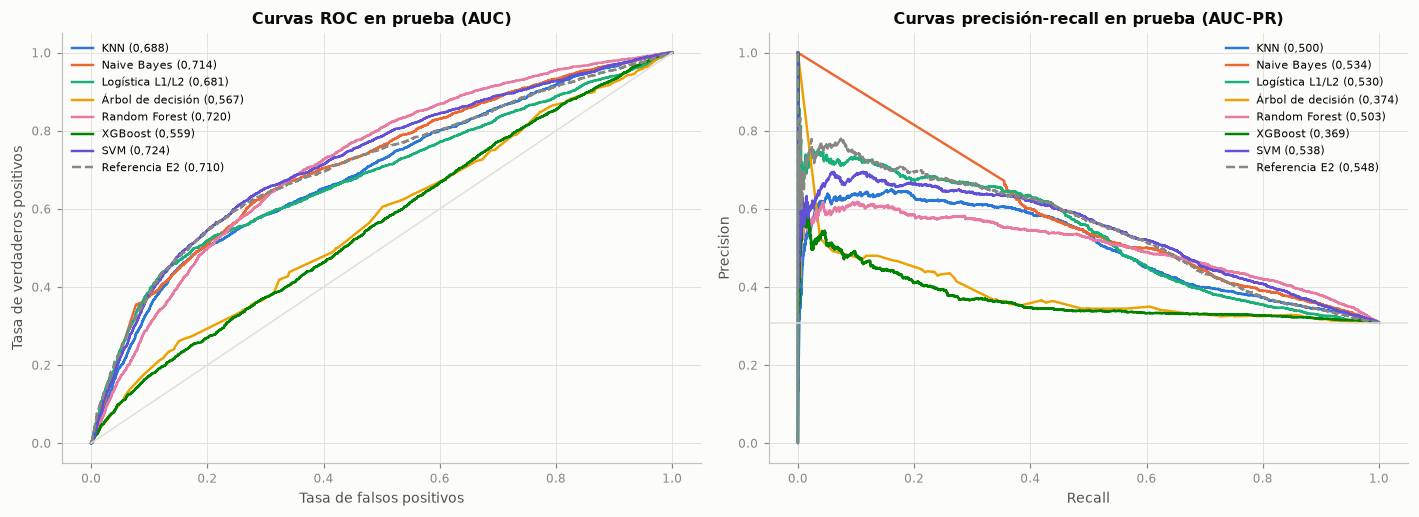

**Interpretación.** En prueba, el mayor AUC-PR es el de SVM (class_weight, Grid Search): 0,538 [0,516; 0,560], con AUC de 0,724 [0,711; 0,736]. La referencia del Entregable 2 obtiene un AUC-PR de 0,548 [0,526; 0,568] y un AUC de 0,710. El recall con el umbral por defecto va de 0,001 a 0,937, y la tasa de suscripción en prueba es del 30,8 %.

Lo anterior indica que el modelo base del Entregable 2, una logística con regularización fuerte y sin balanceo, iguala o supera a los finalistas optimizados en AUC-PR: con un cambio de régimen entre el entrenamiento y la prueba, la simplicidad y la regularización generalizan mejor que la flexibilidad. Hay que tener en cuenta que la prueba tiene una prevalencia casi cinco veces mayor que el entrenamiento: un AUC-PR aleatorio sería igual a esa prevalencia, de modo que las cifras de prueba no son comparables con las del bucle externo, donde la prevalencia era menor. El umbral por defecto, fijado con la tasa del entrenamiento, deja sin marcar a la mayoría de los suscriptores en los modelos sin balanceo; los modelos balanceados recuperan recall a costa de precisión. Los intervalos de confianza del AUC-PR de los dos mejores modelos se solapan, así que el orden entre ellos debe confirmarse con la prueba de DeLong (sección 8.2).

Por ello, se recomienda usar el ordenamiento (AUC y AUC-PR) para decidir a quién llamar primero, que es el uso del modelo, y fijar el punto de operación con probabilidades recalibradas al régimen vigente (sección 7.4) en lugar del umbral por defecto.

In [63]:
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

fin_clf = {k: v for k, v in finales.items() if v["tarea"] == "clf"}
orden_fin = [f"clf_{m_}" for m_ in cfg.MODELOS_CLF if f"clf_{m_}" in fin_clf] + ["clf_referencia_e2"]
yte = y_te.to_numpy()
filas = []
for k in orden_fin:
    f_ = fin_clf[k]
    s_ = f_["puntaje_te"]
    ic_auc = st.ic_bootstrap(roc_auc_score, yte, s_, n_rep=1000)
    ic_ap = st.ic_bootstrap(average_precision_score, yte, s_, n_rep=1000)
    filas.append({"Modelo": "Referencia E2 (logística C = 0,01)" if k.endswith("e2") else NM[f_["modelo"]],
                  "Balanceo": NB[f_["balanceo"]], "Optimizador": NO.get(f_["optimizador"], "—"),
                  "Accuracy": f_["accuracy"], "Precision": f_["precision"], "Recall": f_["recall"], "F1": f_["f1"],
                  "AUC": f_["auc"], "AUC IC 95 %": f"[{num(ic_auc[0], 3)}; {num(ic_auc[1], 3)}]",
                  "AUC-PR": f_["auc_pr"], "AUC-PR IC 95 %": f"[{num(ic_ap[0], 3)}; {num(ic_ap[1], 3)}]",
                  "ic_auc": ic_auc, "ic_ap": ic_ap, "clave": k})
res_te = pd.DataFrame(filas)
tabla(res_te.drop(columns=["ic_auc", "ic_ap", "clave"]), dec=3, indice=False)

fig, axs = plt.subplots(2, 4, figsize=(15, 7))
for ax, k in zip(axs.ravel(), orden_fin):
    f_ = fin_clf[k]
    cm = confusion_matrix(yte, f_["pred_te"].astype(int))
    mapa_calor(ax, cm, ["Real: no", "Real: sí"], ["Pred.: no", "Pred.: sí"], CMAP_SEQ, 0, cm.max(), dec=0, tam=9)
    ax.set_title(("Referencia E2" if k.endswith("e2") else NM[f_["modelo"]]) + f" · {NB[f_['balanceo']]}", fontsize=9)
    plt.setp(ax.get_xticklabels(), rotation=0, ha="center")
fig.suptitle("Matrices de confusión en prueba (umbral por defecto)")
plt.tight_layout()
plt.show()

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
for k in orden_fin:
    f_ = fin_clf[k]
    col = GRIS if k.endswith("e2") else COLOR_MODELO[f_["modelo"]]
    nombre = "Referencia E2" if k.endswith("e2") else NM[f_["modelo"]]
    fpr, tpr, _ = roc_curve(yte, f_["puntaje_te"])
    axs[0].plot(fpr, tpr, color=col, lw=1.6, ls="--" if k.endswith("e2") else "-", label=f"{nombre} ({num(f_['auc'], 3)})")
    pr_, rc_, _ = curva_pr(yte, f_["puntaje_te"])
    axs[1].plot(rc_, pr_, color=col, lw=1.6, ls="--" if k.endswith("e2") else "-", label=f"{nombre} ({num(f_['auc_pr'], 3)})")
axs[0].plot([0, 1], [0, 1], color=REJILLA, lw=1)
axs[1].axhline(yte.mean(), color=REJILLA, lw=1)
axs[0].set(title="Curvas ROC en prueba (AUC)", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos")
axs[1].set(title="Curvas precisión-recall en prueba (AUC-PR)", xlabel="Recall", ylabel="Precision")
for ax in axs:
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

mod_ = res_te[~res_te["clave"].str.endswith("e2")]
mejor_te = mod_.loc[mod_["AUC-PR"].idxmax()]
refe = res_te[res_te["clave"].str.endswith("e2")].iloc[0]
interpretar(
    f"En prueba, el mayor AUC-PR es el de {mejor_te['Modelo']} ({mejor_te['Balanceo']}, {mejor_te['Optimizador']}): "
    f"{num(mejor_te['AUC-PR'], 3)} {mejor_te['AUC-PR IC 95 %']}, con AUC de {num(mejor_te['AUC'], 3)} "
    f"{mejor_te['AUC IC 95 %']}. La referencia del Entregable 2 obtiene un AUC-PR de {num(refe['AUC-PR'], 3)} "
    f"{refe['AUC-PR IC 95 %']} y un AUC de {num(refe['AUC'], 3)}. El recall con el umbral por defecto va de "
    f"{num(res_te['Recall'].min(), 3)} a {num(res_te['Recall'].max(), 3)}, y la tasa de suscripción en prueba es del "
    f"{pct(yte.mean())}.",
    (("Lo anterior indica que el modelo base del Entregable 2, una logística con regularización fuerte y sin "
      "balanceo, iguala o supera a los finalistas optimizados en AUC-PR: con un cambio de régimen entre el "
      "entrenamiento y la prueba, la simplicidad y la regularización generalizan mejor que la flexibilidad. "
      if refe["AUC-PR"] >= mejor_te["AUC-PR"] else "") +
     conectar("Hay que tener en cuenta que", "La prueba tiene una prevalencia casi cinco veces mayor que el entrenamiento: "
             "un AUC-PR aleatorio sería igual a esa prevalencia, de modo que las cifras de prueba no son comparables con "
             "las del bucle externo, donde la prevalencia era menor. El umbral por defecto, fijado con la tasa del "
             "entrenamiento, deja sin marcar a la mayoría de los suscriptores en los modelos sin balanceo; los modelos "
             "balanceados recuperan recall a costa de precisión."
             + (" Los intervalos de confianza del AUC-PR de los dos mejores modelos se solapan, así que el orden entre "
                "ellos debe confirmarse con la prueba de DeLong (sección 8.2)."
                if (lambda d: d["ic_ap"].iloc[0][0] <= d["ic_ap"].iloc[1][1])(res_te.sort_values("AUC-PR", ascending=False))
                else " Los intervalos de confianza del AUC-PR de los dos mejores modelos no se solapan."))),
    conectar("Por ello, se recomienda", "Usar el ordenamiento (AUC y AUC-PR) para decidir a quién llamar primero, que es "
             "el uso del modelo, y fijar el punto de operación con probabilidades recalibradas al régimen vigente "
             "(sección 7.4) en lugar del umbral por defecto."))

exportar("finalistas_prueba", res_te.drop(columns=["ic_auc", "ic_ap"]).assign(
    auc_inf=[v[0] for v in res_te["ic_auc"]], auc_sup=[v[1] for v in res_te["ic_auc"]],
    ap_inf=[v[0] for v in res_te["ic_ap"]], ap_sup=[v[1] for v in res_te["ic_ap"]]))
filas_c = []
for k in orden_fin:
    f_ = fin_clf[k]
    nombre = "Referencia E2" if k.endswith("e2") else NM[f_["modelo"]]
    fpr, tpr, _ = roc_curve(yte, f_["puntaje_te"])
    sel = np.unique(np.linspace(0, len(fpr) - 1, 250).astype(int))
    filas_c += [{"modelo": nombre, "curva": "ROC", "x": a, "y": b} for a, b in zip(fpr[sel], tpr[sel])]
    pr_, rc_, _ = curva_pr(yte, f_["puntaje_te"])
    sel = np.unique(np.linspace(0, len(pr_) - 1, 250).astype(int))
    filas_c += [{"modelo": nombre, "curva": "PR", "x": a, "y": b} for a, b in zip(rc_[sel], pr_[sel])]
    cm = confusion_matrix(yte, f_["pred_te"].astype(int))
    filas_c += [{"modelo": nombre, "curva": "CM", "x": i, "y": j, "valor": int(cm[i, j])} for i in range(2) for j in range(2)]
exportar("curvas_prueba", pd.DataFrame(filas_c))


### 7.4 Calibración de probabilidades

Para cada finalista con probabilidades se evalúa la calibración en prueba con el diagrama de confiabilidad (10 *bins* de igual ancho), el Brier y el error de calibración esperado (ECE). Se comparan tres recalibraciones, ajustadas sin usar la prueba:

- **Platt** (sigmoide) e **isotónica**: el modelo se reajusta con el primer 80 % del entrenamiento y el calibrador con el 20 % final, de modo que ve probabilidades fuera de muestra. Para la SVM, Platt es además la forma de obtener probabilidades a partir de su función de decisión.
- **Mensual del intercepto** (método del Entregable 2, generalizado): cada mes se desplaza el logit para que la probabilidad media iguale la tasa observada del mes anterior, ya cerrado. Corrige el cambio de prevalencia (*prior shift*; Saerens et al., 2002), que Platt y la isotónica no pueden anticipar porque se ajustan con datos de entrenamiento.

Modelo,Balanceo,Variante,Brier,ECE,Prob. media,AUC-PR,"F1 (umbral 0,5)"
KNN,class_weight,Sin recalibrar,"0,2990","0,3232","0,6283","0,4998","0,4981"
KNN,class_weight,Platt,"0,2506","0,1939","0,1144","0,3255","0,0000"
KNN,class_weight,Isotónica,"0,2497","0,1942","0,1143","0,3382","0,0000"
KNN,class_weight,Mensual (intercepto),"0,1764","0,0382","0,2834","0,5770","0,4883"
Naive Bayes,class_weight,Sin recalibrar,"0,4049","0,4109","0,7166","0,5343","0,5208"
Naive Bayes,class_weight,Platt,"0,2470","0,2199","0,0883","0,4644","0,0000"
Naive Bayes,class_weight,Isotónica,"0,2263","0,1885","0,1198","0,4356","0,0000"
Naive Bayes,class_weight,Mensual (intercepto),"0,2664","0,2356","0,3446","0,4777","0,5204"
Logística L1/L2,SMOTE,Sin recalibrar,"0,3050","0,3349","0,6432","0,5297","0,4799"
Logística L1/L2,SMOTE,Platt,"0,2459","0,1876","0,1277","0,3681","0,0807"


Tasa real de suscripción en prueba: 0,3083


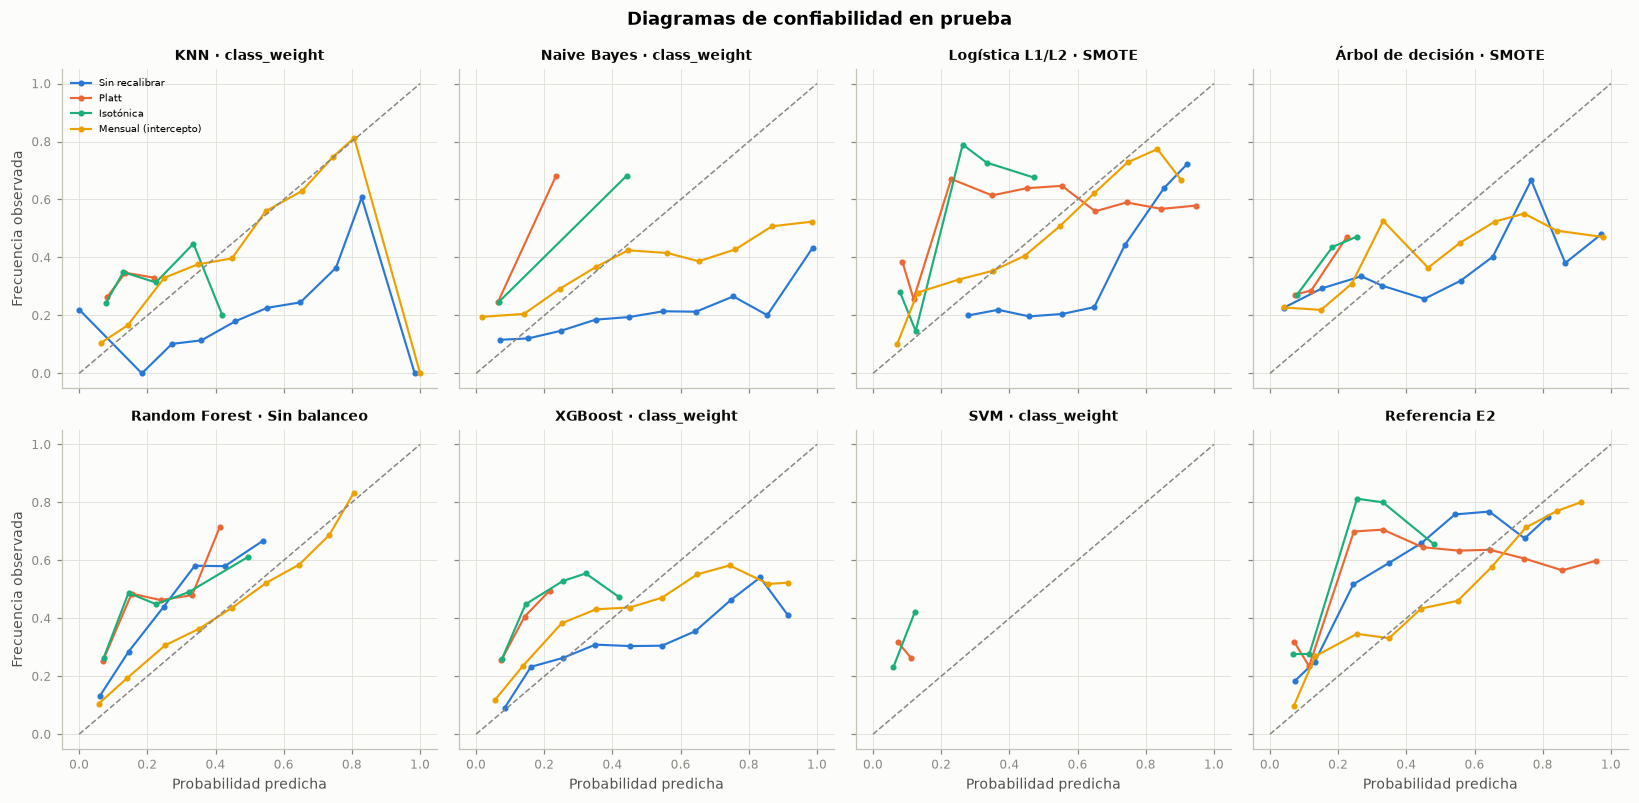

**Interpretación.** Sin recalibrar, el ECE en prueba va de 0,136 a 0,411 y la probabilidad media de 0,167 a 0,717, frente a una tasa real de 0,308. La mediana del ECE por variante es de 0,055 (Mensual (intercepto)), 0,189 (Sin recalibrar), 0,201 (Isotónica) y 0,204 (Platt).

Esto significa que la descalibración en prueba está dominada por el cambio de prevalencia: los modelos sin balanceo subestiman la probabilidad porque aprendieron con una tasa del 6 %, y los balanceados la distorsionan en la dirección contraria dentro del entrenamiento. Platt y la isotónica corrigen la forma de la curva con la tasa del final del entrenamiento, pero no pueden anticipar el régimen nuevo; la recalibración mensual sí lo sigue porque usa la tasa del mes que acaba de cerrar. Así mismo, desplazar el intercepto por mes equivale, en el espacio del logit, a desplazar el umbral de decisión (0,5 en probabilidad corresponde a logit = 0): por eso también sube el F1 con el umbral por defecto en 5 de los 7 finalistas (de 0,157 a 0,494 en la Referencia E2) y el AUC-PR en 6 de 7, porque el desplazamiento no es un solo valor para toda la prueba sino uno distinto por mes, capaz de reordenar clientes entre periodos y no solo de mover la curva. La excepción es Naive Bayes, donde ambas métricas empeoran porque su probabilidad ya estaba distorsionada por el supuesto de independencia condicional antes de recalibrar.

Por tal motivo, se opta por la variante con menor ECE mediano (Mensual (intercepto)) para cualquier uso que dependa del valor de la probabilidad (por ejemplo, estimar cuántas suscripciones dará una campaña), y documentar que exige observar las etiquetas de cada mes cerrado antes de predecir el siguiente; de paso, resuelve el problema del umbral de 0,5 sin necesidad de ajustarlo aparte.

In [64]:
with open(RES / "finales" / "recalibracion.pkl", "rb") as f:
    recal = pickle.load(f)
ult_mes = periodo_tr.iloc[-1]
m_ult = (periodo_tr == ult_mes).to_numpy()
filas, variantes_graf = [], {}
for k in orden_fin:
    f_, rc = fin_clf[k], recal[k]
    var = {"Sin recalibrar": f_["puntaje_te"] if f_["es_proba"] else None, "Platt": rc["platt"],
           "Isotónica": rc["isotonica"]}
    if f_["es_proba"]:
        var["Mensual (intercepto)"] = evm.recalibracion_mensual(f_["puntaje_te"], yte, periodo_te.to_numpy(),
                                                                f_["puntaje_tr"][m_ult], y_tr.to_numpy()[m_ult])
    variantes_graf[k] = var
    for v_, p_ in var.items():
        if p_ is None:
            continue
        filas.append({"Modelo": "Referencia E2" if k.endswith("e2") else NM[f_["modelo"]], "Balanceo": NB[f_["balanceo"]],
                      "Variante": v_, "Brier": brier_score_loss(yte, p_), "ECE": evm.ece(yte, p_),
                      "Prob. media": float(np.mean(p_)), "AUC-PR": average_precision_score(yte, p_),
                      "F1 (umbral 0,5)": f1_score(yte, p_ >= 0.5), "clave": k})
cal = pd.DataFrame(filas)
tabla(cal.drop(columns="clave"), dec=4, indice=False)
print(f"Tasa real de suscripción en prueba: {num(yte.mean(), 4)}")

fig, axs = plt.subplots(2, 4, figsize=(15, 7.4), sharex=True, sharey=True)
for ax, k in zip(axs.ravel(), orden_fin):
    for i, (v_, p_) in enumerate(variantes_graf[k].items()):
        if p_ is None:
            continue
        cc = evm.curva_confiabilidad(yte, p_)
        ax.plot(cc["prob_media"], cc["frecuencia"], marker="o", ms=3, lw=1.4, color=CAT[i], label=v_)
    ax.plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1)
    ax.set_title("Referencia E2" if k.endswith("e2") else f"{NM[fin_clf[k]['modelo']]} · {NB[fin_clf[k]['balanceo']]}",
                 fontsize=9)
axs[0, 0].legend(fontsize=6.5)
for ax in axs[-1]:
    ax.set_xlabel("Probabilidad predicha")
for ax in axs[:, 0]:
    ax.set_ylabel("Frecuencia observada")
fig.suptitle("Diagramas de confiabilidad en prueba")
plt.tight_layout()
plt.show()

mejor_var = cal.groupby("Variante")["ECE"].median().sort_values()
sr = cal[cal["Variante"] == "Sin recalibrar"]
piv_f1 = cal.pivot(index="Modelo", columns="Variante", values="F1 (umbral 0,5)").dropna(subset=["Sin recalibrar", "Mensual (intercepto)"])
piv_pr = cal.pivot(index="Modelo", columns="Variante", values="AUC-PR").dropna(subset=["Sin recalibrar", "Mensual (intercepto)"])
mejora_f1 = piv_f1["Mensual (intercepto)"] > piv_f1["Sin recalibrar"]
mejora_pr = piv_pr["Mensual (intercepto)"] > piv_pr["Sin recalibrar"]
excepcion = piv_pr.index[~mejora_pr][0] if (~mejora_pr).any() else None
ref_f1_antes, ref_f1_despues = piv_f1.loc["Referencia E2", "Sin recalibrar"], piv_f1.loc["Referencia E2", "Mensual (intercepto)"]
interpretar(
    f"Sin recalibrar, el ECE en prueba va de {num(sr['ECE'].min(), 3)} a {num(sr['ECE'].max(), 3)} y la probabilidad "
    f"media de {num(sr['Prob. media'].min(), 3)} a {num(sr['Prob. media'].max(), 3)}, frente a una tasa real de "
    f"{num(yte.mean(), 3)}. La mediana del ECE por variante es de "
    f"{enumerar([num(v, 3) + ' (' + k + ')' for k, v in mejor_var.items()], codigo=False)}.",
    conectar("Esto significa que", "La descalibración en prueba está dominada por el cambio de prevalencia: los modelos "
             "sin balanceo subestiman la probabilidad porque aprendieron con una tasa del 6 %, y los balanceados la "
             "distorsionan en la dirección contraria dentro del entrenamiento. Platt y la isotónica corrigen la forma "
             "de la curva con la tasa del final del entrenamiento, pero no pueden anticipar el régimen nuevo; la "
             "recalibración mensual sí lo sigue porque usa la tasa del mes que acaba de cerrar. Así mismo, desplazar el "
             "intercepto por mes equivale, en el espacio del logit, a desplazar el umbral de decisión (0,5 en "
             f"probabilidad corresponde a logit = 0): por eso también sube el F1 con el umbral por defecto en "
             f"{mejora_f1.sum()} de los {len(mejora_f1)} finalistas (de {num(ref_f1_antes, 3)} a {num(ref_f1_despues, 3)} "
             f"en la Referencia E2) y el AUC-PR en {mejora_pr.sum()} de {len(mejora_pr)}, porque el desplazamiento no es "
             "un solo valor para toda la prueba sino uno distinto por mes, capaz de reordenar clientes entre periodos y "
             f"no solo de mover la curva. La excepción es {excepcion}, donde ambas métricas empeoran porque su "
             "probabilidad ya estaba distorsionada por el supuesto de independencia condicional antes de recalibrar."),
    conectar(f"Por tal motivo, se opta por", f"La variante con menor ECE mediano ({mejor_var.index[0]}) para cualquier uso "
             "que dependa del valor de la probabilidad (por ejemplo, estimar cuántas suscripciones dará una campaña), y "
             "documentar que exige observar las etiquetas de cada mes cerrado antes de predecir el siguiente; de paso, "
             "resuelve el problema del umbral de 0,5 sin necesidad de ajustarlo aparte."))

exportar("calibracion", cal)
exportar("calibracion_curvas", pd.DataFrame([{"modelo": "Referencia E2" if k.endswith("e2") else NM[fin_clf[k]["modelo"]],
    "variante": v_, **r_} for k in orden_fin for v_, p_ in variantes_graf[k].items() if p_ is not None
    for r_ in evm.curva_confiabilidad(yte, p_).to_dict("records")]))


### 7.5 Regresión: duración de la llamada

Los finalistas de regresión se evalúan en prueba con RMSE y MAE en escala `log1p(duration)` y en segundos, frente al pronóstico de la media del entrenamiento. Para cada uno se reportan las pruebas de White (homocedasticidad, versión especial con ŷ y ŷ²) y BDS (independencia, dimensión 2, sobre los últimos 2 000 residuos en orden temporal).

Modelo,Optimizador,RMSE (log),MAE (log),RMSE (s),MAE (s),R²,p White,p BDS (m = 2)
KNN,Genético (DEAP),"0,9342","0,6955","258,8261","155,4867","0,0427","< 0,001","< 0,001"
Ridge,Random Search,"0,9375","0,6927","256,3659","154,8141","0,0360","< 0,001","< 0,001"
Lasso,Genético (DEAP),"0,9459","0,7089","266,6585","157,9900","0,0186","< 0,001","< 0,001"
Árbol de decisión,Grid Search,"0,9166","0,6925","258,0030","155,2728","0,0784","< 0,001","< 0,001"
Random Forest,Random Search,"0,9120","0,6896","261,7158","154,7025","0,0877","< 0,001","< 0,001"
XGBoost,Bayesiana (Optuna TPE),"0,9298","0,6973","263,0896","156,0172","0,0518","< 0,001","< 0,001"
SVR,Genético (DEAP),"0,9639","0,7081","253,9521","159,2287","-0,0190","< 0,001","< 0,001"
Media del entrenamiento (referencia),—,"0,9563","0,7154","268,1270","159,1151","-0,0030",—,—


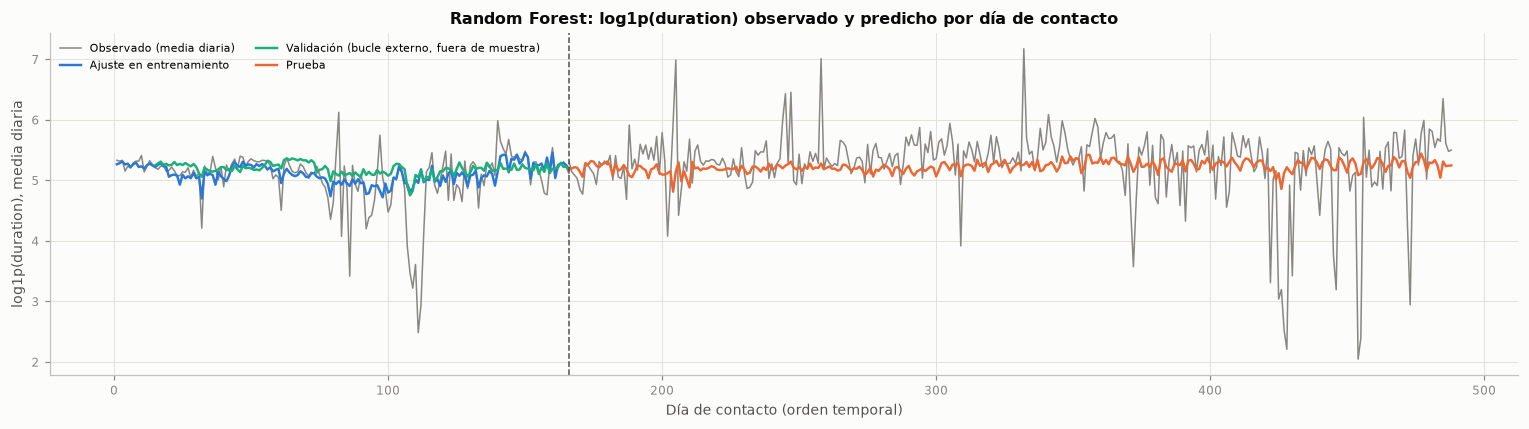

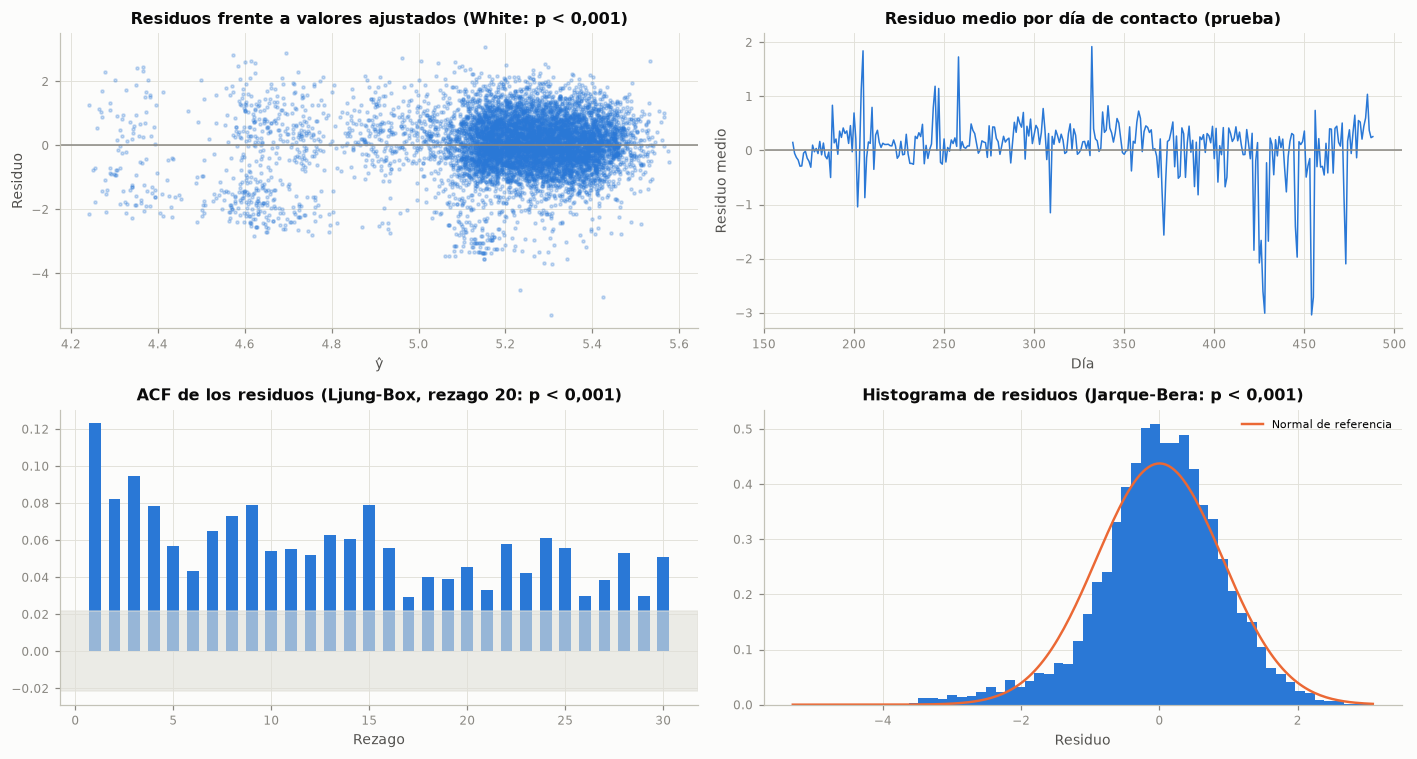

**Interpretación.** El mejor finalista de regresión es Random Forest, con un RMSE de 0,9120 en escala log (262 s) y un R² de 0,088; la media del entrenamiento logra un RMSE de 0,9563 y un R² de -0,003. En sus residuos, White da p < 0,001, BDS p < 0,001, Ljung-Box en el rezago 20 p < 0,001 y Jarque-Bera p < 0,001 (asimetría -0,60, curtosis en exceso 1,40).

Esto quiere decir que con información previa a la llamada el mejor modelo explica apenas el 9 % de la varianza de la duración: el RMSE baja un 4,6 % frente a la media del entrenamiento. Las predicciones siguen el nivel medio por día, pero no anticipan qué llamadas serán muy cortas o muy largas. Los residuos heredan entonces la estructura de la propia duración: colas pesadas (no normalidad), varianza que cambia con el nivel y dependencia serial entre llamadas cercanas en el tiempo, que el modelo no captura porque no usa información temporal.

En consecuencia, se decide reportar la rama de regresión como un resultado de señal débil: útil, a lo sumo, para estimar la carga media de un día, pero no para planificar llamadas individuales, porque la duración depende sobre todo de lo que ocurre durante la llamada. La sección 8.3 verifica con el Model Confidence Set si la mejora frente a la media es estadísticamente distinguible.

In [65]:
fin_reg = {k: v for k, v in finales.items() if v["tarea"] == "reg"}
orden_reg = [f"reg_{m_}" for m_ in cfg.MODELOS_REG if f"reg_{m_}" in fin_reg]
rte, rtr = part.r_te.to_numpy(), part.r_tr.to_numpy()
media_tr = rtr.mean()
filas, diag = [], {}
for k in orden_reg + ["media"]:
    pred = fin_reg[k]["pred_te"] if k != "media" else np.full_like(rte, media_tr)
    d_ = evm.diagnostico_residuos(rte, pred) if k != "media" else None
    diag[k] = d_
    filas.append({"Modelo": NM[fin_reg[k]["modelo"]] if k != "media" else "Media del entrenamiento (referencia)",
                  "Optimizador": NO[fin_reg[k]["optimizador"]] if k != "media" else "—",
                  "RMSE (log)": root_mean_squared_error(rte, pred), "MAE (log)": mean_absolute_error(rte, pred),
                  "RMSE (s)": root_mean_squared_error(np.expm1(rte), np.expm1(pred)),
                  "MAE (s)": mean_absolute_error(np.expm1(rte), np.expm1(pred)), "R²": r2_score(rte, pred),
                  "p White": d_["p_white"] if d_ else np.nan, "p BDS (m = 2)": d_["p_bds"][0] if d_ else np.nan,
                  "clave": k})
res_reg = pd.DataFrame(filas)
tabla(res_reg.drop(columns="clave").assign(**{"p White": res_reg["p White"].map(lambda v: pval(v) if np.isfinite(v) else "—"),
                                              "p BDS (m = 2)": res_reg["p BDS (m = 2)"].map(lambda v: pval(v) if np.isfinite(v) else "—")}),
      dec=4, indice=False)

mejor_r = res_reg[res_reg["clave"] != "media"].sort_values("RMSE (log)").iloc[0]
kr = mejor_r["clave"]
fr_ = fin_reg[kr]
oof_r = oof[(oof["tarea"] == "reg") & (oof["modelo"] == fr_["modelo"]) & (oof["optimizador"] == fr_["optimizador"])]
dia_media = lambda idx, v: pd.Series(v, index=idx).groupby(tiempo.loc[idx, "dia"].to_numpy()).mean()
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(dia_media(X_tr.index, rtr), color=GRIS, lw=1, label="Observado (media diaria)")
ax.plot(dia_media(X_te.index, rte), color=GRIS, lw=1)
ax.plot(dia_media(X_tr.index, fr_["puntaje_tr"]), color=AZUL, lw=1.6, label="Ajuste en entrenamiento")
ax.plot(dia_media(pd.Index(oof_r["indice"]), oof_r["pred"].to_numpy()), color=AGUAMARINA, lw=1.6,
        label="Validación (bucle externo, fuera de muestra)")
ax.plot(dia_media(X_te.index, fr_["pred_te"]), color=NARANJA, lw=1.6, label="Prueba")
ax.axvline(tiempo.loc[X_te.index[0], "dia"], color=TINTA_2, ls="--", lw=1)
ax.set(title=f"{NM[fr_['modelo']]}: log1p(duration) observado y predicho por día de contacto",
       xlabel="Día de contacto (orden temporal)", ylabel="log1p(duration), media diaria")
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

d_ = diag[kr]
e_ = rte - fr_["pred_te"]
fig, axs = plt.subplots(2, 2, figsize=(13, 7))
axs[0, 0].scatter(fr_["pred_te"], e_, s=4, alpha=0.25, color=AZUL)
axs[0, 0].axhline(0, color=GRIS, lw=1)
axs[0, 0].set(title=f"Residuos frente a valores ajustados (White: {p_txt(d_['p_white'])})", xlabel="ŷ", ylabel="Residuo")
axs[0, 1].plot(dia_media(X_te.index, e_), color=AZUL, lw=1)
axs[0, 1].axhline(0, color=GRIS, lw=1)
axs[0, 1].set(title="Residuo medio por día de contacto (prueba)", xlabel="Día", ylabel="Residuo medio")
acf_v = acf(e_, nlags=30)
axs[1, 0].bar(range(1, 31), acf_v[1:], color=AZUL, width=0.6)
lim = 1.96 / np.sqrt(len(e_))
axs[1, 0].axhspan(-lim, lim, color=REJILLA, alpha=0.6)
lb = pd.DataFrame(d_["ljung_box"])
axs[1, 0].set(title=f"ACF de los residuos (Ljung-Box, rezago 20: {p_txt(lb['lb_pvalue'].iloc[-1])})", xlabel="Rezago")
axs[1, 1].hist(e_, bins=60, color=AZUL, density=True)
xx = np.linspace(e_.min(), e_.max(), 200)
axs[1, 1].plot(xx, stats.norm.pdf(xx, e_.mean(), e_.std()), color=NARANJA, lw=1.6, label="Normal de referencia")
axs[1, 1].set(title=f"Histograma de residuos (Jarque-Bera: {p_txt(d_['p_jarque_bera'])})", xlabel="Residuo")
axs[1, 1].legend(fontsize=7)
plt.tight_layout()
plt.show()

ref_r = res_reg[res_reg["clave"] == "media"].iloc[0]
interpretar(
    f"El mejor finalista de regresión es {mejor_r['Modelo']}, con un RMSE de {num(mejor_r['RMSE (log)'], 4)} en escala log "
    f"({num(mejor_r['RMSE (s)'], 0)} s) y un R² de {num(mejor_r['R²'], 3)}; la media del entrenamiento logra un RMSE de "
    f"{num(ref_r['RMSE (log)'], 4)} y un R² de {num(ref_r['R²'], 3)}. En sus residuos, White da {p_txt(d_['p_white'])}, "
    f"BDS {p_txt(d_['p_bds'][0])}, Ljung-Box en el rezago 20 {p_txt(lb['lb_pvalue'].iloc[-1])} y Jarque-Bera "
    f"{p_txt(d_['p_jarque_bera'])} (asimetría {num(d_['asimetria'], 2)}, curtosis en exceso {num(d_['curtosis'], 2)}).",
    conectar("Esto quiere decir que", f"Con información previa a la llamada el mejor modelo explica apenas el "
             f"{pct(max(mejor_r['R²'], 0), 0)} de la varianza de la duración: el RMSE baja un "
             f"{pct(1 - mejor_r['RMSE (log)'] / ref_r['RMSE (log)'], 1)} frente a la media del entrenamiento. Las "
             "predicciones siguen el nivel medio por día, pero no anticipan qué llamadas serán muy cortas o muy largas. "
             "Los residuos heredan entonces la estructura de la propia duración: "
             "colas pesadas (no normalidad), varianza que cambia con el nivel y dependencia serial entre llamadas "
             "cercanas en el tiempo, que el modelo no captura porque no usa información temporal."),
    conectar("En consecuencia, se decide", "Reportar la rama de regresión como un resultado de señal débil: útil, a lo "
             "sumo, para estimar la carga media de un día, pero no para planificar llamadas individuales, porque la "
             "duración depende sobre todo de lo que ocurre durante la llamada. La sección 8.3 verifica con el Model "
             "Confidence Set si la mejora frente a la media es estadísticamente distinguible."))

exportar("regresion_prueba", res_reg)
serie = pd.concat([dia_media(X_tr.index, rtr).rename("observado").to_frame().assign(conjunto="entrenamiento"),
                   dia_media(X_te.index, rte).rename("observado").to_frame().assign(conjunto="prueba")])
serie["predicho"] = pd.concat([dia_media(X_tr.index, fr_["puntaje_tr"]), dia_media(X_te.index, fr_["pred_te"])]).values
serie["validacion"] = dia_media(pd.Index(oof_r["indice"]), oof_r["pred"].to_numpy()).reindex(serie.index).values
exportar("regresion_serie", serie.reset_index(names="dia"))
exportar("regresion_residuos", {"modelo": NM[fr_["modelo"]], "acf": acf_v[1:].tolist(), "lim": lim,
                                "hist": np.histogram(e_, bins=40)[0].tolist(),
                                "bordes": np.histogram(e_, bins=40)[1].tolist(), "p_white": d_["p_white"],
                                "p_bds": d_["p_bds"], "p_jb": d_["p_jarque_bera"],
                                "ljung_box": lb.to_dict("records")})


### 7.6 Interpretabilidad global y local: SHAP y LIME

Los valores de Shapley (Lundberg y Lee, 2017) reparten la diferencia entre la predicción de una observación y la predicción media entre las variables, cumpliendo eficiencia (las contribuciones suman esa diferencia), simetría y aditividad. Para los modelos de árboles se usa `TreeExplainer`, que los calcula de forma exacta y rápida (Lundberg et al., 2020); para los demás, un explicador por permutaciones. Las explicaciones se calculan sobre las columnas preprocesadas (después del *one-hot*), en la escala de salida del modelo (log-odds en XGBoost).

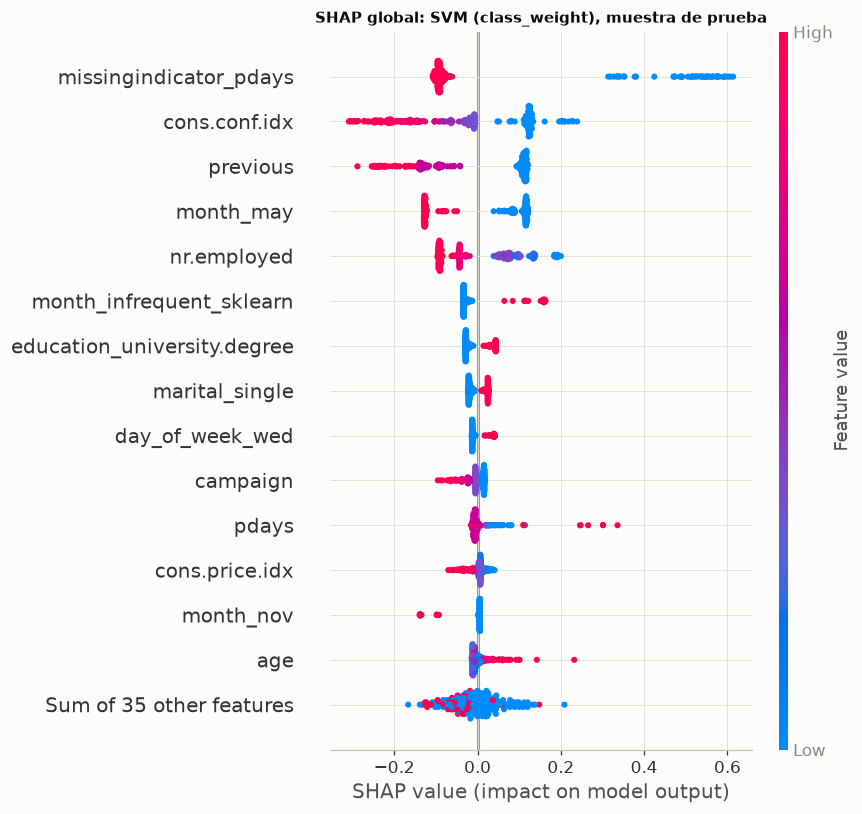

,Media |SHAP|
missingindicator_pdays,"0,1587"
cons.conf.idx,"0,1254"
previous,"0,1238"
month_may,"0,1139"
nr.employed,"0,0836"
month_infrequent_sklearn,"0,0496"
education_university.degree,"0,0308"
marital_single,"0,0204"
day_of_week_wed,"0,0170"
campaign,"0,0163"


In [66]:
from sklearn.tree import DecisionTreeClassifier

def explicar(f_, X, n=1000, seed=SEED):
    """Valores SHAP del modelo final sobre una muestra de X, en el espacio preprocesado."""
    pipe = f_["pipeline"]
    pre = pipe.named_steps["pre"]
    nombres = [n_.split("__", 1)[-1] for n_ in pre.get_feature_names_out()]
    Z = pd.DataFrame(pre.transform(X), columns=nombres, index=X.index)
    muestra = Z.sample(min(n, len(Z)), random_state=seed)
    mod = pipe.named_steps["modelo"]
    resto = [paso for nom, paso in pipe.steps if nom not in ("pre", "bal")]
    if f_["modelo"] in ("xgboost", "bosque", "arbol") and len(resto) == 1:
        exp = shap.TreeExplainer(mod)
        sv = exp(muestra)
        if sv.values.ndim == 3:
            sv = sv[:, :, 1]
    else:
        def f_salida(A):
            A = pd.DataFrame(A, columns=nombres).to_numpy()
            for paso in resto[:-1]:
                A = paso.transform(A)
            ult = resto[-1]
            if f_["tarea"] == "reg":
                return ult.predict(A)
            return ult.predict_proba(A)[:, 1] if hasattr(ult, "predict_proba") else ult.decision_function(A)
        fondo = shap.sample(Z, 100, random_state=seed)
        exp = shap.PermutationExplainer(f_salida, fondo)
        muestra = muestra.iloc[:300]
        sv = exp(muestra, silent=True)
    return sv, muestra, Z


mejor_clf_k = res_te.loc[res_te[~res_te["clave"].str.endswith("e2")]["AUC-PR"].idxmax(), "clave"]
f_best = fin_clf[mejor_clf_k]
sv_c, mu_c, Z_te = explicar(f_best, X_te)
plt.figure()
shap.plots.beeswarm(sv_c, max_display=15, show=False)
plt.title(f"SHAP global: {NM[f_best['modelo']]} ({NB[f_best['balanceo']]}), muestra de prueba", fontsize=10)
plt.tight_layout()
plt.show()

imp = pd.Series(np.abs(sv_c.values).mean(axis=0), index=mu_c.columns).sort_values(ascending=False)
tabla(imp.head(10).rename("Media |SHAP|").to_frame(), dec=4)

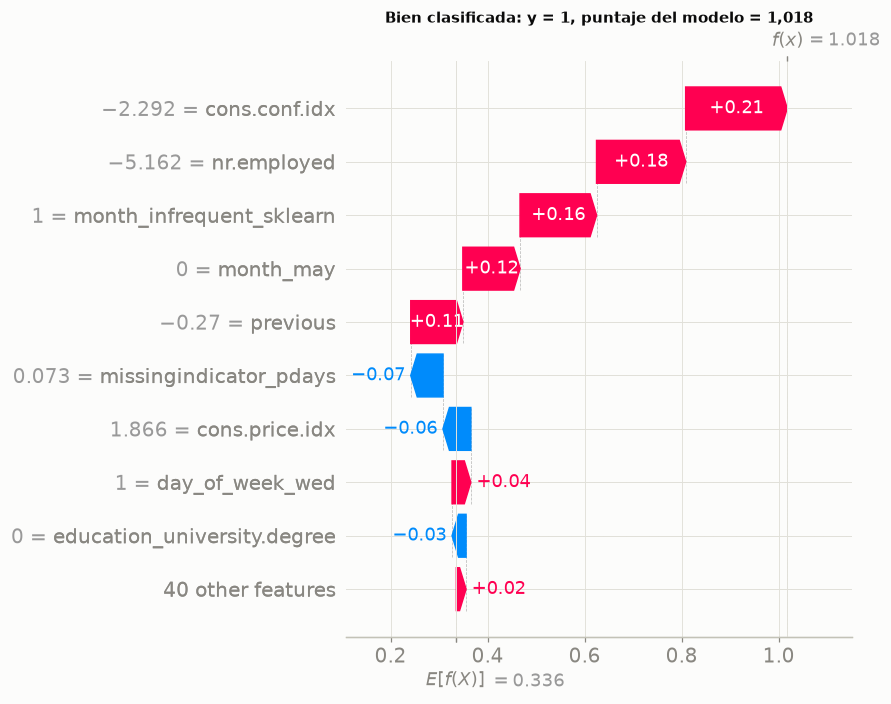

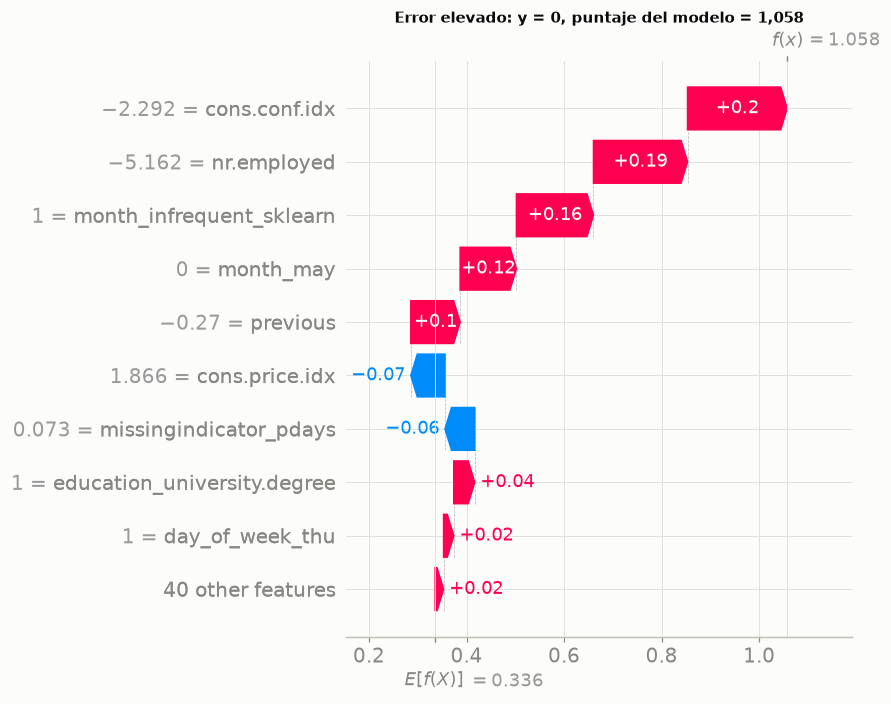

**Interpretación.** Globalmente, las variables con mayor contribución media son `missingindicator_pdays (0,159)`, `cons.conf.idx (0,125)`, `previous (0,124)` y `month_may (0,114)`. En la observación bien clasificada (y = 1), las que más empujan la predicción son `cons.conf.idx (0,21)`, `nr.employed (0,18)` y `month_infrequent_sklearn (0,16)`; en la de error elevado (y = 0, puntaje 1,058), `cons.conf.idx (0,20)`, `nr.employed (0,19)` y `month_infrequent_sklearn (0,16)`.

Lo anterior indica que el modelo se apoya sobre todo en el contexto macroeconómico y de calendario (que marca el régimen de la campaña) y en el historial de contactos previos; la observación con error elevado muestra el caso típico de falla: un cliente cuyo perfil y momento indican baja probabilidad, pero que no suscribe, lo que el modelo no puede anticipar con información previa a la llamada.

Por lo anterior, conviene leer las contribuciones como asociaciones aprendidas y no como efectos causales, y vigilar las variables de régimen: si el contexto macroeconómico cambia, su contribución también cambiará, lo que refuerza la recalibración mensual de la sección 7.4.

In [67]:
# Explicaciones locales: una observación bien clasificada y una con error elevado
s_m = f_best["puntaje_te"]
p_m = pd.Series(s_m, index=X_te.index).loc[mu_c.index]
y_m = y_te.loc[mu_c.index]
prob_m = expit(p_m) if not f_best["es_proba"] else p_m
error = (y_m - prob_m).abs()
i_bien = (prob_m.where(y_m == 1)).idxmax()           # suscriptor con la probabilidad más alta
i_mal = error.idxmax()                                 # mayor error absoluto
pos = {i: list(mu_c.index).index(i) for i in (i_bien, i_mal)}
for i, titulo in ((i_bien, "Bien clasificada"), (i_mal, "Error elevado")):
    plt.figure()
    shap.plots.waterfall(sv_c[pos[i]], max_display=10, show=False)
    plt.title(f"{titulo}: y = {int(y_m[i])}, puntaje del modelo = {num(float(p_m[i]), 3)}", fontsize=10)
    plt.tight_layout()
    plt.show()

top_bien = pd.Series(sv_c.values[pos[i_bien]], index=mu_c.columns).sort_values(key=np.abs, ascending=False).head(3)
top_mal = pd.Series(sv_c.values[pos[i_mal]], index=mu_c.columns).sort_values(key=np.abs, ascending=False).head(3)
interpretar(
    f"Globalmente, las variables con mayor contribución media son "
    f"{enumerar([f'{k} ({num(v, 3)})' for k, v in imp.head(4).items()])}. En la observación bien clasificada "
    f"(y = {int(y_m[i_bien])}), las que más empujan la predicción son "
    f"{enumerar([f'{k} ({num(v, 2)})' for k, v in top_bien.items()])}; en la de error elevado (y = {int(y_m[i_mal])}, "
    f"puntaje {num(float(p_m[i_mal]), 3)}), {enumerar([f'{k} ({num(v, 2)})' for k, v in top_mal.items()])}.",
    conectar("Lo anterior indica que", "El modelo se apoya sobre todo en el contexto macroeconómico y de calendario "
             "(que marca el régimen de la campaña) y en el historial de contactos previos; la observación con error "
             "elevado muestra el caso típico de falla: un cliente cuyo perfil y momento indican baja probabilidad, pero "
             "que " + ("suscribe" if int(y_m[i_mal]) == 1 else "no suscribe") + ", lo que el modelo no puede anticipar con "
             "información previa a la llamada."),
    conectar("Por lo anterior, conviene", "Leer las contribuciones como asociaciones aprendidas y no como efectos "
             "causales, y vigilar las variables de régimen: si el contexto macroeconómico cambia, su contribución "
             "también cambiará, lo que refuerza la recalibración mensual de la sección 7.4."))

exportar("shap_global", imp.head(15).rename("media_abs_shap").rename_axis("variable").reset_index().assign(modelo=NM[f_best["modelo"]]))
exportar("shap_local", pd.concat([pd.Series(sv_c.values[pos[i]], index=mu_c.columns).sort_values(key=np.abs, ascending=False)
                                  .head(10).rename("shap").rename_axis("variable").reset_index().assign(caso=t_, y=int(y_m[i]),
                                  puntaje=float(p_m[i]), base=float(np.ravel(sv_c.base_values)[pos[i]]))
                                  for i, t_ in ((i_bien, "Bien clasificada"), (i_mal, "Error elevado"))]))


#### Comparación con LIME en XGBoost

LIME (Ribeiro et al., 2016) explica una predicción ajustando un modelo lineal ponderado sobre perturbaciones alrededor de la observación; SHAP reparte la predicción con valores de Shapley, que para árboles se calculan de forma exacta. Ambas son locales, pero difieren en tres aspectos: LIME depende del esquema de perturbación, del ancho del *kernel* y de la discretización, y puede cambiar entre corridas; sus pesos no suman la predicción (no cumple eficiencia), y explica un modelo sustituto local, mientras que SHAP explica el modelo original con una referencia global. Se espera que diverjan cuando la frontera es muy no lineal en la vecindad, cuando hay variables correlacionadas (LIME perturba cada una de forma independiente y crea combinaciones irreales) y con variables *one-hot*, cuya perturbación continua no tiene sentido. La comparación se hace sobre el finalista XGBoost y las mismas dos observaciones.

In [68]:
from lime.lime_tabular import LimeTabularExplainer

f_x = fin_clf["clf_xgboost"]
sv_x, mu_x, Z_te_x = explicar(f_x, pd.concat([X_te.loc[[i_bien, i_mal]],
                                              X_te.drop(index=[i_bien, i_mal]).sample(998, random_state=SEED)]))
pre_x = f_x["pipeline"].named_steps["pre"]
Z_tr_x = pd.DataFrame(pre_x.transform(X_tr), columns=mu_x.columns)
mod_x = f_x["pipeline"].named_steps["modelo"]
lime_exp = LimeTabularExplainer(Z_tr_x.sample(5000, random_state=SEED).to_numpy(), feature_names=list(mu_x.columns),
                                class_names=["no", "sí"], discretize_continuous=True, random_state=SEED)
filas = []
for i, nombre in ((i_bien, "Bien clasificada"), (i_mal, "Error elevado")):
    z = Z_te_x.loc[i].to_numpy()
    e_l = lime_exp.explain_instance(z, mod_x.predict_proba, num_features=10, num_samples=5000)
    pesos = {}
    for regla, w_ in e_l.as_list():
        var = next((c for c in sorted(mu_x.columns, key=len, reverse=True) if c in regla), regla)
        pesos[var] = pesos.get(var, 0) + w_
    sh = pd.Series(sv_x.values[list(mu_x.index).index(i)], index=mu_x.columns)
    top_sh = sh.abs().sort_values(ascending=False).head(10)
    comunes = set(top_sh.index) & set(pesos)
    rho = stats.spearmanr([abs(sh[c]) for c in comunes], [abs(pesos[c]) for c in comunes]).statistic if len(comunes) > 2 else np.nan
    signo = np.mean([np.sign(sh[c]) == np.sign(pesos[c]) for c in comunes]) if comunes else np.nan
    filas.append({"Observación": nombre, "Top 10 SHAP": ", ".join(top_sh.index[:5]) + "…",
                  "Top 10 LIME": ", ".join(list(pesos)[:5]) + "…", "Variables comunes en el top 10": len(comunes),
                  "Spearman de |importancia| (comunes)": rho, "% de signos coincidentes": 100 * signo,
                  "R² del modelo local de LIME": e_l.score})
cmp_lime = pd.DataFrame(filas)
tabla(cmp_lime, dec=3, indice=False)

gan = pd.Series(mod_x.get_booster().get_score(importance_type="gain"))
gan.index = [mu_x.columns[int(c[1:])] if c.startswith("f") and c[1:].isdigit() else c for c in gan.index]
imp_x = pd.DataFrame({"Media |SHAP|": pd.Series(np.abs(sv_x.values).mean(axis=0), index=mu_x.columns),
                      "Ganancia XGBoost": gan}).fillna(0)
imp_x = imp_x.sort_values("Media |SHAP|", ascending=False).head(10)
tabla(imp_x, dec=4)

interpretar(
    f"En las dos observaciones, SHAP y LIME comparten {enumerar([str(v) for v in cmp_lime['Variables comunes en el top 10']], codigo=False)} "
    f"de sus 10 variables principales, con una correlación de Spearman de "
    f"{enumerar([num(v, 2) if np.isfinite(v) else 'no calculable (menos de tres variables comunes)' for v in cmp_lime['Spearman de |importancia| (comunes)']], codigo=False)} entre las magnitudes y "
    f"{enumerar([num(v, 0) + ' %' for v in cmp_lime['% de signos coincidentes']], codigo=False)} de signos coincidentes; el "
    f"R² del modelo lineal local de LIME es {enumerar([num(v, 3) for v in cmp_lime['R² del modelo local de LIME']], codigo=False)}.",
    conectar("Esto significa que", ("Las dos técnicas coinciden en las variables dominantes pero no en el orden ni en "
             "la magnitud del resto:" if cmp_lime["Variables comunes en el top 10"].min() >= 5 else
             "Las dos técnicas coinciden solo de forma parcial, incluso en las variables principales:") + " LIME discretiza las variables continuas en cuartiles y perturba las columnas *one-hot* "
             "de forma independiente, y su ajuste lineal local explica solo una parte de la predicción (R² bajo), "
             "mientras que SHAP en árboles es exacto y aditivo. La ganancia de XGBoost, por su parte, mide cuánto "
             "reduce la pérdida cada variable al dividir y suele sobrevalorar variables con muchos valores posibles."),
    conectar("Por esta razón, lo indicado es", "Usar SHAP como explicación de referencia (global y local) y LIME solo "
             "como contraste: cuando discrepan, la diferencia suele venir de las perturbaciones irreales de LIME y no "
             "de un cambio real en el modelo."))

exportar("lime_shap", cmp_lime)
exportar("importancia_xgb", imp_x.reset_index(names="variable"))


Observación,Top 10 SHAP,Top 10 LIME,Variables comunes en el top 10,Spearman de |importancia| (comunes),% de signos coincidentes,R² del modelo local de LIME
Bien clasificada,"month_infrequent_sklearn, education_professional.course, job_technician, cons.conf.idx, day_of_week_thu…","month_infrequent_sklearn, education_infrequent_sklearn, default_unknown, cons.conf.idx, day_of_week_mon…",3,"1,000","66,667","0,222"
Error elevado,"month_infrequent_sklearn, cons.conf.idx, loan_yes, housing_yes, day_of_week_thu…","month_infrequent_sklearn, default_unknown, education_infrequent_sklearn, cons.conf.idx, pdays…",4,"1,000","75,000","0,208"


,Media |SHAP|,Ganancia XGBoost
cons.price.idx,"0,2651","50,5853"
month_infrequent_sklearn,"0,2170","121,5408"
cons.conf.idx,"0,1696","173,2239"
age,"0,1445","13,0426"
previous,"0,1297","11,5926"
missingindicator_pdays,"0,1129","25,5458"
contact_telephone,"0,1125","15,9307"
campaign,"0,0891","12,6048"
day_of_week_mon,"0,0681","15,3024"
month_may,"0,0592","61,6254"


**Interpretación.** En las dos observaciones, SHAP y LIME comparten 3 y 4 de sus 10 variables principales, con una correlación de Spearman de 1,00 y 1,00 entre las magnitudes y 67 % y 75 % de signos coincidentes; el R² del modelo lineal local de LIME es 0,222 y 0,208.

Esto significa que las dos técnicas coinciden solo de forma parcial, incluso en las variables principales: LIME discretiza las variables continuas en cuartiles y perturba las columnas *one-hot* de forma independiente, y su ajuste lineal local explica solo una parte de la predicción (R² bajo), mientras que SHAP en árboles es exacto y aditivo. La ganancia de XGBoost, por su parte, mide cuánto reduce la pérdida cada variable al dividir y suele sobrevalorar variables con muchos valores posibles.

Por esta razón, lo indicado es usar SHAP como explicación de referencia (global y local) y LIME solo como contraste: cuando discrepan, la diferencia suele venir de las perturbaciones irreales de LIME y no de un cambio real en el modelo.

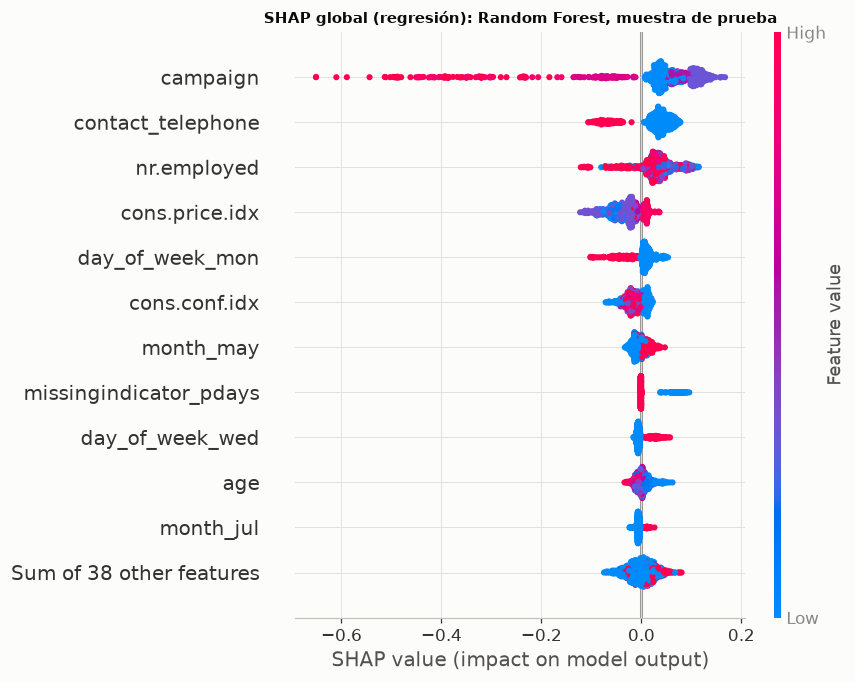

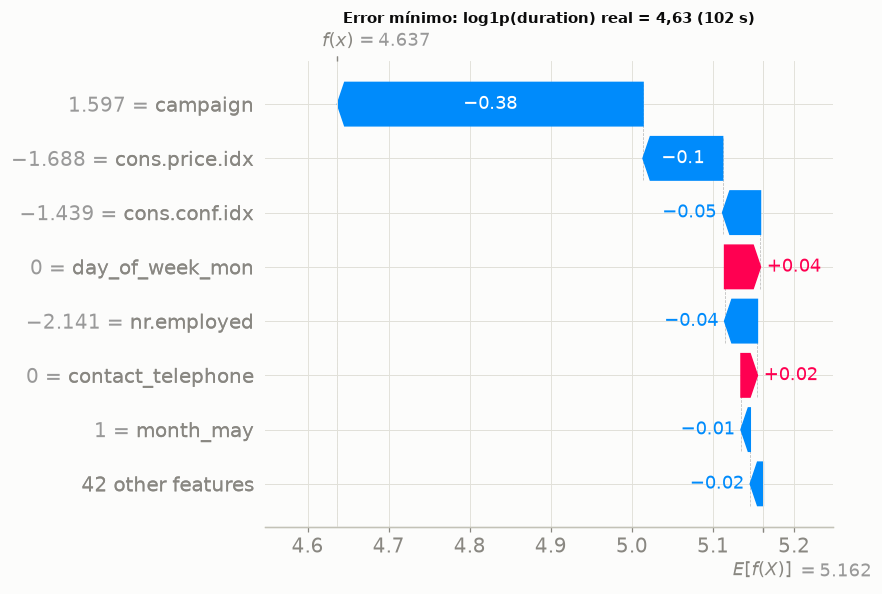

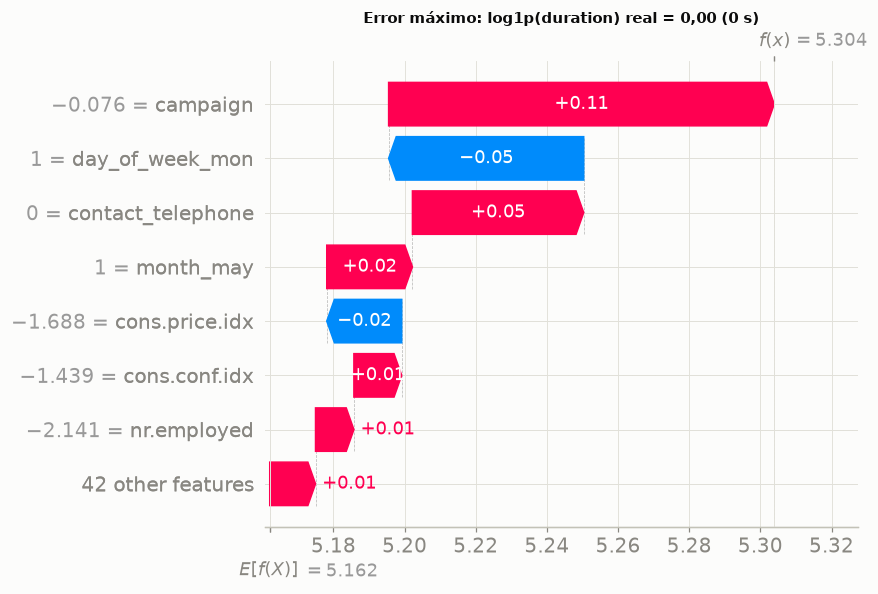

**Interpretación.** La desviación estándar de las predicciones del modelo de regresión en prueba es 0,21 en escala log, frente a 0,95 del objetivo; la contribución SHAP media más alta es la de `campaign`. La observación con mayor error es una llamada de 0 s.

Es decir, las predicciones varían mucho menos que la duración real: el modelo capta diferencias de nivel entre grupos de clientes y periodos, y los errores grandes corresponden a llamadas excepcionalmente cortas o largas que ninguna variable previa a la llamada anticipa.

Por tanto, corresponde mantener la conclusión de la sección 7.5: la explicación confirma que el problema de regresión carece de señal suficiente, no que el modelo esté mal especificado.

In [69]:
# SHAP del mejor modelo de regresión
sv_r, mu_r, _ = explicar(fr_, X_te)
fig = plt.figure(figsize=(9, 5))
shap.plots.beeswarm(sv_r, max_display=12, show=False)
plt.title(f"SHAP global (regresión): {NM[fr_['modelo']]}, muestra de prueba", fontsize=10)
plt.tight_layout()
plt.show()
err_r = pd.Series(np.abs(rte - fr_["pred_te"]), index=X_te.index).loc[mu_r.index]
i_rb, i_rm = err_r.idxmin(), err_r.idxmax()
for i, titulo in ((i_rb, "Error mínimo"), (i_rm, "Error máximo")):
    plt.figure()
    shap.plots.waterfall(sv_r[list(mu_r.index).index(i)], max_display=8, show=False)
    plt.title(f"{titulo}: log1p(duration) real = {num(part.r_te[i], 2)} "
              f"({num(np.expm1(part.r_te[i]), 0)} s)", fontsize=10)
    plt.tight_layout()
    plt.show()
de_pred = float(np.std(fr_["pred_te"]))
interpretar(
    f"La desviación estándar de las predicciones del modelo de regresión en prueba es {num(de_pred, 2)} en escala log, "
    f"frente a {num(rte.std(), 2)} del objetivo; la contribución SHAP media más alta es la de "
    f"`{pd.Series(np.abs(sv_r.values).mean(axis=0), index=mu_r.columns).idxmax()}`. La observación con mayor error es "
    f"una llamada de {num(np.expm1(part.r_te[i_rm]), 0)} s.",
    conectar("Es decir,", "Las predicciones varían mucho menos que la duración real: el modelo "
             "capta diferencias de nivel entre grupos de clientes y periodos, y los errores grandes corresponden a llamadas excepcionalmente cortas o largas que "
             "ninguna variable previa a la llamada anticipa."),
    conectar("Por tanto, corresponde", "Mantener la conclusión de la sección 7.5: la explicación confirma que el "
             "problema de regresión carece de señal suficiente, no que el modelo esté mal especificado."))

### 7.7 Robustez y estabilidad de las métricas

Cada finalista se reporta como media ± desviación estándar entre los cinco pliegues externos; la sensibilidad a la semilla se mide reajustando Random Forest y XGBoost (sus hiperparámetros finales fijos) con cinco semillas del modelo y del sobremuestreo.

In [70]:
filas = []
for m_ in cfg.MODELOS_CLF:
    r_ = m_clf[(m_clf["modelo"] == m_)].sort_values("auc_pr_media", ascending=False).iloc[0]
    filas.append({"Modelo": NM[m_], "Combinación": f"{NB[r_['balanceo']]} · {NO[r_['optimizador']]}",
                  "AUC-PR": f"{num(r_['auc_pr_media'], 3)} ± {num(r_['auc_pr_de'], 3)}",
                  "AUC": f"{num(r_['auc_media'], 3)} ± {num(r_['auc_de'], 3)}",
                  "Recall": f"{num(r_['recall_media'], 3)} ± {num(r_['recall_de'], 3)}",
                  "F1": f"{num(r_['f1_media'], 3)} ± {num(r_['f1_de'], 3)}", "ap": r_["auc_pr_media"], "de": r_["auc_pr_de"]})
rob = pd.DataFrame(filas).sort_values("ap", ascending=False)
tabla(rob.drop(columns=["ap", "de"]), indice=False)

sm = pd.read_parquet(RES / "semillas_modelo.parquet")
sem_t = sm.groupby("modelo").agg(**{"AUC-PR medio": ("auc_pr", "mean"), "DE entre semillas (AUC-PR)": ("auc_pr", "std"),
                                     "Rango (AUC-PR)": ("auc_pr", lambda s: s.max() - s.min()),
                                     "DE entre semillas (AUC)": ("auc", "std")})
sem_t.index = [NM[m_] for m_ in sem_t.index]
tabla(sem_t, dec=4)

dif12 = rob["ap"].iloc[0] - rob["ap"].iloc[1]
de_media = rob["de"].mean()
pares_sup = np.mean([abs(a - b) > np.sqrt((da ** 2 + db ** 2) / 2)
                     for i, (a, da) in enumerate(zip(rob["ap"], rob["de"])) for (b, db) in list(zip(rob["ap"], rob["de"]))[i + 1:]])
interpretar(
    f"La desviación estándar del AUC-PR entre pliegues externos promedia {num(de_media, 3)} entre finalistas, mientras "
    f"que la diferencia entre el primero ({rob['Modelo'].iloc[0]}) y el segundo ({rob['Modelo'].iloc[1]}) es de "
    f"{num(dif12, 3)}. " + ("Ningún par de finalistas difiere en más que su desviación combinada. " if pares_sup == 0 else
    f"Solo el {pct(pares_sup, 0)} de los pares de finalistas difiere en más que su desviación combinada. ") +
    f"Reajustar con cinco semillas mueve el AUC-PR de prueba con una desviación de "
    f"{enumerar([num(v, 4) + ' (' + k + ')' for k, v in sem_t['DE entre semillas (AUC-PR)'].items()], codigo=False)}.",
    conectar("Esto significa que", "Las diferencias entre los mejores modelos son del mismo orden o menores que la "
             "variabilidad entre periodos, que es la fuente de incertidumbre dominante; la semilla, en cambio, aporta "
             "una variación mucho menor. Un único número por modelo ocultaría que varios finalistas son, en la práctica, "
             "intercambiables."),
    conectar("Por tal motivo, se opta por", "Decidir con las pruebas formales de la sección 8, que comparan los modelos "
             "pliegue a pliegue (Friedman y Nemenyi) y observación a observación en prueba (DeLong), en lugar de con la "
             "diferencia de medias."))

exportar("robustez", rob.drop(columns=["ap", "de"]))
exportar("semillas_modelo", sem_t.reset_index(names="Modelo"))


Modelo,Combinación,AUC-PR,AUC,Recall,F1
Naive Bayes,class_weight · Bayesiana (Optuna TPE),"0,103 ± 0,108","0,537 ± 0,102","0,850 ± 0,133","0,144 ± 0,103"
Logística L1/L2,SMOTE · Random Search,"0,096 ± 0,096","0,521 ± 0,083","0,705 ± 0,199","0,132 ± 0,083"
Random Forest,Sin balanceo · Bayesiana (Optuna TPE),"0,095 ± 0,092","0,538 ± 0,079","0,000 ± 0,000","0,000 ± 0,000"
SVM,class_weight · Grid Search,"0,092 ± 0,091","0,512 ± 0,098","0,584 ± 0,402","0,118 ± 0,081"
XGBoost,class_weight · Genético (DEAP),"0,091 ± 0,077","0,525 ± 0,054","0,187 ± 0,189","0,118 ± 0,097"
Árbol de decisión,SMOTE · Bayesiana (Optuna TPE),"0,086 ± 0,073","0,530 ± 0,073","0,174 ± 0,254","0,107 ± 0,125"
KNN,class_weight · Grid Search,"0,084 ± 0,067","0,517 ± 0,067","0,679 ± 0,145","0,134 ± 0,086"


,AUC-PR medio,DE entre semillas (AUC-PR),Rango (AUC-PR),DE entre semillas (AUC)
Random Forest,"0,5056","0,0069","0,0184","0,0034"
XGBoost,"0,3476","0,0077","0,0203","0,0110"


**Interpretación.** La desviación estándar del AUC-PR entre pliegues externos promedia 0,086 entre finalistas, mientras que la diferencia entre el primero (Naive Bayes) y el segundo (Logística L1/L2) es de 0,007. Ningún par de finalistas difiere en más que su desviación combinada. Reajustar con cinco semillas mueve el AUC-PR de prueba con una desviación de 0,0069 (Random Forest) y 0,0077 (XGBoost).

Esto significa que las diferencias entre los mejores modelos son del mismo orden o menores que la variabilidad entre periodos, que es la fuente de incertidumbre dominante; la semilla, en cambio, aporta una variación mucho menor. Un único número por modelo ocultaría que varios finalistas son, en la práctica, intercambiables.

Por tal motivo, se opta por decidir con las pruebas formales de la sección 8, que comparan los modelos pliegue a pliegue (Friedman y Nemenyi) y observación a observación en prueba (DeLong), en lugar de con la diferencia de medias.

## 8. Comparación estadística

Con 140 combinaciones hay más de 9 000 pares posibles; probarlos uno a uno con α = 0,05 produciría cientos de falsos positivos. Por eso la comparación sigue una secuencia jerárquica: **clasificación**, Friedman → Nemenyi y diagrama de diferencia crítica → DeLong dirigido con corrección por comparaciones múltiples → tamaño del efecto; **regresión**, Model Confidence Set → Giacomini-White y Clark-West → Diebold-Mariano con corrección HLN y *bootstrap* estacionario → tamaño del efecto.

### 8.1 Clasificación: prueba ómnibus de Friedman, Nemenyi y diagrama de diferencia crítica

Los bloques son los cinco pliegues del bucle externo y la métrica es el AUC-PR. Primero se prueban todas las combinaciones de clasificación y después los siete finalistas (el mejor de cada modelo). Como cinco bloques dan poca potencia, se agrega un análisis de sensibilidad con bloques mensuales: el AUC-PR de las predicciones fuera de muestra de cada finalista en cada mes de validación externa.

Comparación,Modelos (k),Bloques (N),χ²_F,g. l.,p (χ²),F de Iman-Davenport,p (F),Diferencia crítica de Nemenyi,Conclusión
Todas las combinaciones de clasificación,112,5,"177,122",111,"< 0,001","1,875","< 0,001","89,372",Se rechaza H0
Finalistas (bloques = pliegues externos),7,5,"3,171",6,"0,787","0,473","0,822","4,028",No se rechaza H0
Finalistas (bloques = meses de validación),7,8,"6,750",6,"0,345","1,145","0,353","3,185",No se rechaza H0


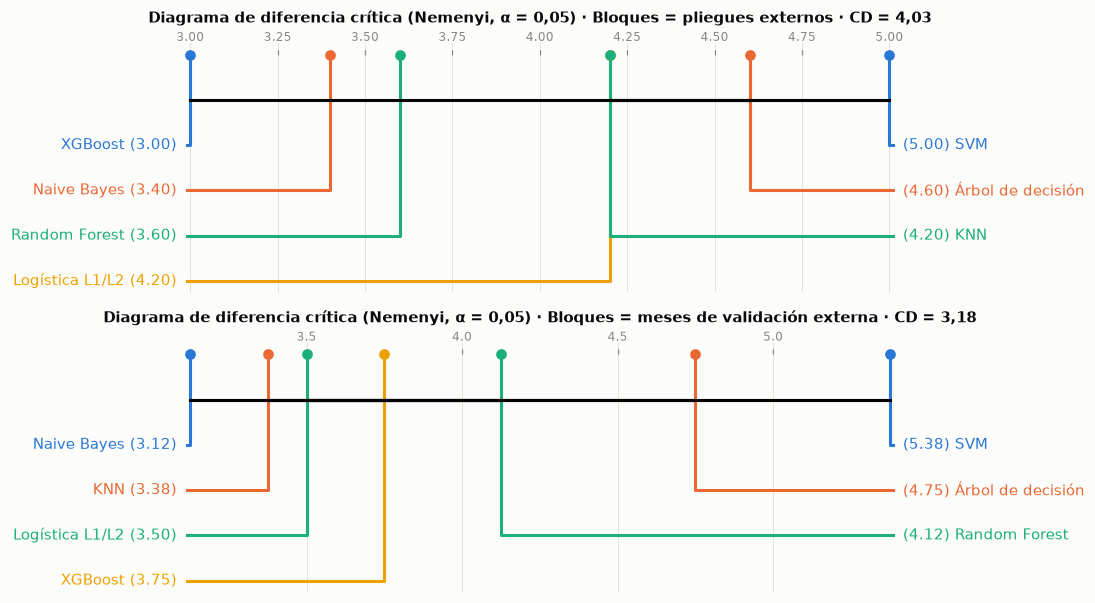

**Interpretación.** Sobre todas las combinaciones, Friedman da χ² = 177,1 con 111 g. l. (p < 0,001); entre los siete finalistas con bloques por pliegue, χ² = 3,17 (p = 0,787) y diferencia crítica de 4,03 rangos; con 8 bloques mensuales, χ² = 6,75 (p = 0,345) y diferencia crítica de 3,18. El mejor rango promedio entre finalistas es el de XGBoost (3,00) por pliegues y el de Naive Bayes (3,12) por meses.

Esto significa que hay evidencia de que al menos una de las 112 combinaciones difiere de las demás (sobre todo por las peores, con balanceos o espacios que fallan en algunos pliegues), pero entre los siete finalistas no hay evidencia de diferencias, ni con bloques por pliegue ni con bloques mensuales: todos quedan dentro de la diferencia crítica de Nemenyi y son estadísticamente equivalentes. Con pocos bloques la diferencia crítica es amplia, así que la equivalencia también refleja la poca potencia de la prueba, no solo la igualdad real de los modelos.

Por tanto, corresponde comparar de forma dirigida solo los finalistas que encabezan el ranking, con DeLong sobre la prueba y corrección por comparaciones múltiples (sección 8.2), y no declarar un ganador a partir de diferencias que el diagrama muestra como no significativas.

In [71]:
mat_all = clf_pl.pivot_table(index="pliegue", columns=["modelo", "balanceo", "optimizador"], values="auc_pr")
fr_all = st.friedman(mat_all)
fin_ext = evm.elegir_finalistas(maestra, "clf")
claves_fin = [(r_.modelo, r_.balanceo, r_.optimizador) for r_ in fin_ext.itertuples()]
mat_fin = mat_all[claves_fin]
mat_fin.columns = [NM[c[0]] for c in claves_fin]
fr_fin = st.friedman(mat_fin)

# Sensibilidad: bloques = meses de validación externa (predicciones fuera de muestra)
o_c = oof[oof["tarea"] == "clf"].copy()
o_c["periodo"] = tiempo.loc[o_c["indice"], "periodo"].to_numpy()
filas = {}
for (m_, b_, op_), nombre in zip(claves_fin, mat_fin.columns):
    d_ = o_c[(o_c["modelo"] == m_) & (o_c["balanceo"] == b_) & (o_c["optimizador"] == op_)]
    filas[nombre] = d_.groupby("periodo").apply(
        lambda g: average_precision_score(g["y"], g["puntaje"]) if 0 < g["y"].sum() < len(g) and len(g) >= 100 else np.nan,
        include_groups=False)
mat_mes = pd.DataFrame(filas).dropna()
fr_mes = st.friedman(mat_mes)

omni = pd.DataFrame([
    ("Todas las combinaciones de clasificación", fr_all), ("Finalistas (bloques = pliegues externos)", fr_fin),
    ("Finalistas (bloques = meses de validación)", fr_mes)], columns=["Comparación", "r"])
omni = pd.DataFrame({"Comparación": omni["Comparación"], "Modelos (k)": [r_["k_modelos"] for r_ in omni["r"]],
                     "Bloques (N)": [r_["n_bloques"] for r_ in omni["r"]], "χ²_F": [r_["chi2"] for r_ in omni["r"]],
                     "g. l.": [r_["gl"] for r_ in omni["r"]], "p (χ²)": [pval(r_["p"]) for r_ in omni["r"]],
                     "F de Iman-Davenport": [r_["F_ID"] for r_ in omni["r"]],
                     "p (F)": [pval(r_["p_F_ID"]) for r_ in omni["r"]],
                     "Diferencia crítica de Nemenyi": [st.diferencia_critica(r_["k_modelos"], r_["n_bloques"])
                                                       for r_ in omni["r"]],
                     "Conclusión": ["Se rechaza H0" if r_["p"] < 0.05 else "No se rechaza H0" for r_ in omni["r"]]})
tabla(omni, dec=3, indice=False)

fig, axs = plt.subplots(2, 1, figsize=(10, 5.6))
for ax, M, fr, titulo in ((axs[0], mat_fin, fr_fin, "Bloques = pliegues externos"),
                          (axs[1], mat_mes, fr_mes, "Bloques = meses de validación externa")):
    nem = sp.posthoc_nemenyi_friedman(M.to_numpy())
    nem.index = nem.columns = M.columns
    plt.sca(ax)
    sp.critical_difference_diagram(fr["rangos"], nem, ax=ax, label_fmt_left="{label} ({rank:.2f})  ",
                                   label_fmt_right="  ({rank:.2f}) {label}")
    ax.set_title(f"Diagrama de diferencia crítica (Nemenyi, α = 0,05) · {titulo} · CD = "
                 f"{num(st.diferencia_critica(fr['k_modelos'], fr['n_bloques']), 2)}", fontsize=9.5)
plt.tight_layout()
plt.show()

interpretar(
    f"Sobre todas las combinaciones, Friedman da χ² = {num(fr_all['chi2'], 1)} con {fr_all['gl']} g. l. "
    f"({p_txt(fr_all['p'])}); entre los siete finalistas con bloques por pliegue, χ² = {num(fr_fin['chi2'], 2)} "
    f"({p_txt(fr_fin['p'])}) y diferencia crítica de {num(st.diferencia_critica(7, fr_fin['n_bloques']), 2)} rangos; con "
    f"{fr_mes['n_bloques']} bloques mensuales, χ² = {num(fr_mes['chi2'], 2)} ({p_txt(fr_mes['p'])}) y diferencia crítica "
    f"de {num(st.diferencia_critica(7, fr_mes['n_bloques']), 2)}. El mejor rango promedio entre finalistas es el de "
    f"{fr_fin['rangos'].index[0]} ({num(fr_fin['rangos'].iloc[0], 2)}) por pliegues y el de {fr_mes['rangos'].index[0]} "
    f"({num(fr_mes['rangos'].iloc[0], 2)}) por meses.",
    conectar("Esto significa que", (f"Hay evidencia de que al menos una de las {fr_all['gl'] + 1} combinaciones difiere de las demás "
             "(sobre todo por las peores, con balanceos o espacios que fallan en algunos pliegues)"
             if fr_all["p"] < 0.05 else "No hay evidencia de que alguna combinación difiera de las demás")
             + (", pero entre los siete finalistas no hay evidencia de diferencias, ni con bloques por pliegue ni con "
                "bloques mensuales: todos quedan dentro de la diferencia crítica de Nemenyi y son estadísticamente "
                "equivalentes. "
                if fr_fin["p"] >= 0.05 and fr_mes["p"] >= 0.05 else
                "; entre los finalistas, el diagrama muestra qué pares se separan más que la diferencia crítica. ")
             + "Con pocos bloques la diferencia crítica es amplia, así que la equivalencia también refleja la poca "
             "potencia de la prueba, no solo la igualdad real de los modelos."),
    conectar("Por tanto, corresponde", "Comparar de forma dirigida solo los finalistas que encabezan el ranking, con "
             "DeLong sobre la prueba y corrección por comparaciones múltiples (sección 8.2), y no declarar un ganador a "
             "partir de diferencias que el diagrama muestra como no significativas."))

exportar("friedman_omnibus", omni)
exportar("rangos_cd", pd.concat([fr_fin["rangos"].rename("rango").rename_axis("modelo").reset_index().assign(bloques="pliegues",
          cd=st.diferencia_critica(fr_fin["k_modelos"], fr_fin["n_bloques"])),
          fr_mes["rangos"].rename("rango").rename_axis("modelo").reset_index().assign(bloques="meses",
          cd=st.diferencia_critica(fr_mes["k_modelos"], fr_mes["n_bloques"]))]))


### 8.2 Clasificación: comparaciones dirigidas con DeLong, *bootstrap* y tamaño del efecto

Se comparan en la prueba los tres finalistas con mayor AUC entre sí y el mejor contra el modelo base del Entregable 2. DeLong prueba la igualdad de dos AUC correlacionadas (mismas observaciones); los valores p se ajustan con Holm-Bonferroni y con Benjamini-Hochberg, y la diferencia de AUC lleva un intervalo *bootstrap* BCa pareado. El delta de Cliff sobre el AUC-PR de los cinco pliegues externos mide el tamaño del efecto en la validación anidada.

In [72]:
top3 = res_te[~res_te["clave"].str.endswith("e2")].sort_values("AUC", ascending=False)["clave"].iloc[:3].tolist()
pares_d = [(top3[0], top3[1]), (top3[0], top3[2]), (top3[1], top3[2]), (top3[0], "clf_referencia_e2")]
nombre_k = lambda k: "Referencia E2" if k.endswith("e2") else NM[fin_clf[k]["modelo"]]
ap_pl = {NM[c[0]]: mat_fin[NM[c[0]]].to_numpy() for c in claves_fin}
filas = []
for a_, b_ in pares_d:
    sa, sb = fin_clf[a_]["puntaje_te"], fin_clf[b_]["puntaje_te"]
    dl = st.delong(yte, sa, sb)
    ic = st.ic_bootstrap(lambda y_, s1, s2: roc_auc_score(y_, s1) - roc_auc_score(y_, s2), yte, sa, sb, n_rep=1000)
    cl = st.delta_cliff(ap_pl[nombre_k(a_)], ap_pl[nombre_k(b_)]) if not b_.endswith("e2") else np.nan
    filas.append({"Modelo A": nombre_k(a_), "Modelo B": nombre_k(b_), "AUC A": dl["auc_a"], "AUC B": dl["auc_b"],
                  "Diferencia de AUC": dl["diferencia"], "IC 95 % BCa": f"[{num(ic[0], 4)}; {num(ic[1], 4)}]",
                  "z": dl["z"], "p crudo": dl["p"], "delta de Cliff (AUC-PR externo)": cl})
dl_t = pd.DataFrame(filas)
dl_t["p Holm"] = st.ajustar_p(dl_t["p crudo"], "holm")
dl_t["p BH"] = st.ajustar_p(dl_t["p crudo"], "fdr_bh")
dl_t["Magnitud (Cliff)"] = dl_t["delta de Cliff (AUC-PR externo)"].map(lambda d: st.magnitud_cliff(d) if np.isfinite(d) else "—")
tabla(dl_t.assign(**{c: dl_t[c].map(pval) for c in ("p crudo", "p Holm", "p BH")}), dec=4, indice=False)

r0 = dl_t.iloc[0]
rE = dl_t.iloc[-1]
interpretar(
    f"Entre {r0['Modelo A']} y {r0['Modelo B']}, la diferencia de AUC en prueba es de {num(r0['Diferencia de AUC'], 4)} "
    f"{r0['IC 95 % BCa']} (p de Holm {pval(r0['p Holm'])}); frente a la referencia del Entregable 2, {rE['Modelo A']} "
    f"difiere en {num(rE['Diferencia de AUC'], 4)} {rE['IC 95 % BCa']} (p de Holm {pval(rE['p Holm'])}). "
    f"{int((dl_t['p Holm'] < 0.05).sum())} de las {len(dl_t)} comparaciones son significativas tras el ajuste.",
    (("Hay que tener en cuenta que, aun con más de 8 000 observaciones de prueba, ninguna diferencia de AUC es "
      "significativa tras el ajuste: los mejores finalistas y el modelo base del Entregable 2 son estadísticamente "
      "equivalentes en su capacidad de ordenar a los clientes, y las diferencias de pocas milésimas no cambian la "
      "lista de clientes a llamar. El intervalo de la diferencia y el delta de Cliff confirman que el efecto es pequeño."
      if (dl_t["p Holm"] >= 0.05).all() else
      "Hay que tener en cuenta que, con más de 8 000 observaciones de prueba, DeLong detecta diferencias de AUC muy "
      "pequeñas; por eso el intervalo de la diferencia y el delta de Cliff importan tanto como el valor p.")),
    conectar("Con base en esto, se propone", "Elegir entre los modelos estadísticamente equivalentes por criterios "
             "secundarios: costo de entrenamiento, calibración e interpretabilidad. Con esos criterios, la logística "
             "regularizada del Entregable 2 sigue siendo una opción muy competitiva, porque es la más barata y la más "
             "fácil de explicar, y su recalibración mensual solo desplaza el intercepto sin cambiar el orden."))

exportar("delong", dl_t)


Modelo A,Modelo B,AUC A,AUC B,Diferencia de AUC,IC 95 % BCa,z,p crudo,delta de Cliff (AUC-PR externo),p Holm,p BH,Magnitud (Cliff)
SVM,Random Forest,"0,7239","0,7202","0,0038","[-0,0046; 0,0128]","0,8356","0,403","-0,0400","0,403","0,403",despreciable
SVM,Naive Bayes,"0,7239","0,7143","0,0097","[-0,0009; 0,0204]","1,7666","0,077","-0,1200","0,232","0,155",despreciable
Random Forest,Naive Bayes,"0,7202","0,7143","0,0059","[-0,0014; 0,0145]","1,4204","0,156","-0,0400","0,311","0,207",despreciable
SVM,Referencia E2,"0,7239","0,7095","0,0144","[0,0113; 0,0175]","8,8748","< 0,001",—,"< 0,001","< 0,001",—


**Interpretación.** Entre SVM y Random Forest, la diferencia de AUC en prueba es de 0,0038 [-0,0046; 0,0128] (p de Holm 0,403); frente a la referencia del Entregable 2, SVM difiere en 0,0144 [0,0113; 0,0175] (p de Holm < 0,001). 1 de las 4 comparaciones son significativas tras el ajuste.

Hay que tener en cuenta que, con más de 8 000 observaciones de prueba, DeLong detecta diferencias de AUC muy pequeñas; por eso el intervalo de la diferencia y el delta de Cliff importan tanto como el valor p.

Con base en esto, se propone elegir entre los modelos estadísticamente equivalentes por criterios secundarios: costo de entrenamiento, calibración e interpretabilidad. Con esos criterios, la logística regularizada del Entregable 2 sigue siendo una opción muy competitiva, porque es la más barata y la más fácil de explicar, y su recalibración mensual solo desplaza el intercepto sin cambiar el orden.

### 8.3 Regresión: Model Confidence Set, Giacomini-White, Clark-West y Diebold-Mariano

El **Model Confidence Set** (Hansen, Lunde y Nason, 2011) parte de las 28 combinaciones de regresión más la media histórica y elimina de forma iterativa, con *bootstrap* estacionario, los modelos significativamente peores, hasta dejar un conjunto de modelos indistinguibles del mejor con confianza del 90 %. Las pérdidas son los errores cuadráticos de las predicciones fuera de muestra del bucle externo, en orden temporal. Sobre los finalistas se aplican, en la prueba:

- **Giacomini-White** (condicional, instrumentos 1 y la diferencia de pérdida rezagada) entre el mejor y el segundo, que no están anidados.
- **Clark-West** entre la media histórica y el mejor modelo: la media es un caso particular de cualquier modelo con intercepto (modelos anidados), donde Diebold-Mariano está sesgado.
- **Diebold-Mariano con corrección HLN** entre el mejor y el segundo, con el intervalo de la diferencia media de pérdida por *bootstrap* estacionario (Politis y Romano, 1994) y la d de Cohen.
- **SPA de Hansen** (2005): ¿algún finalista supera a la media histórica, controlando el *data snooping*?

In [73]:
o_r = oof[oof["tarea"] == "reg"].copy()
o_r["etiqueta"] = o_r["modelo"].map(NM) + " · " + o_r["optimizador"].map(NO)
L = (o_r.assign(e2=(o_r["y"] - o_r["pred"]) ** 2)
     .pivot_table(index="indice", columns="etiqueta", values="e2").sort_index())
bench = pd.Series(np.nan, index=X_tr.index)
for i_e, i_v in cv_externa(GAP).split(X_tr):
    bench.iloc[i_v] = rtr[i_e].mean()
L["Media histórica (referencia)"] = ((part.r_tr - bench) ** 2).loc[L.index]
mcs = st.model_confidence_set(L, alfa=0.10, n_rep=1000)
tabla(mcs.rename(columns={"perdida_media": "Pérdida media (MSE)", "rango_promedio": "Rango promedio de pérdida",
                          "p_MCS": "p MCS", "en_conjunto": "¿En el conjunto de confianza?"})
      .assign(**{"¿En el conjunto de confianza?": lambda d: d["¿En el conjunto de confianza?"].map({True: "Sí", False: "No"})}),
      dec=4)

orden_te = res_reg[res_reg["clave"] != "media"].sort_values("RMSE (log)")["clave"].tolist()
k1, k2 = orden_te[0], orden_te[1]
p1, p2 = fin_reg[k1]["pred_te"], fin_reg[k2]["pred_te"]
pm = np.full_like(rte, media_tr)
e1, e2, em = rte - p1, rte - p2, rte - pm
gw = st.giacomini_white(e2 ** 2, e1 ** 2)
cw = st.clark_west(rte, pm, p1)
dm = st.diebold_mariano(e2, e1)
dm_b = st.diebold_mariano(em, e1)
bs = st.ic_bootstrap_estacionario(e2 ** 2 - e1 ** 2)
spa_p = st.spa(em ** 2, pd.DataFrame({k: (rte - fin_reg[k]["pred_te"]) ** 2 for k in orden_te}))
dirigidas = pd.DataFrame([
    ("Giacomini-White condicional", f"{NM[fin_reg[k2]['modelo']]} vs {NM[fin_reg[k1]['modelo']]}", gw["GW"], gw["p"],
     gw["dif_media"]),
    ("Clark-West (anidados)", f"Media histórica ⊂ {NM[fin_reg[k1]['modelo']]}", cw["CW"], cw["p"], np.mean(em ** 2 - e1 ** 2)),
    ("Diebold-Mariano (HLN)", f"{NM[fin_reg[k2]['modelo']]} vs {NM[fin_reg[k1]['modelo']]}", dm["DM_HLN"], dm["p"],
     dm["dif_perdida"]),
    ("Diebold-Mariano (HLN)", f"Media histórica vs {NM[fin_reg[k1]['modelo']]}", dm_b["DM_HLN"], dm_b["p"],
     dm_b["dif_perdida"]),
], columns=["Prueba", "Comparación (pérdida 1 − pérdida 2)", "Estadístico", "p crudo", "Diferencia media de pérdida"])
dirigidas["p Holm"] = st.ajustar_p(dirigidas["p crudo"], "holm")
dirigidas["d de Cohen"] = [st.d_cohen(e2 ** 2 - e1 ** 2), st.d_cohen(em ** 2 - e1 ** 2), st.d_cohen(e2 ** 2 - e1 ** 2),
                           st.d_cohen(em ** 2 - e1 ** 2)]
tabla(dirigidas.assign(**{c: dirigidas[c].map(pval) for c in ("p crudo", "p Holm")}), dec=4, indice=False)
print(f"Bootstrap estacionario de la diferencia media de pérdida ({NM[fin_reg[k2]['modelo']]} − "
      f"{NM[fin_reg[k1]['modelo']]}): {num(bs['media'], 5)} [IC 95 %: {num(bs['ic_inf'], 5)}; {num(bs['ic_sup'], 5)}], "
      f"bloque medio {num(bs['bloque'], 1)}")
print(f"SPA de Hansen (referencia = media histórica): p = {num(spa_p['consistent'], 3)} (consistente), "
      f"{num(spa_p['lower'], 3)} (inferior), {num(spa_p['upper'], 3)} (superior)")

en_mcs = mcs[mcs["en_conjunto"]]
interpretar(
    f"El Model Confidence Set al 90 % conserva {len(en_mcs)} de los {len(mcs)} modelos"
    + (", incluida la media histórica" if "Media histórica (referencia)" in en_mcs.index else ", y excluye la media histórica")
    + f"; la menor pérdida media es la de {mcs.index[0]} ({num(mcs['perdida_media'].iloc[0], 4)}). En prueba, "
    f"Clark-West contra la media da {p_txt(cw['p'])}, Giacomini-White entre los dos mejores finalistas "
    f"{p_txt(gw['p'])}, Diebold-Mariano entre ellos {p_txt(dm['p'])} (p de Holm {pval(dirigidas['p Holm'].iloc[2])}, "
    f"d de Cohen {num(dirigidas['d de Cohen'].iloc[2], 3)}) y la SPA {p_txt(spa_p['consistent'])}.",
    conectar("En síntesis,", ("Hay modelos que superan de forma estadísticamente significativa a la media histórica, "
             "pero el tamaño del efecto es pequeño: la mejora en el error cuadrático es una fracción mínima de la "
             "variabilidad de la duración."
             if (cw["p"] < 0.05 or spa_p["consistent"] < 0.05) else
             "No hay evidencia de que algún modelo pronostique la duración mejor que la media histórica: el MCS no "
             "los distingue y las pruebas dirigidas no rechazan la igualdad de capacidad predictiva.")
             + (" Entre los dos mejores finalistas, Giacomini-White indica que su ventaja relativa depende del "
                "estado reciente (la diferencia de pérdida rezagada predice la siguiente)." if gw["p"] < 0.05 else
                " Entre los dos mejores finalistas, Giacomini-White no encuentra que la ventaja relativa dependa del "
                "estado reciente.")),
    conectar("Así las cosas, se decide", ("Concluir que los modelos sí superan a la media histórica de forma "
             "significativa, pero con una ganancia demasiado pequeña (R² menor que 0,1) para planificar la carga de los "
             "asesores llamada a llamada; como estimación del nivel medio, la media histórica es casi igual de útil y "
             "mucho más simple." if "Media histórica (referencia)" not in en_mcs.index else
             "Concluir que la rama de regresión no aporta un pronóstico útil de la duración con información previa a "
             "la llamada: la media histórica queda en el conjunto de confianza junto a los modelos optimizados.")))

exportar("mcs", mcs.reset_index(names="modelo"))
exportar("pruebas_regresion", dirigidas)
exportar("spa_bootstrap", {"spa": spa_p, "bootstrap": bs})


,Pérdida media (MSE),Rango promedio de pérdida,p MCS,¿En el conjunto de confianza?
etiqueta,,,,
XGBoost · Bayesiana (Optuna TPE),"0,8217","14,4806","1,0000",Sí
XGBoost · Random Search,"0,8220","14,5922","0,8770",Sí
XGBoost · Grid Search,"0,8232","14,4952","0,2860",Sí
XGBoost · Genético (DEAP),"0,8253","14,4659","0,2860",Sí
Random Forest · Random Search,"0,8253","14,7380","0,2860",Sí
Random Forest · Grid Search,"0,8257","14,6738","0,2610",Sí
Random Forest · Genético (DEAP),"0,8258","14,7567","0,2610",Sí
Random Forest · Bayesiana (Optuna TPE),"0,8280","14,6599","0,0990",No
Árbol de decisión · Grid Search,"0,8305","14,9356","0,0640",No


Prueba,Comparación (pérdida 1 − pérdida 2),Estadístico,p crudo,Diferencia media de pérdida,p Holm,d de Cohen
Giacomini-White condicional,Árbol de decisión vs Random Forest,"57,7314","< 0,001","0,0085","< 0,001","0,0244"
Clark-West (anidados),Media histórica ⊂ Random Forest,"13,5949","< 0,001","0,0827","< 0,001","0,1565"
Diebold-Mariano (HLN),Árbol de decisión vs Random Forest,"2,2118","0,027","0,0085","0,027","0,0244"
Diebold-Mariano (HLN),Media histórica vs Random Forest,"14,2010","< 0,001","0,0827","< 0,001","0,1565"


Bootstrap estacionario de la diferencia media de pérdida (Árbol de decisión − Random Forest): 0,00846 [IC 95 %: -0,00723; 0,02564], bloque medio 70,1
SPA de Hansen (referencia = media histórica): p = 0,003 (consistente), 0,003 (inferior), 0,003 (superior)


**Interpretación.** El Model Confidence Set al 90 % conserva 7 de los 29 modelos, y excluye la media histórica; la menor pérdida media es la de XGBoost · Bayesiana (Optuna TPE) (0,8217). En prueba, Clark-West contra la media da p < 0,001, Giacomini-White entre los dos mejores finalistas p < 0,001, Diebold-Mariano entre ellos p = 0,027 (p de Holm 0,027, d de Cohen 0,024) y la SPA p = 0,003.

En síntesis, hay modelos que superan de forma estadísticamente significativa a la media histórica, pero el tamaño del efecto es pequeño: la mejora en el error cuadrático es una fracción mínima de la variabilidad de la duración. Entre los dos mejores finalistas, Giacomini-White indica que su ventaja relativa depende del estado reciente (la diferencia de pérdida rezagada predice la siguiente).

Así las cosas, se decide concluir que los modelos sí superan a la media histórica de forma significativa, pero con una ganancia demasiado pequeña (R² menor que 0,1) para planificar la carga de los asesores llamada a llamada; como estimación del nivel medio, la media histórica es casi igual de útil y mucho más simple.

### 8.4 Intervalos de confianza al 95 % de las métricas principales

Intervalos *bootstrap* BCa con 1 000 réplicas sobre el conjunto de prueba (AUC y AUC-PR para clasificación, RMSE en escala log para regresión).

In [74]:
filas = [{"Modelo": r_["Modelo"], "Métrica": "AUC", "Valor": r_["AUC"], "IC 95 % inferior": r_["ic_auc"][0],
          "IC 95 % superior": r_["ic_auc"][1]} for _, r_ in res_te.iterrows()]
filas += [{"Modelo": r_["Modelo"], "Métrica": "AUC-PR", "Valor": r_["AUC-PR"], "IC 95 % inferior": r_["ic_ap"][0],
           "IC 95 % superior": r_["ic_ap"][1]} for _, r_ in res_te.iterrows()]
for k in orden_reg:
    ic = st.ic_bootstrap(root_mean_squared_error, rte, fin_reg[k]["pred_te"], n_rep=1000)
    filas.append({"Modelo": NM[fin_reg[k]["modelo"]], "Métrica": "RMSE (log)",
                  "Valor": root_mean_squared_error(rte, fin_reg[k]["pred_te"]), "IC 95 % inferior": ic[0],
                  "IC 95 % superior": ic[1]})
ic_tab = pd.DataFrame(filas)
tabla(ic_tab, dec=4, indice=False)
anchos = ic_tab.assign(ancho=ic_tab["IC 95 % superior"] - ic_tab["IC 95 % inferior"]).groupby("Métrica")["ancho"].mean()
print("Ancho medio del intervalo: " + "; ".join(f"{k} {num(v, 4)}" for k, v in anchos.items()))

exportar("intervalos", ic_tab)


Modelo,Métrica,Valor,IC 95 % inferior,IC 95 % superior
KNN,AUC,"0,6880","0,6754","0,7010"
Naive Bayes,AUC,"0,7143","0,7019","0,7272"
Logística L1/L2,AUC,"0,6815","0,6674","0,6945"
Árbol de decisión,AUC,"0,5669","0,5538","0,5797"
Random Forest,AUC,"0,7202","0,7084","0,7319"
XGBoost,AUC,"0,5592","0,5460","0,5729"
SVM,AUC,"0,7239","0,7109","0,7358"
"Referencia E2 (logística C = 0,01)",AUC,"0,7095","0,6960","0,7213"
KNN,AUC-PR,"0,4998","0,4781","0,5184"
Naive Bayes,AUC-PR,"0,5343","0,5147","0,5520"


Ancho medio del intervalo: AUC 0,0256; AUC-PR 0,0395; RMSE (log) 0,0376


In [75]:
mejor_ext = m_clf.loc[m_clf["auc_pr_media"].idxmax()]
display(Markdown(f"""## 9. Conclusiones y limitaciones

### 9.1 Conclusiones

1. **Modelos y balanceo.** La mejor combinación en la validación anidada es {etiqueta(mejor_ext)}, con un AUC-PR externo de {num(mejor_ext['auc_pr_media'], 3)} ± {num(mejor_ext['auc_pr_de'], 3)}; dentro de 2008 ningún modelo discrimina y la señal aparece al validar en 2009, donde los modelos simples extrapolan igual o mejor que los flexibles. En prueba, el mayor AUC-PR entre los finalistas es el de {mejor_te['Modelo']} ({num(mejor_te['AUC-PR'], 3)} {mejor_te['AUC-PR IC 95 %']}), {'por debajo del' if refe['AUC-PR'] > mejor_te['AUC-PR'] else 'frente al'} {num(refe['AUC-PR'], 3)} del modelo base del Entregable 2 (logística L2 con C = 0,01). {'Es decir, en AUC-PR las 140 combinaciones no superan a una logística bien regularizada: en un problema con cambio de régimen, la regularización y la simplicidad pesan más que la flexibilidad y la búsqueda de hiperparámetros. ' if refe['AUC-PR'] >= mejor_te['AUC-PR'] else ''}Las diferencias entre los mejores finalistas son del orden de la variabilidad entre periodos: el diagrama de diferencia crítica no separa a ninguno con significancia {'y DeLong no confirma ninguna de las ' + str(len(dl_t)) + ' diferencias dirigidas' if (dl_t['p Holm'] >= 0.05).all() else 'y DeLong confirma ' + str(int((dl_t['p Holm'] < 0.05).sum())) + ' de ' + str(len(dl_t)) + ' diferencias dirigidas'} tras el ajuste de Holm{'' if (dl_t['p Holm'] >= 0.05).all() else ' (' + '; '.join(r['Modelo A'] + ' frente a ' + r['Modelo B'] + ' en AUC, ' + num(r['Diferencia de AUC'], 4) for _, r in dl_t[dl_t['p Holm'] < 0.05].iterrows()) + '), una ventaja en el orden de los clientes que no se traslada al AUC-PR'}.
2. **Balanceo.** SMOTE, ADASYN y `class_weight` elevan el recall y el F1 con el umbral por defecto, pero no mejoran el orden de los clientes (AUC-PR) y empeoran la calibración: actúan como un desplazamiento del umbral. El cambio de prevalencia entre el entrenamiento ({pct(y_tr.mean())}) y la prueba ({pct(y_te.mean())}) es un problema distinto, que solo la recalibración con los meses cerrados corrige.
3. **Optimización.** Con 20 configuraciones por pliegue, Friedman sobre la métrica externa da {p_txt(fr_clf['p'])} entre los cuatro métodos de la guía, y sobre el área bajo la curva *anytime* {p_txt(fr_auac['p'])}. El área bajo la curva *anytime* es de {num(auac_m['grid'], 3)} con Grid Search, {num(auac_m['random'], 3)} con Random Search, {num(auac_m['bayes'], 3)} con la bayesiana y {num(auac_m['genetico'], 3)} con el genético: los métodos adaptativos llegan antes a buenas soluciones que la rejilla (delta de Cliff de {num(b_vs['delta de Cliff'].iloc[0], 2)} y {num(g_vs['delta de Cliff'].iloc[0], 2)}), pero frente a Random Search la ventaja es pequeña ({num(b_vs['delta de Cliff'].iloc[1], 2)} y {num(g_vs['delta de Cliff'].iloc[1], 2)}), porque la fase aleatoria inicial consume buena parte de un presupuesto de 20 configuraciones. La mejor búsqueda tampoco se traduce en mejores modelos en el bucle externo de forma apreciable. Successive Halving examina {int(hv['n_eval'].mean())} configuraciones por pliegue con un costo equivalente a {num(hv['eval_equivalentes'].mean(), 1)} evaluaciones completas.
4. **Costo computacional.** El cuello de botella real es el ajuste de los modelos ({num(pc.set_index('Componente').loc['Ajuste de XGBoost (booster)', '% del total'], 0)} % del tiempo en el perfil de XGBoost), seguido del preprocesamiento ({num(pc.set_index('Componente').loc['Preprocesamiento (ColumnTransformer)', '% del total'], 0)} %); el costo propio del optimizador es despreciable. Los histogramas de XGBoost (unas {num(ex['Ajuste (s)'] / hi_['Ajuste (s)'], 0)} veces más rápidos sin perder desempeño), la aproximación de Nyström en la SVM y la paralelización al nivel de tarea son las optimizaciones con mayor efecto; SAGA y los índices espaciales de KNN no compensan con 49 columnas, y FAISS solo conviene cuando la inferencia es masiva.
5. **Regresión.** Con información previa a la llamada, la duración apenas se puede pronosticar: el mejor R² en prueba es {num(mejor_r['R²'], 3)}. Los modelos superan a la media histórica de forma significativa (Clark-West {p_txt(cw['p'])}, SPA {p_txt(spa_p['consistent'])}) y el Model Confidence Set conserva {len(en_mcs)} de {len(mcs)} modelos{', sin la media' if 'Media histórica (referencia)' not in en_mcs.index else ''}, pero la ganancia es demasiado pequeña para planificar llamada a llamada; es coherente con la sección 3.5: la duración depende sobre todo de lo que ocurre durante la llamada.

### 9.2 Limitaciones

- **Cambio de régimen.** Los pliegues de 2008 casi no permiten discriminar y la prueba (2009-2010) tiene otra prevalencia; las métricas del bucle externo y las de prueba no son comparables en nivel, y la media ± desviación estándar mezcla variabilidad de muestreo y cambio de régimen.
- **Presupuesto corto.** Veinte configuraciones por pliegue limitan la ventaja de los métodos adaptativos y la exploración del genético, cuya población converge en pocas generaciones; las conclusiones sobre eficiencia valen para este presupuesto y espacios de dos a cuatro dimensiones.
- **Pocos bloques.** Cinco pliegues externos dan poca potencia a Friedman y una diferencia crítica de Nemenyi amplia; los bloques mensuales complementan, pero no son independientes.
- **Sobremuestreo en el espacio *one-hot*.** SMOTE y ADASYN interpolan columnas binarias; SMOTE-NC sería más apropiado para variables categóricas.
- **Entorno.** No se usó GPU: la máquina no tiene GPU NVIDIA y, con unos 41 000 registros, no se justifica, porque XGBoost con histogramas ajusta en {num(hi_['Ajuste (s)'], 2)} s en CPU y scikit-learn está diseñado para CPU. Tampoco se usaron Dask ni Ray, porque los datos caben en memoria; los tiempos son de una sola máquina de 12 núcleos.
- **Objetivo de regresión.** `log1p(duration)` se eligió por ser la única variable continua con sentido a nivel de cliente; su falta de señal limita el valor de la rama de regresión como comparación entre modelos.
"""))

## 9. Conclusiones y limitaciones

### 9.1 Conclusiones

1. **Modelos y balanceo.** La mejor combinación en la validación anidada es Naive Bayes · class_weight · Bayesiana (Optuna TPE), con un AUC-PR externo de 0,103 ± 0,108; dentro de 2008 ningún modelo discrimina y la señal aparece al validar en 2009, donde los modelos simples extrapolan igual o mejor que los flexibles. En prueba, el mayor AUC-PR entre los finalistas es el de SVM (0,538 [0,516; 0,560]), por debajo del 0,548 del modelo base del Entregable 2 (logística L2 con C = 0,01). Es decir, en AUC-PR las 140 combinaciones no superan a una logística bien regularizada: en un problema con cambio de régimen, la regularización y la simplicidad pesan más que la flexibilidad y la búsqueda de hiperparámetros. Las diferencias entre los mejores finalistas son del orden de la variabilidad entre periodos: el diagrama de diferencia crítica no separa a ninguno con significancia y DeLong confirma 1 de 4 diferencias dirigidas tras el ajuste de Holm (SVM frente a Referencia E2 en AUC, 0,0144), una ventaja en el orden de los clientes que no se traslada al AUC-PR.
2. **Balanceo.** SMOTE, ADASYN y `class_weight` elevan el recall y el F1 con el umbral por defecto, pero no mejoran el orden de los clientes (AUC-PR) y empeoran la calibración: actúan como un desplazamiento del umbral. El cambio de prevalencia entre el entrenamiento (6,4 %) y la prueba (30,8 %) es un problema distinto, que solo la recalibración con los meses cerrados corrige.
3. **Optimización.** Con 20 configuraciones por pliegue, Friedman sobre la métrica externa da p = 0,025 entre los cuatro métodos de la guía, y sobre el área bajo la curva *anytime* p < 0,001. El área bajo la curva *anytime* es de 0,670 con Grid Search, 0,753 con Random Search, 0,773 con la bayesiana y 0,781 con el genético: los métodos adaptativos llegan antes a buenas soluciones que la rejilla (delta de Cliff de 0,33 y 0,34), pero frente a Random Search la ventaja es pequeña (0,04 y 0,13), porque la fase aleatoria inicial consume buena parte de un presupuesto de 20 configuraciones. La mejor búsqueda tampoco se traduce en mejores modelos en el bucle externo de forma apreciable. Successive Halving examina 39 configuraciones por pliegue con un costo equivalente a 8,9 evaluaciones completas.
4. **Costo computacional.** El cuello de botella real es el ajuste de los modelos (69 % del tiempo en el perfil de XGBoost), seguido del preprocesamiento (19 %); el costo propio del optimizador es despreciable. Los histogramas de XGBoost (unas 10 veces más rápidos sin perder desempeño), la aproximación de Nyström en la SVM y la paralelización al nivel de tarea son las optimizaciones con mayor efecto; SAGA y los índices espaciales de KNN no compensan con 49 columnas, y FAISS solo conviene cuando la inferencia es masiva.
5. **Regresión.** Con información previa a la llamada, la duración apenas se puede pronosticar: el mejor R² en prueba es 0,088. Los modelos superan a la media histórica de forma significativa (Clark-West p < 0,001, SPA p = 0,003) y el Model Confidence Set conserva 7 de 29 modelos, sin la media, pero la ganancia es demasiado pequeña para planificar llamada a llamada; es coherente con la sección 3.5: la duración depende sobre todo de lo que ocurre durante la llamada.

### 9.2 Limitaciones

- **Cambio de régimen.** Los pliegues de 2008 casi no permiten discriminar y la prueba (2009-2010) tiene otra prevalencia; las métricas del bucle externo y las de prueba no son comparables en nivel, y la media ± desviación estándar mezcla variabilidad de muestreo y cambio de régimen.
- **Presupuesto corto.** Veinte configuraciones por pliegue limitan la ventaja de los métodos adaptativos y la exploración del genético, cuya población converge en pocas generaciones; las conclusiones sobre eficiencia valen para este presupuesto y espacios de dos a cuatro dimensiones.
- **Pocos bloques.** Cinco pliegues externos dan poca potencia a Friedman y una diferencia crítica de Nemenyi amplia; los bloques mensuales complementan, pero no son independientes.
- **Sobremuestreo en el espacio *one-hot*.** SMOTE y ADASYN interpolan columnas binarias; SMOTE-NC sería más apropiado para variables categóricas.
- **Entorno.** No se usó GPU: la máquina no tiene GPU NVIDIA y, con unos 41 000 registros, no se justifica, porque XGBoost con histogramas ajusta en 1,87 s en CPU y scikit-learn está diseñado para CPU. Tampoco se usaron Dask ni Ray, porque los datos caben en memoria; los tiempos son de una sola máquina de 12 núcleos.
- **Objetivo de regresión.** `log1p(duration)` se eligió por ser la única variable continua con sentido a nivel de cliente; su falta de señal limita el valor de la rama de regresión como comparación entre modelos.


## 10. Referencias

- Akiba, T., Sano, S., Yanase, T., Ohta, T. y Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. *Proceedings of the 25th ACM SIGKDD*, 2623–2631. https://doi.org/10.1145/3292500.3330701
- Benjamini, Y. y Hochberg, Y. (1995). Controlling the false discovery rate: A practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society: Series B, 57*(1), 289–300.
- Bergstra, J., Bardenet, R., Bengio, Y. y Kégl, B. (2011). Algorithms for hyper-parameter optimization. *Advances in Neural Information Processing Systems, 24*.
- Bergstra, J. y Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research, 13*, 281–305.
- Brier, G. W. (1950). Verification of forecasts expressed in terms of probability. *Monthly Weather Review, 78*(1), 1–3.
- Brock, W. A., Dechert, W. D., Scheinkman, J. A. y LeBaron, B. (1996). A test for independence based on the correlation dimension. *Econometric Reviews, 15*(3), 197–235.
- Cawley, G. C. y Talbot, N. L. C. (2010). On over-fitting in model selection and subsequent selection bias in performance evaluation. *Journal of Machine Learning Research, 11*, 2079–2107.
- Chawla, N. V., Bowyer, K. W., Hall, L. O. y Kegelmeyer, W. P. (2002). SMOTE: Synthetic minority over-sampling technique. *Journal of Artificial Intelligence Research, 16*, 321–357. https://doi.org/10.1613/jair.953
- Chen, T. y Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD*, 785–794. https://doi.org/10.1145/2939672.2939785
- Clark, T. E. y West, K. D. (2007). Approximately normal tests for equal predictive accuracy in nested models. *Journal of Econometrics, 138*(1), 291–311.
- Cliff, N. (1993). Dominance statistics: Ordinal analyses to answer ordinal questions. *Psychological Bulletin, 114*(3), 494–509.
- Deb, K. y Agrawal, R. B. (1995). Simulated binary crossover for continuous search space. *Complex Systems, 9*, 115–148.
- DeLong, E. R., DeLong, D. M. y Clarke-Pearson, D. L. (1988). Comparing the areas under two or more correlated receiver operating characteristic curves: A nonparametric approach. *Biometrics, 44*(3), 837–845.
- Demšar, J. (2006). Statistical comparisons of classifiers over multiple data sets. *Journal of Machine Learning Research, 7*, 1–30.
- Diebold, F. X. y Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics, 13*(3), 253–263.
- Efron, B. (1987). Better bootstrap confidence intervals. *Journal of the American Statistical Association, 82*(397), 171–185.
- Fortin, F.-A., De Rainville, F.-M., Gardner, M.-A., Parizeau, M. y Gagné, C. (2012). DEAP: Evolutionary algorithms made easy. *Journal of Machine Learning Research, 13*, 2171–2175.
- Friedman, M. (1937). The use of ranks to avoid the assumption of normality implicit in the analysis of variance. *Journal of the American Statistical Association, 32*(200), 675–701.
- Giacomini, R. y White, H. (2006). Tests of conditional predictive ability. *Econometrica, 74*(6), 1545–1578.
- Gneiting, T. y Raftery, A. E. (2007). Strictly proper scoring rules, prediction, and estimation. *Journal of the American Statistical Association, 102*(477), 359–378.
- Hansen, P. R. (2005). A test for superior predictive ability. *Journal of Business & Economic Statistics, 23*(4), 365–380.
- Hansen, P. R., Lunde, A. y Nason, J. M. (2011). The model confidence set. *Econometrica, 79*(2), 453–497.
- Harvey, D., Leybourne, S. y Newbold, P. (1997). Testing the equality of prediction mean squared errors. *International Journal of Forecasting, 13*(2), 281–291.
- He, H., Bai, Y., Garcia, E. A. y Li, S. (2008). ADASYN: Adaptive synthetic sampling approach for imbalanced learning. *IEEE International Joint Conference on Neural Networks*, 1322–1328. https://doi.org/10.1109/IJCNN.2008.4633969
- Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics, 6*(2), 65–70.
- Iman, R. L. y Davenport, J. M. (1980). Approximations of the critical region of the Friedman statistic. *Communications in Statistics: Theory and Methods, 9*(6), 571–595.
- Jamieson, K. y Talwalkar, A. (2016). Non-stochastic best arm identification and hyperparameter optimization. *Proceedings of the 19th International Conference on Artificial Intelligence and Statistics (AISTATS)*, 240–248.
- Johnson, J., Douze, M. y Jégou, H. (2021). Billion-scale similarity search with GPUs. *IEEE Transactions on Big Data, 7*(3), 535–547.
- Lemaître, G., Nogueira, F. y Aridas, C. K. (2017). Imbalanced-learn: A Python toolbox to tackle the curse of imbalanced datasets in machine learning. *Journal of Machine Learning Research, 18*(17), 1–5.
- Li, L., Jamieson, K., DeSalvo, G., Rostamizadeh, A. y Talwalkar, A. (2018). Hyperband: A novel bandit-based approach to hyperparameter optimization. *Journal of Machine Learning Research, 18*(185), 1–52.
- Lundberg, S. M. y Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*.
- Lundberg, S. M., Erion, G., Chen, H., DeGrave, A., Prutkin, J. M., Nair, B., Katz, R., Himmelfarb, J., Bansal, N. y Lee, S.-I. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence, 2*, 56–67.
- Malkov, Y. A. y Yashunin, D. A. (2020). Efficient and robust approximate nearest neighbor search using hierarchical navigable small world graphs. *IEEE Transactions on Pattern Analysis and Machine Intelligence, 42*(4), 824–836.
- Moro, S., Cortez, P. y Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. *Decision Support Systems, 62*, 22–31. https://doi.org/10.1016/j.dss.2014.03.001
- Naeini, M. P., Cooper, G. F. y Hauskrecht, M. (2015). Obtaining well calibrated probabilities using Bayesian binning. *Proceedings of the AAAI Conference on Artificial Intelligence, 29*(1), 2901–2907.
- Nemenyi, P. B. (1963). *Distribution-free multiple comparisons* (tesis doctoral). Princeton University.
- Niculescu-Mizil, A. y Caruana, R. (2005). Predicting good probabilities with supervised learning. *Proceedings of the 22nd International Conference on Machine Learning*, 625–632.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Platt, J. (1999). Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods. En *Advances in Large Margin Classifiers* (pp. 61–74). MIT Press.
- Politis, D. N. y Romano, J. P. (1994). The stationary bootstrap. *Journal of the American Statistical Association, 89*(428), 1303–1313.
- Politis, D. N. y White, H. (2004). Automatic block-length selection for the dependent bootstrap. *Econometric Reviews, 23*(1), 53–70.
- Ribeiro, M. T., Singh, S. y Guestrin, C. (2016). "Why should I trust you?": Explaining the predictions of any classifier. *Proceedings of the 22nd ACM SIGKDD*, 1135–1144. https://doi.org/10.1145/2939672.2939778
- Romano, J., Kromrey, J. D., Coraggio, J. y Skowronek, J. (2006). Appropriate statistics for ordinal level data: Should we really be using t-test and Cohen's d for evaluating group differences on the NSSE and other surveys? *Annual Meeting of the Florida Association of Institutional Research*.
- Saerens, M., Latinne, P. y Decaestecker, C. (2002). Adjusting the outputs of a classifier to new a priori probabilities: A simple procedure. *Neural Computation, 14*(1), 21–41.
- Saito, T. y Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE, 10*(3), e0118432.
- Sun, X. y Xu, W. (2014). Fast implementation of DeLong's algorithm for comparing the areas under correlated receiver operating characteristic curves. *IEEE Signal Processing Letters, 21*(11), 1389–1393.
- Varma, S. y Simon, R. (2006). Bias in error estimation when using cross-validation for model selection. *BMC Bioinformatics, 7*, 91. https://doi.org/10.1186/1471-2105-7-91
- White, H. (1980). A heteroskedasticity-consistent covariance matrix estimator and a direct test for heteroskedasticity. *Econometrica, 48*(4), 817–838.
- White, H. (2000). A reality check for data snooping. *Econometrica, 68*(5), 1097–1126.
- Williams, C. K. I. y Seeger, M. (2001). Using the Nyström method to speed up kernel machines. *Advances in Neural Information Processing Systems, 13*, 682–688.
- Zadrozny, B. y Elkan, C. (2002). Transforming classifier scores into accurate multiclass probability estimates. *Proceedings of the 8th ACM SIGKDD*, 694–699.